In [1]:
import json
import webbrowser
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.patches as mpatches
from pathlib import Path
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.neighbors import kneighbors_graph
import igraph as ig
import leidenalg
import umap
import pickle

%matplotlib inline
#%matplotlib qt

# ── Fichiers CSV
SMOOTH_FILES_SHRIMP = {
    1:  r"C:\Users\nonoh\Documents\01Travail\02_CREC\cuttle_strike\cut_shrimp_with_features_smooth_1.csv",
    5:  r"C:\Users\nonoh\Documents\01Travail\02_CREC\cuttle_strike\cut_shrimp_with_features_smooth_5.csv",
    10: r"C:\Users\nonoh\Documents\01Travail\02_CREC\cuttle_strike\cut_shrimp_with_features_smooth_10.csv",
    20: r"C:\Users\nonoh\Documents\01Travail\02_CREC\cuttle_strike\cut_shrimp_with_features_smooth_20.csv",
    50: r"C:\Users\nonoh\Documents\01Travail\02_CREC\cuttle_strike\cut_shrimp_with_features_smooth_50.csv",
}

FEATURES_SHRIMP = [
    "shrimp_distance_to_cuttle", "shrimp_facing_cuttle", "shrimp_orientation_variation",
    "shrimp_speed_smooth",
]

# FEATURES_SHRIMP = [
#     "distance_to_shrimp", "approach_angle", "orientation_variation",
#     "speed_cuttle_smooth", "accel_cuttle" ,"jerk_cuttle", "head_turn", "eye_convergence"
# ]

OUT_DIR_SHRIMP = Path(r"C:\Users\nonoh\Documents\01Travail\02_CREC\cuttle_strike\analysis_results_shrimp")
OUT_DIR_SHRIMP.mkdir(parents=True, exist_ok=True)

# ── Paramètres Leiden
LEIDEN_K_SHRIMP    = 1000
LEIDEN_RES_SHRIMP  = 1.0
LEIDEN_K2_SHRIMP   = 3
LEIDEN_RES2_SHRIMP = 5.0

# ── Palettes
PALETTE_SHRIMP = [
    "#FF4FB8","#C97E48","#8C6BB1","#9C9C9C","#F5E21E",
    "#3A8891","#E45756","#4CAF50","#1F77B4","#FF9F1C",
    "#A05195","#2CB1BC","#7F7F7F","#BCBD22","#17BECF",
    "#D62728","#9467BD","#8C564B","#E377C2","#AEC7E8",
]
SUPER_PAL_SHRIMP = [
    "#FF4444","#44AAFF","#44FF88","#FFD700","#FF44FF",
    "#FF8844","#44FFFF","#FF44AA","#88FF44","#AA44FF",
]
# ── Alias sémantiques ─────────────────────────────────
CLUSTER_PALETTE_SHRIMP  = PALETTE_SHRIMP    # états comportementaux C0, C1, ...
STRATEGY_PALETTE_SHRIMP = SUPER_PAL_SHRIMP  # stratégies A, B, C, ... (et groupes Ward)

# Colormaps fixes — source de vérité unique
CMAP_CLUSTER_SHRIMP = mpl.colors.ListedColormap(PALETTE_SHRIMP)
NORM_CLUSTER_SHRIMP = mpl.colors.BoundaryNorm(range(len(PALETTE_SHRIMP) + 1), ncolors=len(PALETTE_SHRIMP))

print(f"[OK] Config — {len(SMOOTH_FILES_SHRIMP)} fichiers | résultats → {OUT_DIR_SHRIMP}")

[OK] Config — 5 fichiers | résultats → C:\Users\nonoh\Documents\01Travail\02_CREC\cuttle_strike\analysis_results_shrimp


In [2]:
def run_leiden_shrimp(df_shrimp, features, k=100, res=1.0, k2=3, res2=5.0, seed=42,
               feature_weights=None):
    """
    Leiden niveau 1 (clusters) + niveau 2 (superclusters).

    feature_weights : dict {feature_name: weight} optionnel
        Le poids est appliqué APRÈS StandardScaler pour être réellement
        efficace — multiplier par W donne W fois plus d'importance dans
        la distance euclidienne entre frames.
        Ex : {"orientation_variation": 3.0} → cette feature compte
             3× plus que les autres dans le clustering.
    """

    # ── Niveau 1 — clusters sur les frames ───────────────────
    X_raw = df_shrimp[features].values.copy().astype(float)

    # StandardScaler EN PREMIER — toutes les features à std=1
    X = StandardScaler().fit_transform(X_raw)

    # Poids APRÈS StandardScaler
    # Avant scaling : std différentes → multiplier n'a pas d'effet uniforme
    # Après scaling : std=1 pour toutes → multiplier par W donne exactement
    #                 W fois plus d'importance dans la distance euclidienne
    if feature_weights:
        for i, feat in enumerate(features):
            w = feature_weights.get(feat, 1.0)
            if w != 1.0:
                X[:, i] *= w
                print(f"  [WEIGHT] {feat} × {w}  (std : 1.0 → {w:.1f})")

    A         = kneighbors_graph(X, n_neighbors=k, mode='distance')
    s, t      = A.nonzero()
    dist_vals = np.array(A[s, t]).flatten()
    w_vals    = 1 - dist_vals / (dist_vals.max() + 1e-9)

    g = ig.Graph(n=len(X), edges=list(zip(s, t)), directed=False)
    g.es["weight"] = w_vals.tolist()

    p = leidenalg.find_partition(
        g, leidenalg.RBConfigurationVertexPartition,
        weights="weight",
        resolution_parameter=res, seed=seed
    )
    df_shrimp            = df_shrimp.copy()
    df_shrimp["cluster"] = p.membership
    n_clusters_shrimp    = df_shrimp["cluster"].nunique()

    # ── Niveau 2 — superclusters sur les centroïdes ───────────
    mean_c  = df_shrimp.groupby("cluster")[features].mean()
    mean_cs = StandardScaler().fit_transform(mean_c)

    A2      = kneighbors_graph(mean_cs,
                                n_neighbors=min(k2, len(mean_c) - 1),
                                mode='distance')
    s2, t2  = A2.nonzero()
    dist2   = np.array(A2[s2, t2]).flatten()
    w2      = 1 - dist2 / (dist2.max() + 1e-9)

    g2 = ig.Graph(n=len(mean_c), edges=list(zip(s2, t2)), directed=False)
    g2.es["weight"] = w2.tolist()

    p2   = leidenalg.find_partition(
        g2, leidenalg.RBConfigurationVertexPartition,
        weights="weight",
        resolution_parameter=res2, seed=seed
    )
    c2sc               = {cid: sl for cid, sl in zip(mean_c.index, p2.membership)}
    df_shrimp["supercluster"] = df_shrimp["cluster"].map(c2sc)
    n_super            = df_shrimp["supercluster"].nunique()

    print(f"  → {n_clusters_shrimp} clusters | {n_super} superclusters")
    return df_shrimp, X, n_clusters_shrimp, n_super


def run_umap_shrimp(X, seed=42):
    return umap.UMAP(n_components=2, random_state=seed).fit_transform(X)


# ── Poids des features ────────────────────────────────────────
# Calibrés via la cellule de test des poids
# 1.0 = pas de pondération (comportement standard)
FEATURE_WEIGHTS_SHRIMP = {
    "shrimp_orientation_variation": 1.0,   # ← changer après exploration
    "shrimp_facing_cuttle":  1.0,
    "shrimp_distance_to_cuttle": 1.0,
    "shrimp_speed_smooth": 1.0,
}

print("[OK] Fonctions définies")

[OK] Fonctions définies


In [3]:
results_shrimp = {}

for window, fpath in SMOOTH_FILES_SHRIMP.items():
    print(f"\n── Smooth window={window} ──")
    cache = OUT_DIR_SHRIMP / f"smooth_{window}_results.pkl"

    df_w_shrimp = pd.read_csv(fpath)
    print(f"  {len(df_w_shrimp)} frames | {df_w_shrimp['animal_id'].nunique()} individus")

    df_w_shrimp, X_w, n_cl_shrimp, n_su = run_leiden_shrimp(
        df_w_shrimp, FEATURES_SHRIMP,
        k=LEIDEN_K_SHRIMP, res=LEIDEN_RES_SHRIMP,
        k2=LEIDEN_K2_SHRIMP, res2=LEIDEN_RES2_SHRIMP,
        feature_weights=FEATURE_WEIGHTS_SHRIMP    # ← ajout
    )
    Z_w = run_umap_shrimp(X_w)

    res_w = {"df_shrimp": df_w_shrimp, "X": X_w, "Z_shrimp": Z_w,
             "n_clusters_shrimp": n_cl_shrimp, "n_superclusters_shrimp": n_su, "window": window}
    results_shrimp[window] = res_w

    df_w_shrimp.to_csv(OUT_DIR_SHRIMP / f"smooth_{window}_clustered.csv", index=False)
    with open(cache, "wb") as f:
        pickle.dump(res_w, f)
    print(f"  [OK] → smooth_{window}_clustered.csv")

print("\n[OK] Tous les fichiers traités")


── Smooth window=1 ──
  95772 frames | 202 individus
  → 16 clusters | 10 superclusters


c:\Users\nonoh\anaconda3\envs\cuttlestrike\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  [OK] → smooth_1_clustered.csv

── Smooth window=5 ──
  95772 frames | 202 individus
  → 16 clusters | 11 superclusters


c:\Users\nonoh\anaconda3\envs\cuttlestrike\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  [OK] → smooth_5_clustered.csv

── Smooth window=10 ──
  95772 frames | 202 individus
  → 15 clusters | 13 superclusters


...

  [OK] → smooth_10_clustered.csv

── Smooth window=20 ──
  95772 frames | 202 individus
  → 18 clusters | 12 superclusters


c:\Users\nonoh\anaconda3\envs\cuttlestrike\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  [OK] → smooth_20_clustered.csv

── Smooth window=50 ──
  95772 frames | 202 individus
  → 17 clusters | 10 superclusters


c:\Users\nonoh\anaconda3\envs\cuttlestrike\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  [OK] → smooth_50_clustered.csv

[OK] Tous les fichiers traités


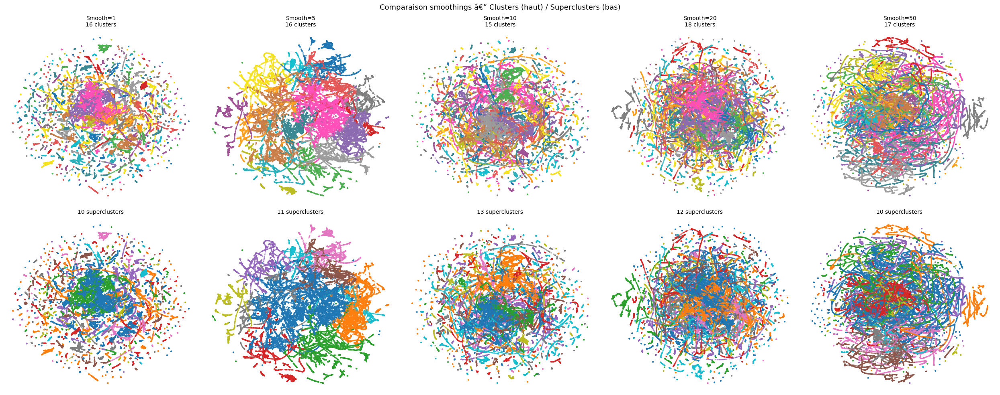

In [4]:
# graophiques de comparaison des smoothings

n_smooth = len(results_shrimp)
fig, axes = plt.subplots(2, n_smooth, figsize=(5 * n_smooth, 10))
if n_smooth == 1:
    axes = axes.reshape(2, 1)

for col, (window, res_w) in enumerate(sorted(results_shrimp.items())):
    Z_w  = res_w["Z_shrimp"]
    df_w_shrimp = res_w["df_shrimp"]
    n_cl_shrimp = res_w["n_clusters_shrimp"]
    n_su = res_w["n_superclusters_shrimp"]

    norm_su_shrimp = mpl.colors.BoundaryNorm(range(n_su + 1), ncolors=n_su)

    axes[0, col].scatter(Z_w[:, 0], Z_w[:, 1], c=df_w_shrimp["cluster"],
                         cmap=CMAP_CLUSTER_SHRIMP, norm=NORM_CLUSTER_SHRIMP, s=2, alpha=0.5)
    axes[0, col].set_title(f"Smooth={window}\n{n_cl_shrimp} clusters", fontsize=10)
    axes[0, col].axis("off")

    axes[1, col].scatter(Z_w[:, 0], Z_w[:, 1], c=df_w_shrimp["supercluster"],
                         cmap="tab10", norm=norm_su_shrimp, s=2, alpha=0.5)
    axes[1, col].set_title(f"{n_su} superclusters", fontsize=10)
    axes[1, col].axis("off")

fig.suptitle("Comparaison smoothings â€” Clusters (haut) / Superclusters (bas)", fontsize=13)
plt.tight_layout()
plt.savefig(OUT_DIR_SHRIMP / "comparison_smoothings.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
SELECTED_WINDOW_SHRIMP = 1

In [7]:
#def plot cluster

import seaborn as sns
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import dendrogram, linkage

df_shrimp              = results_shrimp[SELECTED_WINDOW_SHRIMP]["df_shrimp"].copy()
X_scaled_shrimp        = results_shrimp[SELECTED_WINDOW_SHRIMP]["X"]
Z_shrimp               = results_shrimp[SELECTED_WINDOW_SHRIMP]["Z_shrimp"]
n_clusters_shrimp      = results_shrimp[SELECTED_WINDOW_SHRIMP]["n_clusters_shrimp"]
n_superclusters_shrimp = results_shrimp[SELECTED_WINDOW_SHRIMP]["n_superclusters_shrimp"]


def plot_cluster_analysis_shrimp(df_shrimp, features, group_col="cluster", n_cols_radar=4):
    """
    Pour un groupe donné (cluster ou supercluster) :
    1. Radar plots de chaque groupe
    2. Heatmap des distances inter-groupes (normalisées min-max)
    3. Dendrogramme hiérarchique
    
    group_col : "cluster" | "supercluster"
    """
    mean_g   = df_shrimp.groupby(group_col)[features].mean()
    counts_g = df_shrimp[group_col].value_counts().sort_index()
    unique_g = mean_g.index.values

    # Normalisation min-max (identique Ã  l'affichage radar)
    g_min = mean_g.min().values
    g_max = mean_g.max().values
    mean_g_norm = pd.DataFrame(
        (mean_g.values - g_min) / (g_max - g_min + 1e-9),
        index=mean_g.index, columns=mean_g.columns
    )

    cmap        = plt.cm.tab10 if group_col == "supercluster" else CMAP_CLUSTER_SHRIMP
    norm_g      = (mpl.colors.BoundaryNorm(range(len(unique_g) + 1), ncolors=len(unique_g))
                   if group_col == "supercluster" else NORM_CLUSTER_SHRIMP)
    label_pfx   = "S" if group_col == "supercluster" else "C"

    #  1. Radar plots 
    angles   = np.linspace(0, 2 * np.pi, len(features), endpoint=False)
    ang_full = np.concatenate([angles, [angles[0]]])

    n_rows = int(np.ceil(len(unique_g) / n_cols_radar))
    fig    = plt.figure(figsize=(n_cols_radar * 4, n_rows * 4))

    for i, c in enumerate(unique_g):
        ax   = fig.add_subplot(n_rows, n_cols_radar, i + 1, polar=True)
        vals = np.concatenate([mean_g_norm.loc[c].values,
                               [mean_g_norm.loc[c].values[0]]])
        col  = cmap(norm_g(c))

        ax.plot(ang_full, vals, linewidth=2, color=col)
        ax.fill(ang_full, vals, alpha=0.25, color=col)
        ax.set_xticks(angles)
        ax.set_xticklabels([f.replace("_", "\n") for f in features], fontsize=7)
        ax.set_ylim(0, 1)
        ax.set_title(f"{label_pfx}{c}  (n={counts_g.get(c, 0)})",
                     fontsize=10, pad=10, color=col)

    fig.suptitle(f"Profils radar â€” {group_col} (smooth={SELECTED_WINDOW_SHRIMP})",
                 fontsize=13, y=1.01)
    plt.tight_layout()
    plt.savefig(OUT_DIR_SHRIMP / f"radar_smooth{SELECTED_WINDOW_SHRIMP}_{group_col}.png",
                dpi=150, bbox_inches="tight")
    plt.show()

    #  2. Heatmap + Dendrogramme 
    D_mat = squareform(pdist(mean_g_norm))
    Z_lnk = linkage(mean_g_norm, method="ward")
    labels = [f"{label_pfx}{c}" for c in unique_g]

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    sns.heatmap(D_mat, cmap="viridis", ax=axes[0],
                xticklabels=labels, yticklabels=labels, annot=len(unique_g) <= 15)
    axes[0].set_title(f"Distance inter-{group_col}s (min-max)")

    dendrogram(Z_lnk, ax=axes[1], labels=labels, leaf_rotation=45)
    axes[1].set_title(f"Dendrogramme â€” {group_col}s")

    plt.suptitle(f"Structure des {group_col}s (smooth={SELECTED_WINDOW_SHRIMP})", fontsize=12)
    plt.tight_layout()
    plt.savefig(OUT_DIR_SHRIMP / f"dist_dendro_smooth{SELECTED_WINDOW_SHRIMP}_{group_col}.png",
                dpi=150, bbox_inches="tight")
    plt.show()

    return mean_g, mean_g_norm



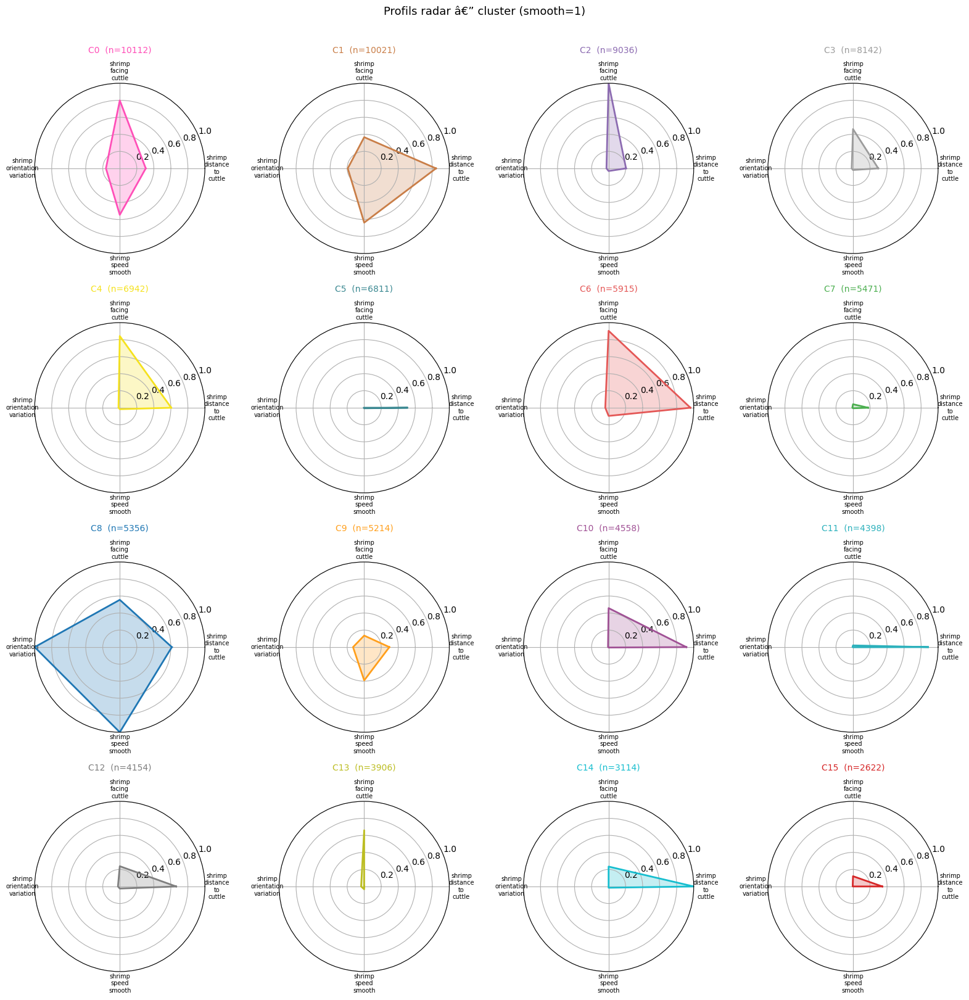

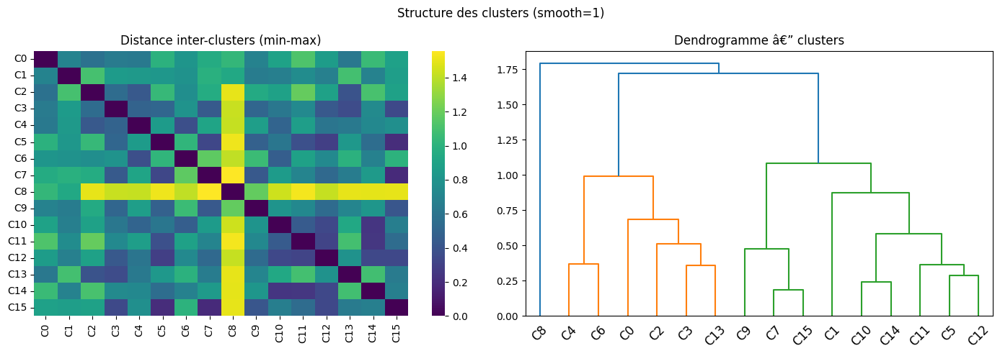

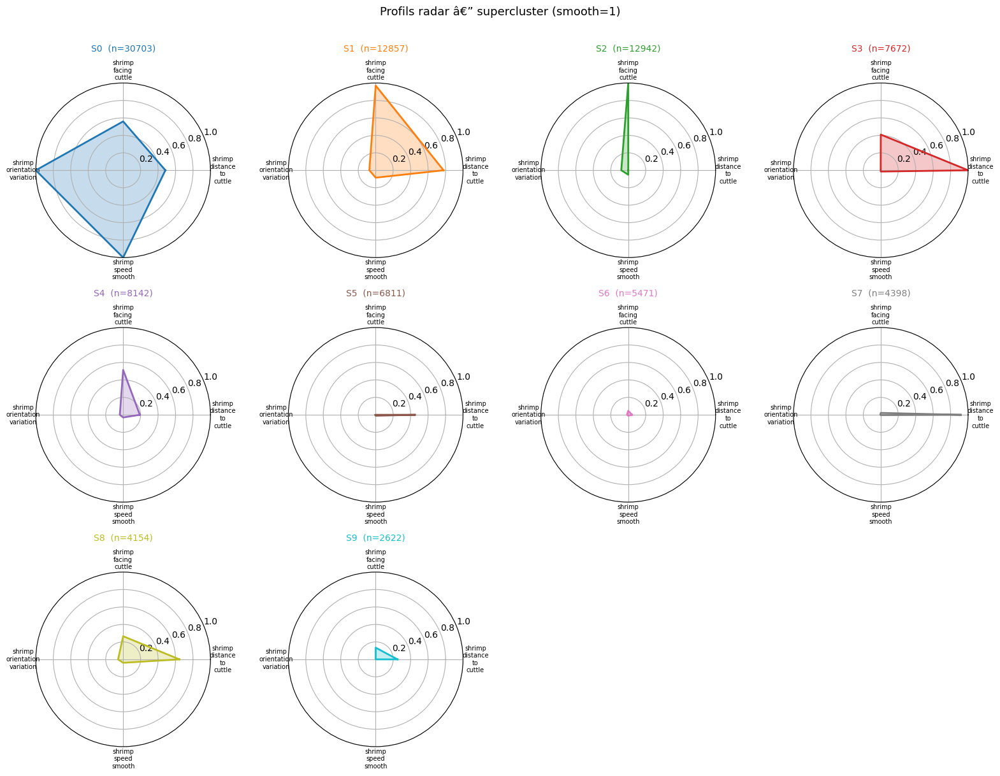

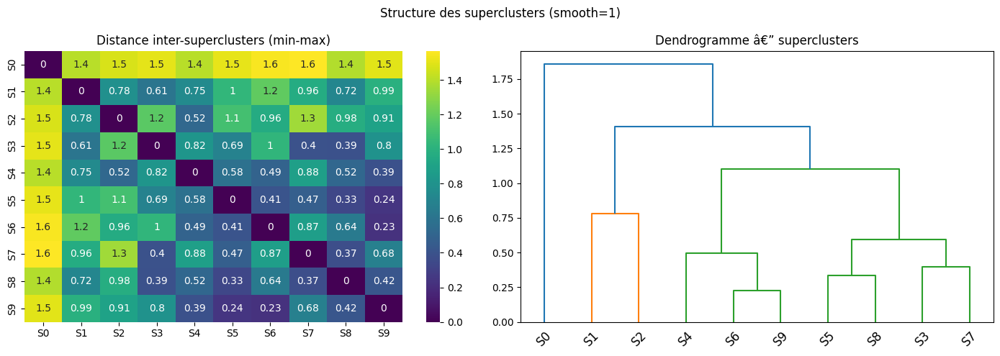

In [8]:
#plot cluster fenetres

import os
import seaborn as sns
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import dendrogram, linkage

# ── Appel ──────────────────────────────────────────────────────
%matplotlib inline

plot_cluster_analysis_shrimp(df_shrimp, FEATURES_SHRIMP, "cluster")
plot_cluster_analysis_shrimp(df_shrimp, FEATURES_SHRIMP, "supercluster")

# Ouvrir en grand dans la visionneuse Windows
os.startfile(str(OUT_DIR_SHRIMP / f"radar_smooth{SELECTED_WINDOW_SHRIMP}_cluster.png"))
os.startfile(str(OUT_DIR_SHRIMP / f"radar_smooth{SELECTED_WINDOW_SHRIMP}_supercluster.png"))

In [9]:

df_shrimp              = results_shrimp[SELECTED_WINDOW_SHRIMP]["df_shrimp"].copy()
X_scaled_shrimp        = results_shrimp[SELECTED_WINDOW_SHRIMP]["X"]
Z_shrimp               = results_shrimp[SELECTED_WINDOW_SHRIMP]["Z_shrimp"]
n_clusters_shrimp      = results_shrimp[SELECTED_WINDOW_SHRIMP]["n_clusters_shrimp"]
n_superclusters_shrimp = results_shrimp[SELECTED_WINDOW_SHRIMP]["n_superclusters_shrimp"]

animal_ids_shrimp  = sorted(df_shrimp["animal_id"].unique())
n_animals_shrimp   = len(animal_ids_shrimp)
id_to_idx_shrimp   = {aid: i for i, aid in enumerate(animal_ids_shrimp)}

def animal_color_shrimp(aid):
    return plt.cm.hsv(id_to_idx_shrimp[aid] / n_animals_shrimp)

animal_colors_per_point_shrimp = [animal_color_shrimp(aid) for aid in df_shrimp["animal_id"]]

norm_cl_shrimp = NORM_CLUSTER_SHRIMP
norm_su_shrimp = mpl.colors.BoundaryNorm(range(n_superclusters_shrimp + 1), ncolors=n_superclusters_shrimp)

print(f"[OK] Smoothing={SELECTED_WINDOW_SHRIMP} | {n_clusters_shrimp} clusters | {n_superclusters_shrimp} superclusters")
print(f"     {n_animals_shrimp} individus | {len(df_shrimp)} frames")

[OK] Smoothing=1 | 16 clusters | 10 superclusters
     202 individus | 95772 frames


In [10]:
def plot_umap_shrimp(color_by="cluster", highlight_animal=None, overlay_animal=False, save=True):
    """
    color_by         : "cluster" | "supercluster" | "animal"
    highlight_animal : animal_id Ã  mettre en surbrillance (chemin rainbow)
    overlay_animal   : True â†’ clusters en fond + individus par-dessus
    """
    fig, ax = plt.subplots(figsize=(10, 8))

    if overlay_animal:
        ax.scatter(Z_shrimp[:, 0], Z_shrimp[:, 1], c=df_shrimp["cluster"], cmap=CMAP_CLUSTER_SHRIMP, norm=NORM_CLUSTER_SHRIMP,
                   s=3, alpha=0.25)
        for aid in animal_ids_shrimp:
            mask = df_shrimp["animal_id"] == aid
            ax.scatter(Z_shrimp[mask, 0], Z_shrimp[mask, 1], color=animal_color_shrimp(aid), s=5, alpha=0.7)
        patches = [mpatches.Patch(color=animal_color_shrimp(aid), label=str(aid)) for aid in animal_ids_shrimp]
        ax.legend(handles=patches, fontsize=6, ncol=4, loc="upper right", title="animal_id")
        ax.set_title(f"UMAP overlay â€” clusters + {n_animals_shrimp} individus")

    elif color_by == "cluster":
        sc = ax.scatter(Z_shrimp[:, 0], Z_shrimp[:, 1], c=df_shrimp["cluster"], cmap=CMAP_CLUSTER_SHRIMP, norm=NORM_CLUSTER_SHRIMP,
                        s=3, alpha=0.6)
        for c in range(n_clusters_shrimp):
            mask = df_shrimp["cluster"] == c
            cx, cy = Z_shrimp[mask, 0].mean(), Z_shrimp[mask, 1].mean()
            ax.text(cx, cy, f"C{c}", fontsize=7, fontweight="bold", ha="center", va="center",
                    color="white",
                    bbox=dict(facecolor=CMAP_CLUSTER_SHRIMP(NORM_CLUSTER_SHRIMP(c)), alpha=0.7,
                              edgecolor="none", pad=1))
        plt.colorbar(sc, ax=ax, label="Cluster")
        ax.set_title(f"UMAP â€” {n_clusters_shrimp} clusters (smooth={SELECTED_WINDOW_SHRIMP})")

    elif color_by == "supercluster":
        sc = ax.scatter(Z_shrimp[:, 0], Z_shrimp[:, 1], c=df_shrimp["supercluster"], cmap="tab20", norm=norm_su_shrimp,
                        s=3, alpha=0.6)
        for c in range(n_superclusters_shrimp):
            mask = df_shrimp["supercluster"] == c
            cx, cy = Z_shrimp[mask, 0].mean(), Z_shrimp[mask, 1].mean()
            ax.text(cx, cy, f"S{c}", fontsize=9, fontweight="bold", ha="center", va="center",
                    color="white",
                    bbox=dict(facecolor=plt.cm.tab20(norm_su_shrimp(c)), alpha=0.8,
                              edgecolor="none", pad=2))
        plt.colorbar(sc, ax=ax, label="Supercluster")
        ax.set_title(f"UMAP â€” {n_superclusters_shrimp} superclusters (smooth={SELECTED_WINDOW_SHRIMP})")

    elif color_by == "animal":
        ax.scatter(Z_shrimp[:, 0], Z_shrimp[:, 1], c=animal_colors_per_point_shrimp, s=3, alpha=0.6)
        patches = [mpatches.Patch(color=animal_color_shrimp(aid), label=str(aid)) for aid in animal_ids_shrimp]
        ax.legend(handles=patches, fontsize=6, ncol=4, loc="upper right", title="animal_id")
        ax.set_title(f"UMAP â€” {n_animals_shrimp} individus (smooth={SELECTED_WINDOW_SHRIMP})")

    # Surbrillance
    if highlight_animal is not None:
        mask_h = df_shrimp["animal_id"] == highlight_animal
        Z_h    = Z_shrimp[mask_h]
        if len(Z_h) > 1:
            cols_h = plt.cm.rainbow(np.linspace(0, 1, len(Z_h)))
            for i in range(len(Z_h) - 1):
                ax.plot(Z_h[i:i+2, 0], Z_h[i:i+2, 1],
                        color=cols_h[i], linewidth=1.5, alpha=0.9)
            ax.scatter(Z_h[0, 0],  Z_h[0, 1],  c="lime",  s=80, zorder=6, label="début")
            ax.scatter(Z_h[-1, 0], Z_h[-1, 1], c="white", s=80, zorder=6, label="fin")
            ax.legend(fontsize=8)
        ax.set_title(ax.get_title() + f"\nâ†’ Animal {highlight_animal}")

    ax.axis("off")
    plt.tight_layout()

    if save:
        suffix = "_overlay" if overlay_animal else f"_{color_by}"
        if highlight_animal is not None:
            suffix += f"_animal{highlight_animal}"
        plt.savefig(OUT_DIR_SHRIMP / f"umap_smooth{SELECTED_WINDOW_SHRIMP}{suffix}.png",
                    dpi=150, bbox_inches="tight")
    plt.show()

print("[OK] Fonction plot_umap_shrimp définie")

[OK] Fonction plot_umap_shrimp définie


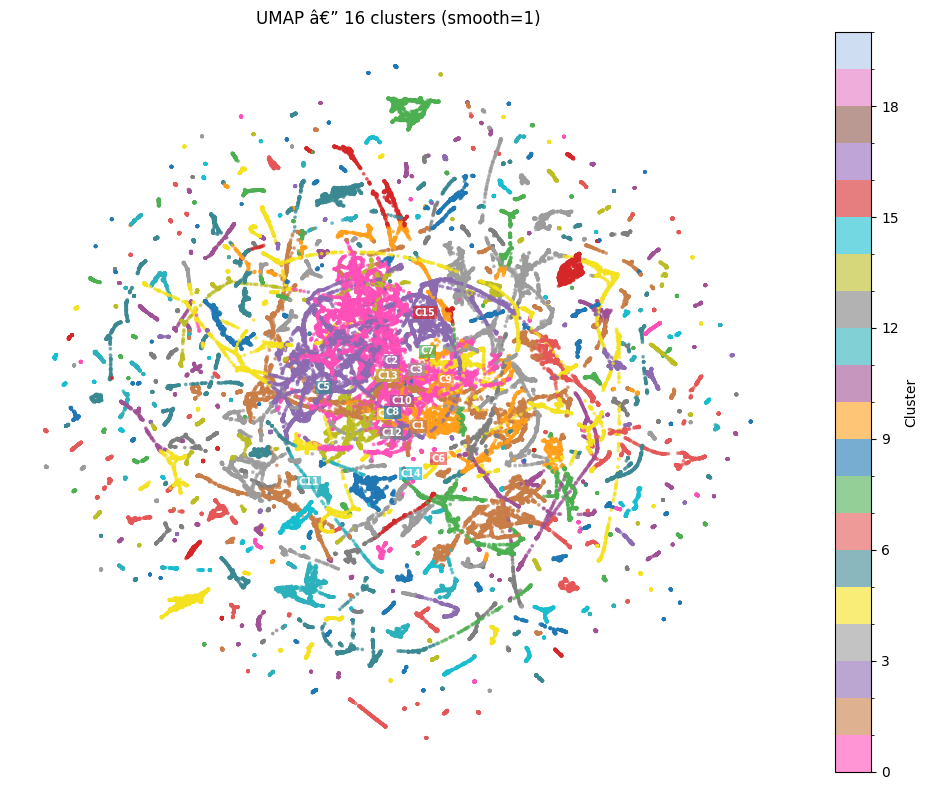

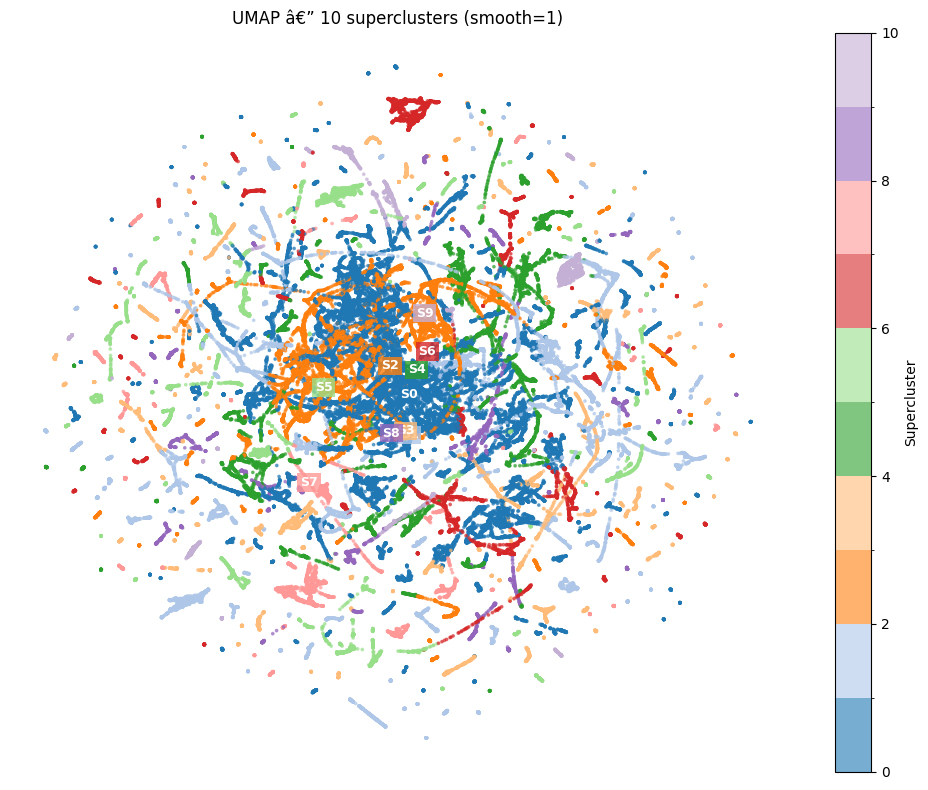

In [11]:
plot_umap_shrimp(color_by="cluster")
plot_umap_shrimp(color_by="supercluster")
# plot_umap_shrimp(color_by="animal")
# plot_umap_shrimp(overlay_animal=True)

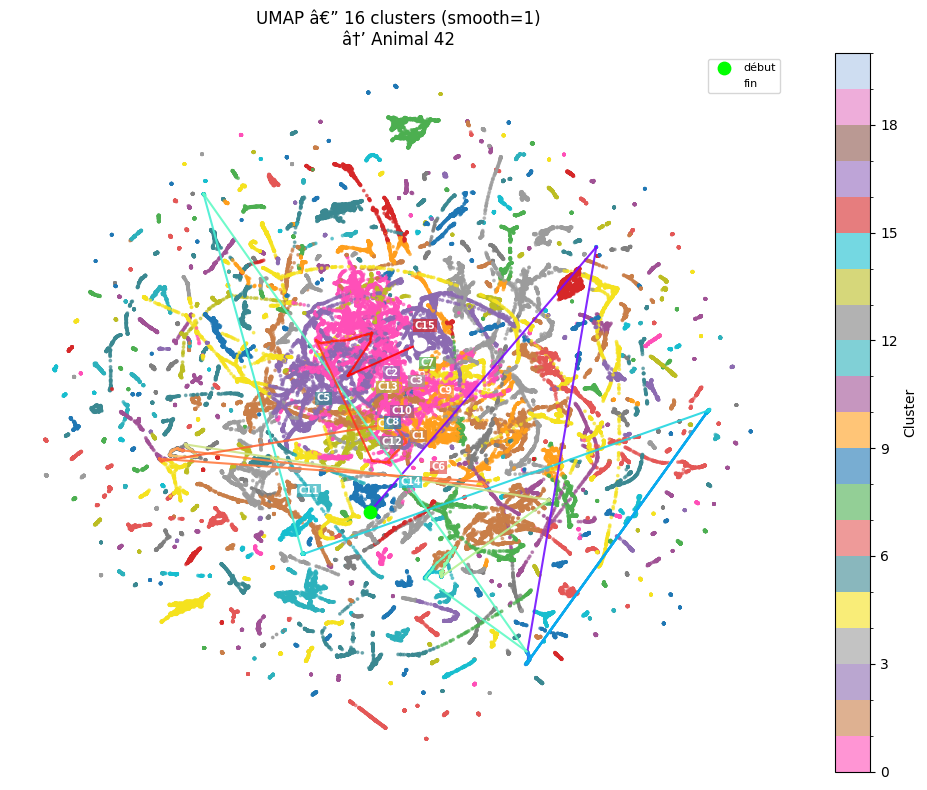

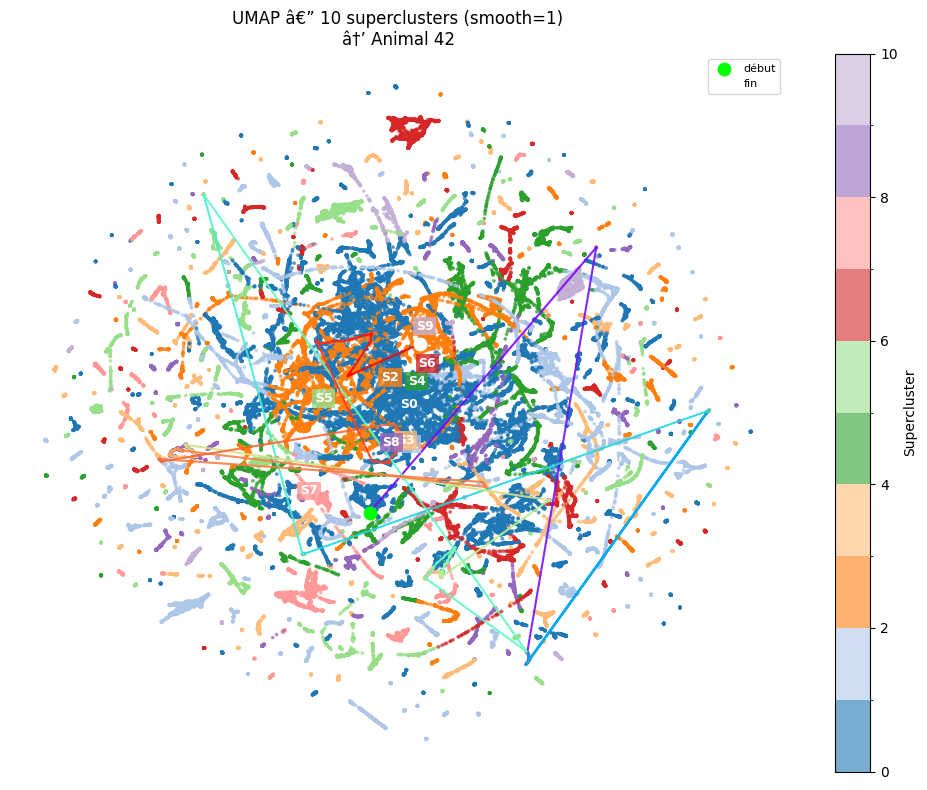

In [12]:
#specific animal
HIGHLIGHT_ANIMAL_SHRIMP = animal_ids_shrimp[42]-1

plot_umap_shrimp(color_by="cluster",      highlight_animal=HIGHLIGHT_ANIMAL_SHRIMP)
plot_umap_shrimp(color_by="supercluster", highlight_animal=HIGHLIGHT_ANIMAL_SHRIMP)

In [13]:
def plot_animal_trajectory_shrimp(animal_id, df_shrimp, group_col="cluster", features=FEATURES_SHRIMP):
    """
    Trace la trajectoire 2D et les variables temporelles d'un individu.
    
    animal_id  : ID de l'animal
    group_col  : "cluster" | "supercluster" â€” colonne utilisée pour la couleur
    features   : liste des features a afficher dans le graphe temporel
    """
    cf_df = df_shrimp[df_shrimp["animal_id"] == animal_id].reset_index(drop=True)
    
    if len(cf_df) == 0:
        print(f"[ERREUR] Animal {animal_id} introuvable dans df_shrimp")
        return

    cluster_colors = cf_df[group_col].values
    unique_labs    = np.unique(cluster_colors)

    # Norm adaptée selon le groupe choisi
    if group_col == "supercluster":
        n_groups = n_superclusters_shrimp
        cmap     = plt.cm.tab10
        norm_g   = mpl.colors.BoundaryNorm(range(n_groups + 1), ncolors=n_groups)
        label_prefix = "S"
    else:
        n_groups = n_clusters_shrimp
        cmap     = CMAP_CLUSTER_SHRIMP
        norm_g   = NORM_CLUSTER_SHRIMP
        label_prefix = "C"

    def get_color(label):
        return cmap(norm_g(label))

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # â”€â”€ Trajectoire 2D â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    for i in range(len(cf_df) - 1):
        color = get_color(cluster_colors[i])
        axes[0].plot(
            cf_df["HeadShrimp_x"][i:i+2],
            cf_df["HeadShrimp_y"][i:i+2],
            "-o", color=color, markersize=2, linewidth=1
        )

    # Début / fin
    axes[0].scatter(cf_df["HeadShrimp_x"].iloc[0],  cf_df["HeadShrimp_y"].iloc[0],
                    color="lime",  s=60, zorder=5, label="début")
    axes[0].scatter(cf_df["HeadShrimp_x"].iloc[-1], cf_df["HeadShrimp_y"].iloc[-1],
                    color="white", s=60, zorder=5, label="fin")
    axes[0].invert_yaxis()
    axes[0].set_title(f"Animal {animal_id} â€” Trajectoire ({group_col})")
    axes[0].set_xlabel("X (px)")
    axes[0].set_ylabel("Y (px)")

    legend_patches = [
        mpatches.Patch(color=get_color(c), label=f"{label_prefix}{c}")
        for c in unique_labs
    ] + [
        mpatches.Patch(color="lime",  label="début"),
        mpatches.Patch(color="white", label="fin"),
    ]
    axes[0].legend(handles=legend_patches, fontsize=7, loc="upper right")

    # â”€â”€ Variables temporelles â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    for var in features:
        max_val = cf_df[var].max()
        if max_val > 0:
            axes[1].plot(cf_df[var] / max_val, label=var, alpha=0.7)
        else:
            axes[1].plot(cf_df[var], label=var, alpha=0.7)

    # Fonds colorés par cluster
    for i, lab in enumerate(cluster_colors):
        axes[1].axvspan(i, i + 1, color=get_color(lab), alpha=0.15)

    axes[1].set_title(f"Animal {animal_id} â€” Variables normalisées ({group_col})")
    axes[1].set_xlabel("Frame")
    axes[1].legend(fontsize=7)

    plt.suptitle(f"Animal {animal_id} | smooth={SELECTED_WINDOW_SHRIMP} | {group_col}", fontsize=12)
    plt.tight_layout()

    plt.savefig(OUT_DIR_SHRIMP / f"traj_smooth{SELECTED_WINDOW_SHRIMP}_{group_col}_animal{animal_id}.png",
                dpi=150, bbox_inches="tight")
    plt.show()


# â”€â”€ Utilisation â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
# Change l'animal_id et group_col ici


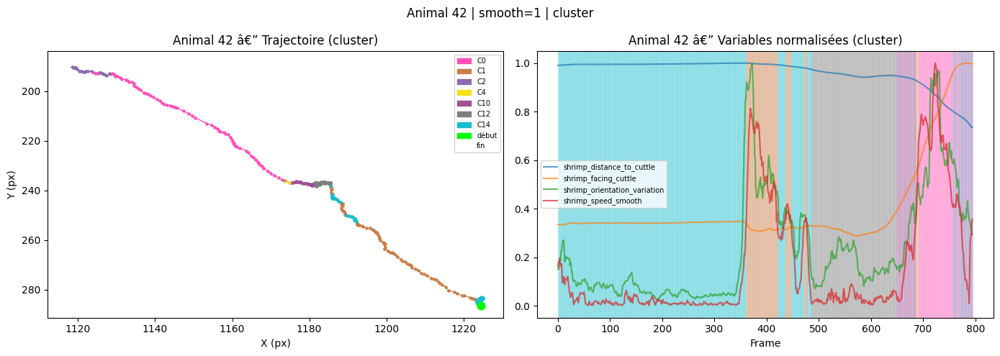

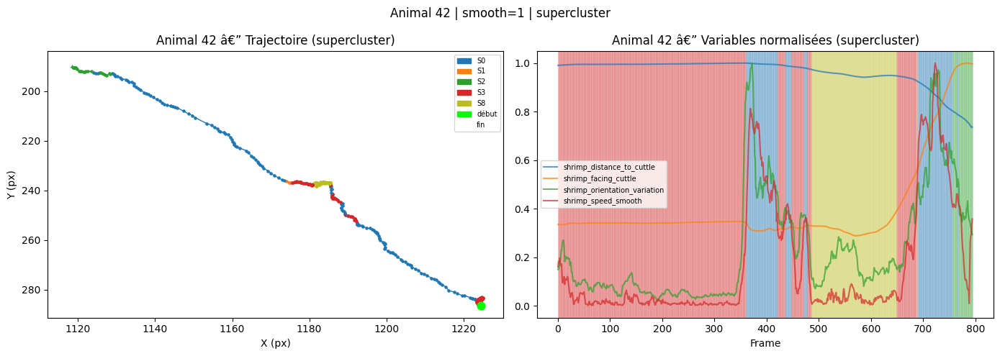

In [14]:
ANIMAL_ID_SHRIMP = animal_ids_shrimp[42]-1   # â† ou un ID spécifique comme 42

plot_animal_trajectory_shrimp(ANIMAL_ID_SHRIMP, df_shrimp, group_col="cluster")
plot_animal_trajectory_shrimp(ANIMAL_ID_SHRIMP, df_shrimp, group_col="supercluster")

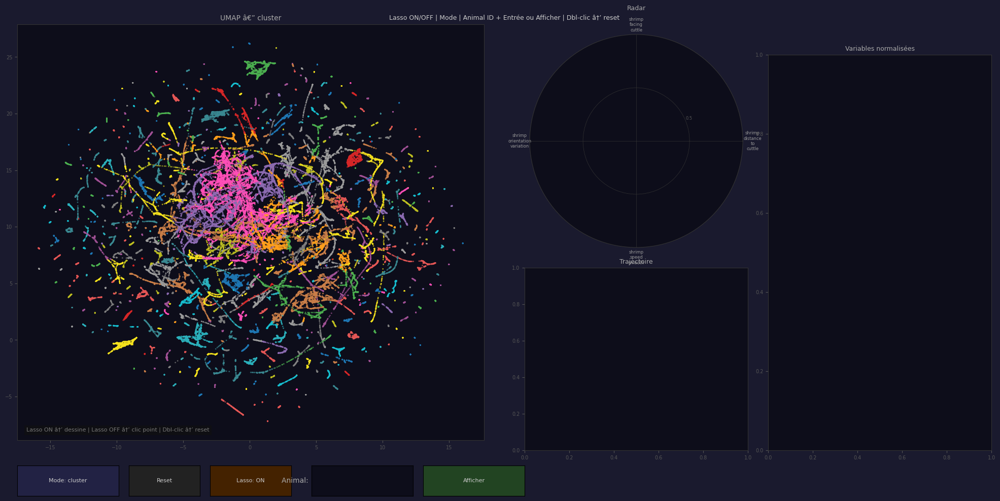

In [15]:
#plot interactif umap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.widgets import LassoSelector, Button, TextBox
from matplotlib.path import Path

%matplotlib qt

def plot_umap_interactive_radar_shrimp(df_shrimp, Z_shrimp, features, n_clusters_shrimp, n_superclusters_shrimp,
                                 color_by="cluster"):

    state = {"color_by": color_by, "lasso_active": True}

    global_min = df_shrimp[features].min().values
    global_max = df_shrimp[features].max().values
    angles     = np.linspace(0, 2 * np.pi, len(features), endpoint=False)
    ang_full   = np.concatenate([angles, [angles[0]]])
    Z_pts      = np.column_stack([Z_shrimp[:, 0], Z_shrimp[:, 1]])

    # Tout en str pour éviter les mismatch de type
    df_shrimp = df_shrimp.copy()
    df_shrimp["animal_id"] = df_shrimp["animal_id"].astype(str)
    animal_ids_shrimp = sorted(df_shrimp["animal_id"].unique())
    n_animals_shrimp  = len(animal_ids_shrimp)
    id_to_idx_shrimp  = {aid: i for i, aid in enumerate(animal_ids_shrimp)}

    def get_col_data(cb):
        if cb == "supercluster":
            return (df_shrimp["supercluster"].values, plt.cm.tab10,
                    mpl.colors.BoundaryNorm(range(n_superclusters_shrimp+1), ncolors=n_superclusters_shrimp), "S")
        elif cb == "cluster":
            return (df_shrimp["cluster"].values, CMAP_CLUSTER_SHRIMP, NORM_CLUSTER_SHRIMP, "C")
        else:
            col = np.array([id_to_idx_shrimp[a] for a in df_shrimp["animal_id"]])
            return (col, plt.cm.hsv,
                    mpl.colors.Normalize(vmin=0, vmax=n_animals_shrimp), "A")

    # â”€â”€ Figure â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    fig = plt.figure(figsize=(20, 10))
    fig.patch.set_facecolor("#1a1a2e")

    ax_umap  = fig.add_axes([0.02, 0.14, 0.46, 0.82])
    ax_radar = fig.add_axes([0.52, 0.52, 0.22, 0.42], polar=True)
    ax_traj  = fig.add_axes([0.52, 0.12, 0.22, 0.36])
    ax_feats = fig.add_axes([0.76, 0.12, 0.22, 0.78])

    for ax in [ax_umap, ax_radar, ax_traj, ax_feats]:
        ax.set_facecolor("#0d0d1a")
        for spine in ax.spines.values():
            spine.set_edgecolor("#333333")
        ax.tick_params(colors="#555555", labelsize=7)

    # â”€â”€ Widgets â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    ax_btn_mode   = fig.add_axes([0.02, 0.03, 0.10, 0.06])
    ax_btn_reset  = fig.add_axes([0.13, 0.03, 0.07, 0.06])
    ax_btn_lasso  = fig.add_axes([0.21, 0.03, 0.08, 0.06])
    ax_textbox    = fig.add_axes([0.31, 0.03, 0.10, 0.06])
    ax_btn_animal = fig.add_axes([0.42, 0.03, 0.10, 0.06])

    btn_mode   = Button(ax_btn_mode,  f"Mode: {color_by}", color="#222244", hovercolor="#333366")
    btn_reset  = Button(ax_btn_reset, "Reset",             color="#222222", hovercolor="#333333")
    btn_lasso  = Button(ax_btn_lasso, "Lasso: ON",         color="#442200", hovercolor="#663300")
    textbox    = TextBox(ax_textbox,  "Animal: ",          initial="",
                         color="#0d0d1a", hovercolor="#1a1a2e")
    btn_animal = Button(ax_btn_animal,"Afficher",          color="#224422", hovercolor="#336633")

    for btn in [btn_mode, btn_reset, btn_lasso, btn_animal]:
        btn.label.set_color("#cccccc")
        btn.label.set_fontsize(8)
    textbox.label.set_color("#aaaaaa")
    textbox.text_disp.set_color("#ffffff")

    # â”€â”€ Scatter â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    col_data, cmap, norm_g, _ = get_col_data(state["color_by"])
    sc        = ax_umap.scatter(Z_pts[:,0], Z_pts[:,1],
                                 c=[cmap(norm_g(c)) for c in col_data],
                                 s=4, alpha=0.7, linewidths=0, zorder=2)
    hl_lasso  = ax_umap.scatter([], [], s=20, facecolors="none",
                                 edgecolors="white", linewidths=0.7, zorder=4)
    hl_animal = ax_umap.scatter([], [], s=15, zorder=5)
    hl_click  = ax_umap.scatter([], [], s=120, marker="*",
                                 facecolors="yellow", edgecolors="white",
                                 linewidths=0.7, zorder=6)

    ax_umap.set_facecolor("#0d0d1a")
    ax_umap.set_title(f"UMAP â€” {state['color_by']}", color="#aaaaaa", fontsize=10)
    for spine in ax_umap.spines.values():
        spine.set_edgecolor("#333333")

    info_text = ax_umap.text(
        0.02, 0.02,
        "Lasso ON â†’ dessine | Lasso OFF â†’ clic point | Dbl-clic â†’ reset",
        transform=ax_umap.transAxes, color="#777777", fontsize=8,
        bbox=dict(facecolor="#111111", alpha=0.7, edgecolor="none", pad=3)
    )

    # â”€â”€ Radar â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    def setup_radar():
        ax_radar.cla()
        ax_radar.set_facecolor("#0d0d1a")
        ax_radar.set_xticks(angles)
        ax_radar.set_xticklabels([f.replace("_", "\n") for f in features],
                                  color="#999999", fontsize=6)
        ax_radar.set_ylim(0, 1)
        ax_radar.set_yticks([0.5])
        ax_radar.set_yticklabels(["0.5"], color="#555555", fontsize=6)
        ax_radar.grid(color="#333333", linewidth=0.5)
        ax_radar.spines["polar"].set_color("#333333")
        ax_radar.set_title("Radar", color="#aaaaaa", fontsize=9, pad=10)

    def draw_radar(norm_vals, color, title):
        setup_radar()
        vf = np.concatenate([norm_vals, [norm_vals[0]]])
        ax_radar.plot(ang_full, vf, linewidth=2, color=color)
        ax_radar.fill(ang_full, vf, alpha=0.3, color=color)
        for a, vn in zip(angles, norm_vals):
            ax_radar.text(a, min(vn + 0.15, 1.1), f"{vn:.2f}",
                          ha="center", va="center", color="#dddddd", fontsize=6,
                          bbox=dict(facecolor="#111111", alpha=0.5, edgecolor="none", pad=1))
        ax_radar.set_title(title, color="#aaaaaa", fontsize=8, pad=10)
        fig.canvas.draw_idle()

    setup_radar()

    # â”€â”€ Traj + feats â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    def setup_traj():
        ax_traj.cla()
        ax_traj.set_facecolor("#0d0d1a")
        ax_traj.set_title("Trajectoire", color="#aaaaaa", fontsize=9)
        for spine in ax_traj.spines.values():
            spine.set_edgecolor("#333333")
        ax_traj.tick_params(colors="#555555", labelsize=7)

    def setup_feats():
        ax_feats.cla()
        ax_feats.set_facecolor("#0d0d1a")
        ax_feats.set_title("Variables normalisées", color="#aaaaaa", fontsize=9)
        for spine in ax_feats.spines.values():
            spine.set_edgecolor("#333333")
        ax_feats.tick_params(colors="#555555", labelsize=7)

    setup_traj()
    setup_feats()

    # â”€â”€ Lasso â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    def on_lasso(verts):
        if not state["lasso_active"]:
            return
        lasso_path   = Path(verts)
        inside       = lasso_path.contains_points(Z_pts)
        selected_idx = np.where(inside)[0]
        n_sel        = len(selected_idx)

        if n_sel == 0:
            info_text.set_text("Lasso vide")
            hl_lasso.set_offsets(np.empty((0, 2)))
            fig.canvas.draw_idle()
            return

        hl_lasso.set_offsets(Z_pts[selected_idx])
        raw_vals  = df_shrimp[features].values[selected_idx].mean(axis=0)
        norm_vals = np.clip((raw_vals - global_min)/(global_max - global_min + 1e-9), 0, 1)

        cd, cm, ng, lpfx = get_col_data(state["color_by"])
        if state["color_by"] in ("cluster", "supercluster"):
            counts   = pd.Series(cd[selected_idx]).value_counts()
            dominant = counts.idxmax()
            color    = cm(ng(dominant))
            comp     = " | ".join([f"{lpfx}{g}:{n}" for g, n in counts.items()])
        else:
            color = "#44aaff"
            comp  = f"{pd.Series(df_shrimp['animal_id'].values[selected_idx]).nunique()} individus"

        info_text.set_text(f"{n_sel} pts â€” {comp}")
        draw_radar(norm_vals, color, f"Lasso n={n_sel}")

    lasso_selector = LassoSelector(ax_umap, on_lasso,
                                    props=dict(color="#FFD700", linewidth=1.5),
                                    useblit=True, button=1)

    # â”€â”€ Clic â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    def on_click(event):
        if event.inaxes != ax_umap:
            return
        if event.dblclick:
            reset(None); return
        if state["lasso_active"]:
            return  # lasso gère les clics quand actif
        if event.button != 1 or event.xdata is None:
            return

        xy   = np.array([event.xdata, event.ydata])
        dist = np.linalg.norm(Z_pts - xy, axis=1)
        idx  = int(np.argmin(dist))
        xlim = ax_umap.get_xlim()
        if dist[idx] > (xlim[1] - xlim[0]) * 0.05:
            return

        hl_click.set_offsets([Z_pts[idx]])
        raw_vals  = df_shrimp[features].values[idx]
        norm_vals = np.clip((raw_vals - global_min)/(global_max - global_min + 1e-9), 0, 1)
        cd, cm, ng, lpfx = get_col_data(state["color_by"])
        color = cm(ng(cd[idx]))
        label = f"{lpfx}{cd[idx]} | animal {df_shrimp['animal_id'].iloc[idx]}"
        info_text.set_text(f"Point {idx} â€” {label}")
        draw_radar(norm_vals, color, f"Point {idx}\n{label}")

    fig.canvas.mpl_connect("button_press_event", on_click)

    # â”€â”€ Bouton lasso ON/OFF â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    # Désactiver le lasso libère les clics pour le TextBox et le clic point
    def toggle_lasso(event):
        state["lasso_active"] = not state["lasso_active"]
        if state["lasso_active"]:
            lasso_selector.set_active(True)
            btn_lasso.label.set_text("Lasso: ON")
            btn_lasso.ax.set_facecolor("#442200")
            info_text.set_text("Lasso ON â€” dessine une zone")
        else:
            lasso_selector.set_active(False)
            btn_lasso.label.set_text("Lasso: OFF")
            btn_lasso.ax.set_facecolor("#004422")
            info_text.set_text("Lasso OFF â€” clic point | écris animal_id")
        fig.canvas.draw_idle()

    btn_lasso.on_clicked(toggle_lasso)

    # â”€â”€ Bouton mode â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    modes = ["supercluster", "cluster", "animal"]

    def toggle_mode(event):
        idx = modes.index(state["color_by"])
        state["color_by"] = modes[(idx + 1) % len(modes)]
        btn_mode.label.set_text(f"Mode: {state['color_by']}")
        cd, cm, ng, _ = get_col_data(state["color_by"])
        sc.set_facecolors([cm(ng(c)) for c in cd])
        ax_umap.set_title(f"UMAP â€” {state['color_by']}", color="#aaaaaa", fontsize=10)
        fig.canvas.draw_idle()

    btn_mode.on_clicked(toggle_mode)

    # â”€â”€ Bouton reset â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    def reset(event):
        hl_lasso.set_offsets(np.empty((0, 2)))
        hl_animal.set_offsets(np.empty((0, 2)))
        hl_click.set_offsets(np.empty((0, 2)))
        info_text.set_text("Reset")
        setup_radar()
        ax_radar.set_title("Radar", color="#aaaaaa", fontsize=9, pad=10)
        setup_traj()
        setup_feats()
        fig.canvas.draw_idle()

    btn_reset.on_clicked(reset)

    # â”€â”€ Bouton animal â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    def show_animal(event):
        raw = textbox.text.strip()
        if not raw:
            info_text.set_text(f"Exemples d'IDs : {', '.join(animal_ids_shrimp[:6])}")
            fig.canvas.draw_idle()
            return

        aid = str(raw)
        if aid not in df_shrimp["animal_id"].values:
            sample = ", ".join(animal_ids_shrimp[:8])
            info_text.set_text(f"'{aid}' introuvable. Exemples : {sample}")
            fig.canvas.draw_idle()
            return

        mask = df_shrimp["animal_id"].values == aid
        idx  = np.where(mask)[0]
        n_a  = len(idx)

        # Surbrillance UMAP rainbow
        colors_r = plt.cm.rainbow(np.linspace(0, 1, n_a))
        hl_animal.set_offsets(Z_pts[idx])
        hl_animal.set_facecolors(colors_r)
        hl_animal.set_sizes([15] * n_a)

        # Radar moyen
        raw_vals  = df_shrimp[features].values[mask].mean(axis=0)
        norm_vals = np.clip((raw_vals - global_min)/(global_max - global_min + 1e-9), 0, 1)
        draw_radar(norm_vals, "#44aaff", f"Animal {aid} (n={n_a})")

        # Trajectoire
        setup_traj()
        cf = df_shrimp[mask].reset_index(drop=True)
        cl = df_shrimp["cluster"].values[mask]
        _, cm_c, ng_c, _ = get_col_data("cluster")
        for i in range(len(cf) - 1):
            ax_traj.plot(cf["TopMantle_x"].iloc[i:i+2],
                         cf["TopMantle_y"].iloc[i:i+2],
                         "-o", color=cm_c(ng_c(cl[i])),
                         markersize=1.5, linewidth=0.8)
        ax_traj.scatter(cf["TopMantle_x"].iloc[0],  cf["TopMantle_y"].iloc[0],
                        color="lime", s=40, zorder=5)
        ax_traj.scatter(cf["TopMantle_x"].iloc[-1], cf["TopMantle_y"].iloc[-1],
                        color="white", s=40, zorder=5)
        ax_traj.invert_yaxis()
        ax_traj.set_title(f"Animal {aid}", color="#aaaaaa", fontsize=9)

        # Features temporelles
        setup_feats()
        t = np.arange(n_a)
        for feat in features:
            fmax = cf[feat].max()
            ax_feats.plot(t, cf[feat] / (fmax + 1e-9),
                          label=feat.replace("_"," "), alpha=0.8, linewidth=1)
        ax_feats.legend(fontsize=6, loc="upper right")
        ax_feats.set_xlabel("Frame", color="#555555", fontsize=7)
        ax_feats.set_title(f"Variables â€” animal {aid}", color="#aaaaaa", fontsize=9)

        info_text.set_text(f"Animal {aid} â€” {n_a} frames")
        fig.canvas.draw_idle()

    btn_animal.on_clicked(show_animal)

    # Appuyer sur Entrée dans le textbox = mÃªme effet que le bouton
    textbox.on_submit(lambda text: show_animal(None))

    plt.suptitle("Lasso ON/OFF | Mode | Animal ID + Entrée ou Afficher | Dbl-clic â†’ reset",
                 color="#cccccc", fontsize=9)
    plt.show()
    return fig


plot_umap_interactive_radar_shrimp(df_shrimp, Z_shrimp, FEATURES_SHRIMP, n_clusters_shrimp, n_superclusters_shrimp,
                             color_by="cluster")

In [16]:
%matplotlib inline

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.widgets import Button, Slider, TextBox
from collections import Counter
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy.spatial.distance import pdist, squareform
from sklearn.preprocessing import StandardScaler


# ── Extraction des séquences ──────────────────────────────────
def _extract_sequences_shrimp(df_shrimp, cluster_col, seuil_min):
    sequences, mono_ids, multi_ids = {}, [], []
    for aid, group in df_shrimp.groupby("animal_id"):
        raw = group.sort_values("frame")[cluster_col].values
        blocks, lengths = [], []
        cur, start = raw[0], 0
        for i in range(1, len(raw)):
            if raw[i] != cur:
                blocks.append(int(cur)); lengths.append(i - start)
                cur, start = raw[i], i
        blocks.append(int(cur)); lengths.append(len(raw) - start)
        fb, fl = [], []
        for b, l in zip(blocks, lengths):
            if l >= seuil_min:
                if fb and fb[-1] == b: fl[-1] += l
                else: fb.append(b); fl.append(l)
        sequences[aid] = {"seq": fb, "lengths": fl}
        (mono_ids if len(set(fb)) <= 1 else multi_ids).append(aid)
    return sequences, mono_ids, multi_ids


# ── SeqVec ────────────────────────────────────────────────────
def _seqvec_shrimp(sequences, ids, n_cl_shrimp,
            w_hist=1.0, w_trans=1.0, w_runlen=1.0, w_firstapp=1.0,
            w_temporal=1.0, w_context=1.0, w_global=1.0):

    def feat_hist(s, l, n):
        t = sum(l); c = Counter()
        for cl, ln in zip(s, l): c[cl] += ln
        raw = np.array([c.get(i, 0) / t for i in range(n)])
        return np.log1p(raw * 10) / np.log1p(10)

    def feat_trans(s, n):
        m = np.zeros((n, n))
        for a, b in zip(s[:-1], s[1:]):
            if 0 <= a < n and 0 <= b < n: m[a, b] += 1
        rs = m.sum(axis=1, keepdims=True)
        p  = np.where(rs > 0, m / rs, 0)
        ent = np.zeros(n)
        for i in range(n):
            row = p[i][p[i] > 0]
            if len(row) > 1:
                ent[i] = -np.sum(row * np.log(row)) / np.log(n)
        return np.concatenate([p.flatten(), ent])

    def feat_runlen(s, l, n):
        d = {i: [] for i in range(n)}
        for cl, ln in zip(s, l):
            if cl < n: d[cl].append(ln)
        med = np.array([np.median(d[i]) if d[i] else 0 for i in range(n)])
        mx  = np.array([max(d[i])       if d[i] else 0 for i in range(n)])
        cv  = np.array([np.std(d[i]) / (np.mean(d[i]) + 1e-9)
                        if len(d[i]) > 1 else 0 for i in range(n)])
        return np.concatenate([med, mx, cv])

    def feat_firstapp(s, n):
        present  = np.zeros(n)
        position = np.full(n, 0.5)
        for i in range(n):
            try:
                idx = s.index(i)
                present[i]  = 1.0
                position[i] = idx / max(len(s) - 1, 1)
            except ValueError:
                pass
        return np.concatenate([present, position])

    def feat_temporal(s, l, n):
        total = sum(l); half = total / 2
        h1 = np.zeros(n); h2 = np.zeros(n)
        cum = 0
        for cl, ln in zip(s, l):
            if cl >= n: cum += ln; continue
            in_h1 = max(0, min(ln, half - cum))
            in_h2 = ln - in_h1
            h1[cl] += in_h1; h2[cl] += in_h2
            cum += ln
        t1 = h1 / (total/2 + 1e-9)
        t2 = h2 / (total/2 + 1e-9)
        return np.concatenate([t1, t2, t2 - t1])

    def feat_context(s, n):
        first_oh = np.zeros(n); last_oh = np.zeros(n)
        if s:
            if 0 <= s[0]  < n: first_oh[s[0]]  = 1.0
            if 0 <= s[-1] < n: last_oh[s[-1]] = 1.0
        n_start = max(1, len(s) // 10)
        dom_start = np.zeros(n); dom_end = np.zeros(n)
        if s[:n_start]:
            c_s = Counter(s[:n_start]).most_common(1)[0][0]
            if 0 <= c_s < n: dom_start[c_s] = 1.0
        if s[-n_start:]:
            c_e = Counter(s[-n_start:]).most_common(1)[0][0]
            if 0 <= c_e < n: dom_end[c_e] = 1.0
        return np.concatenate([first_oh, last_oh, dom_start, dom_end])

    def feat_global(s, l, n):
        total = sum(l); n_used = len(set(s))
        richness = n_used / n
        c = Counter()
        for cl, ln in zip(s, l): c[cl] += ln
        hist_raw = np.array([c.get(i, 0) / total for i in range(n)])
        h_vals   = hist_raw[hist_raw > 0]
        entropy  = (-np.sum(h_vals * np.log(h_vals)) / np.log(n)
                    if len(h_vals) > 1 else 0.0)
        inertia  = hist_raw.max()
        pairs_dist = len({(a, b) for a, b in zip(s[:-1], s[1:]) if a != b})
        trans_rich = pairs_dist / (n * (n - 1)) if n > 1 else 0.0
        return np.array([richness, entropy, inertia, trans_rich, len(s)])

    max_total = max(sum(sequences[aid]["lengths"]) for aid in ids)
    rows = []
    for aid in ids:
        s, l = sequences[aid]["seq"], sequences[aid]["lengths"]
        total = sum(l)
        if not s:
            n_feat = (n_cl_shrimp + n_cl_shrimp*n_cl_shrimp + n_cl_shrimp + n_cl_shrimp*3 + n_cl_shrimp*2
                      + n_cl_shrimp*3 + n_cl_shrimp*4 + 6)
            rows.append(np.zeros(n_feat)); continue
        norm_total = total / max_total
        rows.append(np.concatenate([
            feat_hist(s, l, n_cl_shrimp)    * w_hist,
            feat_trans(s, n_cl_shrimp)      * w_trans,
            feat_runlen(s, l, n_cl_shrimp)  * w_runlen,
            feat_firstapp(s, n_cl_shrimp)   * w_firstapp,
            feat_temporal(s, l, n_cl_shrimp)* w_temporal,
            feat_context(s, n_cl_shrimp)    * w_context,
            np.append(feat_global(s, l, n_cl_shrimp), norm_total) * w_global,
        ]))

    X    = StandardScaler().fit_transform(np.array(rows))
    D    = squareform(pdist(X, "euclidean"))
    desc = f"SeqVec+ ({X.shape[1]} features)"
    print(f"[SEQVEC] {len(ids)} individus × {X.shape[1]} features")
    return X, D, desc


# ── Clustering hiérarchique ───────────────────────────────────
def _cluster_hier_shrimp(D, ids, n_strat, linkage_method="ward"):
    Z_shrimp      = linkage(squareform(np.clip(D, 0, None)), method=linkage_method)
    labels = fcluster(Z_shrimp, n_strat, criterion="maxclust")
    n2l    = {n: str(i) for i, n in enumerate(sorted(set(labels)))}
    return {aid: n2l[lab] for aid, lab in zip(ids, labels)}, Z_shrimp


# ── Leiden pour estimer K optimal ────────────────────────────
def _leiden_optimal_k_shrimp(D, ids, resolution_range=None):
    try:
        import igraph as ig
        import leidenalg
    except ImportError:
        print("[WARN] igraph/leidenalg non disponibles")
        return None, {}
    n = len(ids)
    if n < 3: return None, {}
    D_max = D.max()
    if D_max == 0: return 1, {}
    sim       = 1 - D / D_max
    threshold = np.percentile(sim[sim > 0], 50)
    edges, weights = [], []
    for i in range(n):
        for j in range(i+1, n):
            if sim[i, j] > threshold:
                edges.append((i, j)); weights.append(float(sim[i, j]))
    if not edges: return 1, {}
    g = ig.Graph(n=n, edges=edges)
    g.es["weight"] = weights
    if resolution_range is None:
        resolution_range = [0.01, 0.1, 0.3, 0.5, 0.8, 1.0, 1.5, 2.0, 3.0]
    results_shrimp = {}
    for res in resolution_range:
        part = leidenalg.find_partition(
            g, leidenalg.RBConfigurationVertexPartition,
            weights="weight", resolution_parameter=res, seed=42)
        results_shrimp[res] = {"k": len(set(part.membership)),
                        "quality": part.quality()}
    best_res  = max(results_shrimp, key=lambda r: results_shrimp[r]["quality"])
    k_optimal = results_shrimp[best_res]["k"]
    print(f"\n[LEIDEN] K optimal = {k_optimal} (résolution={best_res:.2f})")
    for res, r in results_shrimp.items():
        print(f"  res={res:.1f} → K={r['k']} qualité={r['quality']:.3f}")
    return k_optimal, results_shrimp


# ── Fenêtre principale ────────────────────────────────────────
def show_strategy_explorer_shrimp(
    df_shrimp,
    cluster_col    = "supercluster",
    n_strategies   = 4,
    seuil_min      = 3,
    use_leiden_k   = False,
    linkage_method = "ward",
    w_hist     = 1.0,
    w_trans    = 1.0,
    w_runlen   = 1.0,
    w_firstapp = 1.0,
    w_temporal = 1.0,
    w_context  = 1.0,
    w_global   = 1.0,
):
    df_shrimp = df_shrimp.copy()
    df_shrimp["animal_id"] = df_shrimp["animal_id"].astype(str)

    def compute_all(col, n_s):
        n_cl_shrimp = int(df_shrimp[col].nunique())
        seqs, mono, multi = _extract_sequences_shrimp(df_shrimp, col, seuil_min)
        print(f"[INFO] {len(multi)} multi | {len(mono)} mono | n_cl_shrimp={n_cl_shrimp}")
        if len(multi) < 2:
            return seqs, mono, multi, None, None, {}, n_cl_shrimp, "—", n_s
        X, D, desc = _seqvec_shrimp(
            seqs, multi, n_cl_shrimp,
            w_hist=w_hist, w_trans=w_trans,
            w_runlen=w_runlen, w_firstapp=w_firstapp,
            w_temporal=w_temporal, w_context=w_context,
            w_global=w_global,
        )
        if use_leiden_k:
            k_opt, _ = _leiden_optimal_k_shrimp(D, multi)
            if k_opt is not None:
                n_s = k_opt
                print(f"[LEIDEN] K retenu : {n_s}")
        strat, Z_shrimp = _cluster_hier_shrimp(D, multi, n_s, linkage_method)
        print(f"[CLUSTER] {Counter(strat.values())} | {desc}")
        return seqs, mono, multi, D, Z_shrimp, strat, n_cl_shrimp, desc, n_s

    seqs, mono, multi, D, Z_shrimp, strat, n_cl_shrimp, desc, n_s_eff = compute_all(
        cluster_col, n_strategies)

    cur = {"col": cluster_col, "n_s": n_s_eff,
           "seqs": seqs, "mono": mono, "multi": multi,
           "D": D, "Z_shrimp": Z_shrimp, "strat": strat, "n_cl_shrimp": n_cl_shrimp, "desc": desc}

    # ── Figure ────────────────────────────────────────────────
    fig = plt.figure(figsize=(24, 12))
    fig.patch.set_facecolor("#1a1a2e")

    ax_dend = fig.add_axes([0.02, 0.22, 0.19, 0.72])
    ax_heat = fig.add_axes([0.23, 0.22, 0.19, 0.72])
    ax_seq  = fig.add_axes([0.45, 0.60, 0.53, 0.34])
    zone_r  = [0.45, 0.22, 0.53, 0.34]

    for ax in [ax_dend, ax_heat, ax_seq]:
        ax.set_facecolor("#0d0d1a")
        for sp in ax.spines.values(): sp.set_edgecolor("#333333")
        ax.tick_params(colors="#555555", labelsize=7)

    ax_s_k   = fig.add_axes([0.02, 0.11, 0.19, 0.03])
    ax_info  = fig.add_axes([0.02, 0.03, 0.60, 0.05])
    ax_tb    = fig.add_axes([0.66, 0.11, 0.14, 0.04])
    ax_bshow = fig.add_axes([0.81, 0.11, 0.08, 0.04])
    ax_bleid = fig.add_axes([0.66, 0.04, 0.23, 0.04])

    slider   = Slider(ax_s_k, "K groupes", 2,
                      max(3, min(12, len(multi)-1) if len(multi) > 2 else 12),
                      valinit=n_s_eff, valstep=1, color="#4466aa")
    textbox  = TextBox(ax_tb,    "Animal ID: ", initial="",
                       color="#111122", hovercolor="#1a1a2e")
    btn_show = Button(ax_bshow, "Afficher",  color="#224422", hovercolor="#336633")
    btn_leid = Button(ax_bleid, "Estimer K via Leiden",
                      color="#442244", hovercolor="#663366")

    for btn in [btn_show, btn_leid]:
        btn.label.set_color("#cccccc"); btn.label.set_fontsize(9)
    slider.label.set_color("white"); slider.valtext.set_color("white")
    textbox.label.set_color("#aaaaaa"); textbox.text_disp.set_color("#ffffff")

    ax_info.axis("off")
    info_txt = ax_info.text(
        0, 0.5,
        f"col={cluster_col} | seqvec | seuil_min={seuil_min} | "
        f"K={n_s_eff} | {len(multi)} multi + {len(mono)} MONO",
        color="#888888", fontsize=8, va="center",
        transform=ax_info.transAxes, fontfamily="monospace")

    radar_axes = []

    def remove_radars():
        for ax in radar_axes: ax.remove()
        radar_axes.clear()

    def update_info():
        info_txt.set_text(
            f"col={cur['col']} | seqvec | seuil_min={seuil_min} | "
            f"K={cur['n_s']} | {len(cur['multi'])} multi + {len(cur['mono'])} MONO")

    def draw():
        seqs  = cur["seqs"]; mono  = cur["mono"]; multi = cur["multi"]
        D     = cur["D"];    Z_shrimp     = cur["Z_shrimp"];    strat = cur["strat"]
        n_cl_shrimp  = cur["n_cl_shrimp"]; n_s   = cur["n_s"]

        strategy_list = sorted(set(strat.values())) if strat else []
        pal = {s: STRATEGY_PALETTE_SHRIMP[i % len(STRATEGY_PALETTE_SHRIMP)]
               for i, s in enumerate(strategy_list)}
        pal["MONO"] = "#666666"

        # ── Dendrogramme ──────────────────────────────────────
        ax_dend.cla(); ax_dend.set_facecolor("#0d0d1a")
        for sp in ax_dend.spines.values(): sp.set_edgecolor("#333333")
        ax_dend.tick_params(colors="#555555", labelsize=6)
        if Z_shrimp is not None and len(multi) > 2:
            cut_h = Z_shrimp[-(n_s-1), 2]*1.01 if len(Z_shrimp) >= n_s else Z_shrimp[-1, 2]
            dendrogram(Z_shrimp, ax=ax_dend, no_labels=True,
                       color_threshold=cut_h,
                       above_threshold_color="#444455")
            ax_dend.axhline(cut_h, color="#FFD700", lw=1.2, ls="--",
                            label=f"K={n_s}")
            ax_dend.legend(fontsize=7, labelcolor="white",
                           loc="upper right").get_frame().set_facecolor("#111111")
        ax_dend.set_title(
            f"Dendrogramme\n{len(multi)} multi + {len(mono)} MONO",
            color="#aaaaaa", fontsize=8, pad=6)
        ax_dend.set_xlabel("Individus", color="#555555", fontsize=7)
        ax_dend.set_ylabel("Distance",  color="#555555", fontsize=7)

        # ── Heatmap ───────────────────────────────────────────
        ax_heat.cla(); ax_heat.set_facecolor("#0d0d1a")
        for sp in ax_heat.spines.values(): sp.set_edgecolor("#333333")
        if D is not None and len(multi) > 0:
            sorted_ids = sorted(multi, key=lambda x: strat.get(x, "?"))
            idx_map    = {aid: i for i, aid in enumerate(multi)}
            order      = [idx_map[aid] for aid in sorted_ids]
            Ds         = D[np.ix_(order, order)]
            im = ax_heat.imshow(Ds, cmap="viridis", aspect="auto")
            ax_heat.set_xticks([]); ax_heat.set_yticks([])
            prev_s, xp = None, 0
            for aid in sorted_ids:
                s = strat.get(aid, "?")
                if s != prev_s and prev_s is not None:
                    ax_heat.axhline(xp-.5, color="white", lw=0.8, alpha=0.5)
                    ax_heat.axvline(xp-.5, color="white", lw=0.8, alpha=0.5)
                prev_s = s; xp += 1
            plt.colorbar(im, ax=ax_heat, fraction=0.03, pad=0.02,
                         label="Dist.").ax.tick_params(colors="white", labelsize=5)
        patches = ([mpatches.Patch(color=pal[s],
                    label=f"{s} (n={sum(1 for v in strat.values() if v==s)})")
                    for s in strategy_list]
                   + [mpatches.Patch(color="#666666",
                      label=f"MONO (n={len(mono)})")])
        ax_heat.legend(handles=patches, fontsize=6, loc="lower right",
                       framealpha=0.5).get_frame().set_facecolor("#111111")
        ax_heat.set_title(f"Distances\n{cur['desc'][:35]}",
                          color="#aaaaaa", fontsize=8, pad=6)

        # ── Radars ────────────────────────────────────────────
        remove_radars()
        all_s = strategy_list + (["MONO"] if mono else [])
        nc = min(5, len(all_s)); nr = (len(all_s)+nc-1)//nc
        w_r = zone_r[2]/nc; h_r = zone_r[3]/nr

        for si, s in enumerate(all_s):
            members = mono if s == "MONO" else \
                      [aid for aid, lab in strat.items() if lab == s]
            profs = []
            for aid in members:
                sq = seqs[aid]["seq"]; lng = seqs[aid]["lengths"]
                total = sum(lng)
                if total == 0: continue
                h = np.zeros(n_cl_shrimp)
                for cl, l in zip(sq, lng):
                    if cl < n_cl_shrimp: h[cl] += l / total
                profs.append(h)
            if not profs: continue
            mp = np.mean(profs, axis=0)
            ci = si % nc; ri = si // nc
            rect = [zone_r[0]+ci*w_r, zone_r[1]+(nr-1-ri)*h_r,
                    w_r*0.90, h_r*0.88]
            ax_r = fig.add_axes(rect, polar=True)
            ax_r.set_facecolor("#0d0d1a"); radar_axes.append(ax_r)
            angs = np.linspace(0, 2*np.pi, n_cl_shrimp, endpoint=False)
            af   = np.concatenate([angs, [angs[0]]])
            vf   = np.concatenate([mp, [mp[0]]])
            col  = pal.get(s, "#888888")
            ax_r.plot(af, vf, lw=2, color=col)
            ax_r.fill(af, vf, alpha=0.3, color=col)
            ax_r.set_xticks(angs)
            ax_r.set_xticklabels([f"C{c}" for c in range(n_cl_shrimp)],
                                  fontsize=4, color="#aaaaaa")
            ax_r.set_ylim(0, max(mp.max()*1.2, 0.01))
            ax_r.set_yticks([])
            ax_r.grid(color="#333333", lw=0.5)
            ax_r.spines["polar"].set_color("#333333")
            ax_r.set_title(f"{s} n={len(members)}",
                           color=col, fontsize=7, pad=4)

        fig.suptitle(
            f"Stratégies | col={cur['col']} | SeqVec+ | "
            f"K={n_s} | {len(multi)} multi + {len(mono)} MONO",
            color="#cccccc", fontsize=10, y=0.99)
        update_info()
        fig.canvas.draw_idle()

    draw()

    # ── Timeline individu ─────────────────────────────────────
    def show_indiv(event=None):
        raw   = textbox.text.strip()
        seqs  = cur["seqs"]; strat = cur["strat"]
        strategy_list = sorted(set(strat.values())) if strat else []
        pal = {s: STRATEGY_PALETTE_SHRIMP[i % len(STRATEGY_PALETTE_SHRIMP)]
               for i, s in enumerate(strategy_list)}
        pal["MONO"] = "#666666"

        aid = str(raw) if raw in seqs else None
        if aid is None and raw.isdigit():
            aid_int = str(int(raw))
            if aid_int in seqs: aid = aid_int

        ax_seq.cla(); ax_seq.set_facecolor("#0d0d1a")
        for sp in ax_seq.spines.values(): sp.set_edgecolor("#333333")

        if aid is None:
            sample = list(seqs.keys())[:8]
            ax_seq.text(0.5, 0.5,
                f"'{raw}' introuvable\nExemples : {sample}",
                ha="center", va="center", color="#ff4444",
                transform=ax_seq.transAxes, fontsize=9)
            fig.canvas.draw_idle(); return

        sq  = seqs[aid]["seq"]; lng = seqs[aid]["lengths"]
        s   = strat.get(aid, "MONO"); col = pal.get(s, "#888888")
        ax_seq.set_title(
            f"Animal {aid}  —  Stratégie {s}  |  "
            f"{len(sq)} blocs, {sum(lng)} frames",
            color=col, fontsize=9)
        ax_seq.set_yticks([])
        ax_seq.tick_params(colors="#555555", labelsize=7)

        x = 0
        for cluster, length in zip(sq, lng):
            c = PALETTE_SHRIMP[cluster % len(PALETTE_SHRIMP)]
            ax_seq.barh(0, length, left=x, height=0.6,
                        color=c, edgecolor="#111122", lw=0.4)
            if length >= max(lng) * 0.06:
                ax_seq.text(x + length/2, 0, str(cluster),
                            ha="center", va="center",
                            fontsize=7, color="white", fontweight="bold")
            x += length

        ax_seq.set_xlim(0, x); ax_seq.set_ylim(-0.5, 0.5)
        ax_seq.set_xlabel("Frames", color="#555555", fontsize=7)
        ax_seq.grid(axis="x", alpha=0.15, color="#334455")
        patches = [mpatches.Patch(color=PALETTE_SHRIMP[c % len(PALETTE_SHRIMP)],
                   label=f"C{c}") for c in sorted(set(sq))]
        ax_seq.legend(handles=patches, fontsize=6, loc="upper right",
                      framealpha=0.5).get_frame().set_facecolor("#111111")
        fig.canvas.draw_idle()

    # ── Événements ────────────────────────────────────────────
    def on_leiden(event):
        if cur["D"] is None: return
        print("[LEIDEN] Calcul en cours...")
        k_opt, _ = _leiden_optimal_k_shrimp(cur["D"], cur["multi"])
        if k_opt is None: return
        cur["n_s"] = k_opt
        slider.set_val(k_opt)
        strat, Z_shrimp = _cluster_hier_shrimp(cur["D"], cur["multi"], k_opt, linkage_method)
        cur.update({"strat": strat, "Z_shrimp": Z_shrimp})
        remove_radars(); draw()

    def on_slider(val):
        cur["n_s"] = int(val)
        if cur["D"] is not None:
            strat, Z_shrimp = _cluster_hier_shrimp(cur["D"], cur["multi"],
                                      cur["n_s"], linkage_method)
            cur.update({"strat": strat, "Z_shrimp": Z_shrimp})
        remove_radars(); draw()

    slider.on_changed(on_slider)
    btn_show.on_clicked(show_indiv)
    btn_leid.on_clicked(on_leiden)
    textbox.on_submit(lambda t: show_indiv())

    plt.show()

    # ── Retourner final_state_shrimp ─────────────────────────────────
# ── Retourner final_state_shrimp ─────────────────────────────────
    strat_final = cur["strat"] if cur["strat"] else {}
    mono_final  = cur["mono"]

    # Conversion numéros → lettres (A, B, C...)
    unique_groups   = sorted(set(v for v in strat_final.values()))
    num_to_letter   = {g: chr(65+i) for i, g in enumerate(unique_groups)}
    mapping_letters_shrimp = {aid: num_to_letter.get(g, "MONO")
                       for aid, g in strat_final.items()}
    for m in mono_final:
        mapping_letters_shrimp[str(m)] = "MONO"

    return {
        "seqs"           : cur["seqs"],
        "strat"          : strat_final,
        "mono"           : mono_final,
        "multi"          : cur["multi"],
        "n_cl_shrimp"           : cur["n_cl_shrimp"],
        "col"            : cur["col"],   # ← ajout
        "D"              : cur["D"],
        "Z_shrimp"              : cur["Z_shrimp"],
        "n_s"            : cur["n_s"],
        "desc"           : cur["desc"],
        "mapping_letters_shrimp": mapping_letters_shrimp,
        }




[INFO] 177 multi | 25 mono | n_cl_shrimp=10
[SEQVEC] 177 individus × 246 features

[LEIDEN] K optimal = 21 (résolution=0.01)
  res=0.0 → K=21 qualité=10789.166
  res=0.1 → K=21 qualité=9808.605
  res=0.3 → K=21 qualité=7629.581
  res=0.5 → K=22 qualité=5452.093
  res=0.8 → K=24 qualité=2190.553
  res=1.0 → K=25 qualité=500.177
  res=1.5 → K=97 qualité=10.321
  res=2.0 → K=122 qualité=-77.427
  res=3.0 → K=140 qualité=-189.465
[LEIDEN] K retenu : 21
[CLUSTER] Counter({'0': 32, '5': 18, '3': 17, '8': 15, '4': 15, '2': 12, '12': 11, '11': 11, '19': 9, '13': 8, '6': 7, '14': 6, '18': 4, '17': 2, '7': 2, '10': 2, '20': 2, '16': 1, '9': 1, '1': 1, '15': 1}) | SeqVec+ (246 features)


C:\Users\nonoh\AppData\Local\Temp\ipykernel_48580\1464913573.py:50: RuntimeWarning: invalid value encountered in divide
  p  = np.where(rs > 0, m / rs, 0)


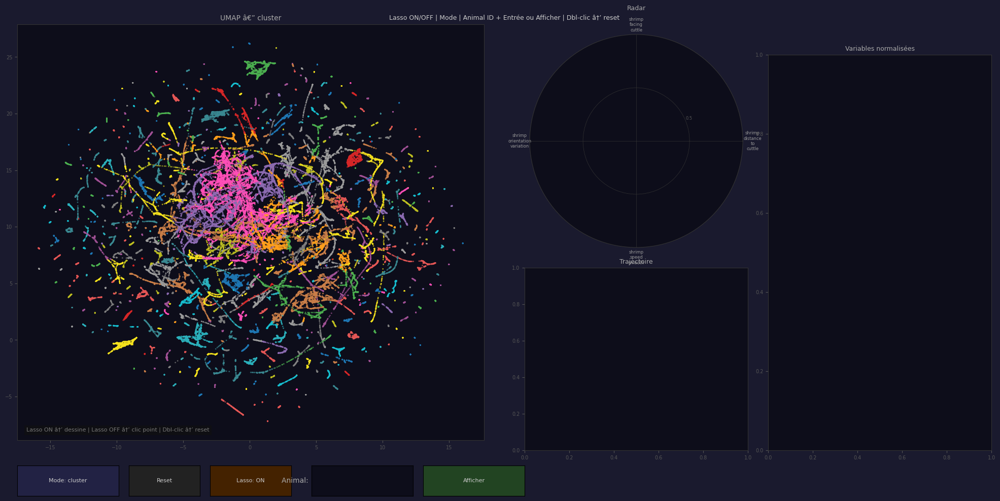

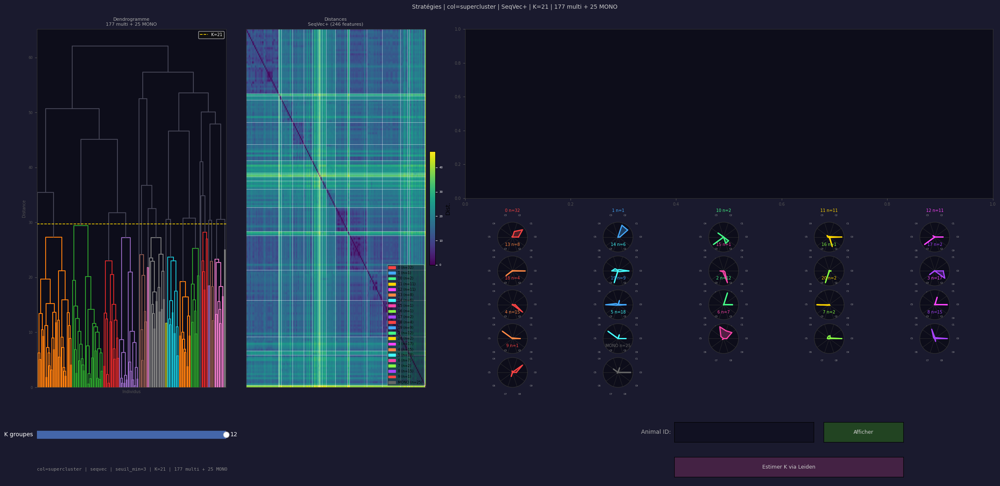

In [18]:
# ── Appel ─────────────────────────────────────────────────────
final_state_shrimp = show_strategy_explorer_shrimp(
    df_shrimp             = df_shrimp,
    cluster_col    = "supercluster",
    n_strategies   = 4,
    seuil_min      = 3,
    use_leiden_k   = True,
    linkage_method = "ward",
    w_hist         = 1.0,
    w_trans        = 1.0,
    w_runlen       = 1.0,
    w_firstapp     = 1.0,
    w_temporal     = 1.0,
    w_context      = 1.0,
    w_global       = 1.0,
)



In [19]:
# CELLULE — show_power_analysis_shrimp + optimal_regroupement_shrimp
#  Calculs sur les features SeqVec (cohérent avec le clustering)
# ══════════════════════════════════════════════════════════════

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy import stats
from scipy.stats import mannwhitneyu
from itertools import combinations
from collections import Counter


def build_seqvec_features_per_individual_shrimp(final_state_shrimp, normalize=False):
    """
    Reconstruit les features SeqVec pour chaque individu.
    Utilisé pour les tests statistiques → normalize=False (valeurs brutes).
    Cohérent avec _seqvec_shrimp utilisé pour le clustering.
    """
    seqs  = final_state_shrimp["seqs"]
    n_cl_shrimp  = final_state_shrimp["n_cl_shrimp"]
    ids   = list(seqs.keys())
    rows  = []

    for aid in ids:
        sq, lg = seqs[aid]["seq"], seqs[aid]["lengths"]
        total  = sum(lg)
        if total == 0: continue

        # Proportions
        hist = np.zeros(n_cl_shrimp)
        for c, l in zip(sq, lg):
            if c < n_cl_shrimp: hist[c] += l / total

        # Transitions
        trans = np.zeros((n_cl_shrimp, n_cl_shrimp))
        for a, b in zip(sq[:-1], sq[1:]):
            if 0 <= a < n_cl_shrimp and 0 <= b < n_cl_shrimp:
                trans[a, b] += 1
        rs   = trans.sum(axis=1, keepdims=True)
        rs[rs == 0] = 1
        trans_norm = (trans / rs).flatten()

        # Durées médianes
        durees = {c: [] for c in range(n_cl_shrimp)}
        for c, l in zip(sq, lg):
            if c < n_cl_shrimp: durees[c].append(l)
        runlen = np.array([np.median(durees[c]) if durees[c] else 0
                           for c in range(n_cl_shrimp)])

        # Première apparition
        firstapp = []
        for c in range(n_cl_shrimp):
            try:    firstapp.append(sq.index(c) / len(sq))
            except: firstapp.append(1.0)
        firstapp = np.array(firstapp)

        # Métriques globales
        n_used   = len(set(sq))
        entropy  = 0.0
        h_vals   = hist[hist > 0]
        if len(h_vals) > 1:
            entropy = -np.sum(h_vals * np.log(h_vals)) / np.log(n_cl_shrimp)

        row = {}
        for c in range(n_cl_shrimp):
            row[f"hist_C{c}"]     = hist[c]
            row[f"runlen_C{c}"]   = runlen[c]
            row[f"firstapp_C{c}"] = firstapp[c]
        for i in range(n_cl_shrimp):
            for j in range(n_cl_shrimp):
                row[f"trans_{i}_{j}"] = trans_norm[i * n_cl_shrimp + j]
        row["entropy"]      = entropy
        row["n_cl_used"]    = n_used / n_cl_shrimp
        row["inertia"]      = hist.max()
        row["total_frames"] = total
        rows.append({"animal_id": str(aid), **row})

    df_seq = pd.DataFrame(rows).set_index("animal_id")
    df_seq = df_seq.fillna(0)

    if normalize:
        from sklearn.preprocessing import StandardScaler
        df_seq = pd.DataFrame(
            StandardScaler().fit_transform(df_seq.values),
            index=df_seq.index, columns=df_seq.columns)

    print(f"[SEQ FEATURES_SHRIMP] {df_seq.shape[0]} individus × "
          f"{df_seq.shape[1]} features (brutes)")
    return df_seq


def _bh_correction(p_values, alpha=0.05):
    """
    Correction Benjamini-Hochberg (FDR).
    Retourne un array booléen : True = significatif après correction.
    """
    p   = np.array(p_values)
    n   = len(p)
    if n == 0: return np.array([], dtype=bool)
    ranked  = np.argsort(p)
    seuils  = (np.arange(1, n+1) / n) * alpha
    passed  = p[ranked] < seuils
    sig     = np.zeros(n, dtype=bool)
    if passed.any():
        last = np.where(passed)[0][-1]
        sig[ranked[:last+1]] = True
    return sig


def show_power_analysis_shrimp(final_state_shrimp, df_shrimp,
                        features         = None,
                        use_raw_features = False,
                        top_pct_features = 1.0,    # 1.0 = garder toutes
                        alpha            = 0.05,
                        power_target     = 0.80):
    """
    Analyse de puissance statistique.

    use_raw_features : True  → Cohen's d sur features comportementales brutes
                               (distance, vitesse...) — plus interprétable
                       False → Cohen's d sur features SeqVec (défaut)

    top_pct_features : proportion des features les plus discriminantes
                       à garder pour le calcul du Cohen's d.
                       1.0 = toutes (défaut)
                       0.2 = top 20% les plus discriminantes
                       → utile pour réduire le bruit des features peu
                         informatives qui tirent la médiane vers le bas
    """
    strat = final_state_shrimp["strat"]
    mono  = final_state_shrimp["mono"]

    # ── Choix des features ────────────────────────────────────
    df_w_shrimp = df_shrimp.copy()
    df_w_shrimp["animal_id"] = df_w_shrimp["animal_id"].astype(str)

    if use_raw_features and features is not None:
        # Features comportementales brutes — moyenne par individu
        # Plus interprétable biologiquement, Cohen's d naturellement
        # plus grand car les features sont dans des échelles réelles
        df_indiv_shrimp  = df_w_shrimp.groupby("animal_id")[features].mean()
        feat_cols = list(features)
        feat_label = f"features brutes ({len(feat_cols)})"
    else:
        # Features SeqVec — 184 features abstraites
        df_indiv_shrimp  = build_seqvec_features_per_individual_shrimp(
                        final_state_shrimp, normalize=False)
        feat_cols = list(df_indiv_shrimp.columns)
        feat_label = f"SeqVec brutes ({len(feat_cols)} features)"

    df_indiv_shrimp["groupe"] = [strat.get(str(aid), "MONO")
                          for aid in df_indiv_shrimp.index]
    df_indiv_shrimp = df_indiv_shrimp.dropna(subset=feat_cols)

    strategy_list = sorted(set(strat.values()))
    all_groups    = strategy_list + (["MONO"] if mono else [])

    # ── Filtre features discriminantes ────────────────────────
    # Garde seulement les top_pct_features% les plus discriminantes
    # Critère : ratio variance inter-groupes / variance totale (η²)
    # → évite que les features non-discriminantes tirent Cohen's d
    #   vers le bas et sous-estiment la puissance
    if top_pct_features < 1.0 and len(feat_cols) > 5:
        scores = []
        grand_mean = df_indiv_shrimp[feat_cols].mean()
        for feat in feat_cols:
            var_total = df_indiv_shrimp[feat].var()
            if var_total < 1e-10:
                scores.append(0); continue
            var_inter = 0
            for g in strategy_list:
                mask = df_indiv_shrimp["groupe"] == g
                if mask.sum() < 2: continue
                ng = mask.sum()
                mg = df_indiv_shrimp.loc[mask, feat].mean()
                var_inter += ng * (mg - grand_mean[feat])**2
            var_inter /= max(len(df_indiv_shrimp) - 1, 1)
            scores.append(var_inter / (var_total + 1e-10))

        threshold = np.percentile(scores, (1 - top_pct_features) * 100)
        feat_cols = [f for f, s in zip(feat_cols, scores)
                     if s >= threshold]
        feat_label += f" → top {int(top_pct_features*100)}%"
        print(f"[FILTER] {len(feat_cols)} features retenues "
              f"(top {int(top_pct_features*100)}% discriminantes)")

    pal         = {s: STRATEGY_PALETTE_SHRIMP[i % len(STRATEGY_PALETTE_SHRIMP)]
                   for i, s in enumerate(all_groups)}
    pal["MONO"] = "#666666"

    # ── N min théoriques ──────────────────────────────────────
    z_alpha = stats.norm.ppf(1 - alpha/2)
    z_beta  = stats.norm.ppf(power_target)

    def n_min_for_d(d):
        if d <= 0: return np.inf
        return int(np.ceil((z_alpha + z_beta)**2 / (2 * d**2)))

    n_min_large  = n_min_for_d(0.8)
    n_min_medium = n_min_for_d(0.5)
    n_min_small  = n_min_for_d(0.2)

    group_sizes = {g: int((df_indiv_shrimp["groupe"] == g).sum())
                   for g in all_groups}

    # ── Calcul paires avec BH ─────────────────────────────────
    pairs        = list(combinations(strategy_list, 2))
    pair_results = []

    for g1, g2 in pairs:
        mask1    = df_indiv_shrimp["groupe"] == g1
        mask2    = df_indiv_shrimp["groupe"] == g2
        n1, n2   = mask1.sum(), mask2.sum()

        if n1 < 2 or n2 < 2:
            pair_results.append({
                "g1": g1, "g2": g2, "n1": n1, "n2": n2,
                "cohens_d": 0, "power_obs": 0,
                "p_value": 1.0, "significant": False,
                "n_min_needed": np.inf,
            }); continue

        ds, ps = [], []
        for feat in feat_cols:
            x1 = df_indiv_shrimp.loc[mask1, feat].dropna().values
            x2 = df_indiv_shrimp.loc[mask2, feat].dropna().values
            if len(x1) < 2 or len(x2) < 2: continue
            ps_std = np.sqrt((x1.std()**2 + x2.std()**2) / 2)
            ds.append(abs(x1.mean() - x2.mean()) / (ps_std + 1e-9))
            try:
                _, p = mannwhitneyu(x1, x2, alternative="two-sided")
                ps.append(p)
            except:
                ps.append(1.0)

        mean_d = float(np.median(ds)) if ds else 0.0
        p_min  = float(np.min(ps))    if ps else 1.0
        n_obs  = min(n1, n2)
        n_need = n_min_for_d(mean_d)

        if n_need > 0 and n_need < np.inf:
            ratio     = n_obs / n_need
            power_obs = float(np.clip(stats.norm.cdf(
                z_beta * np.sqrt(ratio)
                - z_alpha * (1/np.sqrt(ratio) - 1)), 0, 1))
        else:
            power_obs = 0.0

        pair_results.append({
            "g1": g1, "g2": g2, "n1": n1, "n2": n2,
            "cohens_d":    round(mean_d, 3),
            "power_obs":   round(power_obs, 3),
            "p_value":     round(p_min, 4),
            "significant": False,
            "n_min_needed": n_need,
        })

    df_pairs_shrimp = pd.DataFrame(pair_results)

    # Correction BH
    if len(df_pairs_shrimp) > 0:
        sig_bh = _bh_correction(df_pairs_shrimp["p_value"].values, alpha)
        df_pairs_shrimp["significant"] = sig_bh
        print(f"[BH] {sig_bh.sum()}/{len(sig_bh)} paires significatives "
              f"après correction Benjamini-Hochberg")

    # ── Scores ────────────────────────────────────────────────
    n_tot        = len(strategy_list)
    n_ok         = sum(1 for g, n in group_sizes.items()
                       if g != "MONO" and n >= n_min_medium)
    score_size   = n_ok / n_tot if n_tot > 0 else 0
    score_power  = df_pairs_shrimp["power_obs"].mean()   if len(df_pairs_shrimp) > 0 else 0
    score_sig    = df_pairs_shrimp["significant"].mean() if len(df_pairs_shrimp) > 0 else 0
    score_global = score_power * 0.5 + score_sig * 0.3 + score_size * 0.2

    pair_labels  = [f"{r.g1} ↔ {r.g2}" for r in df_pairs_shrimp.itertuples()]

    # ════════════════════════════════════════════════════════
    # FIGURE 1 — Tailles des groupes
    # ════════════════════════════════════════════════════════
    groups_plot = [g for g in all_groups if g != "MONO"]
    sizes_plot  = [group_sizes[g] for g in groups_plot]

    fig1, ax = plt.subplots(figsize=(max(8, len(groups_plot)*0.6), 5))
    fig1.patch.set_facecolor("#1a1a2e"); ax.set_facecolor("#0d0d1a")
    bars = ax.bar(groups_plot, sizes_plot,
                  color=[pal[g] for g in groups_plot],
                  edgecolor="#222", linewidth=0.8, alpha=0.9)
    for bar, n in zip(bars, sizes_plot):
        ax.text(bar.get_x()+bar.get_width()/2, n+0.05, str(n),
                ha="center", va="bottom", color="white",
                fontsize=9, fontweight="bold")
    ymax = max(sizes_plot + [n_min_small]) * 1.25
    ax.axhline(n_min_large,  color="#44ff44", lw=1.5, ls="--",
               label=f"Grand effet d=0.8 → n≥{n_min_large}")
    ax.axhline(n_min_medium, color="#ffaa00", lw=1.5, ls="--",
               label=f"Effet moyen d=0.5 → n≥{n_min_medium}")
    ax.axhline(n_min_small,  color="#ff4444", lw=1.5, ls="--",
               label=f"Petit effet d=0.2 → n≥{n_min_small}")
    ax.axhspan(0,            n_min_large,  alpha=0.07, color="#ff4444")
    ax.axhspan(n_min_large,  n_min_medium, alpha=0.07, color="#ffaa00")
    ax.axhspan(n_min_medium, ymax,         alpha=0.04, color="#44ff44")
    ax.set_ylim(0, ymax)
    ax.set_title(f"Taille des groupes vs N minimal requis\n"
                 f"(α={alpha}, puissance cible={int(power_target*100)}%)",
                 color="#cccccc", fontsize=11)
    ax.set_ylabel("N individus", color="#aaaaaa")
    ax.tick_params(colors="#aaaaaa", axis="x", rotation=45)
    ax.tick_params(colors="#aaaaaa", axis="y")
    for sp in ax.spines.values(): sp.set_edgecolor("#333333")
    leg = ax.legend(fontsize=8, loc="upper right")
    leg.get_frame().set_facecolor("#111111")
    for t in leg.get_texts(): t.set_color("white")
    plt.tight_layout(); plt.show()

    # ════════════════════════════════════════════════════════
    # FIGURE 2 — Cohen's d
    # ════════════════════════════════════════════════════════
    if len(df_pairs_shrimp) > 0:
        ds_vals  = df_pairs_shrimp["cohens_d"].values
        d_colors = ["#44ff44" if d >= 0.8
                    else "#ffaa00" if d >= 0.5
                    else "#ff4444" for d in ds_vals]

        fig2, ax = plt.subplots(figsize=(8, max(4, len(pair_labels)*0.35)))
        fig2.patch.set_facecolor("#1a1a2e"); ax.set_facecolor("#0d0d1a")
        ax.barh(range(len(pair_labels)), ds_vals, color=d_colors,
                edgecolor="#222", linewidth=0.5, alpha=0.9)
        for i, d in enumerate(ds_vals):
            ax.text(d+0.01, i, f"{d:.2f}", va="center",
                    color="white", fontsize=7)
        ax.axvline(0.8, color="#44ff44", lw=1.5, ls="--",
                   label="Grand effet (0.8)")
        ax.axvline(0.5, color="#ffaa00", lw=1.5, ls="--",
                   label="Effet moyen (0.5)")
        ax.axvline(0.2, color="#ff4444", lw=1.5, ls="--",
                   label="Petit effet (0.2)")
        ax.set_yticks(range(len(pair_labels)))
        ax.set_yticklabels(pair_labels, fontsize=8, color="#cccccc")
        ax.set_xlabel(f"Cohen's d médian ({feat_label})",
                      color="#aaaaaa")
        ax.set_title("Taille d'effet entre chaque paire de groupes",
                     color="#cccccc", fontsize=11)
        ax.tick_params(colors="#aaaaaa")
        for sp in ax.spines.values(): sp.set_edgecolor("#333333")
        leg = ax.legend(fontsize=8, loc="lower right")
        leg.get_frame().set_facecolor("#111111")
        for t in leg.get_texts(): t.set_color("white")
        plt.tight_layout(); plt.show()

    # ════════════════════════════════════════════════════════
    # FIGURE 3 — Puissance
    # ════════════════════════════════════════════════════════
    if len(df_pairs_shrimp) > 0:
        powers   = df_pairs_shrimp["power_obs"].values
        p_colors = ["#44ff44" if p >= power_target
                    else "#ffaa00" if p >= 0.5
                    else "#ff4444" for p in powers]

        fig3, ax = plt.subplots(figsize=(8, max(4, len(pair_labels)*0.35)))
        fig3.patch.set_facecolor("#1a1a2e"); ax.set_facecolor("#0d0d1a")
        ax.barh(range(len(pair_labels)), powers, color=p_colors,
                edgecolor="#222", linewidth=0.5, alpha=0.9)
        for i, p in enumerate(powers):
            ax.text(p+0.01, i, f"{p:.0%}", va="center",
                    color="white", fontsize=7)
        ax.axvline(power_target, color="#FFD700", lw=2, ls="--",
                   label=f"Cible {int(power_target*100)}%")
        ax.axvline(0.5, color="#888888", lw=1, ls=":",
                   label="Seuil 50%")
        ax.set_xlim(0, 1.1)
        ax.set_yticks(range(len(pair_labels)))
        ax.set_yticklabels(pair_labels, fontsize=8, color="#cccccc")
        ax.set_xlabel("Puissance statistique estimée", color="#aaaaaa")
        ax.set_title(f"Puissance par paire — correction BH\n"
                     f"(vert ≥ {int(power_target*100)}%, orange ≥ 50%, rouge < 50%)",
                     color="#cccccc", fontsize=11)
        ax.tick_params(colors="#aaaaaa")
        for sp in ax.spines.values(): sp.set_edgecolor("#333333")
        leg = ax.legend(fontsize=8)
        leg.get_frame().set_facecolor("#111111")
        for t in leg.get_texts(): t.set_color("white")
        plt.tight_layout(); plt.show()

    # ════════════════════════════════════════════════════════
    # FIGURE 4 — Tableau
    # ════════════════════════════════════════════════════════
    if len(df_pairs_shrimp) > 0:
        headers    = ["G1","G2","n1","n2","Cohen d",
                      "Puissance","p-val (BH)","Sig ?","N manquant"]
        table_data = []
        for r in df_pairs_shrimp.itertuples():
            n_need   = r.n_min_needed
            n_manque = (max(0, n_need - min(r.n1, r.n2))
                        if n_need < np.inf else "∞")
            table_data.append([
                r.g1, r.g2, str(r.n1), str(r.n2),
                f"{r.cohens_d:.2f}",
                f"{r.power_obs:.0%}",
                f"{r.p_value:.4f}",
                "✓" if r.significant else "✗",
                str(int(n_manque)) if isinstance(n_manque, (int,float))
                else n_manque,
            ])

        fig4, ax = plt.subplots(
            figsize=(14, max(3, len(table_data)*0.4+1)))
        fig4.patch.set_facecolor("#1a1a2e")
        ax.set_facecolor("#0d0d1a"); ax.axis("off")
        tbl = ax.table(cellText=table_data, colLabels=headers,
                       loc="center", cellLoc="center")
        tbl.auto_set_font_size(False); tbl.set_fontsize(9); tbl.scale(1, 1.6)
        for (row, col), cell in tbl.get_celld().items():
            cell.set_edgecolor("#333333")
            if row == 0:
                cell.set_facecolor("#1a1a3e")
                cell.set_text_props(color="white", fontweight="bold")
            else:
                cell.set_facecolor("#0d0d1a")
                cell.set_text_props(color="#cccccc")
                if col == 5:
                    try:
                        p = float(table_data[row-1][5].strip("%"))/100
                        cell.set_facecolor(
                            "#1a3a1a" if p >= power_target
                            else "#3a2a00" if p >= 0.5 else "#3a0000")
                    except: pass
                if col == 7:
                    cell.set_facecolor(
                        "#1a3a1a" if table_data[row-1][7]=="✓"
                        else "#3a0000")
                if col == 8:
                    try:
                        nm = int(table_data[row-1][8])
                        cell.set_facecolor(
                            "#1a3a1a" if nm == 0
                            else "#3a2a00" if nm <= 5 else "#3a0000")
                    except: pass
        ax.set_title(
            "Tableau récapitulatif — correction Benjamini-Hochberg\n"
            "'N manquant' = individus supplémentaires pour la puissance cible",
            color="#cccccc", fontsize=11, pad=15)
        plt.tight_layout(); plt.show()

    # ════════════════════════════════════════════════════════
    # FIGURE 5 — Score global
    # ════════════════════════════════════════════════════════
    fig5, ax = plt.subplots(figsize=(7, 5))
    fig5.patch.set_facecolor("#1a1a2e")
    ax.set_facecolor("#0d0d1a"); ax.axis("off")
    for sp in ax.spines.values(): sp.set_edgecolor("#333333")

    score_color = ("#44ff44" if score_global >= 0.7
                   else "#ffaa00" if score_global >= 0.4 else "#ff4444")
    verdict = ("✅ Découpage statistiquement solide"        if score_global >= 0.7
               else "🟡 Découpage acceptable, à consolider" if score_global >= 0.4
               else "🔴 Puissance insuffisante — envisager de regrouper")

    ax.text(0.5, 0.92, f"Score global : {score_global:.0%}",
            ha="center", va="center", fontsize=24,
            color=score_color, fontweight="bold",
            transform=ax.transAxes)
    ax.text(0.5, 0.78, verdict, ha="center", va="center",
            fontsize=12, color=score_color, transform=ax.transAxes)

    for i, (label, val, col) in enumerate([
        ("Puissance moyenne entre paires (×0.5)",
         f"{score_power:.0%}",
         "#44ff44" if score_power >= 0.7 else "#ffaa00"
         if score_power >= 0.4 else "#ff4444"),
        ("Proportion paires significatives BH (×0.3)",
         f"{score_sig:.0%}",
         "#44ff44" if score_sig >= 0.7 else "#ffaa00"
         if score_sig >= 0.4 else "#ff4444"),
        ("Proportion groupes taille OK (×0.2)",
         f"{score_size:.0%}",
         "#44ff44" if score_size >= 0.7 else "#ffaa00"
         if score_size >= 0.4 else "#ff4444"),
    ]):
        y = 0.60 - i * 0.12
        ax.text(0.05, y, f"• {label}", ha="left", va="center",
                fontsize=9, color="#aaaaaa", transform=ax.transAxes)
        ax.text(0.95, y, val, ha="right", va="center",
                fontsize=11, color=col, fontweight="bold",
                transform=ax.transAxes)

    for i, line in enumerate([
        f"N min grand effet (d=0.8) : {n_min_large} individus/groupe",
        f"N min effet moyen (d=0.5) : {n_min_medium} individus/groupe",
        f"N min petit effet (d=0.2) : {n_min_small} individus/groupe",
        f"Correction : Benjamini-Hochberg  |  α={alpha}",
        f"Features : {feat_label}",
    ]):
        ax.text(0.5, 0.22 - i*0.07, line, ha="center", va="center",
                fontsize=8, color="#666666", transform=ax.transAxes,
                fontfamily="monospace")

    ax.set_title(f"Résumé — {n_tot} groupes | α={alpha} | "
                 f"puissance cible={int(power_target*100)}%",
                 color="#cccccc", fontsize=11)
    plt.tight_layout(); plt.show()

    print(f"\n{'='*55}")
    print(f"PUISSANCE — {n_tot} groupes | α={alpha} | "
          f"cible={int(power_target*100)}%")
    print(f"  Features  : {feat_label}")
    print(f"  Correction: Benjamini-Hochberg (FDR)")
    print(f"  N min (d=0.8): {n_min_large} | (d=0.5): {n_min_medium} "
          f"| (d=0.2): {n_min_small}")
    print(f"  Tailles   : { {g: n for g, n in group_sizes.items()} }")
    print(f"  Score     : {score_global:.0%}  ({verdict})")

    return df_pairs_shrimp




# ══════════════════════════════════════════════════════════════

def optimal_regroupement_shrimp(
    final_state_shrimp,
    df_shrimp,
    alpha         = 0.05,
    power_target  = 0.80,
    target_effect = 0.5,
    min_groups    = 2,
    d_max_fusion  = 0.8,
    verbose       = True,
):
    """
    Fusionne itérativement les groupes en utilisant la matrice D
    de SeqVec — cohérent avec le clustering initial.

    d_max_fusion : Cohen's d maximum pour autoriser une fusion forcée.
                   Si la paire la plus proche a d > d_max_fusion,
                   on arrête même si certains groupes sont trop petits.
                   Évite de fusionner des groupes très différents.
    """
    seqs = final_state_shrimp["seqs"]
    D    = final_state_shrimp["D"]
    ids  = final_state_shrimp["multi"]   # liste dans le même ordre que D

    # N minimal pour l'effet cible
    z_alpha = stats.norm.ppf(1 - alpha/2)
    z_beta  = stats.norm.ppf(power_target)
    n_min   = int(np.ceil((z_alpha + z_beta)**2 / (2 * target_effect**2)))

    # Mapping courant
    mapping = {str(aid): g for aid, g in final_state_shrimp["strat"].items()}
    for m in final_state_shrimp["mono"]:
        mapping[str(m)] = "MONO"

    # Index des individus dans la matrice D
    id_to_idx_shrimp = {str(aid): i for i, aid in enumerate(ids)}

    history_shrimp = []

    def get_sizes(mapping):
        return dict(Counter(v for v in mapping.values() if v != "MONO"))

    def get_distance_D(g1, g2):
        """
        Distance moyenne dans l'espace SeqVec entre les deux groupes.
        Utilise la matrice D déjà calculée → cohérent avec le clustering.
        """
        idx1 = [id_to_idx_shrimp[aid] for aid in mapping
                if mapping[aid] == g1 and aid in id_to_idx_shrimp]
        idx2 = [id_to_idx_shrimp[aid] for aid in mapping
                if mapping[aid] == g2 and aid in id_to_idx_shrimp]
        if not idx1 or not idx2: return np.inf
        sub = D[np.ix_(idx1, idx2)]
        return float(sub.mean())

    def all_ok(mapping, n_min, min_groups):
        sizes = get_sizes(mapping)
        if len(sizes) <= min_groups: return True
        return all(n >= n_min for n in sizes.values())

    if verbose:
        sizes_init = get_sizes(mapping)
        print(f"\n{'='*60}")
        print(f"REGROUPEMENT OPTIMAL")
        print(f"  features     : SeqVec (matrice D du clustering)")
        print(f"  n_min (d={target_effect}, puissance={int(power_target*100)}%) = {n_min}")
        print(f"  d_max_fusion : {d_max_fusion}")
        print(f"  Groupes initiaux : {sizes_init}")
        print(f"{'='*60}")

        # Afficher aussi les target_effect recommandés
        if len(final_state_shrimp.get("D", [])) > 0:
            df_pairs_preview = []
            non_mono = sorted(set(v for v in mapping.values() if v != "MONO"))
            for g1, g2 in combinations(non_mono, 2):
                d = get_distance_D(g1, g2)
                df_pairs_preview.append(d)
            if df_pairs_preview:
                print(f"  target_effect_auto_shrimp   : "
                      f"{np.mean(df_pairs_preview):.3f}")
                print(f"  target_effect_median : "
                      f"{np.median(df_pairs_preview):.3f}")
                print(f"  target_effect_p25    : "
                      f"{np.percentile(df_pairs_preview, 25):.3f}")

    iteration = 0
    while not all_ok(mapping, n_min, min_groups):
        sizes    = get_sizes(mapping)
        non_mono = sorted(sizes.keys())

        if len(non_mono) <= min_groups:
            if verbose: print(f"[STOP] Nb minimal de groupes atteint")
            break

        small_groups = {g for g in non_mono if sizes[g] < n_min}
        best_pair, best_score, best_d = None, np.inf, np.inf

        for g1, g2 in combinations(non_mono, 2):
            d            = get_distance_D(g1, g2)
            involves_sm  = g1 in small_groups or g2 in small_groups
            score        = d if involves_sm else d + 100
            if score < best_score:
                best_score = score
                best_pair  = (g1, g2)
                best_d     = d

        if best_pair is None: break

        # Vérifier si la fusion est raisonnable
        if best_d > d_max_fusion and not (best_pair[0] in small_groups
                                           or best_pair[1] in small_groups):
            if verbose:
                print(f"[STOP] Fusion suivante trop différente "
                      f"(d={best_d:.3f} > {d_max_fusion})")
            break

        g1, g2    = best_pair
        reason    = ("taille insuffisante" if g1 in small_groups
                     or g2 in small_groups else "groupes les plus similaires")
        # Nouveau label = label le plus petit (alphabétique)
        # évite de toujours absorber dans le grand groupe
        new_label = min(g1, g2)
        mapping   = {aid: (new_label if g in (g1, g2) else g)
                     for aid, g in mapping.items()}
        iteration += 1

        record = {
            "iteration": iteration, "g1": g1, "g2": g2,
            "new_label": new_label, "distance_D": round(best_d, 3),
            "n_g1": sizes[g1], "n_g2": sizes[g2],
            "n_merged": sizes[g1] + sizes[g2], "reason": reason,
        }
        history_shrimp.append(record)

        if verbose:
            new_sizes = get_sizes(mapping)
            print(f"  [{iteration}] {g1}(n={sizes[g1]}) + "
                  f"{g2}(n={sizes[g2]}) → {new_label}"
                  f"(n={sizes[g1]+sizes[g2]})  "
                  f"d={best_d:.3f}  [{reason}]")
            print(f"       Restants : {new_sizes}")

    if verbose:
        final_sizes = get_sizes(mapping)
        n_ok = sum(1 for n in final_sizes.values() if n >= n_min)
        print(f"\n[RÉSULTAT] {len(final_sizes)} groupes | "
              f"{n_ok}/{len(final_sizes)} atteignent n≥{n_min}")
        print(f"  Tailles finales : {final_sizes}")

    # ════════════════════════════════════════════════════════
    # FIGURE 1 — Avant / Après
    # ════════════════════════════════════════════════════════
    sizes_avant = get_sizes({str(aid): g
                              for aid, g in final_state_shrimp["strat"].items()})
    sizes_apres = get_sizes(mapping)

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    fig.patch.set_facecolor("#1a1a2e")

    for ax, (sizes, title) in zip(axes, [
        (sizes_avant, f"Avant  ({len(sizes_avant)} groupes)"),
        (sizes_apres, f"Après  ({len(sizes_apres)} groupes)"),
    ]):
        ax.set_facecolor("#0d0d1a")
        for sp in ax.spines.values(): sp.set_edgecolor("#333333")
        ax.tick_params(colors="#aaaaaa")
        groups = sorted(sizes.keys())
        vals   = [sizes[g] for g in groups]
        colors = [STRATEGY_PALETTE_SHRIMP[i % len(STRATEGY_PALETTE_SHRIMP)]
                  for i in range(len(groups))]
        bars = ax.bar(groups, vals, color=colors,
                      edgecolor="#222", linewidth=0.8, alpha=0.9)
        for bar, n in zip(bars, vals):
            ax.text(bar.get_x()+bar.get_width()/2, n+0.05, str(n),
                    ha="center", va="bottom", color="white",
                    fontsize=9, fontweight="bold")
        ax.axhline(n_min, color="#FFD700", lw=2, ls="--",
                   label=f"n_min={n_min} (d={target_effect})")
        ax.axhspan(0, n_min, alpha=0.06, color="#ff4444")
        ax.axhspan(n_min, max(vals+[n_min])*1.3, alpha=0.04, color="#44ff44")
        ax.set_ylim(0, max(vals+[n_min])*1.3)
        ax.set_title(title, color="#cccccc", fontsize=11)
        ax.set_ylabel("N individus", color="#aaaaaa")
        ax.tick_params(axis="x", rotation=45)
        leg = ax.legend(fontsize=8)
        leg.get_frame().set_facecolor("#111111")
        for t in leg.get_texts(): t.set_color("white")

    fig.suptitle(
        f"Regroupement optimal | n_min={n_min} | "
        f"{len(history_shrimp)} fusions | distance SeqVec",
        color="#cccccc", fontsize=12)
    plt.tight_layout(); plt.show()

    # ════════════════════════════════════════════════════════
    # FIGURE 2 — Log des fusions
    # ════════════════════════════════════════════════════════
    if history_shrimp:
        df_hist = pd.DataFrame(history_shrimp)
        fig2, axes2 = plt.subplots(1, 2,
                                    figsize=(14, max(3, len(history_shrimp)*0.5+1)))
        fig2.patch.set_facecolor("#1a1a2e")

        labels_fus = [f"{r.g1}+{r.g2}→{r.new_label}"
                      for r in df_hist.itertuples()]

        # Distance SeqVec des fusions
        ax = axes2[0]
        ax.set_facecolor("#0d0d1a")
        for sp in ax.spines.values(): sp.set_edgecolor("#333333")
        d_colors = ["#44ff44" if d < 2 else "#ffaa00" if d < 5 else "#ff4444"
                    for d in df_hist["distance_D"]]
        ax.barh(range(len(labels_fus)), df_hist["distance_D"],
                color=d_colors, edgecolor="#222", alpha=0.9)
        for i, (d, r) in enumerate(zip(df_hist["distance_D"],
                                        df_hist.itertuples())):
            ax.text(d+0.05, i, f"d={d:.2f}  [{r.reason}]",
                    va="center", color="#cccccc", fontsize=8)
        ax.set_yticks(range(len(labels_fus)))
        ax.set_yticklabels(labels_fus, fontsize=8, color="#cccccc")
        ax.set_xlabel("Distance SeqVec moyenne entre les groupes",
                      color="#aaaaaa")
        ax.set_title("Ordre et raison des fusions\n"
                     "(vert=très proches, rouge=forcé par taille)",
                     color="#cccccc", fontsize=10)
        ax.tick_params(colors="#aaaaaa")

        # Tailles fusionnées
        ax2 = axes2[1]
        ax2.set_facecolor("#0d0d1a")
        for sp in ax2.spines.values(): sp.set_edgecolor("#333333")
        ax2.barh(range(len(df_hist)), df_hist["n_g1"],
                 color="#4466aa", alpha=0.8, label="n(G1)", edgecolor="#222")
        ax2.barh(range(len(df_hist)), df_hist["n_g2"],
                 left=df_hist["n_g1"],
                 color="#aa6644", alpha=0.8, label="n(G2)", edgecolor="#222")
        ax2.axvline(n_min, color="#FFD700", lw=2, ls="--",
                    label=f"n_min={n_min}")
        ax2.set_yticks(range(len(labels_fus)))
        ax2.set_yticklabels(labels_fus, fontsize=8, color="#cccccc")
        ax2.set_xlabel("Taille des groupes fusionnés", color="#aaaaaa")
        ax2.set_title("Taille des groupes avant fusion",
                      color="#cccccc", fontsize=10)
        ax2.tick_params(colors="#aaaaaa")
        leg2 = ax2.legend(fontsize=8)
        leg2.get_frame().set_facecolor("#111111")
        for t in leg2.get_texts(): t.set_color("white")

        fig2.suptitle("Détail des fusions", color="#cccccc", fontsize=11)
        plt.tight_layout(); plt.show()

    non_mono_groups = sorted(set(v for v in mapping.values() if v != "MONO"))
    num_to_letter   = {g: chr(65+i) for i, g in enumerate(non_mono_groups)}

    mapping_letters_shrimp = {
        aid: (num_to_letter[g] if g != "MONO" else "MONO")
        for aid, g in mapping.items()
    }

    print(f"\n[LETTRES] {len(non_mono_groups)} groupes → "
          f"{list(num_to_letter.values())}")

    return mapping_letters_shrimp, history_shrimp 


[BH] 86/210 paires significatives après correction Benjamini-Hochberg


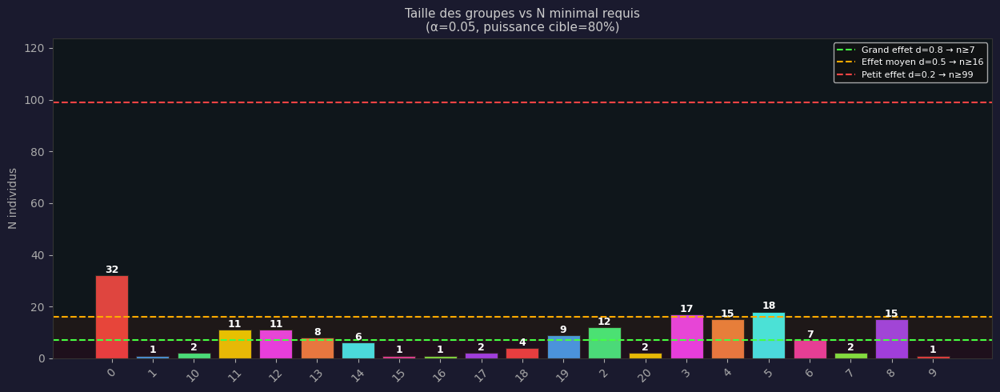

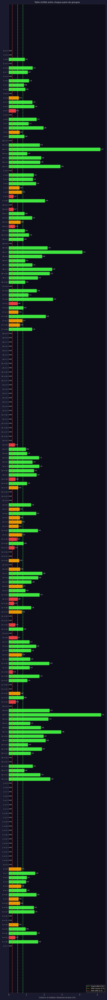

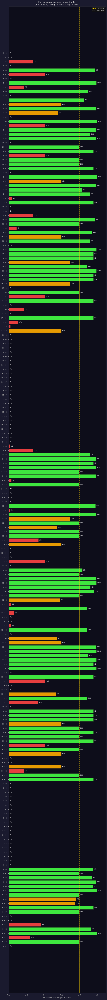

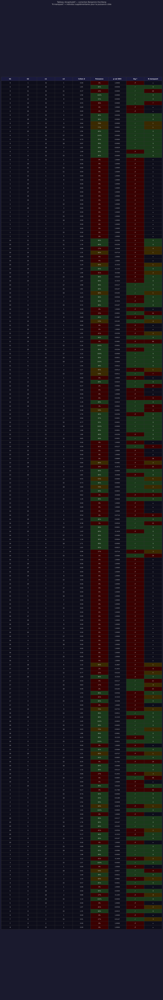

C:\Users\nonoh\AppData\Local\Temp\ipykernel_48580\2256684156.py:503: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
c:\Users\nonoh\anaconda3\envs\cuttlestrike\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


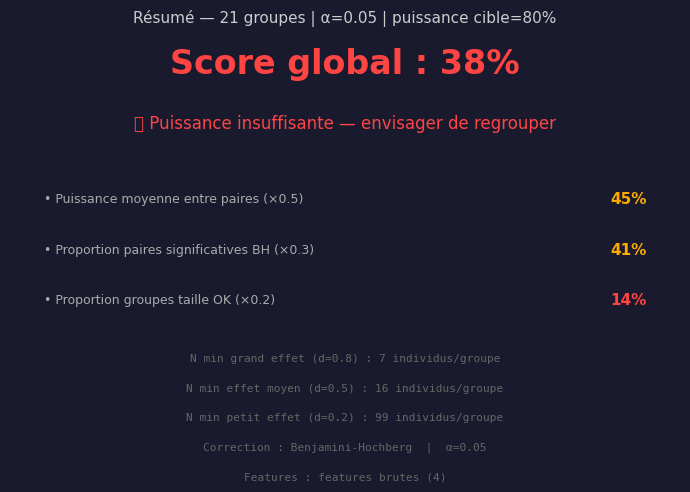


PUISSANCE — 21 groupes | α=0.05 | cible=80%
  Features  : features brutes (4)
  Correction: Benjamini-Hochberg (FDR)
  N min (d=0.8): 7 | (d=0.5): 16 | (d=0.2): 99
  Tailles   : {'0': 32, '1': 1, '10': 2, '11': 11, '12': 11, '13': 8, '14': 6, '15': 1, '16': 1, '17': 2, '18': 4, '19': 9, '2': 12, '20': 2, '3': 17, '4': 15, '5': 18, '6': 7, '7': 2, '8': 15, '9': 1, 'MONO': 25}
  Score     : 38%  (🔴 Puissance insuffisante — envisager de regrouper)


In [20]:
# ── Appels ────────────────────────────────────────────────────
# ── Appels ────────────────────────────────────────────────────

# Option A — features brutes (recommandé pour la puissance)
df_pairs_shrimp = show_power_analysis_shrimp(
    final_state_shrimp, df_shrimp,
    features         = FEATURES_SHRIMP,
    use_raw_features = True,
    top_pct_features = 1.0,
    alpha            = 0.05,
    power_target     = 0.80,
)



REGROUPEMENT OPTIMAL
  features     : SeqVec (matrice D du clustering)
  n_min (d=0.75, puissance=95%) = 12
  d_max_fusion : 0.8
  Groupes initiaux : {'3': 17, '12': 11, '11': 11, '17': 2, '8': 15, '0': 32, '14': 6, '16': 1, '19': 9, '4': 15, '5': 18, '13': 8, '2': 12, '6': 7, '7': 2, '10': 2, '18': 4, '9': 1, '20': 2, '1': 1, '15': 1}
  target_effect_auto_shrimp   : 26.486
  target_effect_median : 24.990
  target_effect_p25    : 20.976
  [1] 12(n=11) + 3(n=17) → 12(n=28)  d=14.604  [taille insuffisante]
       Restants : {'12': 28, '11': 11, '17': 2, '8': 15, '0': 32, '14': 6, '16': 1, '19': 9, '4': 15, '5': 18, '13': 8, '2': 12, '6': 7, '7': 2, '10': 2, '18': 4, '9': 1, '20': 2, '1': 1, '15': 1}
  [2] 12(n=28) + 13(n=8) → 12(n=36)  d=16.386  [taille insuffisante]
       Restants : {'12': 36, '11': 11, '17': 2, '8': 15, '0': 32, '14': 6, '16': 1, '19': 9, '4': 15, '5': 18, '2': 12, '6': 7, '7': 2, '10': 2, '18': 4, '9': 1, '20': 2, '1': 1, '15': 1}
  [3] 11(n=11) + 4(n=15) → 11(n=26)

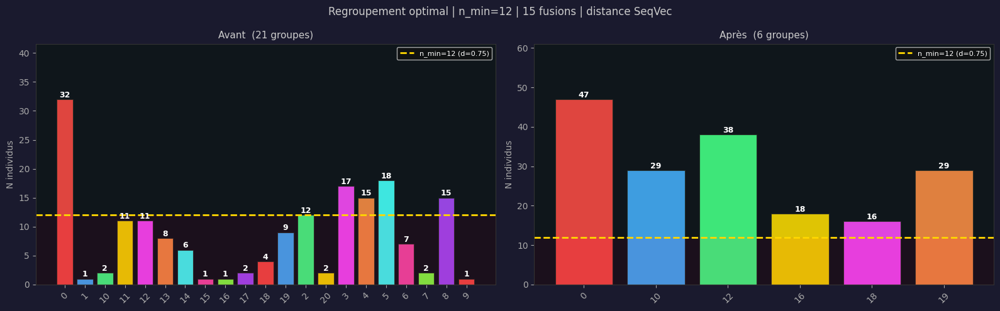

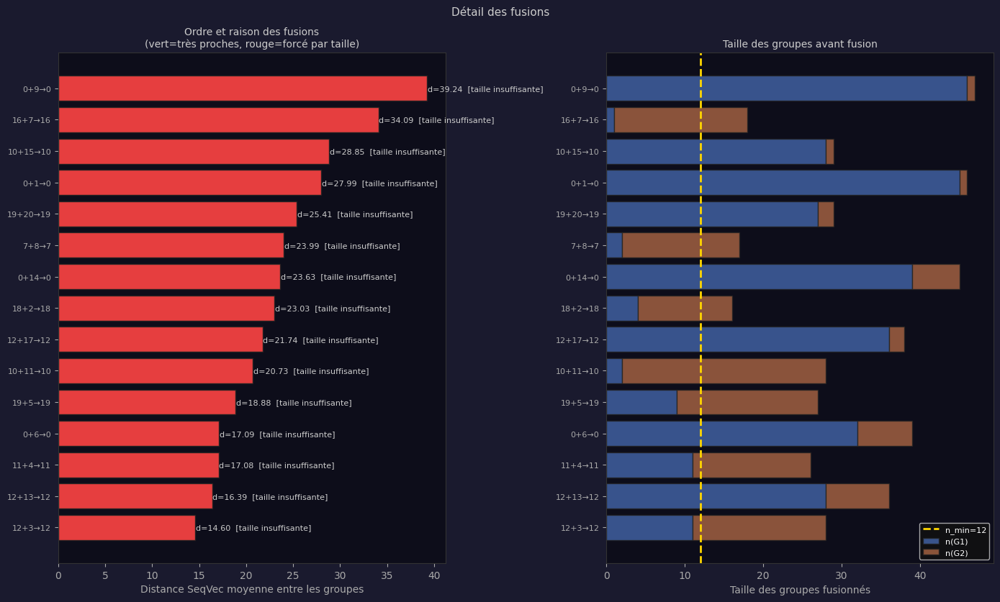


[LETTRES] 6 groupes → ['A', 'B', 'C', 'D', 'E', 'F']


In [21]:
# Selon ce que tu veux détecter :
#target_effect = 0.8   # grand effet  → n_min ≈ 26  → peu de fusions
#target_effect = 0.5   # effet moyen  → n_min ≈ 64  → fusions modérées
#target_effect = 0.2   # petit effet  → n_min ≈ 394 → beaucoup de fusions

# Pour tes données (200 individus, ~20 groupes initiaux)
# → 0.5 est raisonnable comme point de départ
mapping_optimal_shrimp, history_shrimp = optimal_regroupement_shrimp(
    final_state_shrimp,
    df_shrimp,
    alpha         = 0.05,
    power_target  = 0.95,
    target_effect = 0.75,   # ← fixe
    min_groups    = 2,
    d_max_fusion  = 0.8,
    verbose       = True,
)

In [22]:
#def plot_strategy_profiles_shrimp

from scipy.spatial.distance import cdist
import matplotlib.colors as mcolors


def plot_strategy_profiles_shrimp(mapping_optimal_shrimp, final_state_shrimp, df_shrimp, features=FEATURES_SHRIMP,
                           cmap_cl=None, norm_cl_shrimp=None):

    # Valeurs par défaut si non fournies
    n_cl_local = final_state_shrimp["n_cl_shrimp"]
    if cmap_cl is None:
        cmap_cl = CMAP_CLUSTER_SHRIMP
    if norm_cl_shrimp is None:
        norm_cl_shrimp = NORM_CLUSTER_SHRIMP

    seqs = final_state_shrimp["seqs"]
    n_cl_shrimp = final_state_shrimp["n_cl_shrimp"]

    df_w_shrimp = df_shrimp.copy()
    df_w_shrimp["animal_id"] = df_w_shrimp["animal_id"].astype(str)

    unique_groups = sorted(set(v for v in mapping_optimal_shrimp.values() if v != "MONO"))
    num_to_letter = {g: chr(65+i) for i, g in enumerate(unique_groups)}
    num_to_letter["MONO"] = "MONO"
    mapping_letters_shrimp  = {aid: num_to_letter[g] for aid, g in mapping_optimal_shrimp.items()}
    strategy_letters_shrimp = sorted(set(v for v in mapping_letters_shrimp.values() if v != "MONO"))
    n_strat          = len(strategy_letters_shrimp)

    pal         = {s: STRATEGY_PALETTE_SHRIMP[i % len(STRATEGY_PALETTE_SHRIMP)]
                   for i, s in enumerate(strategy_letters_shrimp)}
    pal["MONO"] = "#666666"

    # ── DTW pour médoïde ──────────────────────────────────────
    def _dtw(seq_a, seq_b, n_cl_shrimp):
        if not seq_a or not seq_b: return np.inf
        centers = np.eye(n_cl_shrimp)
        tA = np.array([centers[min(c, n_cl_shrimp-1)] for c in seq_a])
        tB = np.array([centers[min(c, n_cl_shrimp-1)] for c in seq_b])
        TA, TB = len(tA), len(tB)
        cost   = cdist(tA, tB, metric='euclidean')
        D      = np.full((TA, TB), np.inf)
        D[0,0] = cost[0,0]
        for i in range(1, TA): D[i,0] = D[i-1,0] + cost[i,0]
        for j in range(1, TB): D[0,j] = D[0,j-1] + cost[0,j]
        for i in range(1, TA):
            for j in range(1, TB):
                D[i,j] = cost[i,j] + min(D[i-1,j], D[i,j-1], D[i-1,j-1])
        return D[TA-1, TB-1]

    def _medoid(members):
        n = len(members)
        if n == 1: return members[0], seqs[members[0]]["seq"]
        dists = np.zeros(n)
        for i in range(n):
            for j in range(n):
                if i != j:
                    dists[i] += _dtw(seqs[members[i]]["seq"],
                                     seqs[members[j]]["seq"], n_cl_shrimp)
        best = int(np.argmin(dists))
        return members[best], seqs[members[best]]["seq"]

    angles   = np.linspace(0, 2*np.pi, n_cl_shrimp, endpoint=False)
    ang_full = np.concatenate([angles, [angles[0]]])

    profiles_shrimp = {}
    for s in strategy_letters_shrimp:
        members         = [aid for aid, g in mapping_letters_shrimp.items() if g == s]
        members_in_seqs = [m for m in members if m in seqs]
        if not members_in_seqs: continue

        hists = []
        for aid in members_in_seqs:
            sq, lg = seqs[aid]["seq"], seqs[aid]["lengths"]
            total  = sum(lg)
            if total == 0: continue
            h = np.zeros(n_cl_shrimp)
            for c, l in zip(sq, lg):
                if c < n_cl_shrimp: h[c] += l / total
            hists.append(h)
        mean_hist = np.mean(hists, axis=0) if hists else np.zeros(n_cl_shrimp)

        print(f"  [MÉDOÏDE] Stratégie {s} ({len(members_in_seqs)} ind)...", end=" ")
        medoid_aid, modal_compressed = _medoid(members_in_seqs)
        print(f"-> ID {medoid_aid}")

        durees = {c: [] for c in range(n_cl_shrimp)}
        for aid in members_in_seqs:
            for c, l in zip(seqs[aid]["seq"], seqs[aid]["lengths"]):
                if c < n_cl_shrimp: durees[c].append(l)
        median_durees = {c: np.median(durees[c]) if durees[c] else 0
                         for c in range(n_cl_shrimp)}

        trans_count = {}
        for aid in members_in_seqs:
            sq = seqs[aid]["seq"]
            for a, b in zip(sq[:-1], sq[1:]):
                trans_count[(a,b)] = trans_count.get((a,b), 0) + 1
        top_trans = sorted(trans_count.items(), key=lambda x: -x[1])[:3]

        feat_means = {}
        if features:
            ids_str = [str(m) for m in members_in_seqs]
            mask    = df_w_shrimp["animal_id"].isin(ids_str)
            if mask.any():
                feat_means = df_w_shrimp[mask][features].mean().to_dict()

        profiles_shrimp[s] = {
            "members"         : members_in_seqs,
            "all_members"     : members,
            "n"               : len(members_in_seqs),
            "mean_hist"       : mean_hist,
            "modal_seq"       : modal_compressed,
            "medoid_aid"      : medoid_aid,
            "median_durees"   : median_durees,
            "top_transitions" : top_trans,
            "dominant_cluster": int(np.argmax(mean_hist)),
            "feat_means"      : feat_means,
            "mean_seq_len"    : np.mean([len(seqs[a]["seq"])
                                         for a in members_in_seqs]),
            "mean_n_clusters" : np.mean([len(set(seqs[a]["seq"]))
                                         for a in members_in_seqs]),
        }
    print(f"[DEBUG] mapping_optimal_shrimp sample : {list(mapping_optimal_shrimp.items())[:5]}")
    print(f"[DEBUG] mapping_letters_shrimp sample : {list(mapping_letters_shrimp.items())[:5]}")
    print(f"[DEBUG] strategy_letters_shrimp : {strategy_letters_shrimp}")
    print(f"[DEBUG] seqs keys sample : {list(seqs.keys())[:5]}")

    for s in strategy_letters_shrimp:
        members = [aid for aid, g in mapping_letters_shrimp.items() if g == s]
        in_seqs = [m for m in members if m in seqs]
        print(f"  {s} : {len(members)} membres, {len(in_seqs)} dans seqs")
    # ════════════════════════════════════════════════════════
    # FIGURE 1 — Radars
    # ════════════════════════════════════════════════════════
    n_cols = min(4, n_strat)
    n_rows = (n_strat + n_cols - 1) // n_cols
    fig1   = plt.figure(figsize=(n_cols * 5, n_rows * 5))
    fig1.patch.set_facecolor("#1a1a2e")
    fig1.suptitle("Profils comportementaux des stratégies",
                  color="#cccccc", fontsize=13, y=1.01)

    for si, s in enumerate(strategy_letters_shrimp):
        if s not in profiles_shrimp: continue
        p   = profiles_shrimp[s]
        col = pal[s]
        ax  = fig1.add_subplot(n_rows, n_cols, si+1, polar=True)
        ax.set_facecolor("#0d0d1a")
        vals_f = np.concatenate([p["mean_hist"], [p["mean_hist"][0]]])
        ax.plot(ang_full, vals_f, lw=2.5, color=col)
        ax.fill(ang_full, vals_f, alpha=0.3, color=col)
        ax.set_xticks(angles)
        ax.set_xticklabels([f"C{c}" for c in range(n_cl_shrimp)],
                            fontsize=7, color="#aaaaaa")
        ax.set_ylim(0, max(p["mean_hist"].max()*1.2, 0.01))
        ax.set_yticks([])
        ax.grid(color="#333333", lw=0.5)
        ax.spines["polar"].set_color("#333333")
        modal_str = "→".join([f"C{c}" for c in p["modal_seq"][:6]])
        if len(p["modal_seq"]) > 6: modal_str += "…"
        ax.set_title(
            f"Stratégie {s}  (n={p['n']})\n"
            f"Dominant : C{p['dominant_cluster']}\n"
            f"Médoïde : ID {p['medoid_aid']}\n"
            f"{modal_str}",
            color=col, fontsize=9, pad=12
        )
    plt.tight_layout(); plt.show()

    # ════════════════════════════════════════════════════════
    # FIGURE 2 — Séquence MÉDOÏDE (1 vrai individu)
    # Amélioration visuelle : blocs fusionnés, épaisseur par durée
    # ════════════════════════════════════════════════════════
    fig2, axes = plt.subplots(n_strat, 1,
                               figsize=(14, max(3, n_strat * 1.6)))
    fig2.patch.set_facecolor("#1a1a2e")
    fig2.suptitle(
        "Séquence médoïde par stratégie\n"
        "(individu réel le plus représentatif — médoïde DTW)\n"
        "largeur ∝ durée | blocs consécutifs identiques fusionnés",
        color="#cccccc", fontsize=11
    )
    if n_strat == 1: axes = [axes]

    for si, (s, ax) in enumerate(zip(strategy_letters_shrimp, axes)):
        if s not in profiles_shrimp: continue
        p    = profiles_shrimp[s]
        col  = pal[s]

        # Séquence du médoïde (vrai individu)
        seq_raw  = seqs[p["medoid_aid"]]["seq"]
        lgts_raw = seqs[p["medoid_aid"]]["lengths"]

        # ── Fusion des blocs consécutifs identiques ───────────
        # Évite la répétition visuelle C0 C0 C0 → un seul grand C0
        seq_fused, lgts_fused = [], []
        for c, l in zip(seq_raw, lgts_raw):
            if seq_fused and seq_fused[-1] == c:
                lgts_fused[-1] += l
            else:
                seq_fused.append(c)
                lgts_fused.append(l)

        ax.set_facecolor("#0d0d1a")
        for sp in ax.spines.values(): sp.set_edgecolor("#333333")
        ax.set_yticks([])
        ax.tick_params(colors="#555555", labelsize=7)

        x    = 0
        dmax = max(lgts_fused) if lgts_fused else 1
        for c, dur in zip(seq_fused, lgts_fused):
            c_color = mcolors.to_hex(cmap_cl(norm_cl_shrimp(c)))

            # Hauteur proportionnelle à la durée → blocs importants = plus épais
            h = 0.35 + 0.55 * (dur / dmax)

            ax.barh(0, dur, left=x, height=h,
                    color=c_color, edgecolor="#0d0d1a", lw=0.8,
                    alpha=0.9)

            # Label uniquement si le bloc est assez large
            if dur >= dmax * 0.04:
                fontsize = min(9, max(5, int(7 * dur / dmax * 3)))
                ax.text(x + dur/2, 0, f"C{c}",
                        ha="center", va="center",
                        fontsize=fontsize, color="white",
                        fontweight="bold")
            x += dur

        ax.set_xlim(0, x)
        ax.set_ylim(-0.55, 0.55)

        # Barre de couleur du groupe sur la gauche
        ax.barh(0, x * 0.008, left=-x*0.015, height=1.1,
                color=col, alpha=0.9)

        total_frames = sum(lgts_fused)
        n_blocs_orig = len(seq_raw)
        n_blocs_fus  = len(seq_fused)

        trans_str = "  |  ".join(
            [f"C{a}→C{b} ({n}×)" for (a,b), n in p["top_transitions"]]
        )

        ax.set_ylabel(
            f"Strat. {s}\nn={p['n']}\nID {p['medoid_aid']}",
            color=col, fontsize=8, rotation=0,
            ha="right", va="center", labelpad=60
        )
        ax.text(x * 1.005, 0.25,
                f"{total_frames}f",
                va="center", ha="left", fontsize=6, color="#666666")
        ax.text(x * 1.005, -0.25,
                f"{n_blocs_fus} blocs ({n_blocs_orig} brut)",
                va="center", ha="left", fontsize=6, color="#555555")
        ax.text(x * 1.005, 0.0,
                f"↑ {trans_str}",
                va="center", ha="left", fontsize=6, color="#777777")

    plt.tight_layout(); plt.show()

    # ════════════════════════════════════════════════════════
    # FIGURE 3 — Tableau de synthèse + liste des individus
    # ════════════════════════════════════════════════════════
    fig3, ax = plt.subplots(figsize=(18, max(3, n_strat * 0.9 + 1.5)))
    fig3.patch.set_facecolor("#1a1a2e")
    ax.set_facecolor("#0d0d1a"); ax.axis("off")

    headers = (["Stratégie", "N", "Médoïde", "Cluster dominant",
                "Blocs moy.", "Clusters dist.", "Top transition",
                "Individus (IDs)"]
               + [f.replace("_"," ")[:10] for f in features])

    table_data = []
    for s in strategy_letters_shrimp:
        if s not in profiles_shrimp: continue
        p = profiles_shrimp[s]

        top_t = (f"C{p['top_transitions'][0][0][0]}→"
                 f"C{p['top_transitions'][0][0][1]}"
                 if p["top_transitions"] else "—")

        # Liste des individus — triée, séparée par virgules
        ids_str = ", ".join(sorted([str(m) for m in p["members"]]))
        # Tronquer si trop long pour le tableau
        if len(ids_str) > 60:
            ids_str = ids_str[:57] + "…"

        row = [
            f"  {s}  ",
            str(p["n"]),
            str(p["medoid_aid"]),
            f"C{p['dominant_cluster']}  ({p['mean_hist'][p['dominant_cluster']]:.0%})",
            f"{p['mean_seq_len']:.1f}",
            f"{p['mean_n_clusters']:.1f}",
            top_t,
            ids_str,
        ]
        for feat in features:
            v = p["feat_means"].get(feat, np.nan)
            row.append(f"{v:.2f}" if not np.isnan(v) else "—")
        table_data.append(row)

    tbl = ax.table(cellText=table_data, colLabels=headers,
                   loc="center", cellLoc="center")
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(7)
    tbl.scale(1, 2.2)

    for (row, col_idx), cell in tbl.get_celld().items():
        cell.set_edgecolor("#333333")
        if row == 0:
            cell.set_facecolor("#1a1a3e")
            cell.set_text_props(color="white", fontweight="bold")
        else:
            s = strategy_letters_shrimp[row-1] if row-1 < len(strategy_letters_shrimp) else None
            cell.set_facecolor("#0d0d1a")
            cell.set_text_props(color="#cccccc")
            if col_idx == 0 and s:
                cell.set_facecolor(pal.get(s, "#0d0d1a") + "55")
                cell.set_text_props(color=pal.get(s, "white"),
                                    fontweight="bold")
            # Colonne individus : légèrement colorée
            if col_idx == 7 and s:
                cell.set_facecolor(pal.get(s, "#0d0d1a") + "22")
                cell.set_text_props(color="#aaaaaa", fontsize=6)

    ax.set_title("Tableau de synthèse — médoïde DTW + liste des individus",
                 color="#cccccc", fontsize=11, pad=15)
    plt.tight_layout(); plt.show()

    # ════════════════════════════════════════════════════════
    # FIGURE 4 — Liste détaillée des individus par groupe
    # ════════════════════════════════════════════════════════
    fig4, ax4 = plt.subplots(figsize=(14, max(4, n_strat * 1.2 + 1)))
    fig4.patch.set_facecolor("#1a1a2e")
    ax4.set_facecolor("#0d0d1a"); ax4.axis("off")

    ax4.set_title("Individus par stratégie",
                  color="#cccccc", fontsize=12, pad=10)

    y_pos = 0.97
    step  = 1.0 / (n_strat + 1)

    for s in strategy_letters_shrimp:
        if s not in profiles_shrimp: continue
        p   = profiles_shrimp[s]
        col = pal[s]

        ids_sorted = sorted([str(m) for m in p["members"]])
        ids_chunks = [ids_sorted[i:i+20] for i in range(0, len(ids_sorted), 20)]

        # Label du groupe
        ax4.text(0.01, y_pos,
                 f"Stratégie {s}  (n={p['n']})  —  médoïde : {p['medoid_aid']}",
                 transform=ax4.transAxes,
                 color=col, fontsize=10, fontweight='bold', va='top')

        # IDs sur une ou plusieurs lignes
        for li, chunk in enumerate(ids_chunks):
            ax4.text(0.12, y_pos - 0.015 * (li + 1),
                     "  ".join(chunk),
                     transform=ax4.transAxes,
                     color="#cccccc", fontsize=7, va='top',
                     fontfamily='monospace')

        y_pos -= step

    plt.tight_layout(); plt.show()

    # ── Résumé terminal ───────────────────────────────────────
    print(f"\n{'='*60}")
    print(f"PROFILS ({n_strat} groupes) — médoïdes DTW")
    print(f"{'='*60}")
    for s in strategy_letters_shrimp:
        if s not in profiles_shrimp: continue
        p = profiles_shrimp[s]
        ids_sorted = sorted([str(m) for m in p["members"]])
        print(f"\nStratégie {s}  (n={p['n']})  —  médoïde : ID {p['medoid_aid']}")
        print(f"  Individus : {', '.join(ids_sorted)}")
        print(f"  Dominant  : C{p['dominant_cluster']} "
              f"({p['mean_hist'][p['dominant_cluster']]:.0%})")
        print(f"  Blocs moy : {p['mean_seq_len']:.1f} | "
              f"Clusters dist. : {p['mean_n_clusters']:.1f}")
        if p["top_transitions"]:
            print(f"  Top trans : " +
                  ", ".join([f"C{a}→C{b}({n}×)"
                             for (a,b),n in p["top_transitions"]]))

    return profiles_shrimp, mapping_letters_shrimp

  [MÉDOÏDE] Stratégie A (47 ind)... -> ID 183
  [MÉDOÏDE] Stratégie B (29 ind)... -> ID 98
  [MÉDOÏDE] Stratégie C (38 ind)... -> ID 108
  [MÉDOÏDE] Stratégie D (18 ind)... -> ID 102
  [MÉDOÏDE] Stratégie E (16 ind)... -> ID 184
  [MÉDOÏDE] Stratégie F (29 ind)... -> ID 187
[DEBUG] mapping_optimal_shrimp sample : [('1', 'C'), ('10', 'C'), ('100', 'B'), ('101', 'C'), ('102', 'D')]
[DEBUG] mapping_letters_shrimp sample : [('1', 'C'), ('10', 'C'), ('100', 'B'), ('101', 'C'), ('102', 'D')]
[DEBUG] strategy_letters_shrimp : ['A', 'B', 'C', 'D', 'E', 'F']
[DEBUG] seqs keys sample : ['1', '10', '100', '101', '102']
  A : 47 membres, 47 dans seqs
  B : 29 membres, 29 dans seqs
  C : 38 membres, 38 dans seqs
  D : 18 membres, 18 dans seqs
  E : 16 membres, 16 dans seqs
  F : 29 membres, 29 dans seqs


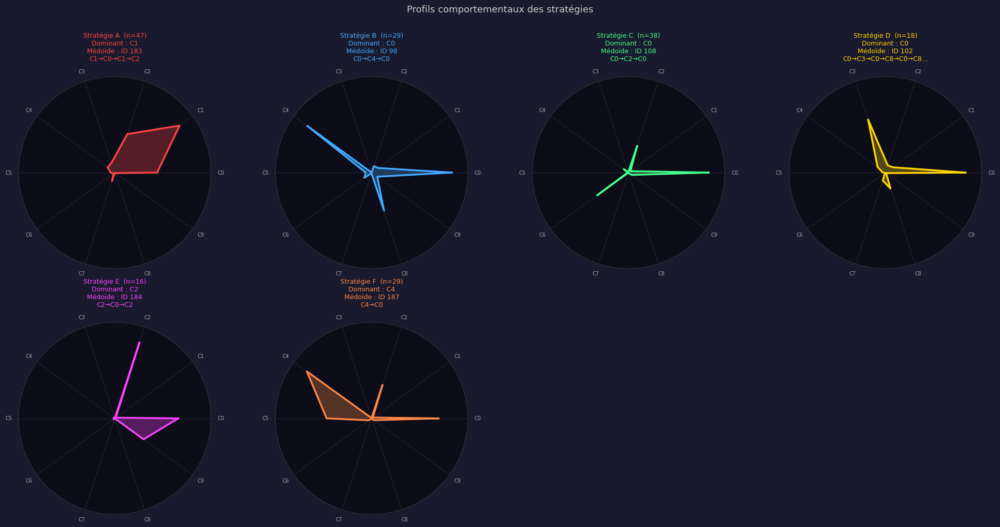

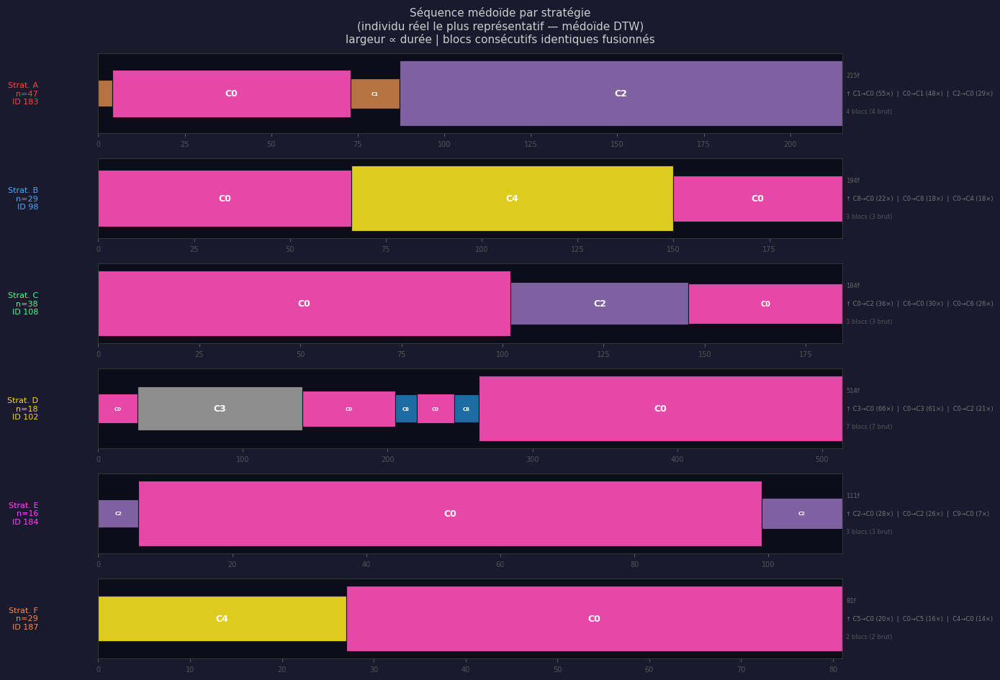

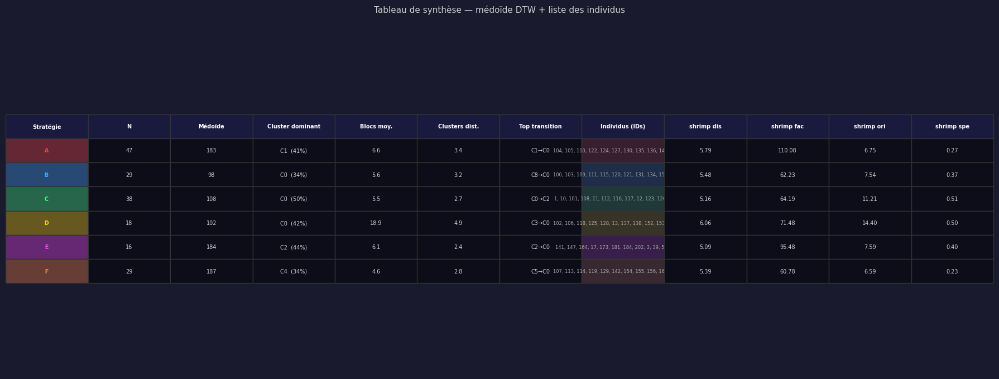

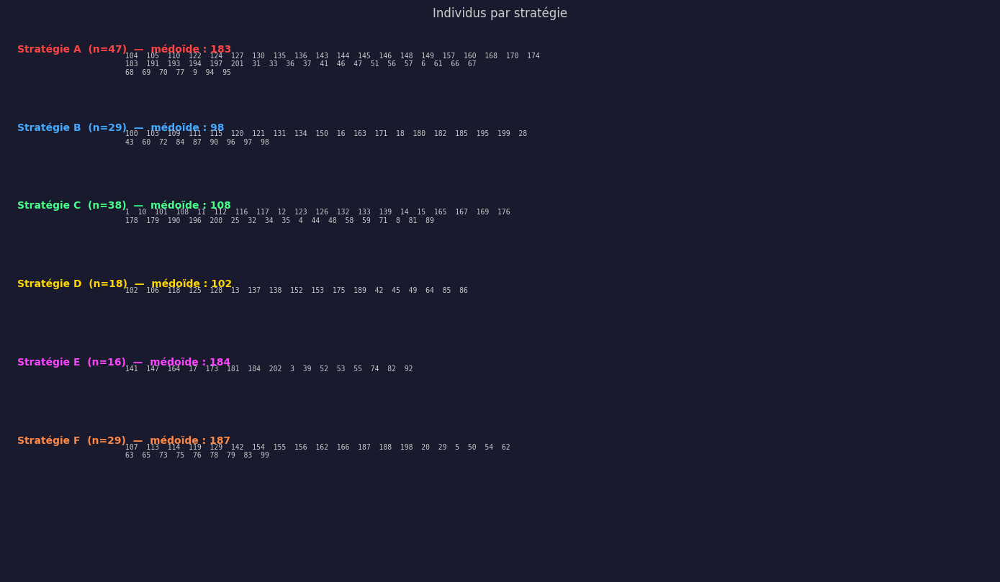


PROFILS (6 groupes) — médoïdes DTW

Stratégie A  (n=47)  —  médoïde : ID 183
  Individus : 104, 105, 110, 122, 124, 127, 130, 135, 136, 143, 144, 145, 146, 148, 149, 157, 160, 168, 170, 174, 183, 191, 193, 194, 197, 201, 31, 33, 36, 37, 41, 46, 47, 51, 56, 57, 6, 61, 66, 67, 68, 69, 70, 77, 9, 94, 95
  Dominant  : C1 (41%)
  Blocs moy : 6.6 | Clusters dist. : 3.4
  Top trans : C1→C0(55×), C0→C1(48×), C2→C0(29×)

Stratégie B  (n=29)  —  médoïde : ID 98
  Individus : 100, 103, 109, 111, 115, 120, 121, 131, 134, 150, 16, 163, 171, 18, 180, 182, 185, 195, 199, 28, 43, 60, 72, 84, 87, 90, 96, 97, 98
  Dominant  : C0 (34%)
  Blocs moy : 5.6 | Clusters dist. : 3.2
  Top trans : C8→C0(22×), C0→C8(18×), C0→C4(18×)

Stratégie C  (n=38)  —  médoïde : ID 108
  Individus : 1, 10, 101, 108, 11, 112, 116, 117, 12, 123, 126, 132, 133, 139, 14, 15, 165, 167, 169, 176, 178, 179, 190, 196, 200, 25, 32, 34, 35, 4, 44, 48, 58, 59, 71, 8, 81, 89
  Dominant  : C0 (50%)
  Blocs moy : 5.5 | Clusters dist. : 2

In [23]:
# Cellule 19 — doit être exécutée AVANT la cellule 30
profiles_shrimp, mapping_letters_shrimp = plot_strategy_profiles_shrimp(
    mapping_optimal_shrimp,
    final_state_shrimp,
    df_shrimp,
    features = FEATURES_SHRIMP,
)

[BH] 14/15 paires significatives après correction Benjamini-Hochberg


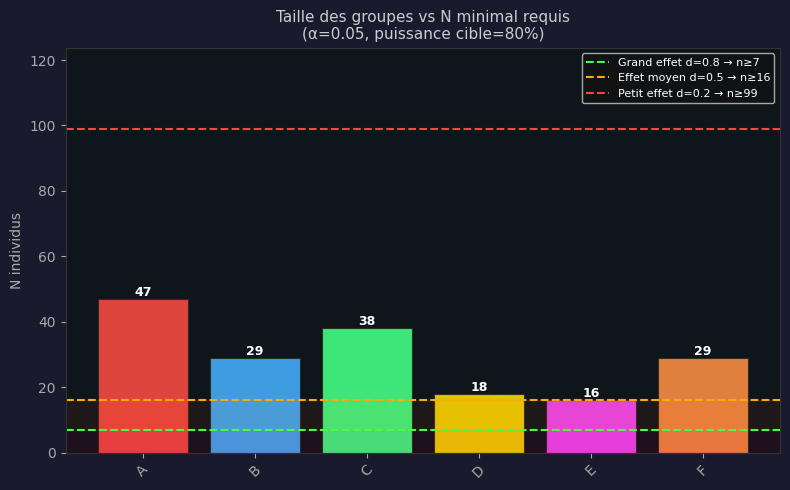

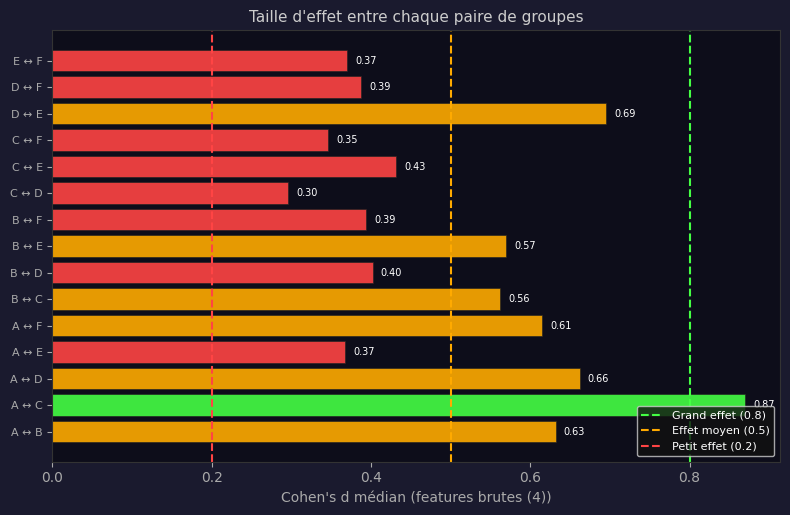

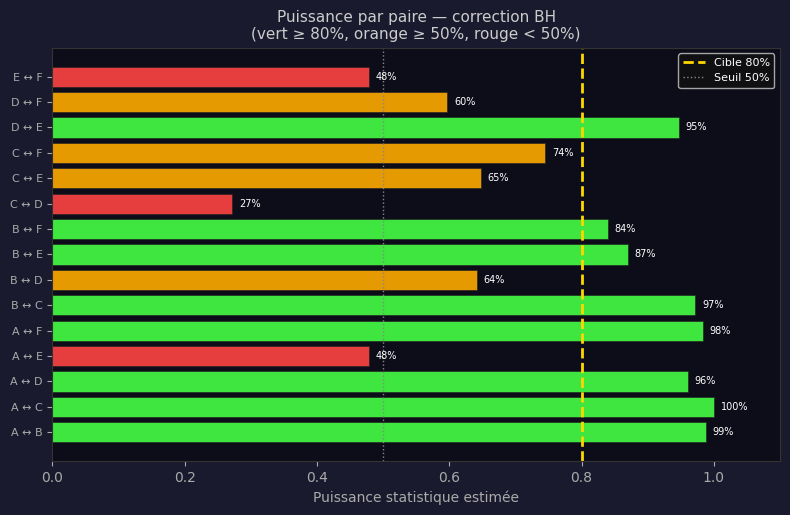

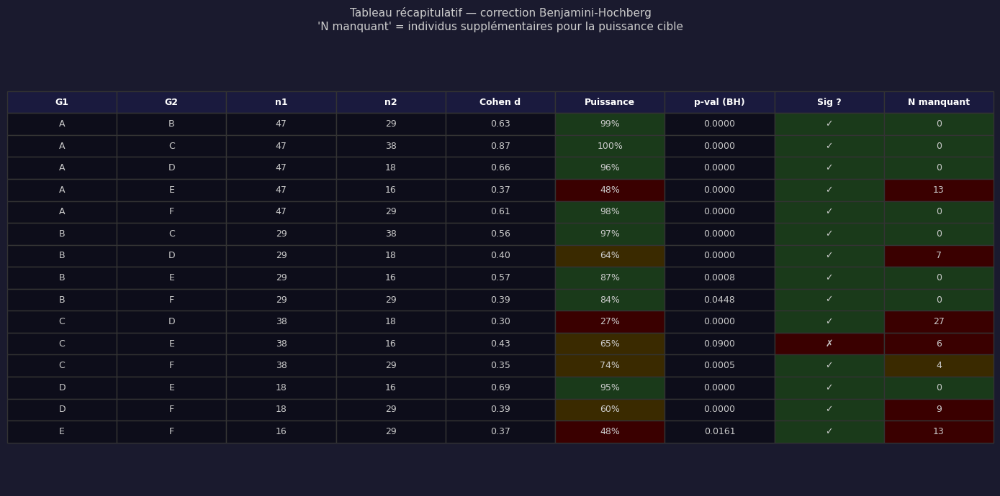

C:\Users\nonoh\AppData\Local\Temp\ipykernel_48580\2256684156.py:503: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
c:\Users\nonoh\anaconda3\envs\cuttlestrike\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


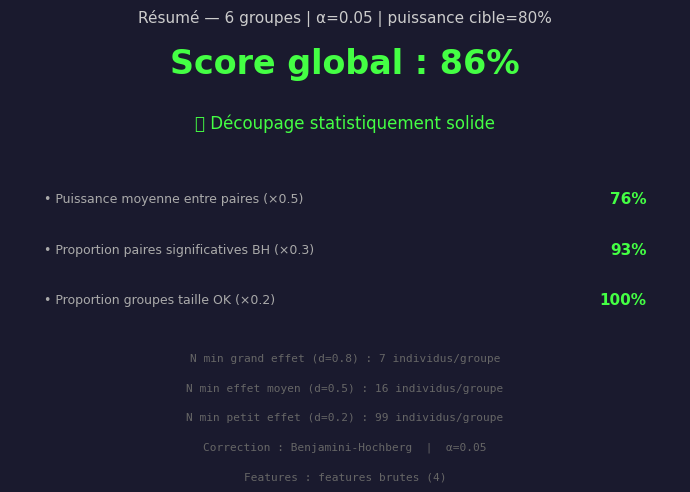


PUISSANCE — 6 groupes | α=0.05 | cible=80%
  Features  : features brutes (4)
  Correction: Benjamini-Hochberg (FDR)
  N min (d=0.8): 7 | (d=0.5): 16 | (d=0.2): 99
  Tailles   : {'A': 47, 'B': 29, 'C': 38, 'D': 18, 'E': 16, 'F': 29, 'MONO': 25}
  Score     : 86%  (✅ Découpage statistiquement solide)


In [24]:
# ── Créer final_state_optimal_shrimp avec les LETTRES de mapping_optimal_shrimp ──
final_state_optimal_shrimp = dict(final_state_shrimp)  # copie superficielle du dict

# Reconstruire strat depuis mapping_optimal_shrimp (qui contient les lettres)
final_state_optimal_shrimp["strat"] = {
    aid: g
    for aid, g in mapping_optimal_shrimp.items()
    if g != "MONO"
}
final_state_optimal_shrimp["mono"] = [
    aid for aid, g in mapping_optimal_shrimp.items()
    if g == "MONO"
]
# ── Appels ────────────────────────────────────────────────────

# Option A — features brutes (recommandé pour la puissance)
df_pairs_shrimp = show_power_analysis_shrimp(
    final_state_optimal_shrimp, df_shrimp,
    features         = FEATURES_SHRIMP,
    use_raw_features = True,
    top_pct_features = 1.0,
    alpha            = 0.05,
    power_target     = 0.80,
)

# # Option B — SeqVec top 20% features discriminantes
# df_pairs_shrimp = show_power_analysis_shrimp(
#     final_state_optimal_shrimp, df_shrimp,
#     use_raw_features = False,
#     top_pct_features = 0.20,
#     alpha            = 0.05,
#     power_target     = 0.80,
# )


##########################################################################################################
######### Analyse des strategies et de leur composition ###################################################
#######################################################################################

In [25]:
#def plot_cluster_probability_over_time_shrimp

import matplotlib as mpl

def plot_cluster_probability_over_time_shrimp(profiles_shrimp, seqs, n_cl_shrimp,
                                        strategy_letters_shrimp, pal,cmap_cl, norm_cl_shrimp,
                                        n_bins=100, smooth_sigma=3,
                                        min_prob_threshold=0.05):
    """
    Deux figures par exécution :

    Figure 1 — tous les clusters (area chart empilé complet)
    Figure 2 — clusters filtrés : à chaque bin, les clusters dont
               la probabilité < min_prob_threshold sont mis à 0
               puis renormalisés → ne montre que les clusters
               significatifs à chaque moment temporel

    min_prob_threshold : seuil de probabilité minimum (défaut 0.05 = 5%)
                         les clusters en dessous sont masqués dans la fig 2
    """
    from scipy.ndimage import gaussian_filter1d

    n_strat = len(strategy_letters_shrimp)
    t_axis  = np.linspace(0, 1, n_bins)

    # ── Calcul des probabilités pour toutes les stratégies ────
    # On calcule une seule fois et on dessine deux figures
    all_probs = {}   # {stratégie: array (n_cl_shrimp, n_bins)}

    for s in strategy_letters_shrimp:
        if s not in profiles_shrimp: continue
        p       = profiles_shrimp[s]
        members = [m for m in p["members"] if m in seqs]
        if not members: continue

        cluster_matrix = np.full((len(members), n_bins), -1, dtype=int)

        for mi, aid in enumerate(members):
            seq     = seqs[aid]["seq"]
            lengths = seqs[aid]["lengths"]
            total   = sum(lengths)
            if total == 0: continue

            # Timeline frame par frame depuis les blocs
            timeline = []
            for c, l in zip(seq, lengths):
                timeline.extend([c] * int(l))
            timeline = np.array(timeline)
            n_frames = len(timeline)

            for b in range(n_bins):
                i_start = int(b * n_frames / n_bins)
                i_end   = int((b + 1) * n_frames / n_bins)
                chunk   = timeline[i_start:i_end]
                if len(chunk) > 0:
                    cluster_matrix[mi, b] = int(
                        np.bincount(chunk, minlength=n_cl_shrimp).argmax()
                    )

        # Probabilités brutes
        prob = np.zeros((n_cl_shrimp, n_bins))
        for b in range(n_bins):
            col_b = cluster_matrix[:, b]
            valid = col_b[col_b >= 0]
            if len(valid) == 0: continue
            for c in range(n_cl_shrimp):
                prob[c, b] = np.sum(valid == c) / len(valid)

        # Lissage
        if smooth_sigma > 0:
            for c in range(n_cl_shrimp):
                prob[c] = gaussian_filter1d(prob[c], sigma=smooth_sigma,
                                             mode='nearest')
            col_sums = prob.sum(axis=0)
            col_sums[col_sums == 0] = 1
            prob /= col_sums

        all_probs[s] = prob

    # ══════════════════════════════════════════════════════════
    # Fonction de dessin commune aux deux figures
    # ══════════════════════════════════════════════════════════
    def _draw_prob_fig(prob_dict, title_suffix, filter_label=""):

        fig, axes = plt.subplots(n_strat, 1,
                                  figsize=(14, max(3, n_strat * 2.2)))
        fig.patch.set_facecolor("#1a1a2e")
        fig.suptitle(
            f"Probabilité d'être dans chaque cluster au cours du temps\n"
            f"{title_suffix}",
            color="#cccccc", fontsize=12
        )
        if n_strat == 1: axes_list = [axes]
        else:            axes_list = list(axes)

        for si, (s, ax) in enumerate(zip(strategy_letters_shrimp, axes_list)):
            if s not in profiles_shrimp or s not in prob_dict: continue
            p   = profiles_shrimp[s]
            col = pal[s]

            members = [m for m in p["members"] if m in seqs]
            prob    = prob_dict[s]

            # Dessin area chart empilé
            ax.set_facecolor("#0d0d1a")
            for sp in ax.spines.values(): sp.set_edgecolor("#333333")
            ax.tick_params(colors="#aaaaaa", labelsize=8)

            bottom = np.zeros(n_bins)
            for c in range(n_cl_shrimp):
                c_color = cmap_cl(norm_cl_shrimp(c))
                vals    = prob[c]

                ax.fill_between(t_axis, bottom, bottom + vals,
                                color=c_color, alpha=0.85,
                                label=f"C{c}", zorder=2)
                ax.plot(t_axis, bottom + vals,
                        color="#0d0d1a", lw=0.4, alpha=0.6, zorder=3)
                bottom += vals

            # Ligne médiane
            ax.axvline(0.5, color="#ffffff", lw=0.8, ls=":",
                       alpha=0.3, zorder=4)

            # Annotations clusters dominants
            dominant  = np.argmax(prob, axis=0)
            prev_c    = dominant[0]
            run_start = 0
            for b in range(1, n_bins):
                if dominant[b] != prev_c or b == n_bins - 1:
                    run_len = b - run_start
                    if run_len >= n_bins * 0.05:
                        mid_b = (run_start + b) // 2
                        mid_x = t_axis[mid_b]
                        bot_c = prob[:prev_c, mid_b].sum()
                        top_c = bot_c + prob[prev_c, mid_b]
                        mid_y = (bot_c + top_c) / 2
                        if prob[prev_c, mid_b] > 0.08:
                            ax.text(mid_x, mid_y, f"C{prev_c}",
                                    ha="center", va="center",
                                    fontsize=7, color="white",
                                    fontweight="bold", zorder=5,
                                    alpha=0.9)
                    run_start = b
                    prev_c    = dominant[b]

            ax.set_xlim(0, 1)
            ax.set_ylim(0, 1)
            ax.set_ylabel(
                f"Strat. {s}\nn={len(members)}",
                color=col, fontsize=9, rotation=0,
                ha="right", va="center", labelpad=55
            )
            ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
            ax.set_yticklabels(["0%","25%","50%","75%","100%"],
                                color="#aaaaaa", fontsize=7)
            ax.grid(axis="x", color="#222233", alpha=0.5, lw=0.5)

            if si == n_strat - 1:
                ax.set_xlabel(
                    "Position temporelle normalisée  (0=début  1=fin)",
                    color="#aaaaaa", fontsize=10)
            else:
                ax.set_xticklabels([])

            # Barre couleur stratégie à gauche
            ax.barh(0.5, 0.008, left=-0.02, height=1.0,
                    color=col, alpha=0.9, transform=ax.transData,
                    clip_on=False, zorder=5)

            # Annotation du seuil dans la fig filtrée
            if filter_label:
                ax.text(0.01, 0.97,
                        f"seuil = {int(min_prob_threshold*100)}%",
                        transform=ax.transAxes,
                        color="#777788", fontsize=7,
                        va="top", ha="left")

        # Légende
        legend_patches = [
            mpatches.Patch(color=cmap_cl(norm_cl_shrimp(c)), label=f"C{c}")
            for c in range(n_cl_shrimp)
        ]
        leg = axes_list[0].legend(
            handles=legend_patches,
            loc="upper right", ncol=min(n_cl_shrimp, 6),
            facecolor="#0d0d1a", labelcolor="#cccccc",
            fontsize=8, title="Clusters", title_fontsize=8,
        )
        leg.get_frame().set_edgecolor("#444444")
        leg.get_title().set_color("#aaaaaa")

        plt.tight_layout()
        plt.show()

    # ══════════════════════════════════════════════════════════
    # FIGURE 1 — Tous les clusters
    # ══════════════════════════════════════════════════════════
    _draw_prob_fig(
        prob_dict    = all_probs,
        title_suffix = "(tous les clusters — position temporelle normalisée)"
    )

    # ══════════════════════════════════════════════════════════
    # FIGURE 2 — Clusters filtrés (prob < seuil → masqués)
    # À chaque bin : les clusters dont prob < min_prob_threshold
    # sont mis à 0 puis les probabilités restantes sont renormalisées
    # → on ne voit que les clusters "actifs" à chaque moment
    # ══════════════════════════════════════════════════════════
    all_probs_filtered = {}

    for s, prob in all_probs.items():
        prob_f = prob.copy()

        # Masque : met à 0 les clusters sous le seuil bin par bin
        prob_f[prob_f < min_prob_threshold] = 0

        # Renormalise bin par bin pour que la somme reste = 1
        # → l'espace libéré est redistribué proportionnellement
        col_sums = prob_f.sum(axis=0)
        col_sums[col_sums == 0] = 1
        prob_f /= col_sums

        all_probs_filtered[s] = prob_f

    _draw_prob_fig(
        prob_dict    = all_probs_filtered,
        title_suffix = (f"clusters filtrés — seuil {int(min_prob_threshold*100)}% "
                        f"(clusters < {int(min_prob_threshold*100)}% masqués "
                        f"et redistribués)"),
        filter_label = True
    )


# ── Appel ─────────────────────────────────────────────────────
# Prérequis : profiles_shrimp vient de plot_strategy_profiles_shrimp
# profiles_shrimp, mapping_letters_shrimp = plot_strategy_profiles_shrimp(...)

seqs             = final_state_shrimp["seqs"]
n_cl_shrimp             = final_state_shrimp["n_cl_shrimp"]
strategy_letters_shrimp = sorted(profiles_shrimp.keys())   # A, B, C... depuis profiles_shrimp

pal         = {s: STRATEGY_PALETTE_SHRIMP[i % len(STRATEGY_PALETTE_SHRIMP)]
               for i, s in enumerate(strategy_letters_shrimp)}
pal["MONO"] = "#666666"

# Couleurs clusters — même palette que partout ailleurs
cmap_cl = mpl.colors.ListedColormap(PALETTE_SHRIMP)
norm_cl_shrimp = mpl.colors.BoundaryNorm(range(len(PALETTE_SHRIMP) + 1),
                                   ncolors=len(PALETTE_SHRIMP))



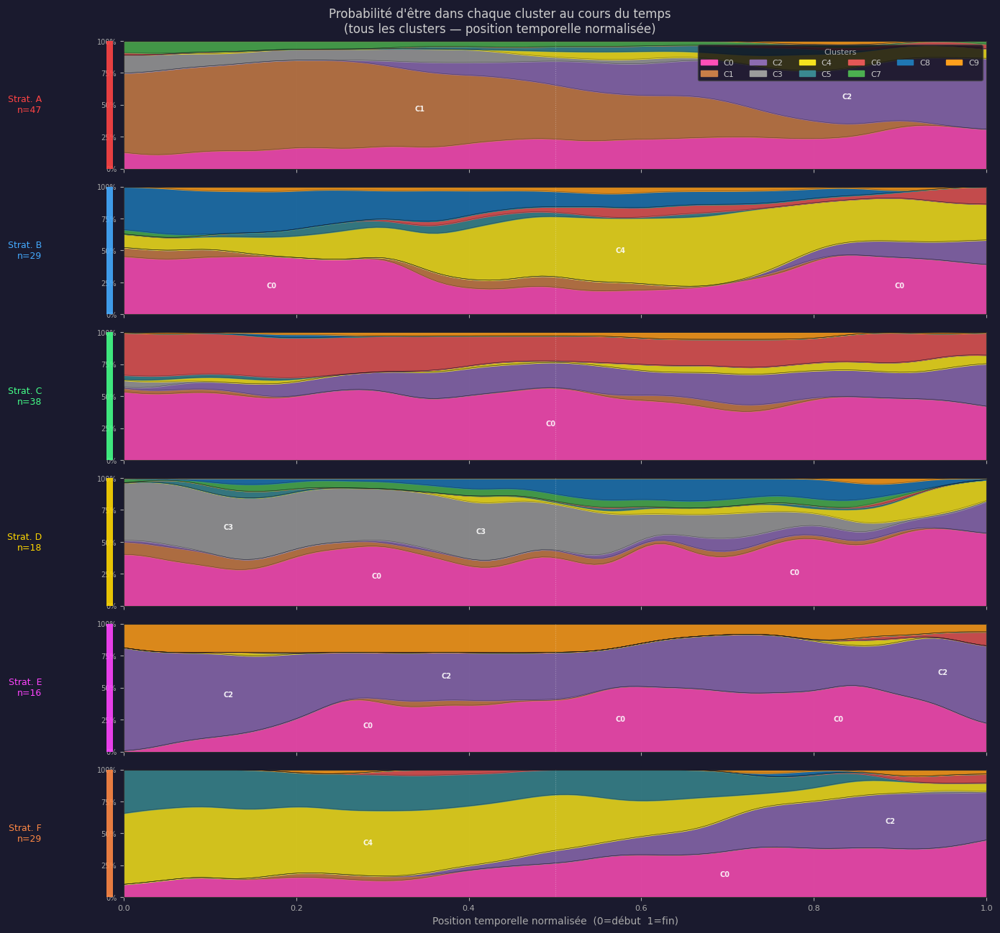

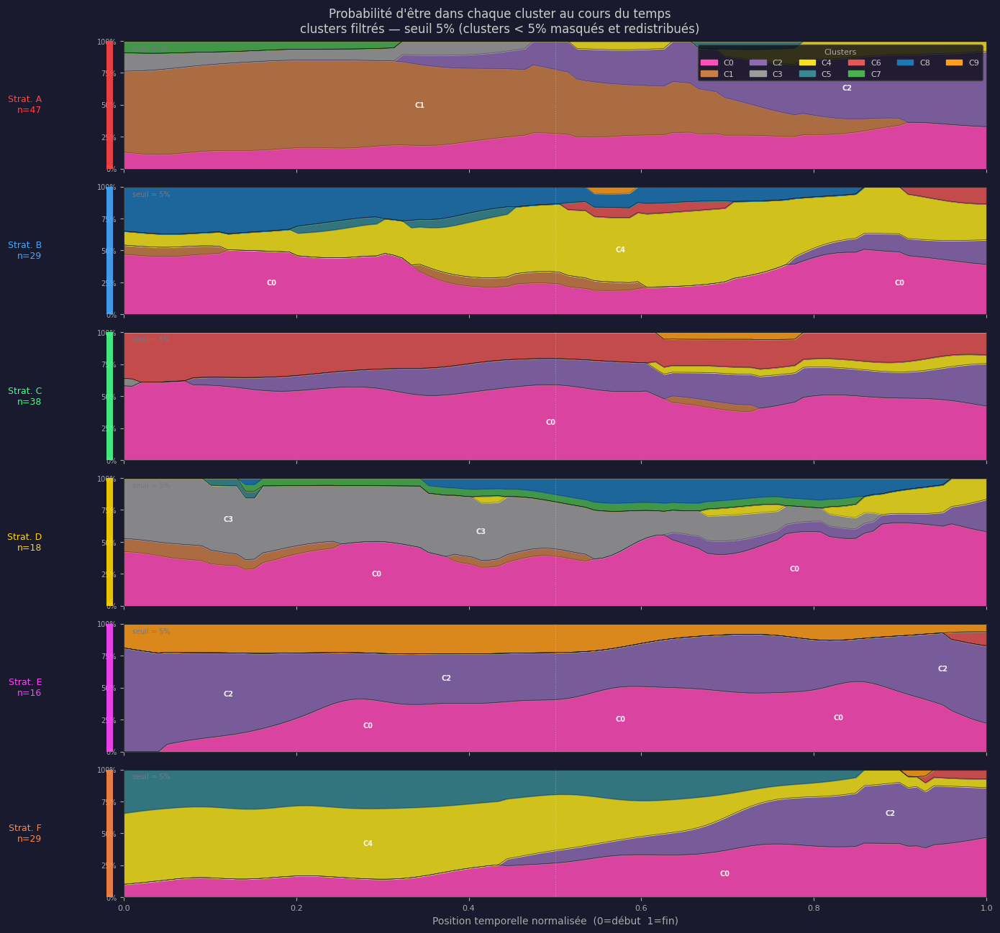

In [26]:
plot_cluster_probability_over_time_shrimp(
    profiles_shrimp          = profiles_shrimp,
    seqs              = seqs,
    n_cl_shrimp              = n_cl_shrimp,
    strategy_letters_shrimp  = strategy_letters_shrimp,
    pal               = pal,
    cmap_cl           = cmap_cl,
    norm_cl_shrimp           = norm_cl_shrimp,
    n_bins            = 100,
    smooth_sigma      = 3,
    min_prob_threshold= 0.05,
)


In [27]:
def plot_strategy_features_over_time_shrimp(
    profiles_shrimp, final_state_shrimp, df_shrimp,
    features      = None,
    n_bins        = 50,
    smooth_sigma  = 2,
    show_variance = True,
):
    """
    Pour chaque stratégie : moyenne (± écart-type) de chaque feature
    au cours du temps normalisé [0=début, 1=fin].

    Principe :
      1. Pour chaque individu, on découpe ses frames en n_bins
         égaux selon sa position temporelle normalisée
      2. On calcule la moyenne de chaque feature dans chaque bin
      3. On moyenne sur tous les individus de la stratégie
      4. On affiche la courbe + zone de variance

    features      : liste des colonnes à tracer (défaut = FEATURES_SHRIMP)
    n_bins        : résolution temporelle (50 = assez lisse)
    smooth_sigma  : lissage gaussien sur les courbes (0 = désactivé)
    show_variance : afficher l'écart-type en zone ombrée
    """
    from scipy.ndimage import gaussian_filter1d

    if features is None:
        features = FEATURES_SHRIMP

    seqs             = final_state_shrimp["seqs"]
    strategy_letters_shrimp = sorted(profiles_shrimp.keys())
    n_strat          = len(strategy_letters_shrimp)
    n_feat           = len(features)
    t_axis           = np.linspace(0, 1, n_bins)

    pal         = {s: STRATEGY_PALETTE_SHRIMP[i % len(STRATEGY_PALETTE_SHRIMP)]
                   for i, s in enumerate(strategy_letters_shrimp)}
    pal["MONO"] = "#666666"

    df_w_shrimp = df_shrimp.copy()
    df_w_shrimp["animal_id"] = df_w_shrimp["animal_id"].astype(str)

    # ── Calcul des profils temporels ──────────────────────────
    # Pour chaque stratégie et chaque feature :
    #   all_curves[s][feat] = array (n_members, n_bins)
    all_means = {}   # {s: array (n_feat, n_bins)}
    all_stds  = {}   # {s: array (n_feat, n_bins)}

    for s in strategy_letters_shrimp:
        if s not in profiles_shrimp: continue
        members = [m for m in profiles_shrimp[s]["members"] if m in seqs]
        if not members: continue

        # Matrice (n_members, n_feat, n_bins)
        feat_matrix = np.full((len(members), n_feat, n_bins), np.nan)

        for mi, aid in enumerate(members):
            # Récupérer les frames de cet individu dans df_shrimp
            mask_ind = df_w_shrimp["animal_id"] == str(aid)
            df_ind   = df_w_shrimp[mask_ind].copy()

            if "frame" in df_ind.columns:
                df_ind = df_ind.sort_values("frame")

            n_frames = len(df_ind)
            if n_frames == 0: continue

            # Vérifier que toutes les features sont présentes
            feats_ok = [f for f in features if f in df_ind.columns]
            if not feats_ok: continue

            # Découper en n_bins selon la position temporelle
            for b in range(n_bins):
                i_start = int(b * n_frames / n_bins)
                i_end   = int((b + 1) * n_frames / n_bins)
                if i_end <= i_start:
                    i_end = i_start + 1
                i_end = min(i_end, n_frames)

                chunk = df_ind.iloc[i_start:i_end]
                if len(chunk) == 0: continue

                for fi, feat in enumerate(features):
                    if feat in chunk.columns:
                        feat_matrix[mi, fi, b] = chunk[feat].mean()

        # Moyenne et écart-type sur les individus
        # nanmean/nanstd ignore les bins sans données
        mean_mat = np.nanmean(feat_matrix, axis=0)   # (n_feat, n_bins)
        std_mat  = np.nanstd(feat_matrix,  axis=0)   # (n_feat, n_bins)

        # Lissage gaussien sur les courbes
        if smooth_sigma > 0:
            for fi in range(n_feat):
                mean_mat[fi] = gaussian_filter1d(
                    mean_mat[fi], sigma=smooth_sigma, mode='nearest')
                std_mat[fi]  = gaussian_filter1d(
                    std_mat[fi],  sigma=smooth_sigma, mode='nearest')

        all_means[s] = mean_mat
        all_stds[s]  = std_mat

        print(f"[FEATURES_SHRIMP/TEMPS] Stratégie {s} : "
              f"{len(members)} individus × {n_feat} features × {n_bins} bins")

    if not all_means:
        print("[ERREUR] Aucune donnée calculée.")
        return

    # ════════════════════════════════════════════════════════
    # FIGURE — une ligne par stratégie, une colonne par feature
    # ════════════════════════════════════════════════════════
    fig, axes = plt.subplots(
        n_strat, n_feat,
        figsize=(n_feat * 3.5, n_strat * 2.5),
        sharex=True
    )
    fig.patch.set_facecolor("#1a1a2e")
    fig.suptitle(
        "Features comportementales au cours du temps normalisé\n"
        "par stratégie  (moyenne ± écart-type sur les individus)",
        color="#cccccc", fontsize=13, y=1.01
    )

    # Normaliser axes en array 2D même si 1 seule ligne/colonne
    if n_strat == 1 and n_feat == 1:
        axes = np.array([[axes]])
    elif n_strat == 1:
        axes = axes[np.newaxis, :]
    elif n_feat == 1:
        axes = axes[:, np.newaxis]

    # Calculer les limites globales par feature
    # → même échelle Y pour toutes les stratégies d'une feature
    ylims = {}
    for fi, feat in enumerate(features):
        all_vals = []
        for s in strategy_letters_shrimp:
            if s not in all_means: continue
            m = all_means[s][fi]
            e = all_stds[s][fi]
            all_vals.extend((m - e).tolist())
            all_vals.extend((m + e).tolist())
        if all_vals:
            vmin = np.nanmin(all_vals)
            vmax = np.nanmax(all_vals)
            margin = (vmax - vmin) * 0.1
            ylims[fi] = (vmin - margin, vmax + margin)
        else:
            ylims[fi] = (0, 1)

    for si, s in enumerate(strategy_letters_shrimp):
        if s not in all_means: continue
        col      = pal[s]
        mean_mat = all_means[s]
        std_mat  = all_stds[s]
        n_ind    = len(profiles_shrimp[s]["members"])

        for fi, feat in enumerate(features):
            ax = axes[si, fi]
            ax.set_facecolor("#0d0d1a")
            for sp in ax.spines.values():
                sp.set_edgecolor("#333333")
            ax.tick_params(colors="#555555", labelsize=7)

            mean_v = mean_mat[fi]
            std_v  = std_mat[fi]

            # Courbe moyenne
            ax.plot(t_axis, mean_v,
                    color=col, lw=2.0, alpha=0.95, zorder=3)

            # Zone ± 1 écart-type
            if show_variance:
                ax.fill_between(
                    t_axis,
                    mean_v - std_v,
                    mean_v + std_v,
                    color=col, alpha=0.20, zorder=2
                )

            # Ligne verticale au milieu
            ax.axvline(0.5, color="#ffffff", lw=0.6,
                       ls=":", alpha=0.25, zorder=4)

            # Ligne horizontale à 0 si pertinent
            if ylims[fi][0] < 0 < ylims[fi][1]:
                ax.axhline(0, color="#444455", lw=0.5,
                           ls="-", alpha=0.5, zorder=1)

            ax.set_xlim(0, 1)
            ax.set_ylim(ylims[fi])
            ax.grid(axis="x", color="#222233", alpha=0.4, lw=0.5)

            # Titre colonne (feature) — seulement sur la 1ère ligne
            if si == 0:
                ax.set_title(
                    feat.replace("_", "\n"),
                    color="#aaaaaa", fontsize=9, pad=4
                )

            # Label ligne (stratégie) — seulement sur la 1ère colonne
            if fi == 0:
                ax.set_ylabel(
                    f"Strat. {s}\nn={n_ind}",
                    color=col, fontsize=9,
                    rotation=0, ha="right",
                    va="center", labelpad=55
                )
            else:
                ax.set_ylabel("")

            # Axe X — seulement sur la dernière ligne
            if si == n_strat - 1:
                ax.set_xlabel("t normalisé",
                              color="#555555", fontsize=7)
            else:
                ax.set_xticklabels([])

    plt.tight_layout()
    plt.show()


    # FIGURE 2 — Toutes les stratégies superposées par feature
    # ════════════════════════════════════════════════════════
    n_cols = min(3, n_feat)
    n_rows = (n_feat + n_cols - 1) // n_cols

    fig2, axes2 = plt.subplots(
        n_rows, n_cols,
        figsize=(n_cols * 4.5, n_rows * 3.5),
        sharex=True
    )
    fig2.patch.set_facecolor("#1a1a2e")
    fig2.suptitle(
        "Features comportementales — toutes stratégies superposées\n"
        "(moyenne ± écart-type  |  position temporelle normalisée)",
        color="#cccccc", fontsize=13, y=1.01
    )

    # Normaliser axes en array 2D
    if n_rows == 1 and n_cols == 1:
        axes2 = np.array([[axes2]])
    elif n_rows == 1:
        axes2 = axes2[np.newaxis, :]
    elif n_cols == 1:
        axes2 = axes2[:, np.newaxis]

    for fi, feat in enumerate(features):
        ri = fi // n_cols
        ci = fi % n_cols
        ax = axes2[ri, ci]
        ax.set_facecolor("#0d0d1a")
        for sp in ax.spines.values(): sp.set_edgecolor("#333333")
        ax.tick_params(colors="#555555", labelsize=7)

        for s in strategy_letters_shrimp:
            if s not in all_means: continue
            col      = pal[s]
            mean_v   = all_means[s][fi]
            std_v    = all_stds[s][fi]
            n_ind    = len(profiles_shrimp[s]["members"])

            ax.plot(t_axis, mean_v,
                    color=col, lw=2.0, alpha=0.95,
                    label=f"{s} (n={n_ind})", zorder=3)

            if show_variance:
                ax.fill_between(
                    t_axis,
                    mean_v - std_v,
                    mean_v + std_v,
                    color=col, alpha=0.12, zorder=2
                )

        ax.axvline(0.5, color="#ffffff", lw=0.6,
                   ls=":", alpha=0.25, zorder=4)

        if ylims[fi][0] < 0 < ylims[fi][1]:
            ax.axhline(0, color="#444455", lw=0.5,
                       ls="-", alpha=0.5, zorder=1)

        ax.set_xlim(0, 1)
        ax.set_ylim(ylims[fi])
        ax.grid(axis="x", color="#222233", alpha=0.4, lw=0.5)
        ax.set_title(feat.replace("_", "\n"),
                     color="#aaaaaa", fontsize=10, pad=4)

        if ri == n_rows - 1:
            ax.set_xlabel("t normalisé", color="#555555", fontsize=8)

        # Légende sur le premier subplot seulement
        if fi == 0:
            leg = ax.legend(
                fontsize=8, loc="upper right",
                facecolor="#111122", labelcolor="#cccccc",
                framealpha=0.8
            )
            leg.get_frame().set_edgecolor("#444444")

    # Masquer les axes vides si n_feat < n_rows * n_cols
    for fi in range(n_feat, n_rows * n_cols):
        axes2[fi // n_cols, fi % n_cols].set_visible(False)

    plt.tight_layout()
    plt.show()

[FEATURES_SHRIMP/TEMPS] Stratégie A : 47 individus × 4 features × 50 bins
[FEATURES_SHRIMP/TEMPS] Stratégie B : 29 individus × 4 features × 50 bins
[FEATURES_SHRIMP/TEMPS] Stratégie C : 38 individus × 4 features × 50 bins
[FEATURES_SHRIMP/TEMPS] Stratégie D : 18 individus × 4 features × 50 bins
[FEATURES_SHRIMP/TEMPS] Stratégie E : 16 individus × 4 features × 50 bins
[FEATURES_SHRIMP/TEMPS] Stratégie F : 29 individus × 4 features × 50 bins


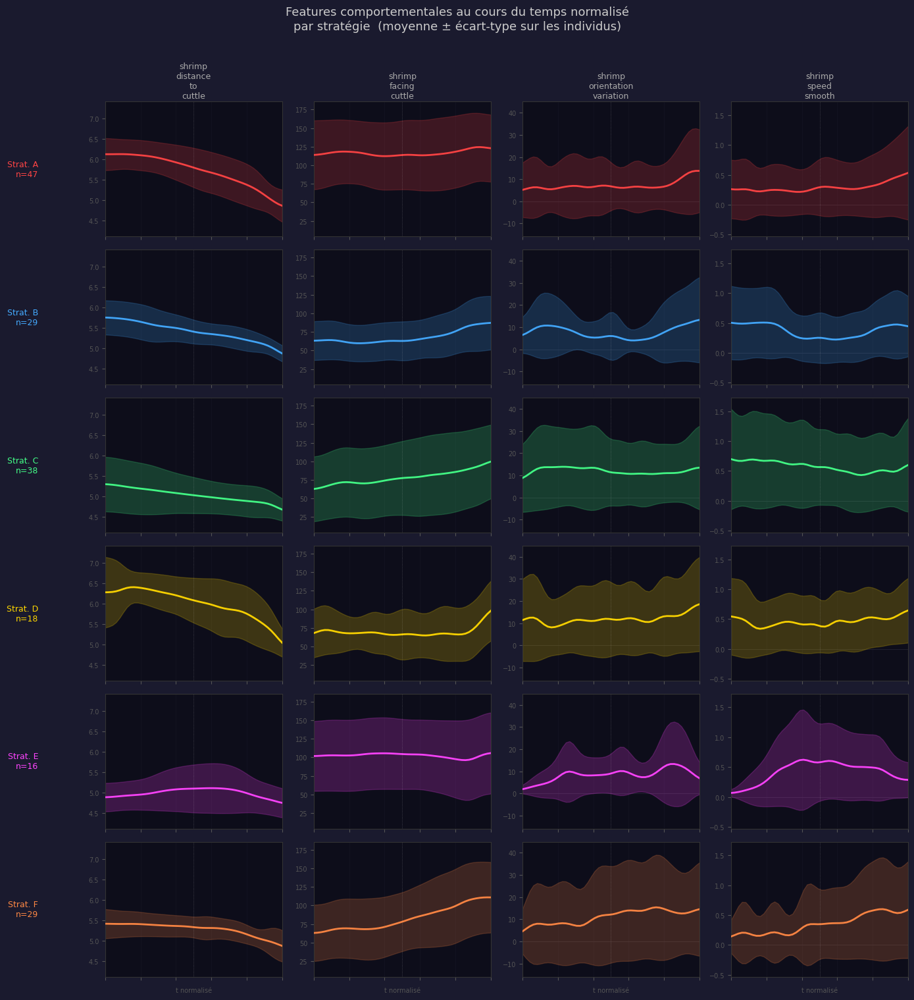

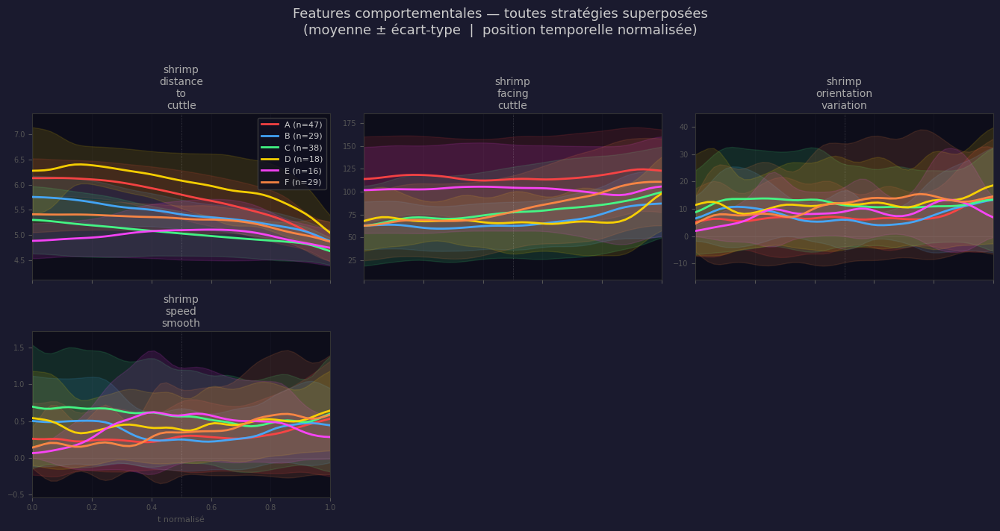

In [28]:
# ── Appel ─────────────────────────────────────────────────────
plot_strategy_features_over_time_shrimp(
    profiles_shrimp      = profiles_shrimp,
    final_state_shrimp   = final_state_shrimp,
    df_shrimp            = df_shrimp,
    features      = FEATURES_SHRIMP,
    n_bins        = 50,
    smooth_sigma  = 2,
    show_variance = True,
)

[OK] 202 individus | 6 stratégies
     Répartition : Counter({'A': 47, 'C': 38, 'B': 29, 'F': 29, 'MONO': 25, 'D': 18, 'E': 16})


C:\Users\nonoh\AppData\Local\Temp\ipykernel_48580\1801591009.py:70: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(
C:\Users\nonoh\AppData\Local\Temp\ipykernel_48580\1801591009.py:70: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(
C:\Users\nonoh\AppData\Local\Temp\ipykernel_48580\1801591009.py:70: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(
C:\Users\nonoh\AppData\Local\Temp\ipykernel_48580\1801591009.py:70: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3

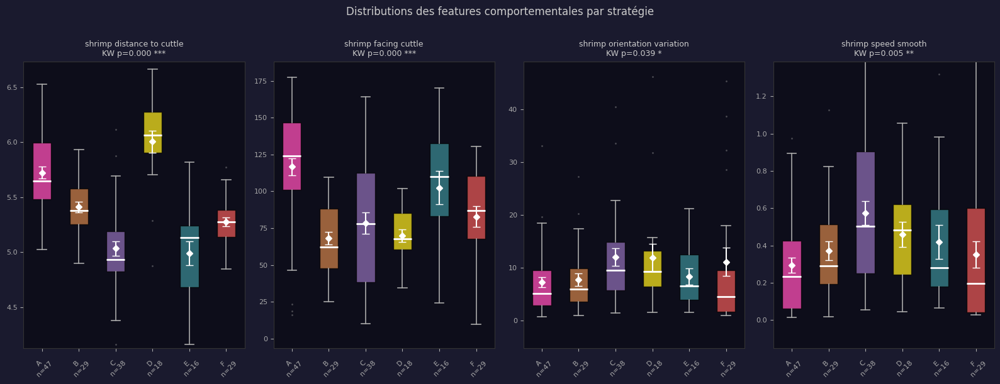

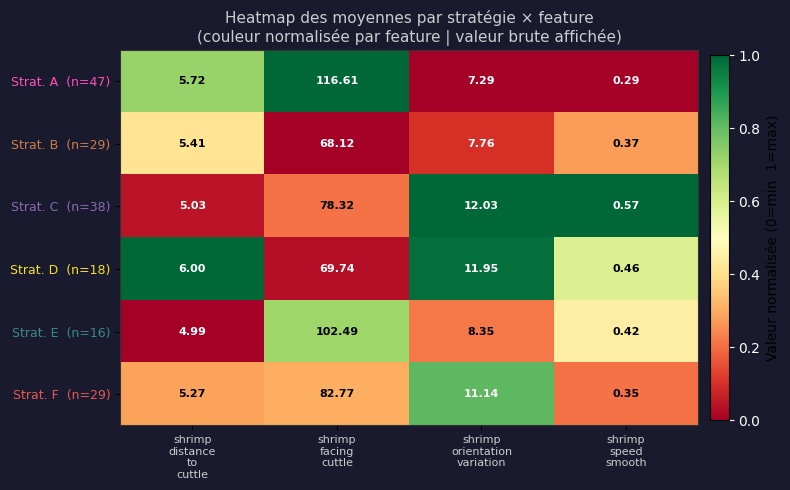

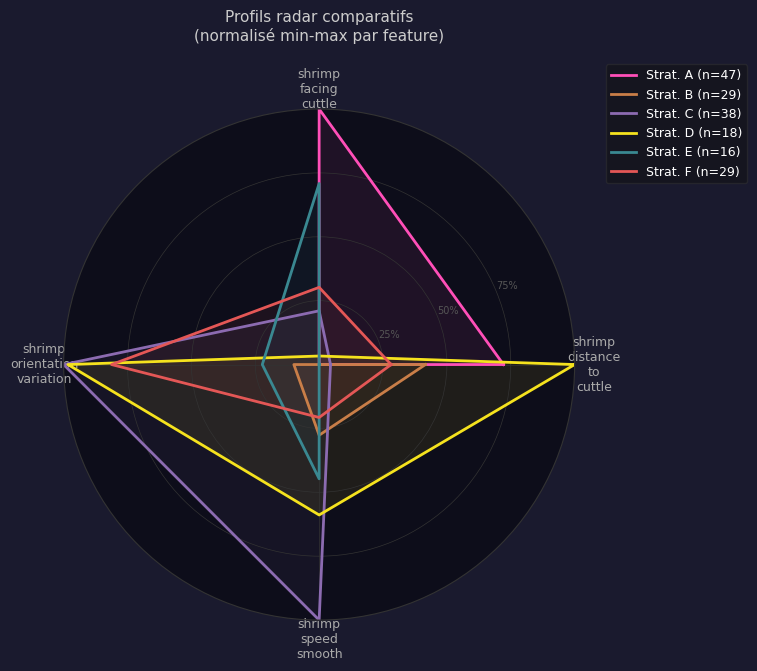

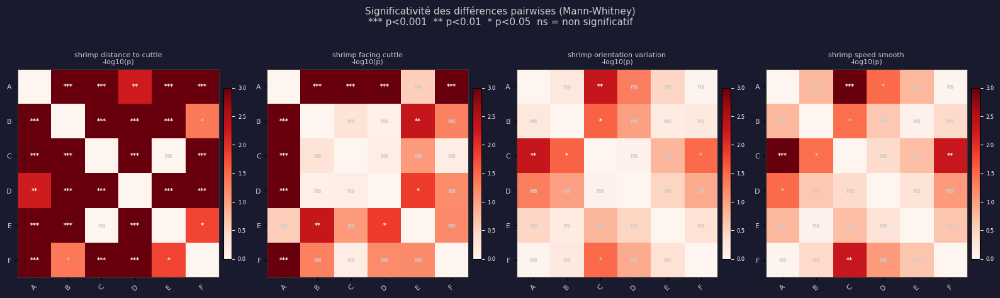

In [29]:
#  CELLULE — Plots comparatifs entre stratégies
#  Basé sur df_shrimp (features comportementales) + mapping_letters_shrimp
#  (stratégies issues du regroupement optimal)
# ══════════════════════════════════════════════════════════════

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib as mpl
from scipy import stats
from scipy.stats import mannwhitneyu, kruskal
from itertools import combinations
from collections import Counter

# ── Palette stratégies ────────────────────────────────────────
strategy_letters_plot = sorted(
    set(v for v in mapping_letters_shrimp.values() if v != "MONO")
)
all_groups_plot = strategy_letters_plot + (
    ["MONO"] if "MONO" in set(mapping_letters_shrimp.values()) else []
)
STRAT_PAL = [
    "#FF4FB8","#C97E48","#8C6BB1","#F5E21E","#3A8891",
    "#E45756","#4CAF50","#1F77B4","#FF9F1C","#A05195",
    "#2CB1BC","#D62728","#9467BD","#8C564B","#E377C2",
]
pal_strat_shrimp = {s: STRAT_PAL[i % len(STRAT_PAL)]
             for i, s in enumerate(all_groups_plot)}
pal_strat_shrimp["MONO"] = "#666666"

n_strat = len(strategy_letters_plot)

# ── Construire df_shrimp individu × features + stratégie ─────────────
df_w_shrimp = df_shrimp.copy()
df_w_shrimp["animal_id"] = df_w_shrimp["animal_id"].astype(str)

df_indiv_shrimp = df_w_shrimp.groupby("animal_id")[FEATURES_SHRIMP].mean()
df_indiv_shrimp["strategie"] = [
    mapping_letters_shrimp.get(str(aid), "MONO")
    for aid in df_indiv_shrimp.index
]
df_indiv_shrimp = df_indiv_shrimp.dropna(subset=FEATURES_SHRIMP)

print(f"[OK] {len(df_indiv_shrimp)} individus | {n_strat} stratégies")
print(f"     Répartition : {Counter(df_indiv_shrimp['strategie'].values)}")


# ════════════════════════════════════════════════════════════
# FIGURE 1 — Boxplots par feature × stratégie
# ════════════════════════════════════════════════════════════

n_feats = len(FEATURES_SHRIMP)
fig, axes = plt.subplots(1, n_feats, figsize=(4 * n_feats, 6))
fig.patch.set_facecolor("#1a1a2e")
if n_feats == 1: axes = [axes]

for ax, feat in zip(axes, FEATURES_SHRIMP):
    ax.set_facecolor("#0d0d1a")
    for sp in ax.spines.values(): sp.set_edgecolor("#333333")
    ax.tick_params(colors="#aaaaaa", labelsize=8)

    data_per_strat = [
        df_indiv_shrimp.loc[df_indiv_shrimp["strategie"] == s, feat].dropna().values
        for s in strategy_letters_plot
    ]
    labels = [f"{s}\nn={len(d)}" for s, d in zip(strategy_letters_plot, data_per_strat)]
    colors_bp = [pal_strat_shrimp[s] for s in strategy_letters_plot]

    bp = ax.boxplot(
        data_per_strat, labels=labels, patch_artist=True,
        medianprops=dict(color="white", linewidth=2),
        whiskerprops=dict(linewidth=1.2, color="#aaaaaa"),
        capprops=dict(linewidth=1.2, color="#aaaaaa"),
        flierprops=dict(marker="o", markersize=2, alpha=0.4,
                        markerfacecolor="#aaaaaa", markeredgecolor="none"),
    )
    for patch, col in zip(bp["boxes"], colors_bp):
        patch.set_facecolor(col); patch.set_alpha(0.75)

    # Moyenne ± SEM superposée
    for i, (vals, s) in enumerate(zip(data_per_strat, strategy_letters_plot), 1):
        if len(vals) == 0: continue
        mean = vals.mean()
        sem  = vals.std(ddof=1) / np.sqrt(len(vals)) if len(vals) > 1 else 0
        ax.errorbar(i, mean, yerr=sem, fmt="D", color="white",
                    markersize=5, capsize=4, linewidth=1.5, zorder=5)

    # Limites Y robustes
    all_vals = np.concatenate([v for v in data_per_strat if len(v)])
    if len(all_vals):
        lo, hi = np.percentile(all_vals, [2, 98])
        margin = (hi - lo) * 0.15 or abs(hi) * 0.1 or 1
        ax.set_ylim(lo - margin, hi + margin)

    # Test Kruskal-Wallis global
    valid = [d for d in data_per_strat if len(d) >= 3]
    if len(valid) >= 2:
        try:
            _, p_kw = kruskal(*valid)
            sig = "***" if p_kw < 0.001 else "**" if p_kw < 0.01 else \
                  "*" if p_kw < 0.05 else "ns"
            ax.set_title(f"{feat.replace('_',' ')}\nKW p={p_kw:.3f} {sig}",
                         color="#cccccc", fontsize=9)
        except Exception:
            ax.set_title(feat.replace('_',' '), color="#cccccc", fontsize=9)
    else:
        ax.set_title(feat.replace('_',' '), color="#cccccc", fontsize=9)

    ax.tick_params(axis="x", rotation=45)

fig.suptitle("Distributions des features comportementales par stratégie",
             color="#cccccc", fontsize=12, y=1.01)
plt.tight_layout()
plt.show()


# ════════════════════════════════════════════════════════════
# FIGURE 2 — Heatmap des moyennes normalisées par stratégie
# ════════════════════════════════════════════════════════════

fig, ax = plt.subplots(figsize=(max(8, n_strat * 0.8), 5))
fig.patch.set_facecolor("#1a1a2e")
ax.set_facecolor("#0d0d1a")

# Matrice stratégie × feature (moyennes normalisées 0-1)
mat = np.zeros((n_strat, n_feats))
for i, s in enumerate(strategy_letters_plot):
    for j, feat in enumerate(FEATURES_SHRIMP):
        vals = df_indiv_shrimp.loc[df_indiv_shrimp["strategie"] == s, feat].dropna().values
        mat[i, j] = vals.mean() if len(vals) > 0 else np.nan

# Normalisation min-max par feature
mat_norm = mat.copy()
for j in range(n_feats):
    col = mat[:, j]
    valid = col[~np.isnan(col)]
    if len(valid) > 0 and valid.max() != valid.min():
        mat_norm[:, j] = (col - valid.min()) / (valid.max() - valid.min())
    else:
        mat_norm[:, j] = 0.5

im = ax.imshow(mat_norm, cmap="RdYlGn", aspect="auto", vmin=0, vmax=1)

# Labels et annotations
ax.set_xticks(range(n_feats))
ax.set_xticklabels([f.replace("_","\n") for f in FEATURES_SHRIMP],
                    color="#cccccc", fontsize=8)
ax.set_yticks(range(n_strat))
ax.set_yticklabels(
    [f"Strat. {s}  (n={int((df_indiv_shrimp['strategie']==s).sum())})"
     for s in strategy_letters_plot],
    color="#cccccc", fontsize=9
)
# Colorier les labels Y selon la stratégie
for ytick, s in zip(ax.get_yticklabels(), strategy_letters_plot):
    ytick.set_color(pal_strat_shrimp[s])

# Valeurs brutes dans les cellules
for i in range(n_strat):
    for j in range(n_feats):
        v = mat[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                    fontsize=8, color="black" if 0.2 < mat_norm[i,j] < 0.8 else "white",
                    fontweight="bold")

plt.colorbar(im, ax=ax, label="Valeur normalisée (0=min  1=max)",
             fraction=0.03, pad=0.02).ax.tick_params(colors="white")
ax.set_title("Heatmap des moyennes par stratégie × feature\n"
             "(couleur normalisée par feature | valeur brute affichée)",
             color="#cccccc", fontsize=11)
for sp in ax.spines.values(): sp.set_edgecolor("#333333")
plt.tight_layout()
plt.show()


# ════════════════════════════════════════════════════════════
# FIGURE 3 — Radars comparatifs superposés
# ════════════════════════════════════════════════════════════

angles   = np.linspace(0, 2*np.pi, n_feats, endpoint=False)
ang_full = np.concatenate([angles, [angles[0]]])

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
fig.patch.set_facecolor("#1a1a2e")
ax.set_facecolor("#0d0d1a")

global_min = np.nanmin(mat, axis=0)
global_max = np.nanmax(mat, axis=0)

for i, s in enumerate(strategy_letters_plot):
    row = mat[i]
    norm_row = np.where(
        global_max != global_min,
        (row - global_min) / (global_max - global_min + 1e-9),
        0.5
    )
    vals_f = np.concatenate([norm_row, [norm_row[0]]])
    col    = pal_strat_shrimp[s]
    n_s    = int((df_indiv_shrimp["strategie"] == s).sum())
    ax.plot(ang_full, vals_f, lw=2, color=col, label=f"Strat. {s} (n={n_s})")
    ax.fill(ang_full, vals_f, alpha=0.08, color=col)

ax.set_xticks(angles)
ax.set_xticklabels([f.replace("_","\n") for f in FEATURES_SHRIMP],
                    color="#aaaaaa", fontsize=9)
ax.set_ylim(0, 1)
ax.set_yticks([0.25, 0.5, 0.75])
ax.set_yticklabels(["25%", "50%", "75%"], color="#555555", fontsize=7)
ax.grid(color="#333333", lw=0.5)
ax.spines["polar"].set_color("#333333")
ax.set_title("Profils radar comparatifs\n(normalisé min-max par feature)",
             color="#cccccc", fontsize=11, pad=20)

leg = ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.1),
                fontsize=9, framealpha=0.5)
leg.get_frame().set_facecolor("#111111")
leg.get_frame().set_edgecolor("#333333")
for t in leg.get_texts(): t.set_color("white")

plt.tight_layout()
plt.show()


# ════════════════════════════════════════════════════════════
# FIGURE 4 — Matrice de p-valeurs (Mann-Whitney pairwise)
# ════════════════════════════════════════════════════════════

n_s   = len(strategy_letters_plot)
fig, axes = plt.subplots(1, n_feats, figsize=(4 * n_feats, max(4, n_s * 0.6 + 1)))
fig.patch.set_facecolor("#1a1a2e")
if n_feats == 1: axes = [axes]

for ax, feat in zip(axes, FEATURES_SHRIMP):
    ax.set_facecolor("#0d0d1a")
    for sp in ax.spines.values(): sp.set_edgecolor("#333333")

    # Matrice p-valeurs
    p_mat = np.ones((n_s, n_s))
    for i, s1 in enumerate(strategy_letters_plot):
        for j, s2 in enumerate(strategy_letters_plot):
            if i >= j: continue
            x1 = df_indiv_shrimp.loc[df_indiv_shrimp["strategie"]==s1, feat].dropna().values
            x2 = df_indiv_shrimp.loc[df_indiv_shrimp["strategie"]==s2, feat].dropna().values
            if len(x1) >= 3 and len(x2) >= 3:
                try:
                    _, p = mannwhitneyu(x1, x2, alternative="two-sided")
                    p_mat[i, j] = p
                    p_mat[j, i] = p
                except Exception:
                    pass

    # Log-transform pour la lisibilité
    p_log = -np.log10(np.clip(p_mat, 1e-10, 1))
    np.fill_diagonal(p_log, 0)

    im = ax.imshow(p_log, cmap="Reds", aspect="auto", vmin=0, vmax=3)

    ax.set_xticks(range(n_s))
    ax.set_yticks(range(n_s))
    ax.set_xticklabels(strategy_letters_plot, color="#cccccc",
                        fontsize=8, rotation=45)
    ax.set_yticklabels(strategy_letters_plot, color="#cccccc", fontsize=8)

    for i in range(n_s):
        for j in range(n_s):
            if i == j: continue
            p_val = p_mat[i, j]
            sig   = "***" if p_val < 0.001 else "**" if p_val < 0.01 else \
                    "*"   if p_val < 0.05  else "ns"
            col_t = "white" if p_log[i,j] > 1.5 else "#cccccc"
            ax.text(j, i, sig, ha="center", va="center",
                    fontsize=7, color=col_t, fontweight="bold")

    ax.set_title(f"{feat.replace('_',' ')}\n-log10(p)",
                 color="#cccccc", fontsize=8)
    plt.colorbar(im, ax=ax, fraction=0.04, pad=0.02
                 ).ax.tick_params(colors="white", labelsize=6)

fig.suptitle("Significativité des différences pairwises (Mann-Whitney)\n"
             "*** p<0.001  ** p<0.01  * p<0.05  ns = non significatif",
             color="#cccccc", fontsize=11, y=1.02)
plt.tight_layout()
plt.show()


In [30]:
#  Imports complémentaires pour l'analyse de trajectoires 
import ast
from scipy.fft import fft
from scipy.spatial.distance import cdist
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

# FEATURES_SHRIMP et PALETTE_SHRIMP déjÃ  définis en cellule 0
N_CLUSTERS_SHRIMP = final_state_shrimp["n_cl_shrimp"]
print(f" Imports OK | N_CLUSTERS_SHRIMP={N_CLUSTERS_SHRIMP} | FEATURES_SHRIMP={FEATURES_SHRIMP}")

 Imports OK | N_CLUSTERS_SHRIMP=10 | FEATURES_SHRIMP=['shrimp_distance_to_cuttle', 'shrimp_facing_cuttle', 'shrimp_orientation_variation', 'shrimp_speed_smooth']


In [31]:
#  Centres des clusters dans l'espace des features 
# Calculé directement depuis df_shrimp (déjÃ  chargé en mémoire)
cluster_col = final_state_shrimp["col"]   # "supercluster" ou "cluster"
n_cl_shrimp        = final_state_shrimp["n_cl_shrimp"]

cluster_ids        = sorted(df_shrimp[cluster_col].unique())
cluster_stats_rows = []
for k in cluster_ids:
    mask = df_shrimp[cluster_col] == k
    cluster_stats_rows.append(df_shrimp.loc[mask, FEATURES_SHRIMP].mean().values)

cluster_stats = pd.DataFrame(cluster_stats_rows, columns=FEATURES_SHRIMP,
                              index=cluster_ids)
final_state_shrimp["cluster_stats"] = cluster_stats

seqs_dict = final_state_shrimp["seqs"]
n_mono    = sum(1 for s in seqs_dict.values() if len(s["seq"]) <= 1)

print(f"âœ… cluster_stats : {cluster_stats.shape}")
print(cluster_stats.round(4))
print(f"\nâœ… {len(seqs_dict)} individus dont {n_mono} MONO")
# mapping_letters_shrimp est déjÃ  défini (retour de plot_strategy_profiles_shrimp)
print(f"âœ… mapping_letters_shrimp : {len(mapping_letters_shrimp)} entrées")

âœ… cluster_stats : (10, 4)
   shrimp_distance_to_cuttle  shrimp_facing_cuttle  \
0                     5.6618               83.8801   
1                     6.1408              132.4779   
2                     4.8712              136.0289   
3                     6.5058               66.0041   
4                     5.1832               78.4892   
5                     5.6042               17.5789   
6                     4.9411               23.0396   
7                     6.3699               20.1916   
8                     5.9247               48.9712   
9                     5.2792               33.4689   

   shrimp_orientation_variation  shrimp_speed_smooth  
0                       24.9185               1.0725  
1                        3.2156               0.1212  
2                        3.3807               0.0856  
3                        1.5351               0.0482  
4                        2.3942               0.0645  
5                        1.6766               0

[OK] 6 stratégies à tracer
  Stratégie A : 47 individus
  Stratégie B : 29 individus
  Stratégie C : 38 individus
  Stratégie D : 18 individus
  Stratégie E : 16 individus
  Stratégie F : 29 individus
[OK] Limites arène : X=[437, 1498] Y=[67, 1017]
[OK] Sauvegardé → C:\Users\nonoh\Documents\01Travail\02_CREC\cuttle_strike\analysis_results_shrimp\trajectoires_superposees_smooth1.png


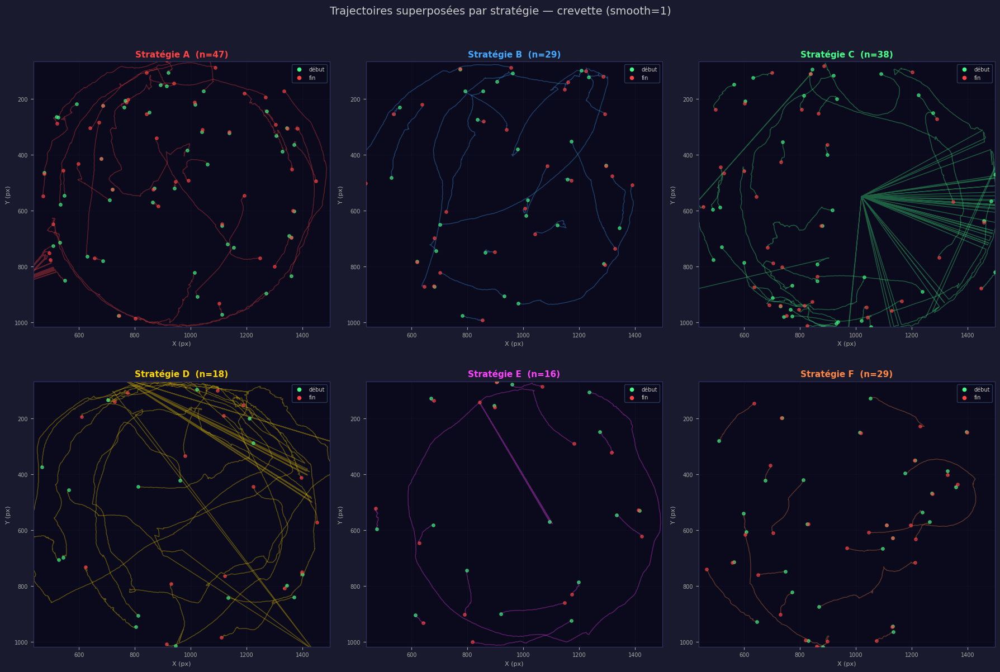

In [32]:
# ══════════════════════════════════════════════════════════════
#  TRAJECTOIRES SUPERPOSÉES PAR STRATÉGIE — crevette
#  Tous les individus d'un même groupe sur le même graphe
# ══════════════════════════════════════════════════════════════

STRATEGY_TO_PLOT = None   # ← None = toutes les stratégies
                           #   ou ex: "A" pour une seule

ALPHA      = 0.35   # transparence des trajectoires individuelles
LW         = 1.0    # épaisseur des lignes
ARENA_SIZE = 1500   # taille de l'espace d'affichage en pixels

# ── Récupérer la liste des stratégies ─────────────────────────
# mapping_optimal_shrimp = {animal_id: lettre_stratégie}
strat_to_ids = {}
for aid, strat in mapping_optimal_shrimp.items():
    if strat == "MONO":
        continue
    strat_to_ids.setdefault(strat, []).append(str(aid))

strategies_to_plot = (
    sorted(strat_to_ids.keys())
    if STRATEGY_TO_PLOT is None
    else [STRATEGY_TO_PLOT]
)

print(f"[OK] {len(strategies_to_plot)} stratégies à tracer")
for s in strategies_to_plot:
    print(f"  Stratégie {s} : {len(strat_to_ids[s])} individus")


# ── Calcul des limites globales de l'arène ─────────────────────
# Pour que toutes les stratégies aient le même repère spatial
x_all = df_shrimp["HeadShrimp_x"].dropna()
y_all = df_shrimp["HeadShrimp_y"].dropna()
x_min, x_max = x_all.quantile(0.01), x_all.quantile(0.99)
y_min, y_max = y_all.quantile(0.01), y_all.quantile(0.99)
print(f"[OK] Limites arène : X=[{x_min:.0f}, {x_max:.0f}] "
      f"Y=[{y_min:.0f}, {y_max:.0f}]")


# ── Un graphe par stratégie ────────────────────────────────────
nc = min(3, len(strategies_to_plot))
nr = int(np.ceil(len(strategies_to_plot) / nc))

fig, axes = plt.subplots(
    nr, nc,
    figsize=(nc * 6, nr * 6),   # ~6 pouces par panneau
)
fig.patch.set_facecolor("#1a1a2e")
fig.suptitle(
    f"Trajectoires superposées par stratégie — crevette "
    f"(smooth={SELECTED_WINDOW_SHRIMP})",
    color="#cccccc", fontsize=14, y=1.01
)

axes_flat = np.array(axes).flatten() if nr * nc > 1 else [axes]

for ax_i, strat in enumerate(strategies_to_plot):
    ax  = axes_flat[ax_i]
    ids = strat_to_ids[strat]

    ax.set_facecolor("#0a0a1c")
    for sp in ax.spines.values():
        sp.set_edgecolor("#333366")

    n_plotted = 0
    for aid in ids:
        sub = df_shrimp[df_shrimp["animal_id"].astype(str) == str(aid)]
        if len(sub) < 2:
            continue

        x = sub["HeadShrimp_x"].values
        y = sub["HeadShrimp_y"].values

        # Couleur par individu — dégradé discret dans la stratégie
        col = STRATEGY_PALETTE_SHRIMP[ax_i % len(STRATEGY_PALETTE_SHRIMP)]
        r, g, b = tuple(int(col.lstrip("#")[i:i+2], 16)/255 for i in (0,2,4))

        ax.plot(x, y, color=(r, g, b), alpha=ALPHA,
                linewidth=LW, zorder=2)

        # Point de début (vert) et fin (rouge)
        ax.scatter(x[0],  y[0],  color="#44ff88", s=15,
                   zorder=4, alpha=0.6)
        ax.scatter(x[-1], y[-1], color="#ff4444", s=15,
                   zorder=4, alpha=0.6)

        n_plotted += 1

    # Même repère pour tous
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_max, y_min)   # Y inversé = repère image
    ax.set_aspect("equal")

    ax.set_title(
        f"Stratégie {strat}  (n={n_plotted})",
        color=STRATEGY_PALETTE_SHRIMP[ax_i % len(STRATEGY_PALETTE_SHRIMP)],
        fontsize=11, fontweight="bold"
    )
    ax.set_xlabel("X (px)", color="#aaaaaa", fontsize=8)
    ax.set_ylabel("Y (px)", color="#aaaaaa", fontsize=8)
    ax.tick_params(colors="#aaaaaa", labelsize=7)
    ax.grid(alpha=0.1, color="#334466")

    # Légende début/fin
    ax.scatter([], [], color="#44ff88", s=20, label="début")
    ax.scatter([], [], color="#ff4444", s=20, label="fin")
    leg = ax.legend(fontsize=7, loc="upper right",
                    facecolor="#0a0a1c", edgecolor="#334466")
    for t in leg.get_texts():
        t.set_color("#cccccc")

# Masquer les axes vides
for ax_i in range(len(strategies_to_plot), len(axes_flat)):
    axes_flat[ax_i].set_visible(False)

plt.tight_layout()

# Sauvegarde
out_path = OUT_DIR_SHRIMP / f"trajectoires_superposees_smooth{SELECTED_WINDOW_SHRIMP}.png"
plt.savefig(out_path, dpi=150, bbox_inches="tight",
            facecolor="#1a1a2e")
print(f"[OK] Sauvegardé → {out_path}")
plt.show()

In [33]:
#def plot 3D
from scipy.ndimage import gaussian_filter
from scipy.interpolate import griddata

def _compute_temporal_grid_shrimp(df_w_shrimp, resolution=100, smoothing=5,
                            normalize_by_individual=True):
    # ── Fix : réinitialiser l'index pour éviter les IndexError ──
    # Quand df_w_shrimp est un sous-DataFrame filtré, les index pandas
    # ne correspondent plus aux positions 0..n-1
    # → reset_index() garantit que idx va de 0 à len(df_w_shrimp)-1
    df_w_shrimp = df_w_shrimp.reset_index(drop=True)

    xg = df_w_shrimp["umap_x"].values
    yg = df_w_shrimp["umap_y"].values

    if normalize_by_individual:
        zg = np.zeros(len(df_w_shrimp))
        for aid, grp in df_w_shrimp.groupby("animal_id"):
            idx = grp.index   # ← maintenant ces index sont bien 0..n-1
            n   = len(grp)
            if n == 1:
                zg[idx] = 1.0
            else:
                zg[idx] = 1.0 - np.arange(n) / (n - 1)
    else:
        n  = len(df_w_shrimp)
        zg = 1.0 - np.arange(n) / max(n - 1, 1)

    # reste identique...
    x_min, x_max = xg.min(), xg.max()
    y_min, y_max = yg.min(), yg.max()
    margin_x = (x_max - x_min) * 0.05
    margin_y = (y_max - y_min) * 0.05

    xi = np.linspace(x_min - margin_x, x_max + margin_x, resolution)
    yi = np.linspace(y_min - margin_y, y_max + margin_y, resolution)
    Xi, Yi = np.meshgrid(xi, yi)

    pts = np.column_stack([xg, yg])
    Zi  = griddata(pts, zg, (Xi, Yi), method='linear')

    mask_nan = np.isnan(Zi)
    if mask_nan.any():
        Zi_near      = griddata(pts, zg, (Xi, Yi), method='nearest')
        Zi[mask_nan] = Zi_near[mask_nan]

    if smoothing > 0:
        Zi = gaussian_filter(Zi, sigma=smoothing)

    Zi = np.clip(Zi, 0, 1)

    return Zi, Xi, Yi, xg, yg, zg

def plot_temporal_group_overlay_shrimp(Z_shrimp, df_shrimp, mapping_letters_shrimp,
                                 groupe,
                                 smoothing=5,
                                 resolution=100,
                                 normalize_by_individual=True,
                                 colormap="RdYlGn_r",
                                 stride=2):

    df_w_shrimp = df_shrimp.copy()
    df_w_shrimp["animal_id"] = df_w_shrimp["animal_id"].astype(str)
    df_w_shrimp["umap_x"]    = Z_shrimp[:, 0]
    df_w_shrimp["umap_y"]    = Z_shrimp[:, 1]
    df_w_shrimp["groupe"]    = df_w_shrimp["animal_id"].map(
        lambda a: mapping_letters_shrimp.get(a, "MONO")
    )

    group_list = sorted(set(v for v in mapping_letters_shrimp.values() if v != "MONO"))
    pal        = {g: PALETTE_SHRIMP[i % len(PALETTE_SHRIMP)] for i, g in enumerate(group_list)}
    col        = pal.get(groupe, "#4CAF50")
    n_ind      = df_w_shrimp[df_w_shrimp["groupe"] == groupe]["animal_id"].nunique()

    if groupe not in group_list:
        print(f"❌ Groupe '{groupe}' introuvable. Disponibles : {group_list}")
        return

    cluster_col = ("supercluster" if "supercluster" in df_w_shrimp.columns
                   else "cluster"  if "cluster"      in df_w_shrimp.columns
                   else None)

    print(f"[OVERLAY] Calcul grille globale...")
    Zi_global, Xi, Yi, xg, yg, zg = _compute_temporal_grid_shrimp(
        df_w_shrimp, resolution, smoothing, normalize_by_individual
    )

    print(f"[OVERLAY] Calcul grille groupe {groupe} (n={n_ind})...")
    df_g = df_w_shrimp[df_w_shrimp["groupe"] == groupe]
    Zi_g, Xi_g, Yi_g, xg_, yg_, zg_ = _compute_temporal_grid_shrimp(
        df_g, resolution, smoothing, normalize_by_individual
    )

    x_min, x_max = Xi.min(), Xi.max()
    y_min, y_max = Yi.min(), Yi.max()

    # ════════════════════════════════════════════════════════
    # FIGURE 1 — 3D
    # ════════════════════════════════════════════════════════
    fig1 = plt.figure(figsize=(12, 9))
    fig1.patch.set_facecolor("#1a1a2e")
    ax3d = fig1.add_subplot(111, projection='3d')
    ax3d.set_facecolor("#0d0d1a")

    ax3d.plot_surface(
        Xi[::stride*2, ::stride*2],
        Yi[::stride*2, ::stride*2],
        Zi_global[::stride*2, ::stride*2],
        cmap='gray', alpha=0.15,
        linewidth=0, antialiased=False, vmin=0, vmax=1,
    )
    surf = ax3d.plot_surface(
        Xi_g[::stride, ::stride],
        Yi_g[::stride, ::stride],
        Zi_g[::stride, ::stride],
        cmap=colormap, alpha=0.88,
        linewidth=0, antialiased=False, vmin=0, vmax=1,
    )
    ax3d.contourf(Xi_g, Yi_g, Zi_g, zdir='z', offset=-0.05,
                  cmap=colormap, alpha=0.25, levels=10)
    ax3d.set_zlim(-0.1, 1.1)
    ax3d.set_xlabel("UMAP D1",           color="#aaaaaa", labelpad=8)
    ax3d.set_ylabel("UMAP D2",           color="#aaaaaa", labelpad=8)
    ax3d.set_zlabel("Position temporelle", color="#aaaaaa", labelpad=8)
    ax3d.tick_params(colors="#555555", labelsize=6)
    ax3d.xaxis.pane.fill = False
    ax3d.yaxis.pane.fill = False
    ax3d.zaxis.pane.fill = False
    ax3d.xaxis.pane.set_edgecolor("#333333")
    ax3d.yaxis.pane.set_edgecolor("#333333")
    ax3d.zaxis.pane.set_edgecolor("#333333")
    ax3d.grid(True, color="#333333", alpha=0.2)
    ax3d.set_title(f"3D — Groupe {groupe} (n={n_ind}) sur fond global\n"
                   f"σ={smoothing} | res={resolution}",
                   color=col, fontsize=11, pad=10)
    fig1.colorbar(surf, ax=ax3d, fraction=0.015, pad=0.05,
                  shrink=0.5, label="1=début  0=fin"
                  ).ax.tick_params(colors="#aaaaaa", labelsize=7)
    fig1.suptitle(f"Topographie temporelle 3D — Stratégie {groupe}",
                  color=col, fontsize=13)
    plt.tight_layout(); plt.show()

    # ════════════════════════════════════════════════════════
    # FIGURE 2 — 2D temporelle overlay
    # ════════════════════════════════════════════════════════
    fig2, ax2d = plt.subplots(figsize=(11, 9))
    fig2.patch.set_facecolor("#1a1a2e")
    ax2d.set_facecolor("#0d0d1a"); ax2d.axis("off")

    ax2d.imshow(Zi_global, origin='lower',
                extent=[x_min, x_max, y_min, y_max],
                cmap='gray', vmin=0, vmax=1,
                aspect='auto', alpha=0.35, zorder=1)
    ax2d.imshow(Zi_g, origin='lower',
                extent=[Xi_g.min(), Xi_g.max(),
                        Yi_g.min(), Yi_g.max()],
                cmap=colormap, vmin=0, vmax=1,
                aspect='auto', alpha=0.80, zorder=2)
    ax2d.contour(Xi_g, Yi_g,
                 gaussian_filter(np.nan_to_num(Zi_g), sigma=2),
                 levels=8, colors=col, alpha=0.4,
                 linewidths=0.8, zorder=3)
    ax2d.scatter(xg_, yg_, c=zg_, cmap=colormap,
                 vmin=0, vmax=1, s=2, alpha=0.2, zorder=4)
    ax2d.contour(Xi, Yi,
                 gaussian_filter(np.nan_to_num(Zi_global), sigma=2),
                 levels=6, colors='white', alpha=0.10,
                 linewidths=0.5, zorder=3)

    im_p = plt.cm.ScalarMappable(cmap=colormap, norm=plt.Normalize(0,1))
    im_p.set_array([])
    fig2.colorbar(im_p, ax=ax2d, fraction=0.025, pad=0.01,
                  label="1=début  0=fin"
                  ).ax.tick_params(colors="#aaaaaa", labelsize=7)
    ax2d.set_title(f"Topographie temporelle 2D — Groupe {groupe} / fond global\n"
                   f"{'normalisé/individu' if normalize_by_individual else 'brut'} "
                   f"| σ={smoothing}",
                   color=col, fontsize=11)
    fig2.suptitle(f"Carte temporelle — Stratégie {groupe}", color=col, fontsize=13)
    plt.tight_layout(); plt.show()

    # ════════════════════════════════════════════════════════
    # FIGURE 3 — Clusters comportementaux
    # ════════════════════════════════════════════════════════
    fig3, ax3 = plt.subplots(figsize=(11, 9))
    fig3.patch.set_facecolor("#1a1a2e")
    ax3.set_facecolor("#0d0d1a"); ax3.axis("off")

    if cluster_col:
        n_cl_shrimp   = int(df_w_shrimp[cluster_col].nunique())
        norm_c = plt.Normalize(vmin=0, vmax=n_cl_shrimp-1)
        cmap_c = plt.cm.tab20

        # Fond : tous les points grisés
        ax3.scatter(df_w_shrimp["umap_x"], df_w_shrimp["umap_y"],
                    color="#222233", s=1.5, alpha=0.2, zorder=1)

        # Points du groupe colorés par cluster
        ax3.scatter(df_g["umap_x"], df_g["umap_y"],
                    c=df_g[cluster_col].values,
                    cmap=cmap_c, norm=norm_c,
                    s=5, alpha=0.65, zorder=2)

        # Labels des clusters au centroïde global
        for c in range(n_cl_shrimp):
            mask_c = df_w_shrimp[cluster_col] == c
            if not mask_c.any(): continue
            cx = df_w_shrimp.loc[mask_c, "umap_x"].mean()
            cy = df_w_shrimp.loc[mask_c, "umap_y"].mean()
            ax3.text(cx, cy, f"C{c}",
                     fontsize=7, fontweight="bold",
                     ha="center", va="center", color="white", zorder=3,
                     bbox=dict(facecolor=cmap_c(norm_c(c)),
                               alpha=0.75, edgecolor="none", pad=1))

        # Colorbar clusters
        sm_c = plt.cm.ScalarMappable(cmap=cmap_c, norm=norm_c)
        sm_c.set_array([])
        fig3.colorbar(sm_c, ax=ax3, fraction=0.025, pad=0.01,
                      label=cluster_col
                      ).ax.tick_params(colors="#aaaaaa", labelsize=7)

        # Légende groupes
        patches = [mpatches.Patch(color=col, label=f"Groupe {groupe} (n={n_ind})"),
                   mpatches.Patch(color="#222233", label="Autres (fond)")]
        leg = ax3.legend(handles=patches, facecolor="#0d0d1a",
                         labelcolor="#cccccc", fontsize=9, loc="upper right")
        leg.get_frame().set_edgecolor("#444444")

    else:
        ax3.text(0.5, 0.5, "Colonne 'cluster' ou 'supercluster'\nnon trouvée",
                 ha="center", va="center", color="#ff4444",
                 transform=ax3.transAxes, fontsize=12)

    ax3.set_title(f"Clusters comportementaux — Groupe {groupe}\n"
                  f"(points du groupe colorés par {cluster_col or 'N/A'} "
                  f"sur fond global grisé)",
                  color=col, fontsize=11)
    fig3.suptitle(f"Distribution dans les clusters — Stratégie {groupe}",
                  color=col, fontsize=13)
    plt.tight_layout(); plt.show()


# ══════════════════════════════════════════════════════════════

def plot_temporal_individual_shrimp(Z_shrimp, df_shrimp, mapping_letters_shrimp,
                              animal_id,
                              smoothing_global=5,
                              resolution=100,
                              normalize_by_individual=True,
                              colormap="RdYlGn_r",
                              stride=2):

    df_w_shrimp = df_shrimp.copy()
    df_w_shrimp["animal_id"] = df_w_shrimp["animal_id"].astype(str)
    df_w_shrimp["umap_x"]    = Z_shrimp[:, 0]
    df_w_shrimp["umap_y"]    = Z_shrimp[:, 1]

    aid    = str(animal_id)
    df_ind = df_w_shrimp[df_w_shrimp["animal_id"] == aid]

    if len(df_ind) == 0:
        print(f"❌ Individu '{aid}' introuvable.")
        return

    groupe = mapping_letters_shrimp.get(aid, "MONO") if mapping_letters_shrimp else "?"
    group_list = sorted(set(v for v in mapping_letters_shrimp.values()
                            if v != "MONO")) if mapping_letters_shrimp else []
    pal    = {g: PALETTE_SHRIMP[i % len(PALETTE_SHRIMP)] for i, g in enumerate(group_list)}
    col    = pal.get(groupe, "#4CAF50")
    n_frames = len(df_ind)

    cluster_col = ("supercluster" if "supercluster" in df_w_shrimp.columns
                   else "cluster"  if "cluster"      in df_w_shrimp.columns
                   else None)

    if "frame" in df_ind.columns:
        df_ind = df_ind.sort_values("frame")

    x_ind  = df_ind["umap_x"].values
    y_ind  = df_ind["umap_y"].values
    t_inv  = 1.0 - np.arange(n_frames) / max(n_frames-1, 1)
    cmap_obj = plt.cm.get_cmap(colormap)

    print(f"[INDIV] ID={aid} | Groupe={groupe} | {n_frames} frames")
    print(f"[INDIV] Calcul grille globale...")
    Zi_global, Xi, Yi, xg, yg, zg = _compute_temporal_grid_shrimp(
        df_w_shrimp, resolution, smoothing_global, normalize_by_individual
    )

    x_min, x_max = Xi.min(), Xi.max()
    y_min, y_max = Yi.min(), Yi.max()

    # ════════════════════════════════════════════════════════
    # FIGURE 1 — 3D
    # ════════════════════════════════════════════════════════
    fig1 = plt.figure(figsize=(12, 9))
    fig1.patch.set_facecolor("#1a1a2e")
    ax3d = fig1.add_subplot(111, projection='3d')
    ax3d.set_facecolor("#0d0d1a")

    ax3d.plot_surface(
        Xi[::stride*2, ::stride*2],
        Yi[::stride*2, ::stride*2],
        Zi_global[::stride*2, ::stride*2],
        cmap='gray', alpha=0.15,
        linewidth=0, antialiased=False, vmin=0, vmax=1,
    )
    for i in range(n_frames - 1):
        rgba = cmap_obj(t_inv[i])
        ax3d.plot(x_ind[i:i+2], y_ind[i:i+2], t_inv[i:i+2],
                  color=rgba, lw=2.0, alpha=0.85, zorder=6)
        ax3d.plot(x_ind[i:i+2], y_ind[i:i+2], [-0.05, -0.05],
                  color=rgba, lw=0.8, alpha=0.2, zorder=3)

    ax3d.scatter(x_ind[0],  y_ind[0],  t_inv[0],
                 color='lime',    s=100, zorder=8,
                 marker='o', edgecolors='white', linewidths=1.5,
                 depthshade=False)
    ax3d.scatter(x_ind[-1], y_ind[-1], t_inv[-1],
                 color='#ff4444', s=100, zorder=8,
                 marker='s', edgecolors='white', linewidths=1.5,
                 depthshade=False)

    ax3d.set_zlim(-0.1, 1.1)
    ax3d.set_xlabel("UMAP D1",           color="#aaaaaa", labelpad=8)
    ax3d.set_ylabel("UMAP D2",           color="#aaaaaa", labelpad=8)
    ax3d.set_zlabel("Position temporelle", color="#aaaaaa", labelpad=8)
    ax3d.tick_params(colors="#555555", labelsize=6)
    ax3d.xaxis.pane.fill = False
    ax3d.yaxis.pane.fill = False
    ax3d.zaxis.pane.fill = False
    ax3d.xaxis.pane.set_edgecolor("#333333")
    ax3d.yaxis.pane.set_edgecolor("#333333")
    ax3d.zaxis.pane.set_edgecolor("#333333")
    ax3d.grid(True, color="#333333", alpha=0.2)
    ax3d.set_title(f"3D — Individu {aid} (Stratégie {groupe})\n"
                   f"{n_frames} frames | sur fond global",
                   color=col, fontsize=11, pad=10)
    sm = plt.cm.ScalarMappable(cmap=colormap, norm=plt.Normalize(0,1))
    sm.set_array([])
    fig1.colorbar(sm, ax=ax3d, fraction=0.015, pad=0.05,
                  shrink=0.5, label="1=début  0=fin"
                  ).ax.tick_params(colors="#aaaaaa", labelsize=7)
    fig1.suptitle(f"Trajectoire 3D — Individu {aid} | Stratégie {groupe}",
                  color=col, fontsize=13)
    plt.tight_layout(); plt.show()

    # ════════════════════════════════════════════════════════
    # FIGURE 2 — 2D temporelle
    # ════════════════════════════════════════════════════════
    fig2, ax2d = plt.subplots(figsize=(11, 9))
    fig2.patch.set_facecolor("#1a1a2e")
    ax2d.set_facecolor("#0d0d1a"); ax2d.axis("off")

    ax2d.imshow(Zi_global, origin='lower',
                extent=[x_min, x_max, y_min, y_max],
                cmap='gray', vmin=0, vmax=1,
                aspect='auto', alpha=0.4, zorder=1)
    ax2d.contour(Xi, Yi,
                 gaussian_filter(np.nan_to_num(Zi_global), sigma=2),
                 levels=8, colors='white', alpha=0.12,
                 linewidths=0.5, zorder=2)

    for i in range(n_frames - 1):
        rgba = cmap_obj(t_inv[i])
        ax2d.plot(x_ind[i:i+2], y_ind[i:i+2],
                  color=rgba, lw=2.0, alpha=0.85, zorder=4)

    ax2d.scatter(x_ind[1:-1], y_ind[1:-1],
                 c=t_inv[1:-1], cmap=colormap,
                 vmin=0, vmax=1, s=8, alpha=0.5, zorder=5)
    ax2d.scatter(x_ind[0],  y_ind[0],
                 color='lime',    s=120, zorder=7,
                 marker='o', edgecolors='white', linewidths=1.5)
    ax2d.scatter(x_ind[-1], y_ind[-1],
                 color='#ff4444', s=120, zorder=7,
                 marker='s', edgecolors='white', linewidths=1.5)

    mid = n_frames // 2
    if mid + 1 < n_frames:
        ax2d.annotate("",
            xy=(x_ind[mid+1], y_ind[mid+1]),
            xytext=(x_ind[mid], y_ind[mid]),
            arrowprops=dict(arrowstyle="-|>", color=col,
                            lw=2.0, mutation_scale=18), zorder=6)

    im_p = plt.cm.ScalarMappable(cmap=colormap, norm=plt.Normalize(0,1))
    im_p.set_array([])
    fig2.colorbar(im_p, ax=ax2d, fraction=0.025, pad=0.01,
                  label="1=début  0=fin"
                  ).ax.tick_params(colors="#aaaaaa", labelsize=7)
    ax2d.set_title(f"Trajectoire temporelle 2D — Individu {aid}\n"
                   f"{n_frames} frames | vert=début | rouge=fin",
                   color=col, fontsize=11)
    fig2.suptitle(f"Carte temporelle — Individu {aid} | Stratégie {groupe}",
                  color=col, fontsize=13)
    plt.tight_layout(); plt.show()

    # ════════════════════════════════════════════════════════
    # FIGURE 3 — Clusters comportementaux
    # ════════════════════════════════════════════════════════
    fig3, ax3 = plt.subplots(figsize=(11, 9))
    fig3.patch.set_facecolor("#1a1a2e")
    ax3.set_facecolor("#0d0d1a"); ax3.axis("off")

    if cluster_col:
        n_cl_shrimp   = int(df_w_shrimp[cluster_col].nunique())
        norm_c = plt.Normalize(vmin=0, vmax=n_cl_shrimp-1)
        cmap_c = plt.cm.tab20

        # Fond : tous les points grisés
        ax3.scatter(df_w_shrimp["umap_x"], df_w_shrimp["umap_y"],
                    color="#222233", s=1.5, alpha=0.2, zorder=1)

        # Trajectoire colorée par cluster
        if cluster_col in df_ind.columns:
            ax3.scatter(df_ind["umap_x"], df_ind["umap_y"],
                        c=df_ind[cluster_col].values,
                        cmap=cmap_c, norm=norm_c,
                        s=8, alpha=0.7, zorder=2)

        # Ligne de trajectoire en blanc pour montrer le chemin
        ax3.plot(x_ind, y_ind,
                 color='white', lw=0.8, alpha=0.3, zorder=3)

        # Labels des clusters au centroïde global
        for c in range(n_cl_shrimp):
            mask_c = df_w_shrimp[cluster_col] == c
            if not mask_c.any(): continue
            cx = df_w_shrimp.loc[mask_c, "umap_x"].mean()
            cy = df_w_shrimp.loc[mask_c, "umap_y"].mean()
            ax3.text(cx, cy, f"C{c}",
                     fontsize=7, fontweight="bold",
                     ha="center", va="center", color="white", zorder=4,
                     bbox=dict(facecolor=cmap_c(norm_c(c)),
                               alpha=0.75, edgecolor="none", pad=1))

        # Début et fin
        ax3.scatter(x_ind[0],  y_ind[0],
                    color='lime',    s=120, zorder=6,
                    marker='o', edgecolors='white', linewidths=1.5,
                    label="Début")
        ax3.scatter(x_ind[-1], y_ind[-1],
                    color='#ff4444', s=120, zorder=6,
                    marker='s', edgecolors='white', linewidths=1.5,
                    label="Fin")

        # Flèche direction
        if mid + 1 < n_frames:
            ax3.annotate("",
                xy=(x_ind[mid+1], y_ind[mid+1]),
                xytext=(x_ind[mid], y_ind[mid]),
                arrowprops=dict(arrowstyle="-|>", color='white',
                                lw=1.5, mutation_scale=15), zorder=5)

        sm_c = plt.cm.ScalarMappable(cmap=cmap_c, norm=norm_c)
        sm_c.set_array([])
        fig3.colorbar(sm_c, ax=ax3, fraction=0.025, pad=0.01,
                      label=cluster_col
                      ).ax.tick_params(colors="#aaaaaa", labelsize=7)

        leg = ax3.legend(facecolor="#0d0d1a", labelcolor="#cccccc",
                         fontsize=8, loc="upper right")
        leg.get_frame().set_edgecolor("#444444")

    else:
        ax3.text(0.5, 0.5, "Colonne 'cluster' ou 'supercluster'\nnon trouvée",
                 ha="center", va="center", color="#ff4444",
                 transform=ax3.transAxes, fontsize=12)

    ax3.set_title(f"Clusters comportementaux — Individu {aid}\n"
                  f"(points colorés par {cluster_col or 'N/A'} "
                  f"sur fond global grisé)",
                  color=col, fontsize=11)
    fig3.suptitle(f"Distribution dans les clusters — Individu {aid} "
                  f"| Stratégie {groupe}",
                  color=col, fontsize=13)
    plt.tight_layout(); plt.show()
def plot_3d_clusters_shrimp(Z_shrimp, df_shrimp, mapping_letters_shrimp=None,
                     resolution=100,
                     smoothing=5,
                     normalize_by_individual=True,
                     stride=2):
    """
    Map 3D colorée par cluster comportemental.
    Couleurs identiques à plot_umap_shrimp (tab20 + norm 0 à n-1).
    Hauteur = position temporelle (pic=début, creux=fin).
    """
    df_w_shrimp = df_shrimp.copy()
    df_w_shrimp["animal_id"] = df_w_shrimp["animal_id"].astype(str)
    df_w_shrimp["umap_x"]    = Z_shrimp[:, 0]
    df_w_shrimp["umap_y"]    = Z_shrimp[:, 1]

    cluster_col = ("supercluster" if "supercluster" in df_w_shrimp.columns
                   else "cluster"  if "cluster"      in df_w_shrimp.columns
                   else None)
    if cluster_col is None:
        print("❌ Colonne 'cluster' ou 'supercluster' introuvable.")
        return

    # ── Mêmes couleurs que plot_umap_shrimp ──────────────────────────
    n_cl_shrimp   = int(df_w_shrimp[cluster_col].nunique())
    norm_c = plt.Normalize(vmin=0, vmax=n_cl_shrimp - 1)
    cmap_c = plt.cm.tab20

    x_pts  = df_w_shrimp["umap_x"].values
    y_pts  = df_w_shrimp["umap_y"].values
    c_pts  = df_w_shrimp[cluster_col].values.astype(float)

    # ── Grille temporelle pour la HAUTEUR ─────────────────────
    print(f"[3D CLUSTERS] Calcul grille hauteur temporelle...")
    Zi_height, Xi, Yi, _, _, _ = _compute_temporal_grid_shrimp(
        df_w_shrimp, resolution, smoothing, normalize_by_individual
    )

    x_min, x_max = Xi.min(), Xi.max()
    y_min, y_max = Yi.min(), Yi.max()

    # ── Grille cluster pour la COULEUR ────────────────────────
    # nearest → chaque cellule prend la couleur du cluster
    # le plus proche → frontières nettes entre clusters
    print(f"[3D CLUSTERS] Calcul grille couleur cluster...")
    pts = np.column_stack([x_pts, y_pts])
    Ci  = griddata(pts, c_pts, (Xi, Yi), method='nearest')

    # Masque zones sans données
    density = griddata(pts, np.ones(len(x_pts)),
                       (Xi, Yi), method='linear')
    mask_vide = np.isnan(density)

    # ── Conversion cluster → RGBA ──────────────────────────────
    # plot_surface avec facecolors attend un array (n, m, 4)
    Ci_norm    = norm_c(Ci)
    colors_rgb = cmap_c(Ci_norm)         # (res, res, 4)
    colors_rgb[mask_vide, 3] = 0.0       # transparent là où pas de données

    # ── Figure ────────────────────────────────────────────────
    fig = plt.figure(figsize=(13, 10))
    fig.patch.set_facecolor("#1a1a2e")
    ax  = fig.add_subplot(111, projection='3d')
    ax.set_facecolor("#0d0d1a")

    # Surface : hauteur temporelle + couleur cluster
    ax.plot_surface(
        Xi[::stride, ::stride],
        Yi[::stride, ::stride],
        Zi_height[::stride, ::stride],
        facecolors  = colors_rgb[::stride, ::stride],
        shade       = True,
        linewidth   = 0,
        antialiased = False,
    )

    # Contour projeté au sol coloré par cluster
    ax.contourf(
        Xi, Yi, Ci,
        zdir   = 'z',
        offset = -0.05,
        cmap   = cmap_c,
        norm   = norm_c,
        alpha  = 0.30,
        levels = n_cl_shrimp,
    )

    # Labels des clusters au centroïde
    # Position X, Y = centroïde du cluster dans l'espace UMAP
    # Position Z_shrimp    = hauteur moyenne de ce cluster sur la surface
    for c in range(n_cl_shrimp):
        mask_c = df_w_shrimp[cluster_col] == c
        if not mask_c.any(): continue
        cx = df_w_shrimp.loc[mask_c, "umap_x"].mean()
        cy = df_w_shrimp.loc[mask_c, "umap_y"].mean()

        # Hauteur correspondante sur la grille lissée
        dist   = (Xi - cx)**2 + (Yi - cy)**2
        i_near = np.unravel_index(np.nanargmin(dist), dist.shape)
        cz     = float(Zi_height[i_near]) if not np.isnan(Zi_height[i_near]) \
                 else 0.5

        ax.text(cx, cy, cz + 0.08,
                f"C{c}",
                color='white', fontsize=7, fontweight='bold',
                ha='center', va='bottom', zorder=10,
                bbox=dict(facecolor=cmap_c(norm_c(c)),
                          alpha=0.85, edgecolor='none', pad=1.5))

    # ── Style ─────────────────────────────────────────────────
    ax.set_zlim(-0.1, 1.1)
    ax.set_xlabel("UMAP D1",             color="#aaaaaa", labelpad=8)
    ax.set_ylabel("UMAP D2",             color="#aaaaaa", labelpad=8)
    ax.set_zlabel("Position temporelle", color="#aaaaaa", labelpad=8)
    ax.tick_params(colors="#555555", labelsize=6)
    ax.xaxis.pane.fill = False
    ax.yaxis.pane.fill = False
    ax.zaxis.pane.fill = False
    ax.xaxis.pane.set_edgecolor("#333333")
    ax.yaxis.pane.set_edgecolor("#333333")
    ax.zaxis.pane.set_edgecolor("#333333")
    ax.grid(True, color="#333333", alpha=0.2)

    # Colorbar clusters — mêmes ticks que plot_umap_shrimp
    sm_c = plt.cm.ScalarMappable(cmap=cmap_c, norm=norm_c)
    sm_c.set_array([])
    cbar = fig.colorbar(sm_c, ax=ax, fraction=0.015, pad=0.05,
                        shrink=0.6, label=cluster_col)
    cbar.set_ticks(np.arange(n_cl_shrimp))
    cbar.set_ticklabels([f"C{c}" for c in range(n_cl_shrimp)])
    cbar.ax.tick_params(colors="#aaaaaa", labelsize=7)

    ax.set_title(
        f"Surface UMAP 3D — couleur = {cluster_col} "
        f"(tab20, identique à plot_umap_shrimp)\n"
        f"hauteur = position temporelle | "
        f"σ={smoothing} | res={resolution}",
        color="#cccccc", fontsize=11, pad=15
    )
    fig.suptitle(
        "Topographie temporelle colorée par cluster comportemental",
        color="#cccccc", fontsize=13
    )
    plt.tight_layout()
    plt.show()


def plot_individual_on_3d_shrimp(Z_shrimp, df_shrimp, mapping_letters_shrimp,
                           animal_id,
                           resolution=100,
                           smoothing=5,
                           normalize_by_individual=True,
                           colormap="RdYlGn_r",
                           stride=2):
    """
    Trajectoire d'UN individu en 3D sur la surface globale.
    Surface globale colorée par cluster (tab20, identique à plot_umap_shrimp).
    Trajectoire colorée par position temporelle.
    """
    df_w_shrimp = df_shrimp.copy()
    df_w_shrimp["animal_id"] = df_w_shrimp["animal_id"].astype(str)
    df_w_shrimp["umap_x"]    = Z_shrimp[:, 0]
    df_w_shrimp["umap_y"]    = Z_shrimp[:, 1]

    aid    = str(animal_id)
    df_ind = df_w_shrimp[df_w_shrimp["animal_id"] == aid]

    if len(df_ind) == 0:
        print(f"❌ Individu '{aid}' introuvable.")
        print(f"   Exemples : {df_w_shrimp['animal_id'].unique()[:8].tolist()}")
        return

    if "frame" in df_ind.columns:
        df_ind = df_ind.sort_values("frame")

    groupe     = mapping_letters_shrimp.get(aid, "MONO") if mapping_letters_shrimp else "?"
    group_list = sorted(set(v for v in mapping_letters_shrimp.values()
                            if v != "MONO")) if mapping_letters_shrimp else []
    pal        = {g: PALETTE_SHRIMP[i % len(PALETTE_SHRIMP)] for i, g in enumerate(group_list)}
    col        = pal.get(groupe, "#4CAF50")
    n_frames   = len(df_ind)
    cmap_obj   = plt.cm.get_cmap(colormap)

    cluster_col = ("supercluster" if "supercluster" in df_w_shrimp.columns
                   else "cluster"  if "cluster"      in df_w_shrimp.columns
                   else None)

    # ── Mêmes couleurs que plot_umap_shrimp ──────────────────────────
    if cluster_col:
        n_cl_shrimp   = int(df_w_shrimp[cluster_col].nunique())
        norm_c = plt.Normalize(vmin=0, vmax=n_cl_shrimp - 1)
        cmap_c = plt.cm.tab20

    x_ind  = df_ind["umap_x"].values
    y_ind  = df_ind["umap_y"].values
    t_inv  = 1.0 - np.arange(n_frames) / max(n_frames-1, 1)
    mid    = n_frames // 2

    # ── Grille hauteur globale ────────────────────────────────
    print(f"[INDIV 3D] Calcul grille globale...")
    Zi_global, Xi, Yi, xg, yg, zg = _compute_temporal_grid_shrimp(
        df_w_shrimp, resolution, smoothing, normalize_by_individual
    )

    # ── Grille couleur cluster ────────────────────────────────
    if cluster_col:
        pts   = np.column_stack([xg, yg])
        c_pts = df_w_shrimp[cluster_col].values.astype(float)
        Ci    = griddata(np.column_stack([df_w_shrimp["umap_x"].values,
                                          df_w_shrimp["umap_y"].values]),
                         c_pts, (Xi, Yi), method='nearest')
        density    = griddata(np.column_stack([df_w_shrimp["umap_x"].values,
                                               df_w_shrimp["umap_y"].values]),
                              np.ones(len(df_w_shrimp)),
                              (Xi, Yi), method='linear')
        mask_vide  = np.isnan(density)
        Ci_norm    = norm_c(Ci)
        colors_rgb = cmap_c(Ci_norm)
        colors_rgb[mask_vide, 3] = 0.0

    # ── Figure ────────────────────────────────────────────────
    fig = plt.figure(figsize=(13, 10))
    fig.patch.set_facecolor("#1a1a2e")
    ax  = fig.add_subplot(111, projection='3d')
    ax.set_facecolor("#0d0d1a")

    # Surface globale colorée par cluster (fond)
    if cluster_col:
        ax.plot_surface(
            Xi[::stride*2, ::stride*2],
            Yi[::stride*2, ::stride*2],
            Zi_global[::stride*2, ::stride*2],
            facecolors  = colors_rgb[::stride*2, ::stride*2],
            shade       = True,
            alpha       = 0.30,
            linewidth   = 0,
            antialiased = False,
        )
    else:
        ax.plot_surface(
            Xi[::stride*2, ::stride*2],
            Yi[::stride*2, ::stride*2],
            Zi_global[::stride*2, ::stride*2],
            cmap='gray', alpha=0.20,
            linewidth=0, antialiased=False,
            vmin=0, vmax=1,
        )

    # Labels clusters sur la surface
    if cluster_col:
        for c in range(n_cl_shrimp):
            mask_c = df_w_shrimp[cluster_col] == c
            if not mask_c.any(): continue
            cx = df_w_shrimp.loc[mask_c, "umap_x"].mean()
            cy = df_w_shrimp.loc[mask_c, "umap_y"].mean()
            dist   = (Xi - cx)**2 + (Yi - cy)**2
            i_near = np.unravel_index(np.nanargmin(dist), dist.shape)
            cz     = float(Zi_global[i_near]) \
                     if not np.isnan(Zi_global[i_near]) else 0.5
            ax.text(cx, cy, cz + 0.06,
                    f"C{c}",
                    color='white', fontsize=6, fontweight='bold',
                    ha='center', va='bottom', zorder=5,
                    bbox=dict(facecolor=cmap_c(norm_c(c)),
                              alpha=0.75, edgecolor='none', pad=1))

    # Trajectoire de l'individu colorée par temps
    for i in range(n_frames - 1):
        rgba = cmap_obj(t_inv[i])
        ax.plot(x_ind[i:i+2], y_ind[i:i+2],
                t_inv[i:i+2],
                color=rgba, lw=2.5, alpha=0.95, zorder=8,
                solid_capstyle='round')

    # Projection au sol
    for i in range(n_frames - 1):
        rgba = cmap_obj(t_inv[i])
        ax.plot(x_ind[i:i+2], y_ind[i:i+2],
                [-0.05, -0.05],
                color=rgba, lw=0.8, alpha=0.2, zorder=4)

    # Fils à plomb début / fin
    ax.plot([x_ind[0],  x_ind[0]],
            [y_ind[0],  y_ind[0]],
            [-0.05, t_inv[0]],
            color='lime', lw=0.8, alpha=0.4, ls=':', zorder=4)
    ax.plot([x_ind[-1], x_ind[-1]],
            [y_ind[-1], y_ind[-1]],
            [-0.05, t_inv[-1]],
            color='#ff4444', lw=0.8, alpha=0.4, ls=':', zorder=4)

    # Début et fin
    ax.scatter(x_ind[0],  y_ind[0],  t_inv[0],
               color='lime',    s=120, zorder=10,
               marker='o', edgecolors='white', linewidths=1.5,
               depthshade=False)
    ax.scatter(x_ind[-1], y_ind[-1], t_inv[-1],
               color='#ff4444', s=120, zorder=10,
               marker='s', edgecolors='white', linewidths=1.5,
               depthshade=False)

    # Flèche direction
    if mid + 1 < n_frames:
        ax.quiver(x_ind[mid], y_ind[mid], t_inv[mid],
                  x_ind[mid+1]-x_ind[mid],
                  y_ind[mid+1]-y_ind[mid],
                  t_inv[mid+1]-t_inv[mid],
                  color=col, lw=2, arrow_length_ratio=0.4,
                  zorder=9)

    # ── Style ─────────────────────────────────────────────────
    ax.set_zlim(-0.1, 1.1)
    ax.set_xlabel("UMAP D1",             color="#aaaaaa", labelpad=8)
    ax.set_ylabel("UMAP D2",             color="#aaaaaa", labelpad=8)
    ax.set_zlabel("Position temporelle", color="#aaaaaa", labelpad=8)
    ax.tick_params(colors="#555555", labelsize=6)
    ax.xaxis.pane.fill = False
    ax.yaxis.pane.fill = False
    ax.zaxis.pane.fill = False
    ax.xaxis.pane.set_edgecolor("#333333")
    ax.yaxis.pane.set_edgecolor("#333333")
    ax.zaxis.pane.set_edgecolor("#333333")
    ax.grid(True, color="#333333", alpha=0.2)

    # Légende stratégie + début/fin
    leg_els = [
        mpatches.Patch(color='lime',    label='○ Début'),
        mpatches.Patch(color='#ff4444', label='□ Fin'),
        mpatches.Patch(color=col,       label=f'Stratégie {groupe}'),
    ]
    leg = ax.legend(handles=leg_els, facecolor="#0d0d1a",
                    labelcolor="#cccccc", fontsize=8, loc="upper left")
    leg.get_frame().set_edgecolor("#444444")

    # Colorbar trajectoire temporelle
    sm = plt.cm.ScalarMappable(cmap=colormap, norm=plt.Normalize(0,1))
    sm.set_array([])
    fig.colorbar(sm, ax=ax, fraction=0.015, pad=0.05,
                 shrink=0.5, label="Trajectoire : 1=début  0=fin"
                 ).ax.tick_params(colors="#aaaaaa", labelsize=7)

    # Colorbar clusters
    if cluster_col:
        sm_c = plt.cm.ScalarMappable(cmap=cmap_c, norm=norm_c)
        sm_c.set_array([])
        cb2 = fig.colorbar(sm_c, ax=ax, fraction=0.012, pad=0.10,
                           shrink=0.5, label=cluster_col)
        cb2.set_ticks(np.arange(n_cl_shrimp))
        cb2.set_ticklabels([f"C{c}" for c in range(n_cl_shrimp)])
        cb2.ax.tick_params(colors="#aaaaaa", labelsize=6)

    ax.set_title(
        f"Individu {aid} — Stratégie {groupe} | {n_frames} frames\n"
        f"surface = {cluster_col} (tab20) | "
        f"trajectoire = position temporelle",
        color=col, fontsize=11, pad=15
    )
    fig.suptitle(
        f"Trajectoire 3D — Individu {aid} | Stratégie {groupe}",
        color=col, fontsize=13
    )
    plt.tight_layout()
    plt.show()

In [34]:
# ── Appels ────────────────────────────────────────────────────
%matplotlib qt

# Map 3D clusters
plot_3d_clusters_shrimp(
    Z_shrimp                       = Z_shrimp,
    df_shrimp                      = df_shrimp,
    resolution              = 100,
    smoothing               = 5,
    normalize_by_individual = True,
    stride                  = 2,
)

# Individu sur map 3D clusters
plot_individual_on_3d_shrimp(
    Z_shrimp                       = Z_shrimp,
    df_shrimp                      = df_shrimp,
    mapping_letters_shrimp         = mapping_letters_shrimp,
    animal_id               = 116,        # ← ton ID
    resolution              = 100,
    smoothing               = 5,
    normalize_by_individual = True,
    colormap                = "RdYlGn_r",
    stride                  = 2,
)

# ── Appels ────────────────────────────────────────────────────
plot_temporal_group_overlay_shrimp(
    Z_shrimp                       = Z_shrimp,
    df_shrimp                      = df_shrimp,
    mapping_letters_shrimp         = mapping_letters_shrimp,
    groupe                  = "A",
    smoothing               = 5,
    resolution              = 100,
    normalize_by_individual = True,
    colormap                = "RdYlGn_r",
    stride                  = 2,
)

plot_temporal_individual_shrimp(
    Z_shrimp                       = Z_shrimp,
    df_shrimp                      = df_shrimp,
    mapping_letters_shrimp         = mapping_letters_shrimp,
    animal_id               = 42,
    smoothing_global        = 5,
    resolution              = 100,
    normalize_by_individual = True,
    colormap                = "RdYlGn_r",
    stride                  = 2,
)

[3D CLUSTERS] Calcul grille hauteur temporelle...
[3D CLUSTERS] Calcul grille couleur cluster...


C:\Users\nonoh\AppData\Local\Temp\ipykernel_48580\2747225355.py:660: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_obj   = plt.cm.get_cmap(colormap)


[INDIV 3D] Calcul grille globale...
[OVERLAY] Calcul grille globale...
[OVERLAY] Calcul grille groupe A (n=47)...


C:\Users\nonoh\AppData\Local\Temp\ipykernel_48580\2747225355.py:283: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_obj = plt.cm.get_cmap(colormap)


[INDIV] ID=42 | Groupe=D | 795 frames
[INDIV] Calcul grille globale...


In [35]:
%matplotlib inline

In [36]:
def plot_strategy_trajectories_arena_shrimp(df_shrimp, mapping_letters_shrimp,
                                      strategies_to_plot=None,
                                      arena_size=1500,
                                      smooth_mean=True,
                                      sigma_mean=15,
                                      align_on="shrimp"):
    """
    Pour chaque stratégie : une figure avec toutes les trajectoires
    dans l'arène réelle + trajectoires alignées + superposition finale.

    align_on : "shrimp"  → axe X = direction seiche→crevette au début
                           (biologiquement le plus pertinent)
               "motion"  → axe X = direction du mouvement initial (10 frames)
               "end"     → axe X = direction début→fin (ancienne méthode)
    """
    from scipy.ndimage import gaussian_filter1d

    df_w_shrimp = df_shrimp.copy()
    df_w_shrimp["animal_id"] = df_w_shrimp["animal_id"].astype(int)

    has_shrimp  = (
        "HeadShrimp_x" in df_w_shrimp.columns and
        "HeadShrimp_y" in df_w_shrimp.columns
    )

    has_cluster = "cluster" in df_w_shrimp.columns

    # ── Palette clusters ───────────────────────────────
    if has_cluster:

        valid_clusters = df_w_shrimp["cluster"].dropna()

        if len(valid_clusters) > 0:
            n_clusters_shrimp = int(valid_clusters.max()) + 1
        else:
            n_clusters_shrimp = 1

        cmap_clusters = plt.cm.tab20(
            np.linspace(0, 1, max(n_clusters_shrimp, 1))
        )

        clr_hex = [
            matplotlib.colors.to_hex(c)
            for c in cmap_clusters
        ]
    # ── Palette ───────────────────────────────────────────────
    strat_list  = sorted([s for s in set(mapping_letters_shrimp.values())
                          if s != "MONO"])
    pal_s       = plt.cm.tab10(np.linspace(0, 0.8, max(len(strat_list), 1)))
    strat_color = {s: tuple(pal_s[i]) for i, s in enumerate(strat_list)}

    if strategies_to_plot is None:
        strategies_to_plot = strat_list

    N_RESAMPLE = 300
    t_common   = np.linspace(0, 1, N_RESAMPLE)

    # Stockage des trajectoires moyennes pour la figure de superposition
    all_mean_trajs = {}

    # ════════════════════════════════════════════════════════
    # BOUCLE PAR STRATÉGIE
    # ════════════════════════════════════════════════════════
    for strat in strategies_to_plot:

        members = [int(aid) for aid, g in mapping_letters_shrimp.items()
                   if g == strat]
        if not members:
            print(f"[SKIP] Stratégie {strat} — aucun membre")
            continue

        col = strat_color.get(strat, "#4CAF50")

        # ── Alignement ────────────────────────────────────────
        trajs_aligned = []

        for aid in members:
            sub = df_w_shrimp[df_w_shrimp["animal_id"] == aid].copy()
            if len(sub) < 2: continue
            if "frame" in sub.columns:
                sub = sub.sort_values("frame")

            x = sub["TopMantle_x"].values.astype(float)
            y = sub["TopMantle_y"].values.astype(float)

            # ── Axe de référence selon align_on ───────────────
            if align_on == "shrimp" and has_shrimp:
                # Direction seiche → crevette au début
                # Biologiquement : toutes les seiches partent
                # "face à" la crevette → axe X commun
                sx0 = sub["HeadShrimp_x"].values[0]
                sy0 = sub["HeadShrimp_y"].values[0]
                dx  = sx0 - x[0]
                dy  = sy0 - y[0]

            elif align_on == "motion":
                # Direction du mouvement initial (10 premières frames)
                # Moins sensible aux rotations sur place qu'avec début→fin
                n_init = min(10, len(x) - 1)
                dx = x[n_init] - x[0]
                dy = y[n_init] - y[0]

            else:
                # Ancienne méthode : début→fin
                dx = x[-1] - x[0]
                dy = y[-1] - y[0]

            dist_ref = np.sqrt(dx**2 + dy**2)
            if dist_ref < 1e-6: continue

            # Repère aligné
            ux =  dx / dist_ref   # axe X = vers crevette
            uy =  dy / dist_ref
            px = -uy              # axe Y = perpendiculaire
            py =  ux

            # Translation : origine = position initiale seiche
            tx = x - x[0]
            ty = y - y[0]

            # Projection (coordonnées en pixels)
            proj_x = tx * ux + ty * uy
            proj_y = tx * px + ty * py

            # Distance cumulée pour resample par distance
            # (évite de déformer les trajectoires lentes/rapides)
            diffs    = np.sqrt(np.diff(proj_x)**2 + np.diff(proj_y)**2)
            cum_dist = np.concatenate([[0], np.cumsum(diffs)])
            total_d  = cum_dist[-1]
            if total_d < 1e-6: continue
            t_orig = cum_dist / total_d

            trajs_aligned.append({
                "aid"   : aid,
                "sub"   : sub,
                "traj"  : np.column_stack([proj_x, proj_y]),
                "t_orig": t_orig,
                "dist"  : np.sqrt((x[-1]-x[0])**2 + (y[-1]-y[0])**2),
            })

        if not trajs_aligned:
            print(f"[SKIP] Stratégie {strat} — aucune trajectoire valide")
            continue

        n_ind = len(trajs_aligned)
        print(f"[STRAT {strat}] {n_ind} individus | "
              f"distance moy = "
              f"{np.mean([t['dist'] for t in trajs_aligned]):.0f} px")

        # ── Trajectoire moyenne (resample par distance) ───────
        trajs_rs = []
        for t in trajs_aligned:
            rx = np.interp(t_common, t["t_orig"], t["traj"][:, 0])
            ry = np.interp(t_common, t["t_orig"], t["traj"][:, 1])
            trajs_rs.append(np.column_stack([rx, ry]))

        mean_traj = np.mean(trajs_rs, axis=0)
        std_y     = np.std([t[:, 1] for t in trajs_rs], axis=0)

        if smooth_mean:
            mean_traj[:, 0] = gaussian_filter1d(mean_traj[:, 0],
                                sigma=sigma_mean, mode='nearest')
            mean_traj[:, 1] = gaussian_filter1d(mean_traj[:, 1],
                                sigma=sigma_mean, mode='nearest')
            std_y = gaussian_filter1d(std_y, sigma=sigma_mean, mode='nearest')

        all_mean_trajs[strat] = {"mean": mean_traj, "std": std_y,
                                  "color": col, "n": n_ind}

        # ── Limites axes alignés ──────────────────────────────
        all_x    = np.concatenate([t["traj"][:, 0] for t in trajs_aligned])
        all_y    = np.concatenate([t["traj"][:, 1] for t in trajs_aligned])
        x_min, x_max = all_x.min(), all_x.max()
        y_min, y_max = all_y.min(), all_y.max()
        margin_x = (x_max - x_min) * 0.08 + 20
        margin_y = (y_max - y_min) * 0.08 + 20

        # ════════════════════════════════════════════════════
        # FIGURE 1 — Arène réelle (gauche) + Alignée (droite)
        # ════════════════════════════════════════════════════
        fig, axes_fig = plt.subplots(1, 2, figsize=(18, 8),
                                      gridspec_kw={"width_ratios": [1, 1.6]})
        fig.patch.set_facecolor("#1a1a2e")

        # ── AXE GAUCHE : arène réelle ─────────────────────────
        ax_arena = axes_fig[0]
        ax_arena.set_facecolor("#0d0d1a")
        for sp in ax_arena.spines.values(): sp.set_edgecolor("#333333")
        ax_arena.tick_params(colors="#aaaaaa")
        ax_arena.set_xlim(0, arena_size)
        ax_arena.set_ylim(arena_size, 0)
        ax_arena.set_aspect("equal")
        ax_arena.add_patch(plt.Rectangle(
            (0, 0), arena_size, arena_size,
            fill=False, edgecolor="#334455", lw=1.5, ls="--"))

        for t in trajs_aligned:
            sub  = t["sub"]
            x_r  = sub["TopMantle_x"].values
            y_r  = sub["TopMantle_y"].values

            if has_cluster:
                # Colorier par cluster comportemental
                cl_seq = (
                    sub["cluster"]
                    .fillna(-1)
                    .astype(int)
                    .values
                )

                for i in range(len(x_r) - 1):

                    cluster_id = cl_seq[i]

                    if cluster_id < 0:
                        color_seg = "#888888"
                    else:
                        color_seg = clr_hex[cluster_id % len(clr_hex)]

                    ax_arena.plot(
                        x_r[i:i+2],
                        y_r[i:i+2],
                        color=color_seg,
                        lw=0.8,
                        alpha=0.45,
                        zorder=2
                    )
            else:
                ax_arena.plot(x_r, y_r, color=col,
                              lw=0.7, alpha=0.25, zorder=2)

            ax_arena.scatter(x_r[0],  y_r[0],
                             color='lime',    s=15, alpha=0.5,
                             zorder=3, marker='o')
            ax_arena.scatter(x_r[-1], y_r[-1],
                             color='#ff4444', s=15, alpha=0.5,
                             zorder=3, marker='s')

            # Crevette au début
            if has_shrimp:
                sx = sub["HeadShrimp_x"].values
                sy = sub["HeadShrimp_y"].values
                ax_arena.scatter(sx[0], sy[0],
                                 color="yellow", s=30, marker="*",
                                 alpha=0.6, zorder=4)
                ax_arena.plot([x_r[0], sx[0]], [y_r[0], sy[0]],
                              color="yellow", lw=0.4, alpha=0.2,
                              ls=":", zorder=2)

        # Légende clusters si dispo
        if has_cluster:
            n_cl_plot = min(n_clusters_shrimp, 10)
            patches_cl = [mpatches.Patch(color=clr_hex[c],
                           label=f"C{c}") for c in range(n_cl_plot)]
            leg_cl = ax_arena.legend(handles=patches_cl,
                                      facecolor="#111", fontsize=6,
                                      loc="lower right", ncol=2)
            leg_cl.get_frame().set_edgecolor("#444")
            for t in leg_cl.get_texts(): t.set_color("white")

        ax_arena.set_title(
            f"Stratégie {strat} — positions réelles\n"
            f"(couleurs = clusters | ★ = crevette initiale)",
            color=col, fontsize=10)
        ax_arena.set_xlabel("X (px)", color="#aaaaaa")
        ax_arena.set_ylabel("Y (px)", color="#aaaaaa")
        ax_arena.grid(True, color="#1a2535", alpha=0.6)

        # ── AXE DROIT : trajectoires alignées ─────────────────
        ax_al = axes_fig[1]
        ax_al.set_facecolor("#0d0d1a")
        for sp in ax_al.spines.values(): sp.set_edgecolor("#333333")
        ax_al.tick_params(colors="#aaaaaa")
        ax_al.axhline(0, color="#334455", lw=1.0, ls="--", zorder=0)
        ax_al.axvline(0, color="#334455", lw=0.6, ls=":", zorder=0)

        # Crevette initiale alignée (toujours sur axe X)
        if align_on == "shrimp" and has_shrimp:
            dist_shrimp_mean = np.mean([
                np.sqrt((t["sub"]["HeadShrimp_x"].values[0] -
                         t["sub"]["TopMantle_x"].values[0])**2 +
                        (t["sub"]["HeadShrimp_y"].values[0] -
                         t["sub"]["TopMantle_y"].values[0])**2)
                for t in trajs_aligned
            ])
            ax_al.scatter(dist_shrimp_mean, 0,
                          color="yellow", s=200, marker="*",
                          zorder=6, label=f"Crevette moy ({dist_shrimp_mean:.0f}px)")

        # Trajectoires individuelles
        cmap_time = plt.cm.plasma
        for t in trajs_aligned:
            traj = t["traj"]
            n    = len(traj)
            for i in range(n - 1):
                alpha = 0.05 + 0.12 * (i / n)
                ax_al.plot(traj[i:i+2, 0], traj[i:i+2, 1],
                           color=col, lw=0.9, alpha=alpha,
                           zorder=2, solid_capstyle='round')
            ax_al.scatter(traj[0, 0],  traj[0, 1],
                          color='lime',    s=12, alpha=0.4,
                          zorder=3, marker='o')
            ax_al.scatter(traj[-1, 0], traj[-1, 1],
                          color='#ff4444', s=12, alpha=0.4,
                          zorder=3, marker='s')

        # Enveloppe ±1 std
        ax_al.fill_between(
            mean_traj[:, 0],
            mean_traj[:, 1] - std_y,
            mean_traj[:, 1] + std_y,
            color=col, alpha=0.12, zorder=3, label="±1 std")

        # Contour blanc
        ax_al.plot(mean_traj[:, 0], mean_traj[:, 1],
                   color='white', lw=6, alpha=0.12,
                   zorder=4, solid_capstyle='round')

        # Trajectoire moyenne colorée par temps
        for i in range(N_RESAMPLE - 1):
            rgba = cmap_time(i / N_RESAMPLE)
            ax_al.plot(mean_traj[i:i+2, 0], mean_traj[i:i+2, 1],
                       color=rgba, lw=3.5, alpha=0.95,
                       zorder=5, solid_capstyle='round')

        # Flèche direction
        mid = N_RESAMPLE // 2
        ax_al.annotate("",
            xy    =(mean_traj[mid+2, 0], mean_traj[mid+2, 1]),
            xytext=(mean_traj[mid,   0], mean_traj[mid,   1]),
            arrowprops=dict(arrowstyle="-|>", color="white",
                            lw=2.0, mutation_scale=20), zorder=6)

        # Points début/fin
        ax_al.scatter(mean_traj[0, 0],  mean_traj[0, 1],
                      color='lime',    s=180, zorder=8,
                      marker='o', edgecolors='white', lw=2,
                      label="Début moyen")
        ax_al.scatter(mean_traj[-1, 0], mean_traj[-1, 1],
                      color='#ff4444', s=180, zorder=8,
                      marker='s', edgecolors='white', lw=2,
                      label="Fin moyenne")

        dist_moyen = np.mean([t["dist"] for t in trajs_aligned])

        ax_al.set_xlim(x_min - margin_x, x_max + margin_x)
        ax_al.set_ylim(y_min - margin_y, y_max + margin_y)
        ax_al.set_aspect("equal")

        align_label = {"shrimp": "seiche→crevette",
                       "motion": "mouvement initial",
                       "end":    "début→fin"}[align_on]
        ax_al.set_xlabel(f"Axe {align_label} (px)",
                          color="#aaaaaa", fontsize=10)
        ax_al.set_ylabel("Axe perpendiculaire (px)",
                          color="#aaaaaa", fontsize=10)
        ax_al.set_title(
            f"Stratégie {strat} — trajectoires alignées\n"
            f"(axe X = {align_label} | resample par distance)",
            color=col, fontsize=10)
        ax_al.grid(True, color="#1a2535", alpha=0.5)

        # Colorbar temps
        sm = plt.cm.ScalarMappable(cmap=cmap_time,
                                    norm=plt.Normalize(0, 1))
        sm.set_array([])
        cb = fig.colorbar(sm, ax=ax_al, fraction=0.02, pad=0.02,
                          label="Progression temporelle (0=début 1=fin)")
        cb.ax.tick_params(colors="#aaaaaa", labelsize=8)
        cb.ax.yaxis.label.set_color("#aaaaaa")

        # Légende
        leg_els = [
            mpatches.Patch(color=col, alpha=0.35,
                           label=f"Individus (n={n_ind})"),
            mpatches.Patch(color=col, alpha=0.12,
                           label="±1 std"),
            mpatches.Patch(color='lime',    label="○ Début"),
            mpatches.Patch(color='#ff4444', label="□ Fin"),
        ]
        if align_on == "shrimp" and has_shrimp:
            leg_els.append(mpatches.Patch(color="yellow",
                           label="★ Crevette initiale moy."))
        leg = ax_al.legend(handles=leg_els, facecolor="#0d0d1a",
                            labelcolor="#cccccc", fontsize=8,
                            loc="upper left")
        leg.get_frame().set_edgecolor("#444444")

        fig.suptitle(
            f"Stratégie {strat}  |  {n_ind} individus  |  "
            f"distance moy = {dist_moyen:.0f} px",
            color=col, fontsize=13, y=1.01)
        plt.tight_layout()
        plt.show()

    # ════════════════════════════════════════════════════════
    # FIGURE FINALE — Superposition de toutes les stratégies
    # ════════════════════════════════════════════════════════
    if len(all_mean_trajs) > 1:
        fig, ax = plt.subplots(figsize=(12, 9))
        fig.patch.set_facecolor("#1a1a2e")
        ax.set_facecolor("#0d0d1a")
        for sp in ax.spines.values(): sp.set_edgecolor("#333333")
        ax.tick_params(colors="#aaaaaa")

        ax.axhline(0, color="#334455", lw=1.0, ls="--", zorder=0,
                   label="Axe de référence")
        ax.axvline(0, color="#334455", lw=0.6, ls=":", zorder=0)

        for strat, data in all_mean_trajs.items():
            mt  = data["mean"]
            std = data["std"]
            col = data["color"]
            n   = data["n"]

            # Enveloppe
            ax.fill_between(mt[:, 0],
                            mt[:, 1] - std,
                            mt[:, 1] + std,
                            color=col, alpha=0.10, zorder=2)
            # Trajectoire moyenne
            ax.plot(mt[:, 0], mt[:, 1],
                    color=col, lw=3, alpha=0.95,
                    zorder=3, label=f"Strat. {strat} (n={n})",
                    solid_capstyle='round')
            # Début et fin
            ax.scatter(mt[0, 0],  mt[0, 1],
                       color=col, s=120, zorder=5,
                       marker='o', edgecolors='white', lw=1.5)
            ax.scatter(mt[-1, 0], mt[-1, 1],
                       color=col, s=120, zorder=5,
                       marker='s', edgecolors='white', lw=1.5)
            # Flèche
            mid = N_RESAMPLE // 2
            ax.annotate("",
                xy    =(mt[mid+2, 0], mt[mid+2, 1]),
                xytext=(mt[mid,   0], mt[mid,   1]),
                arrowprops=dict(arrowstyle="-|>", color=col,
                                lw=1.5, mutation_scale=16), zorder=4)

        if align_on == "shrimp" and has_shrimp:
            ax.scatter(0, 0, color="yellow", s=300, marker="*",
                       zorder=6, label="Crevette initiale (axe)")

        ax.set_aspect("equal")
        align_label = {"shrimp": "seiche→crevette",
                       "motion": "mouvement initial",
                       "end":    "début→fin"}[align_on]
        ax.set_xlabel(f"Axe {align_label} (px)",
                       color="#aaaaaa", fontsize=11)
        ax.set_ylabel("Axe perpendiculaire (px)",
                       color="#aaaaaa", fontsize=11)
        ax.set_title(
            "Superposition — trajectoires moyennes par stratégie\n"
            f"(axe X = {align_label} | ±1 std en transparence)",
            color="#cccccc", fontsize=12)
        ax.grid(True, color="#1a2535", alpha=0.5)

        leg = ax.legend(facecolor="#0d0d1a", labelcolor="#cccccc",
                         fontsize=10, loc="upper left")
        leg.get_frame().set_edgecolor("#444444")

        fig.suptitle("Comparaison des trajectoires moyennes par stratégie",
                     color="#cccccc", fontsize=14)
        plt.tight_layout()
        plt.show()




[STRAT A] 47 individus | distance moy = 426 px


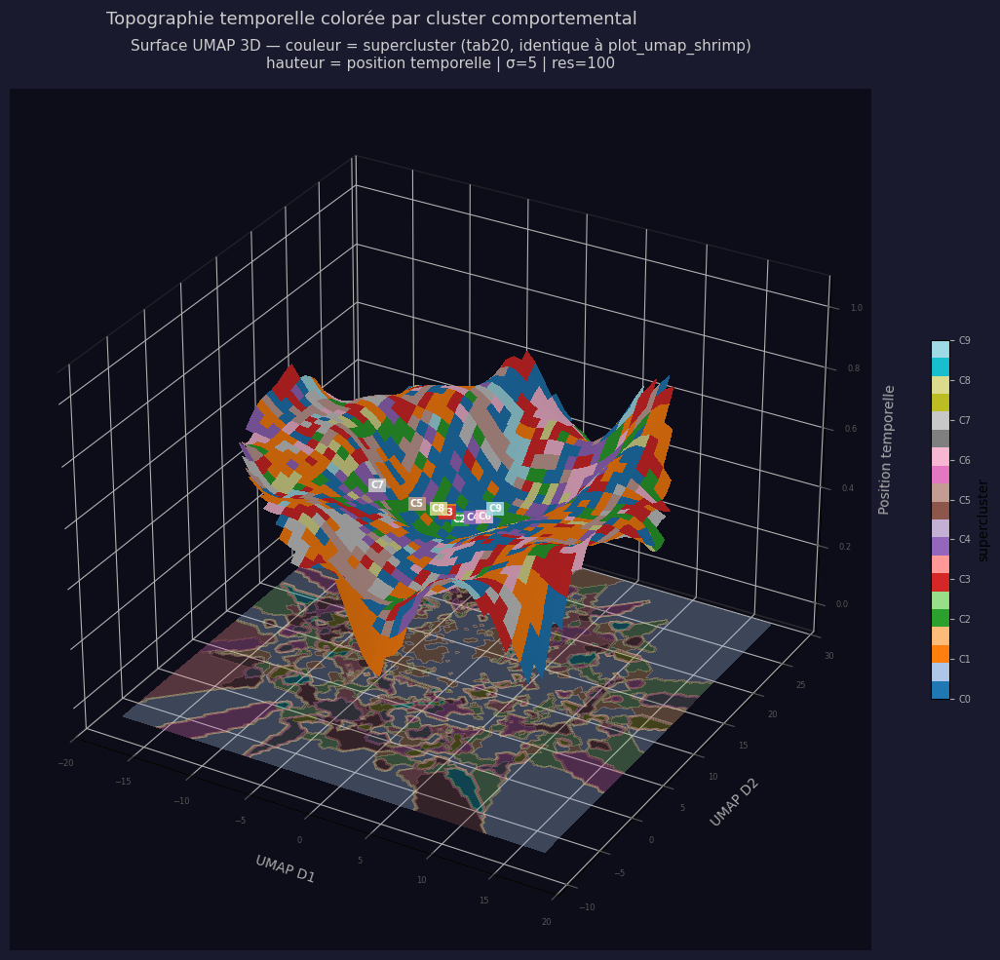

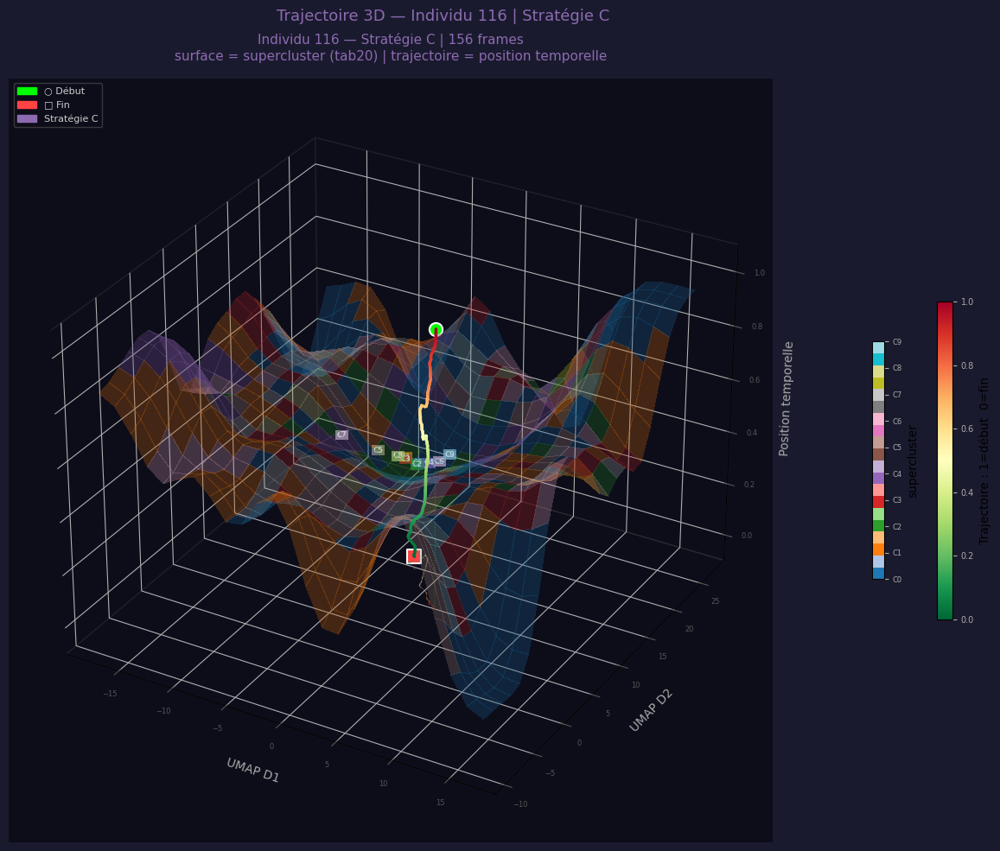

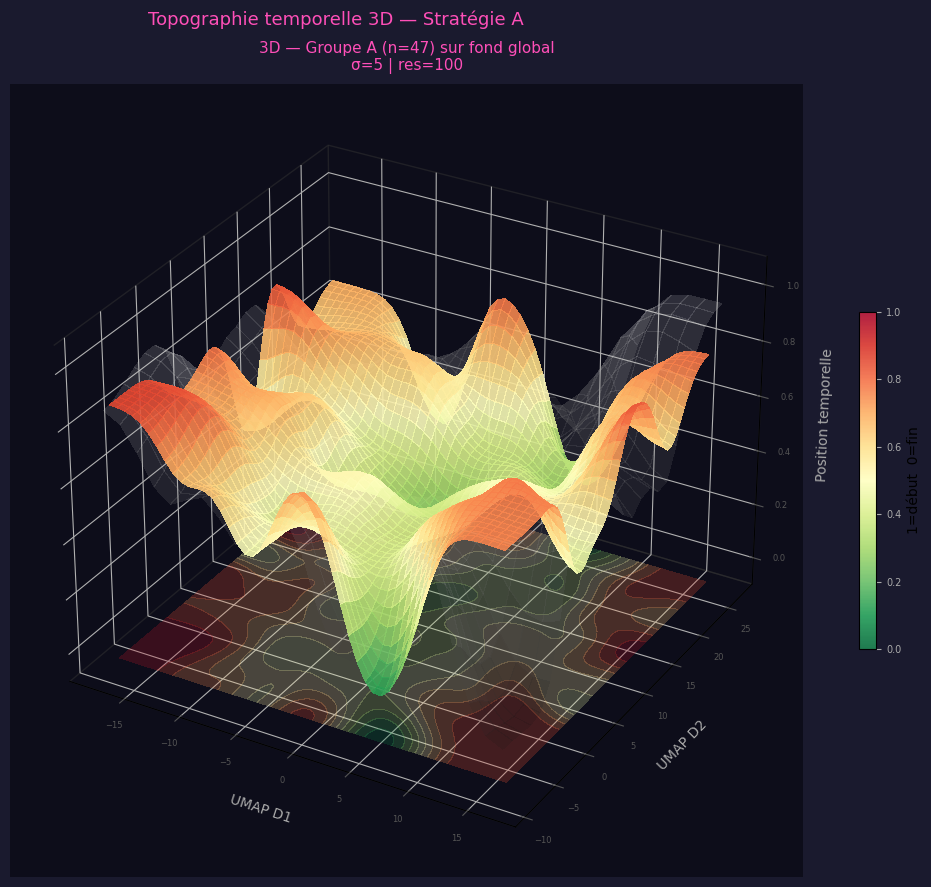

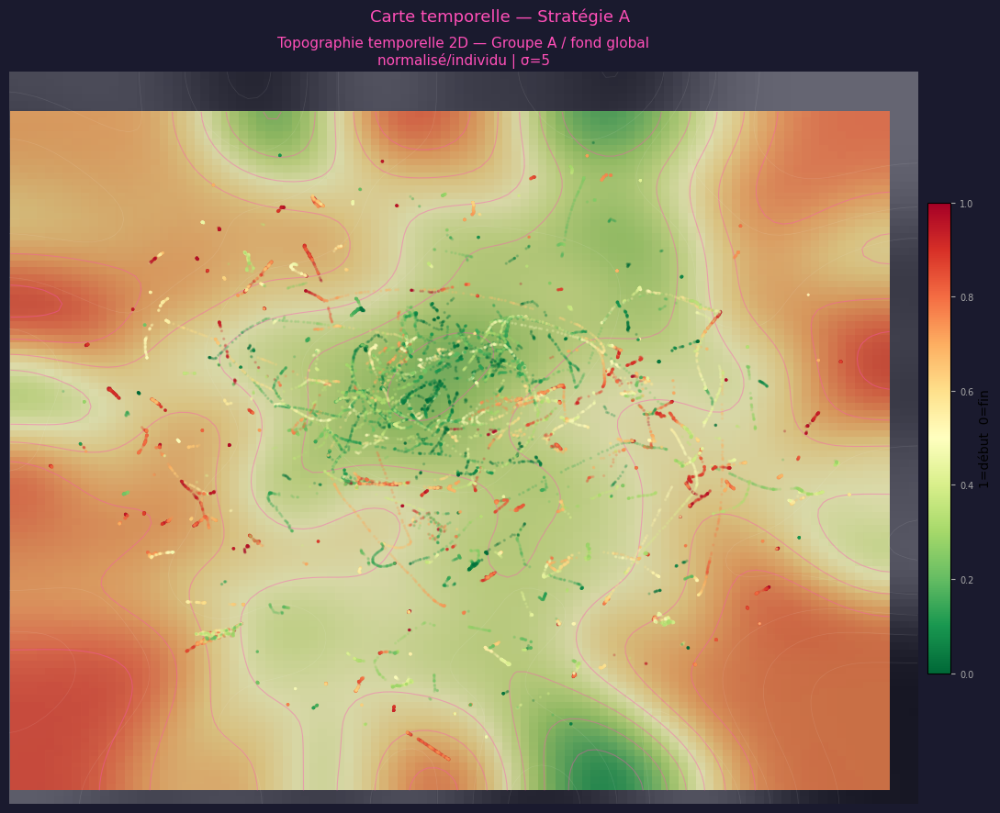

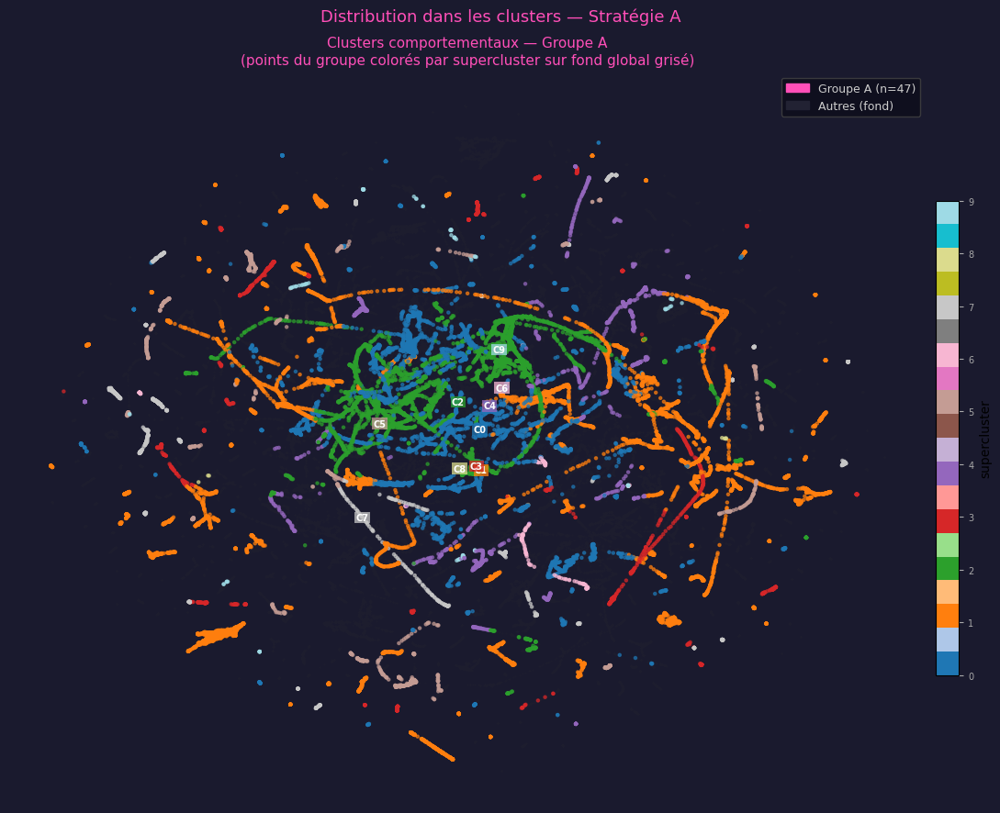

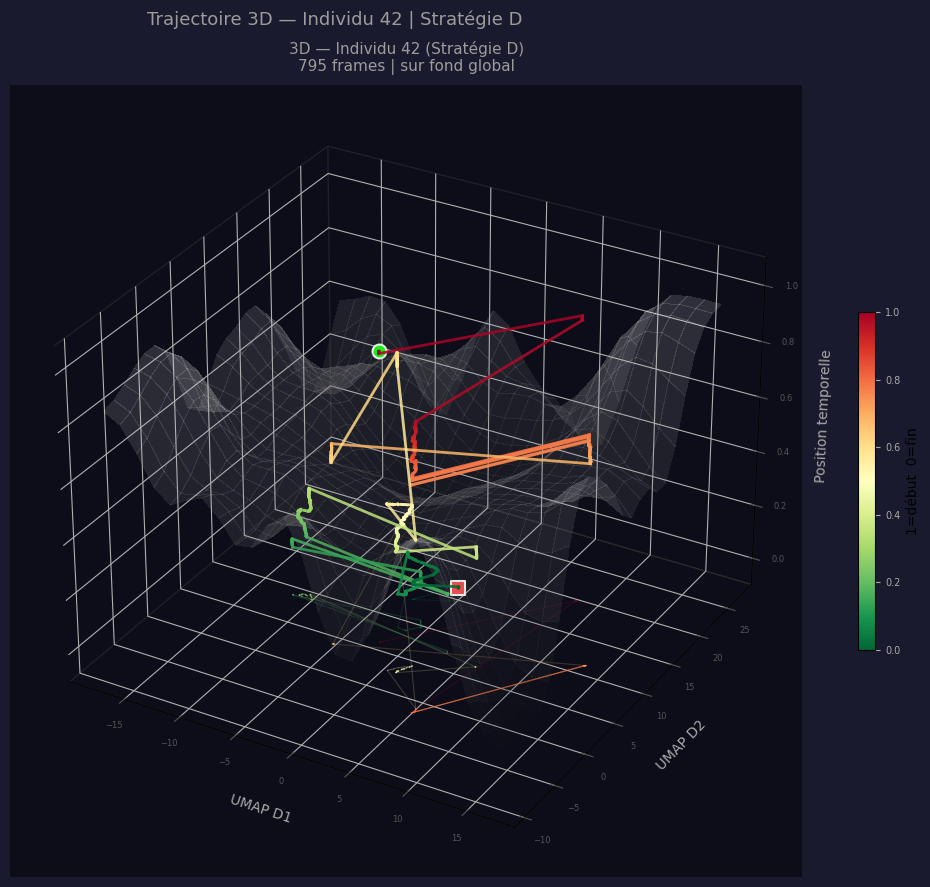

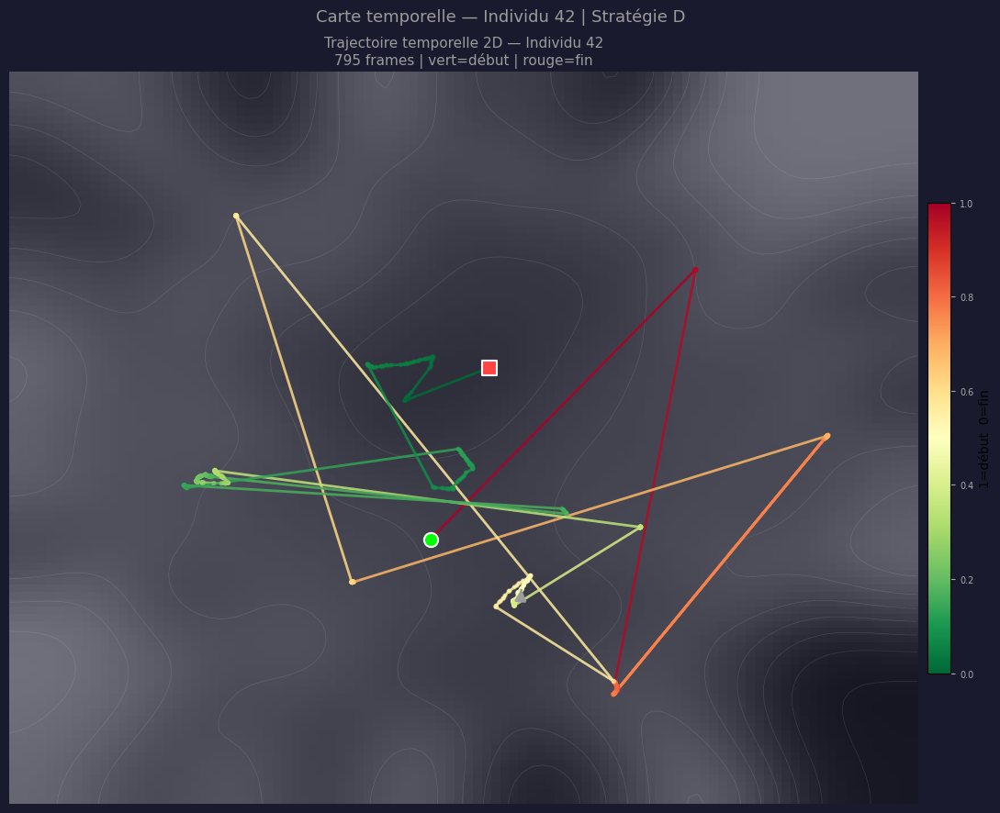

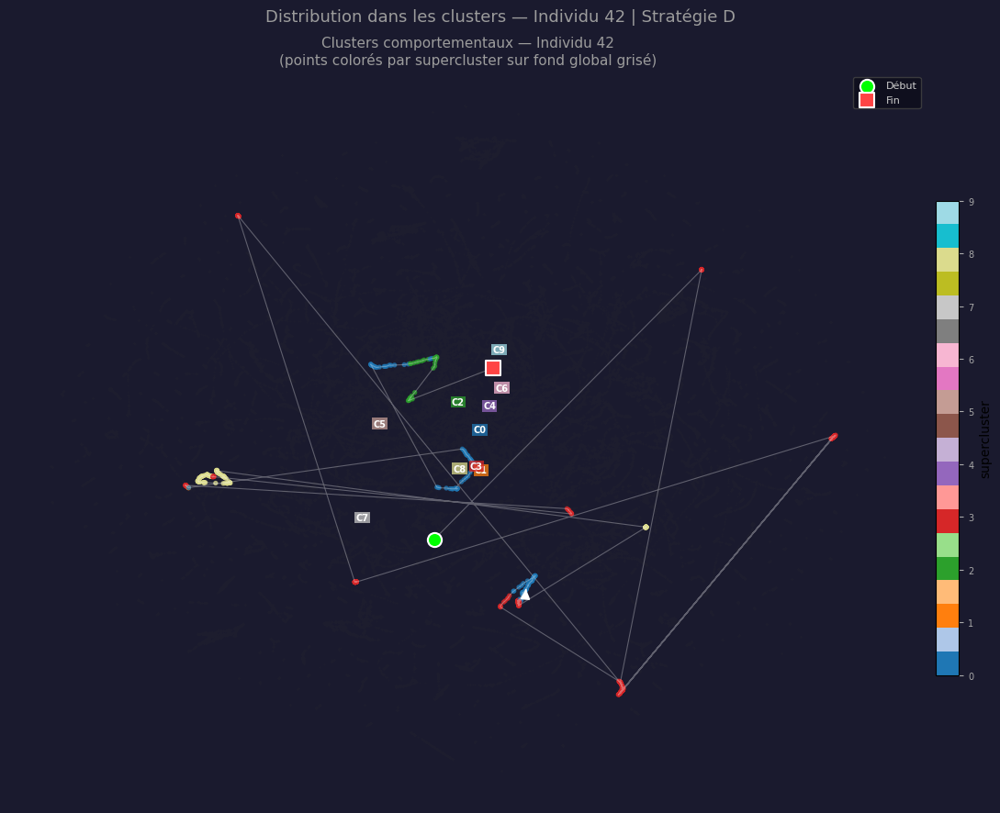

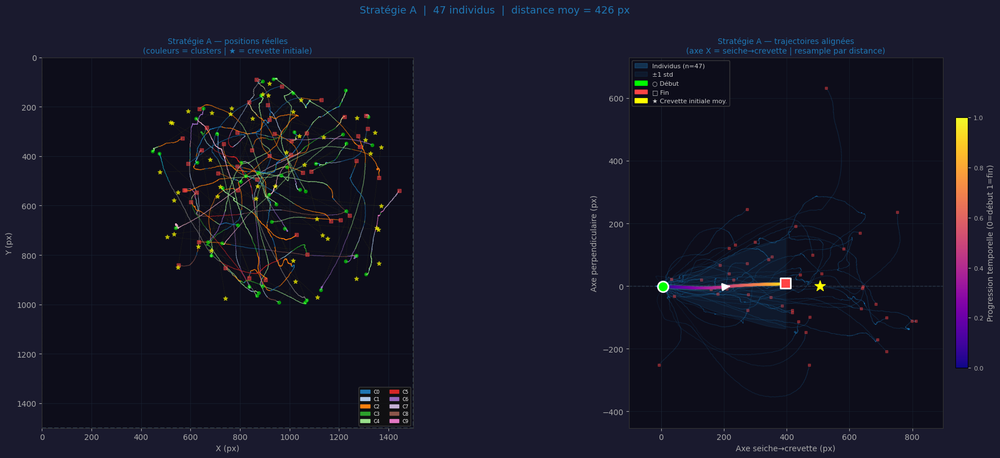

[STRAT B] 29 individus | distance moy = 215 px


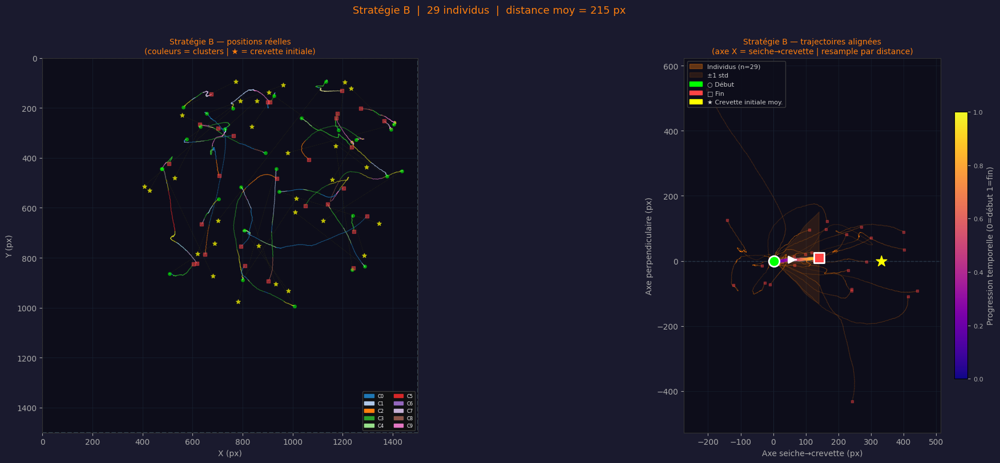

[STRAT C] 38 individus | distance moy = 137 px


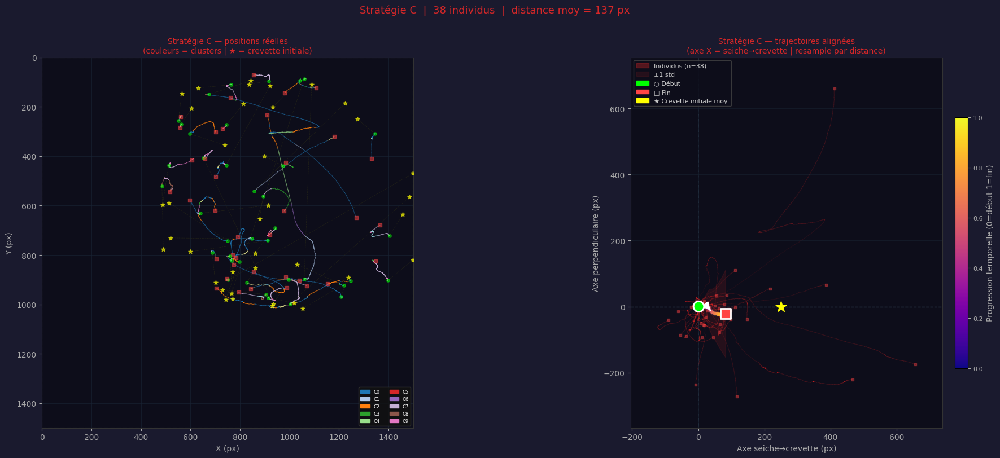

[STRAT D] 18 individus | distance moy = 395 px


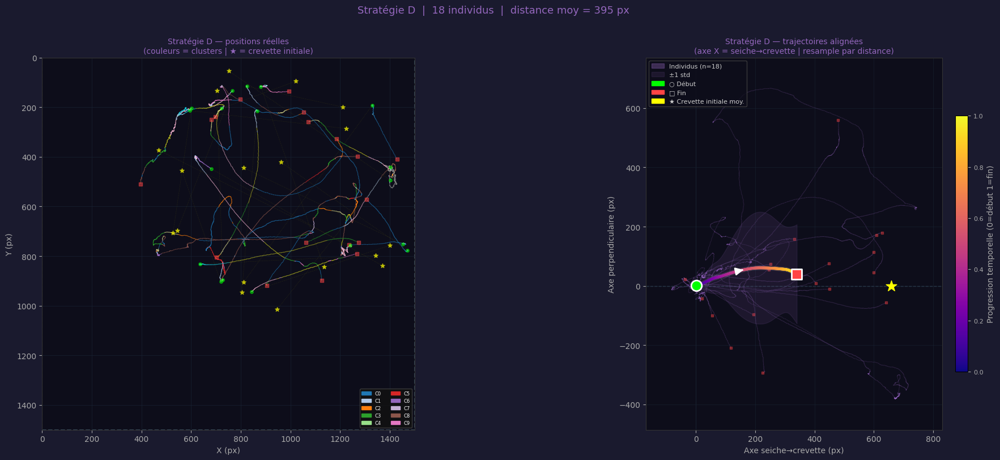

[STRAT E] 16 individus | distance moy = 83 px


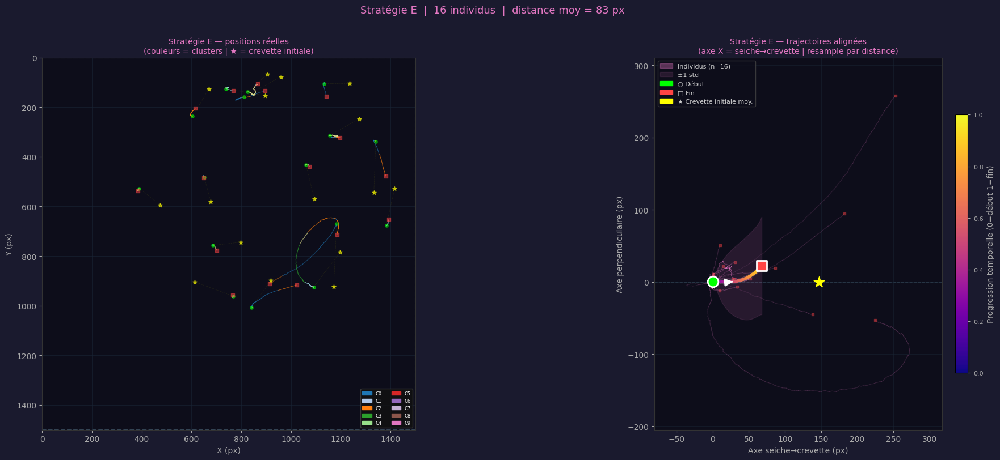

[STRAT F] 29 individus | distance moy = 161 px


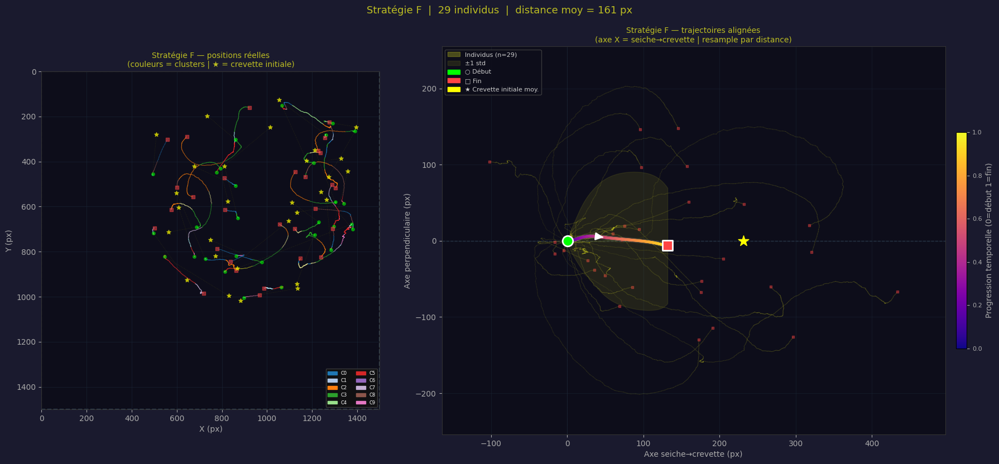

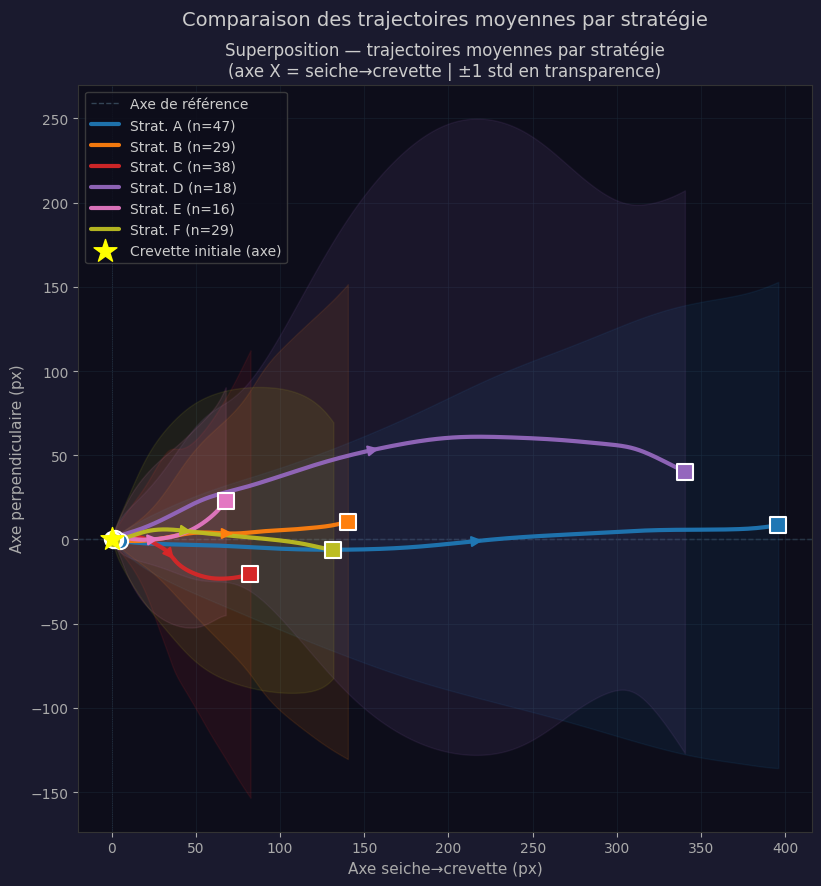

In [37]:
import matplotlib

plot_strategy_trajectories_arena_shrimp(
    df_shrimp=df_shrimp,
    mapping_letters_shrimp=mapping_letters_shrimp,
    strategies_to_plot=None,
    arena_size=1500,
    smooth_mean=True,
    sigma_mean=15,
    align_on="shrimp"
)

[OK] 177 individus | stratégies : ['A', 'B', 'C', 'D', 'E', 'F']
[OK] 168 individus après fusion | 6 stratégies : ['A', 'B', 'C', 'D', 'E', 'F']


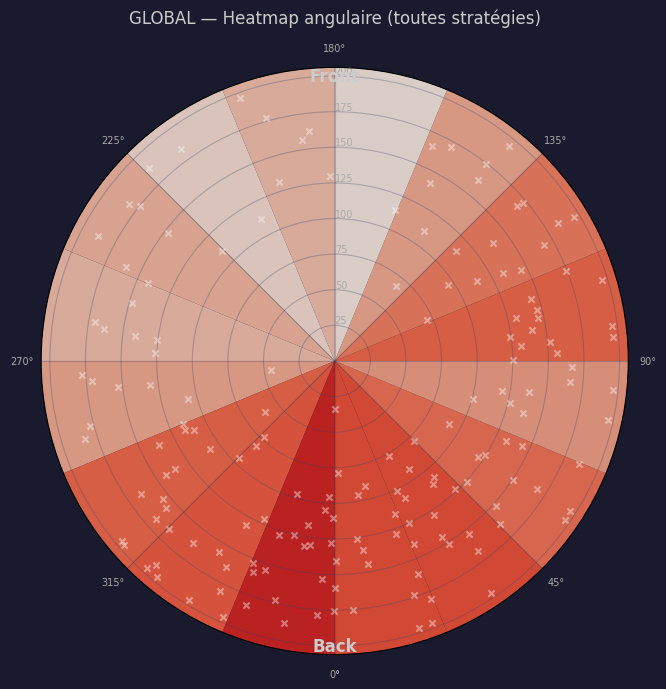

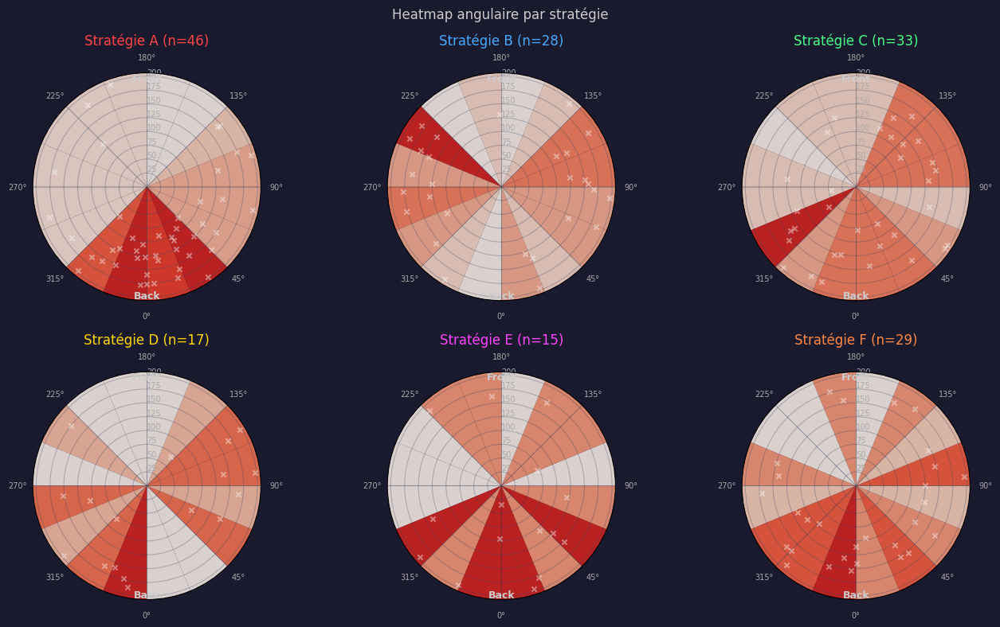

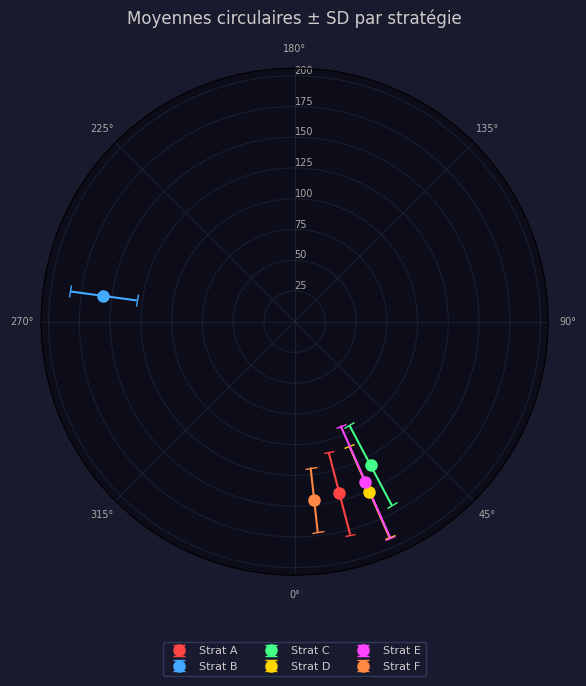

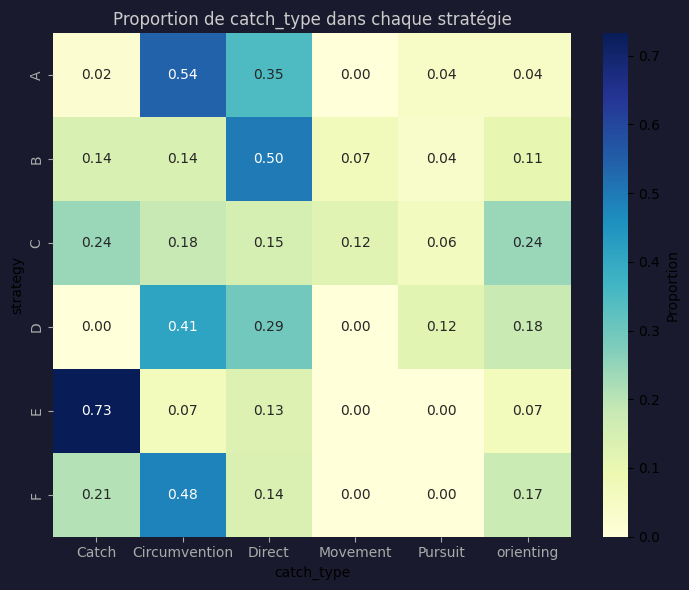

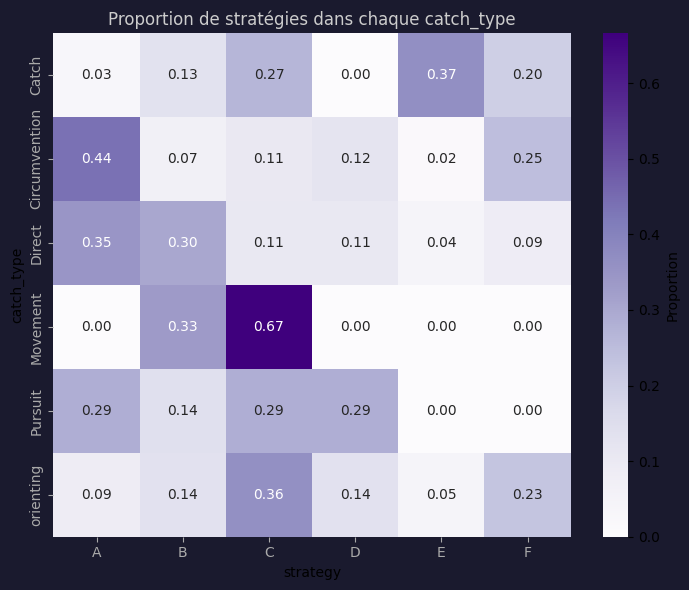


[OK] Graphes KDR...
  Après merge : 203 lignes
  Matchés avec strategy : 168
  167 individus valides | stratégies : ['A', 'B', 'C', 'D', 'E', 'F']


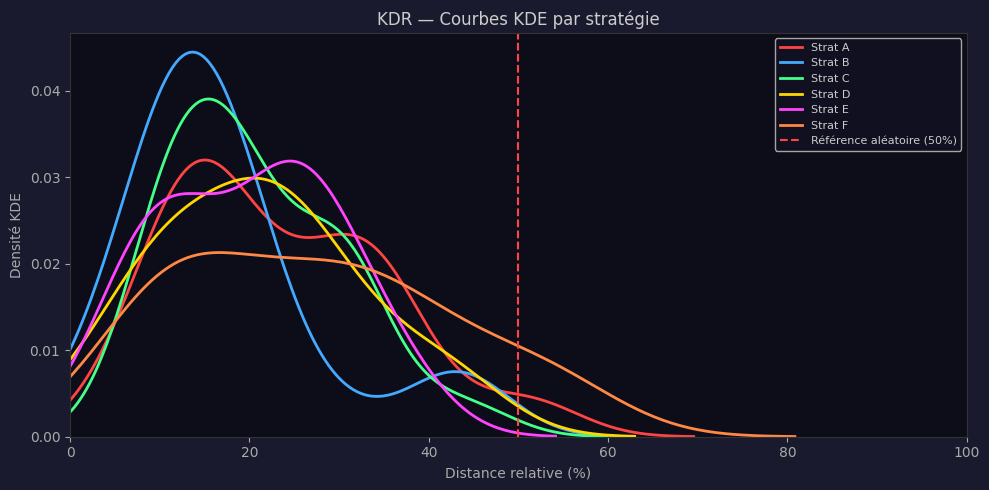

C:\Users\nonoh\AppData\Local\Temp\ipykernel_48580\2401574734.py:338: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="strategy", y="distance_relative", data=df_hit_shrimp,
C:\Users\nonoh\AppData\Local\Temp\ipykernel_48580\2401574734.py:345: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f"Strat {s}" for s in strats_hit], color="#aaaaaa")


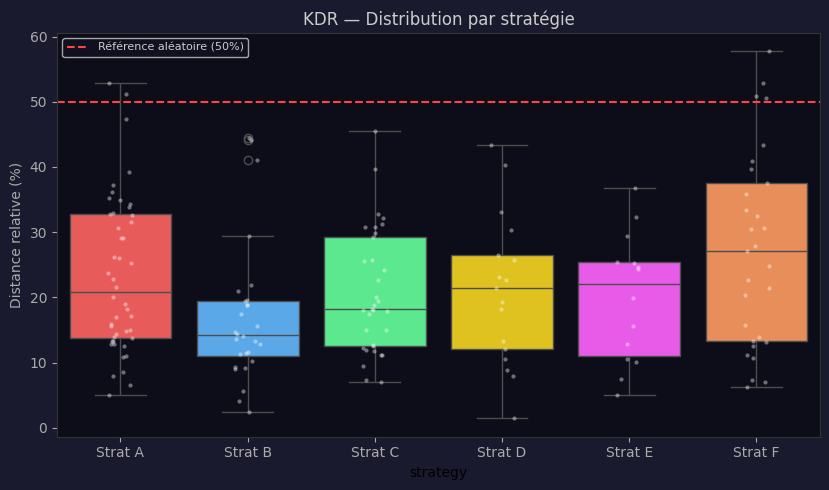

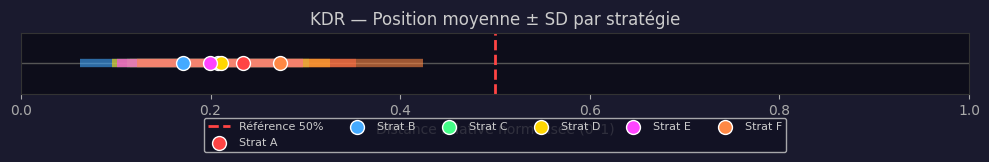

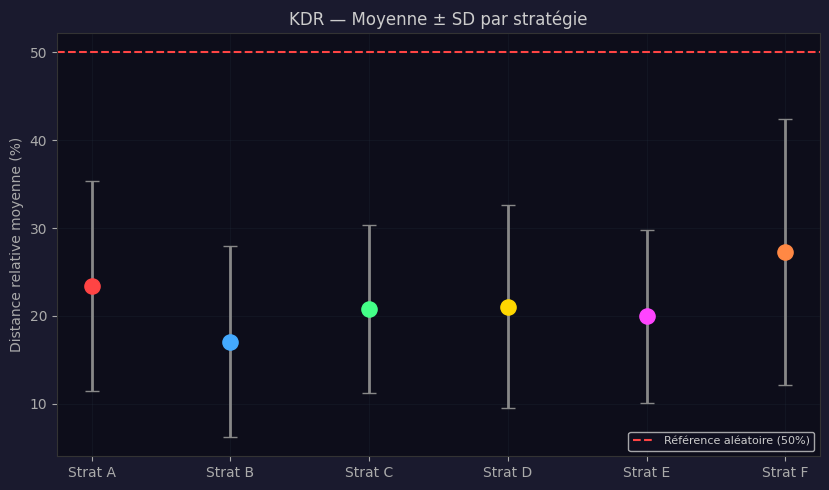

In [38]:
# ══════════════════════════════════════════════════════════════
#  GRAPHES POLAIRES + KDR — version notebook inline
# ══════════════════════════════════════════════════════════════

%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# ── Paramètres ────────────────────────────────────────────────
COMPARATIVE_DATA_PATH = r"E:\01_Travail\CREC\First_Capture\analyse\Data_cuttlfish_strike_complet.xlsx"
HIT_DATA_PATH         = r""   # ← renseigner si fichier hit disponible

DIST_COL  = "Distance_strike_px"
ANGLE_COL = "angle_strike_360"
CATCH_COL = "catch_type"
NBINS     = 16
CAP_PCT   = 0.90

# ── Construire df_summary_shrimp depuis mapping_optimal_shrimp ──────────────
df_summary_shrimp = pd.DataFrame([
    {"ID": int(aid), "strategy": g}
    for aid, g in mapping_optimal_shrimp.items()
    if g != "MONO"
])
print(f"[OK] {len(df_summary_shrimp)} individus | "
      f"stratégies : {sorted(df_summary_shrimp['strategy'].unique())}")

# ── Chargement + fusion ───────────────────────────────────────
df_data   = pd.read_excel(COMPARATIVE_DATA_PATH)
df_merged_shrimp = df_data.merge(
    df_summary_shrimp[["ID","strategy"]],
    left_on="video_id", right_on="ID", how="inner"
).dropna(subset=["strategy"])

strategies = sorted(df_merged_shrimp["strategy"].unique())
n_strat    = len(strategies)
print(f"[OK] {len(df_merged_shrimp)} individus après fusion | "
      f"{n_strat} stratégies : {strategies}")

# Palette cohérente avec le notebook
pal_strat_shrimp = {s: STRATEGY_PALETTE_SHRIMP[i % len(STRATEGY_PALETTE_SHRIMP)]
             for i, s in enumerate(strategies)}

def _hex_rgb(h):
    h = h.lstrip("#")
    return tuple(int(h[i:i+2],16)/255 for i in (0,2,4))

def _theta(series):
    return np.deg2rad(series % 360)

def _setup_polar(ax, r_lim):
    ax.set_theta_zero_location("S")
    ax.set_theta_direction(1)
    ax.set_ylim(0, r_lim)
    ax.grid(alpha=0.3, color="#334466")
    ax.set_rlabel_position(180)
    ax.tick_params(labelsize=7, colors="#aaaaaa")
    ax.set_facecolor("#0d0d1a")

def _draw_density(ax, theta_vals, nbins, r_lim):
    hist, edges = np.histogram(theta_vals, bins=nbins, range=(0, 2*np.pi))
    norm = hist / hist.max() if hist.max() > 0 else hist
    cmap = plt.cm.Reds
    for left, width, h in zip(edges[:-1], np.diff(edges), norm):
        ax.bar(left, r_lim, width=width, bottom=0.0,
               color=cmap(h*0.7), edgecolor="none",
               align="edge", alpha=0.85)

def _circular_mean(angles_rad):
    m = np.arctan2(np.sin(angles_rad).sum(), np.cos(angles_rad).sum())
    return m if m >= 0 else m + 2*np.pi


# ════════════════════════════════════════════════════════════
# FIGURE 1 — Polar global
# ════════════════════════════════════════════════════════════
if DIST_COL in df_merged_shrimp.columns and ANGLE_COL in df_merged_shrimp.columns:

    cap_val = df_merged_shrimp[DIST_COL].quantile(CAP_PCT)
    df_merged_shrimp["_dist_plot"] = np.minimum(
        df_merged_shrimp[DIST_COL].astype(float), float(cap_val))
    r_lim_global = df_merged_shrimp["_dist_plot"].max() * 1.05

    fig = plt.figure(figsize=(7,7))
    fig.patch.set_facecolor("#1a1a2e")
    ax  = fig.add_subplot(111, polar=True)
    _setup_polar(ax, r_lim_global)

    theta_all = _theta(df_merged_shrimp[ANGLE_COL].dropna())
    dist_all  = df_merged_shrimp.loc[df_merged_shrimp[ANGLE_COL].notna(), "_dist_plot"]
    _draw_density(ax, theta_all, NBINS, r_lim_global)
    ax.scatter(theta_all, dist_all, marker="x", s=20,
               alpha=0.4, color="white", zorder=2)
    ax.set_title("GLOBAL — Heatmap angulaire (toutes stratégies)",
                 color="#cccccc", pad=14)
    ax.text(0,      r_lim_global, "Back",  fontsize=12,
            fontweight="bold", ha="center", va="bottom", color="#cccccc")
    ax.text(np.pi,  r_lim_global, "Front", fontsize=12,
            fontweight="bold", ha="center", va="top",   color="#cccccc")
    plt.tight_layout(); plt.show()


    # ════════════════════════════════════════════════════════
    # FIGURE 2 — Polar par stratégie
    # ════════════════════════════════════════════════════════
    nc   = min(3, n_strat)
    nr   = int(np.ceil(n_strat / nc))
    fig, axes = plt.subplots(nr, nc, subplot_kw=dict(polar=True),
                              figsize=(nc*4.5, nr*4))
    fig.patch.set_facecolor("#1a1a2e")
    fig.suptitle("Heatmap angulaire par stratégie",
                 color="#cccccc", fontsize=12)
    axes_flat = np.array(axes).flatten() if nr*nc > 1 else [axes]

    for i, strat in enumerate(strategies):
        ax  = axes_flat[i]
        sub = df_merged_shrimp[df_merged_shrimp["strategy"]==strat
                        ].dropna(subset=[ANGLE_COL])
        r_lim_s = sub["_dist_plot"].max()*1.05 if len(sub) else 1.0
        _setup_polar(ax, r_lim_s)
        if len(sub):
            th = _theta(sub[ANGLE_COL])
            _draw_density(ax, th, NBINS, r_lim_s)
            ax.scatter(th, sub["_dist_plot"], marker="x", s=20,
                       alpha=0.4, color="white", zorder=2)
            ax.text(0,     r_lim_s, "Back",  fontsize=9,
                    fontweight="bold", ha="center", va="bottom",
                    color="#cccccc")
            ax.text(np.pi, r_lim_s, "Front", fontsize=9,
                    fontweight="bold", ha="center", va="top",
                    color="#cccccc")
        ax.set_title(f"Stratégie {strat} (n={len(sub)})",
                     color=pal_strat_shrimp.get(strat,"#ffffff"), pad=8)

    for j in range(n_strat, len(axes_flat)):
        axes_flat[j].set_visible(False)
    plt.tight_layout(); plt.show()


    # ════════════════════════════════════════════════════════
    # FIGURE 3 — Moyennes circulaires ± SD
    # ════════════════════════════════════════════════════════
    fig = plt.figure(figsize=(7,7))
    fig.patch.set_facecolor("#1a1a2e")
    ax  = fig.add_subplot(111, polar=True)
    _setup_polar(ax, r_lim_global)

    for strat in strategies:
        sub = df_merged_shrimp[df_merged_shrimp["strategy"]==strat
                        ].dropna(subset=[ANGLE_COL,"_dist_plot"])
        if len(sub) == 0: continue
        theta_mean = _circular_mean(np.deg2rad(sub[ANGLE_COL]))
        r_mean     = sub["_dist_plot"].mean()
        r_std      = sub["_dist_plot"].std()
        col_s      = _hex_rgb(pal_strat_shrimp.get(strat,"#ffffff"))
        ax.errorbar(theta_mean, r_mean, yerr=r_std, fmt="o",
                    color=col_s, capsize=4, markersize=8,
                    label=f"Strat {strat}")

    ax.set_title("Moyennes circulaires ± SD par stratégie",
                 color="#cccccc", pad=14)
    leg = ax.legend(loc="upper center", bbox_to_anchor=(0.5,-0.12),
                    ncol=3, fontsize=8)
    leg.get_frame().set_facecolor("#1a1a2e")
    leg.get_frame().set_edgecolor("#334466")
    for t in leg.get_texts(): t.set_color("#cccccc")
    plt.tight_layout(); plt.show()

    df_merged_shrimp.drop(columns=["_dist_plot"], inplace=True)


    # ════════════════════════════════════════════════════════
    # FIGURE 4 — Heatmaps catch_type × stratégie
    # ════════════════════════════════════════════════════════
    catch_col_found = None
    for c in ["catch_type", "catch_type_redefined", "catch_type_found",
               "Catch_type"]:
        if c in df_merged_shrimp.columns:
            catch_col_found = c
            break

    if catch_col_found:
        df_counts = (
            df_merged_shrimp.dropna(subset=[catch_col_found,"strategy"])
            .groupby(["strategy", catch_col_found])
            .size().reset_index(name="count")
        )

        # Proportion catch dans stratégie
        df_pc         = df_counts.copy()
        df_pc["prop"] = (df_pc["count"] /
                         df_pc.groupby("strategy")["count"].transform("sum"))
        pivot = df_pc.pivot(index="strategy", columns=catch_col_found,
                            values="prop").fillna(0)

        fig, ax = plt.subplots(
            figsize=(max(6, len(pivot.columns)*1.2), max(4, len(pivot))))
        fig.patch.set_facecolor("#1a1a2e")
        ax.set_facecolor("#0d0d1a")
        sns.heatmap(pivot, annot=True, fmt=".2f", cmap="YlGnBu", ax=ax,
                    cbar_kws={"label":"Proportion"})
        ax.set_title("Proportion de catch_type dans chaque stratégie",
                     color="#cccccc")
        ax.tick_params(colors="#aaaaaa")
        plt.tight_layout(); plt.show()

        # Proportion stratégie dans catch
        df_ps         = df_counts.copy()
        df_ps["prop"] = (df_ps["count"] /
                         df_ps.groupby(catch_col_found)["count"].transform("sum"))
        pivot2 = df_ps.pivot(index=catch_col_found, columns="strategy",
                             values="prop").fillna(0)

        fig, ax = plt.subplots(
            figsize=(max(6, len(pivot2.columns)*1.2), max(4, len(pivot2))))
        fig.patch.set_facecolor("#1a1a2e")
        ax.set_facecolor("#0d0d1a")
        sns.heatmap(pivot2, annot=True, fmt=".2f", cmap="Purples", ax=ax,
                    cbar_kws={"label":"Proportion"})
        ax.set_title("Proportion de stratégies dans chaque catch_type",
                     color="#cccccc")
        ax.tick_params(colors="#aaaaaa")
        plt.tight_layout(); plt.show()
    else:
        print("[SKIP] Aucune colonne catch_type trouvée")

else:
    print(f"[SKIP] Colonnes absentes : {DIST_COL} / {ANGLE_COL}")

# ════════════════════════════════════════════════════════
    # FIGURE 4 — Heatmaps pour chaque variante de catch_type
    # ════════════════════════════════════════════════════════
    for catch_col in ["catch_type", "catch_type_redefined", "catch_type_found"]:
        if catch_col not in df_merged_shrimp.columns:
            print(f"[SKIP] {catch_col} absent")
            continue

        df_counts = (
            df_merged_shrimp.dropna(subset=[catch_col, "strategy"])
            .groupby(["strategy", catch_col])
            .size().reset_index(name="count")
        )
        if len(df_counts) == 0:
            print(f"[SKIP] {catch_col} — aucune donnée")
            continue

        # Proportion catch dans stratégie
        df_pc         = df_counts.copy()
        df_pc["prop"] = (df_pc["count"] /
                         df_pc.groupby("strategy")["count"].transform("sum"))
        pivot = df_pc.pivot(index="strategy", columns=catch_col,
                            values="prop").fillna(0)

        fig, ax = plt.subplots(
            figsize=(max(6, len(pivot.columns)*1.2), max(4, len(pivot))))
        fig.patch.set_facecolor("#1a1a2e"); ax.set_facecolor("#0d0d1a")
        sns.heatmap(pivot, annot=True, fmt=".2f", cmap="YlGnBu", ax=ax,
                    cbar_kws={"label":"Proportion"})
        ax.set_title(f"Proportion de {catch_col} dans chaque stratégie",
                     color="#cccccc")
        ax.tick_params(colors="#aaaaaa")
        plt.tight_layout(); plt.show()

        # Proportion stratégie dans catch
        df_ps         = df_counts.copy()
        df_ps["prop"] = (df_ps["count"] /
                         df_ps.groupby(catch_col)["count"].transform("sum"))
        pivot2 = df_ps.pivot(index=catch_col, columns="strategy",
                             values="prop").fillna(0)

        fig, ax = plt.subplots(
            figsize=(max(6, len(pivot2.columns)*1.2), max(4, len(pivot2))))
        fig.patch.set_facecolor("#1a1a2e"); ax.set_facecolor("#0d0d1a")
        sns.heatmap(pivot2, annot=True, fmt=".2f", cmap="Purples", ax=ax,
                    cbar_kws={"label":"Proportion"})
        ax.set_title(f"Proportion de stratégies dans chaque {catch_col}",
                     color="#cccccc")
        ax.tick_params(colors="#aaaaaa")
        plt.tight_layout(); plt.show()

# ════════════════════════════════════════════════════════════
# FIGURE 5-8 — KDR (distance relative du point de frappe)
# ════════════════════════════════════════════════════════════
hit_path = Path(r"E:\01_Travail\CREC\First_Capture\analyse\Classeur1.xlsx")

if hit_path.exists():
    print("\n[OK] Graphes KDR...")
    df_hit_shrimp = pd.read_excel(hit_path)

    # Merge sur video → video_id pour récupérer Length_Shrimp + strategy
    df_hit_shrimp = df_hit_shrimp.merge(
        df_merged_shrimp[["video_id", "Length_Shrimp", "strategy"]],
        left_on="video", right_on="video_id", how="left"
    )

    print(f"  Après merge : {len(df_hit_shrimp)} lignes")
    print(f"  Matchés avec strategy : {df_hit_shrimp['strategy'].notna().sum()}")

    df_hit_shrimp["distance_relative"] = (
        df_hit_shrimp["distance_yeux_tentacule"].astype(float) /
        df_hit_shrimp["Length_Shrimp"].astype(float)
    ) * 100

    df_hit_shrimp     = df_hit_shrimp.dropna(subset=["distance_relative","strategy"])
    strats_hit = sorted(df_hit_shrimp["strategy"].unique())
    print(f"  {len(df_hit_shrimp)} individus valides | stratégies : {strats_hit}")

    # ── KDE global ───────────────────────────────────────────
    fig, ax = plt.subplots(figsize=(10, 5))
    fig.patch.set_facecolor("#1a1a2e"); ax.set_facecolor("#0d0d1a")
    for sp in ax.spines.values(): sp.set_edgecolor("#333333")
    for strat in strats_hit:
        sub   = df_hit_shrimp[df_hit_shrimp["strategy"]==strat]["distance_relative"]
        col_s = _hex_rgb(pal_strat_shrimp.get(strat,"#ffffff"))
        sns.kdeplot(sub, ax=ax, fill=False, lw=2,
                    color=col_s, label=f"Strat {strat}")
    ax.axvline(50, color="#ff4444", lw=1.5, ls="--",
               label="Référence aléatoire (50%)")
    ax.set_xlim(0, 100)
    ax.set_xlabel("Distance relative (%)", color="#aaaaaa")
    ax.set_ylabel("Densité KDE",           color="#aaaaaa")
    ax.set_title("KDR — Courbes KDE par stratégie", color="#cccccc")
    ax.tick_params(colors="#aaaaaa")
    leg = ax.legend(fontsize=8)
    leg.get_frame().set_facecolor("#111122")
    for t in leg.get_texts(): t.set_color("#cccccc")
    plt.tight_layout(); plt.show()

    # ── Boxplot KDR ───────────────────────────────────────────
    fig, ax = plt.subplots(figsize=(max(8, len(strats_hit)*1.4), 5))
    fig.patch.set_facecolor("#1a1a2e"); ax.set_facecolor("#0d0d1a")
    for sp in ax.spines.values(): sp.set_edgecolor("#333333")
    pal_hit = {s: pal_strat_shrimp.get(s,"#888888") for s in strats_hit}
    sns.boxplot(x="strategy", y="distance_relative", data=df_hit_shrimp,
                order=strats_hit, palette=pal_hit, ax=ax)
    sns.stripplot(x="strategy", y="distance_relative", data=df_hit_shrimp,
                  order=strats_hit, color="white",
                  alpha=0.4, size=3, ax=ax)
    ax.axhline(50, color="#ff4444", ls="--", lw=1.5,
               label="Référence aléatoire (50%)")
    ax.set_xticklabels([f"Strat {s}" for s in strats_hit], color="#aaaaaa")
    ax.set_title("KDR — Distribution par stratégie", color="#cccccc")
    ax.set_ylabel("Distance relative (%)", color="#aaaaaa")
    ax.tick_params(colors="#aaaaaa")
    leg = ax.legend(fontsize=8)
    leg.get_frame().set_facecolor("#111122")
    for t in leg.get_texts(): t.set_color("#cccccc")
    plt.tight_layout(); plt.show()

    # ── Moyenne ± SD ligne horizontale ────────────────────────
    means      = [df_hit_shrimp[df_hit_shrimp["strategy"]==s]["distance_relative"].mean()
                  for s in strats_hit]
    stds       = [df_hit_shrimp[df_hit_shrimp["strategy"]==s]["distance_relative"].std()
                  for s in strats_hit]
    means_norm = np.array(means)/100
    stds_norm  = np.array(stds)/100

    fig, ax = plt.subplots(figsize=(10, 2))
    fig.patch.set_facecolor("#1a1a2e"); ax.set_facecolor("#0d0d1a")
    ax.plot([0,1],[0,0], color="#555555", lw=1)
    ax.axvline(0.5, color="#ff4444", ls="--", lw=2, label="Référence 50%")
    for i, strat in enumerate(strats_hit):
        m, s  = means_norm[i], stds_norm[i]
        col_s = _hex_rgb(pal_strat_shrimp.get(strat,"#888888"))
        ax.hlines(0, m-s, m+s, color=col_s, lw=6, alpha=0.6)
        ax.scatter(m, 0, color=col_s, s=100,
                   edgecolor="white", zorder=3, label=f"Strat {strat}")
    ax.set_yticks([])
    ax.set_xlim(0, 1)
    ax.set_xlabel("Distance relative normalisée (0–1)", color="#aaaaaa")
    ax.set_title("KDR — Position moyenne ± SD par stratégie", color="#cccccc")
    ax.tick_params(colors="#aaaaaa")
    for sp in ax.spines.values(): sp.set_edgecolor("#333333")
    leg = ax.legend(loc="upper center", bbox_to_anchor=(0.5,-0.3),
                    ncol=len(strats_hit), fontsize=8)
    leg.get_frame().set_facecolor("#111122")
    for t in leg.get_texts(): t.set_color("#cccccc")
    plt.tight_layout(); plt.show()

    # ── Moyenne ± SD errorbar ─────────────────────────────────
    x   = np.arange(len(strats_hit))
    fig, ax = plt.subplots(figsize=(max(8, len(strats_hit)*1.4), 5))
    fig.patch.set_facecolor("#1a1a2e"); ax.set_facecolor("#0d0d1a")
    for sp in ax.spines.values(): sp.set_edgecolor("#333333")
    ax.errorbar(x, means, yerr=stds, fmt="o", markersize=8,
                capsize=5, color="white", ecolor="#888888", elinewidth=2)
    for i, strat in enumerate(strats_hit):
        col_s = _hex_rgb(pal_strat_shrimp.get(strat,"#888888"))
        ax.scatter(x[i], means[i], color=col_s, s=120, zorder=3)
    ax.axhline(50, color="#ff4444", ls="--", lw=1.5,
               label="Référence aléatoire (50%)")
    ax.set_xticks(x)
    ax.set_xticklabels([f"Strat {s}" for s in strats_hit], color="#aaaaaa")
    ax.set_ylabel("Distance relative moyenne (%)", color="#aaaaaa")
    ax.set_title("KDR — Moyenne ± SD par stratégie", color="#cccccc")
    ax.tick_params(colors="#aaaaaa")
    ax.grid(alpha=0.15, color="#334455")
    leg = ax.legend(fontsize=8)
    leg.get_frame().set_facecolor("#111122")
    for t in leg.get_texts(): t.set_color("#cccccc")
    plt.tight_layout(); plt.show()

else:
    print(f"[SKIP] Fichier hit introuvable : {hit_path}")


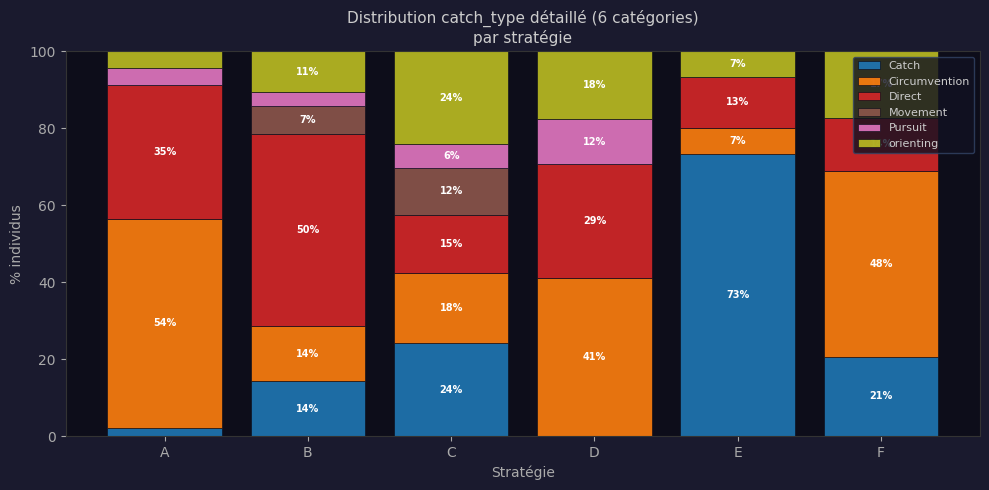

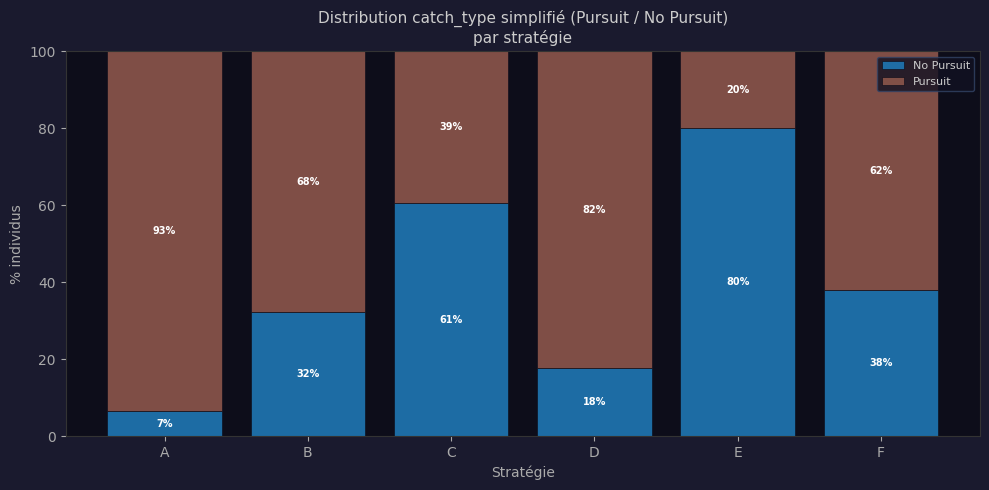

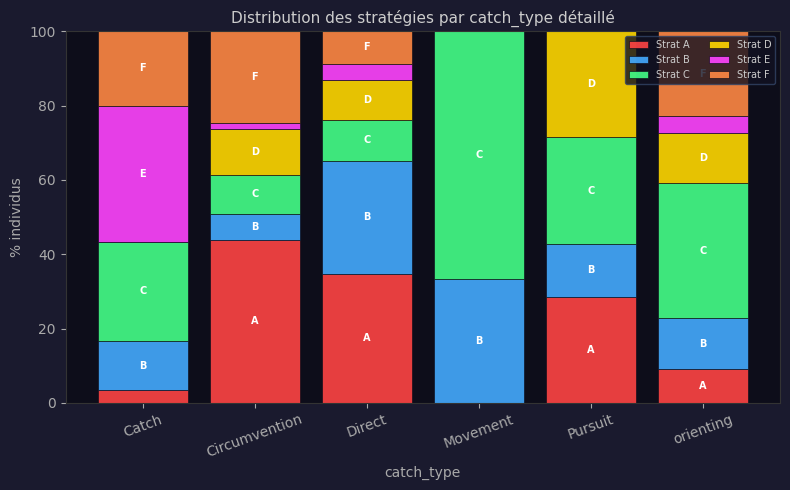

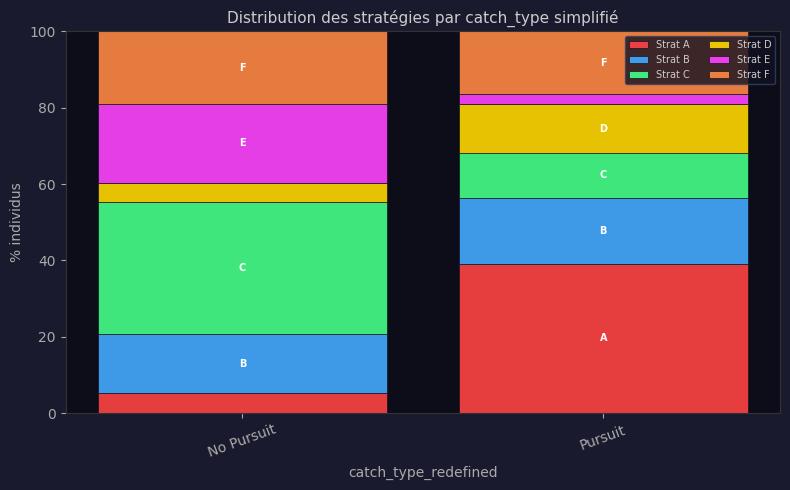

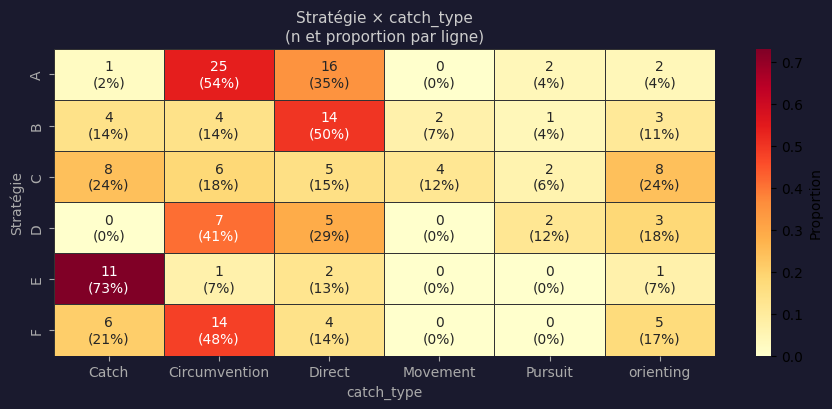

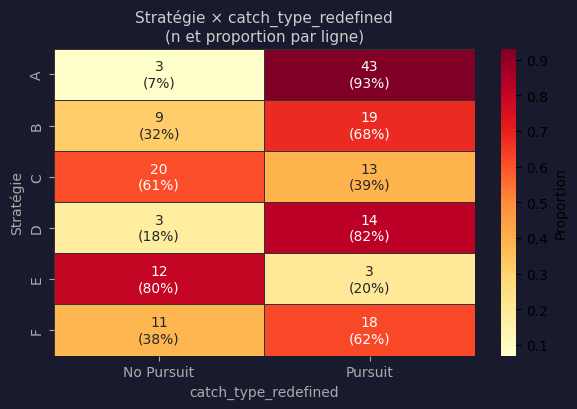


Chi² (catch détaillé) : χ²=87.02  p=0.0000  ddl=25
  *** p < 0.001 — association très significative


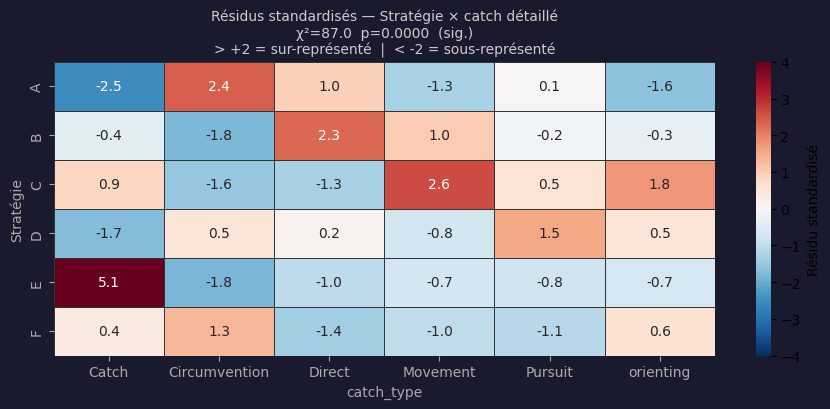


Chi² (Pursuit/No Pursuit) : χ²=41.97  p=0.0000  ddl=5
  *** p < 0.001 — association très significative


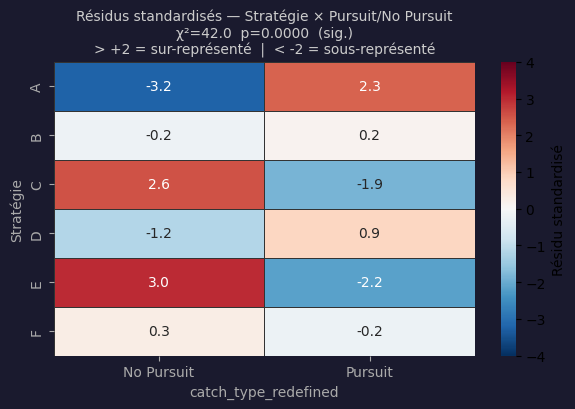

In [39]:
# ════════════════════════════════════════════════════════════
#  COMPARAISON CATCH TYPE × STRATÉGIE
# ════════════════════════════════════════════════════════════

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, fisher_exact
from itertools import combinations

fig_bg  = "#1a1a2e"
ax_bg   = "#0d0d1a"
txt_col = "#cccccc"

def _style(ax):
    ax.set_facecolor(ax_bg)
    for sp in ax.spines.values(): sp.set_edgecolor("#333333")
    ax.tick_params(colors="#aaaaaa")

# ════════════════════════════════════════════════════════════
# FIGURE 1 — Distribution des catch_type par stratégie
#            (barres empilées normalisées)
# ════════════════════════════════════════════════════════════
for catch_col, title_suffix in [
    ("catch_type",          "détaillé (6 catégories)"),
    ("catch_type_redefined","simplifié (Pursuit / No Pursuit)"),
]:
    ct = pd.crosstab(df_merged_shrimp["strategy"], df_merged_shrimp[catch_col],
                     normalize="index") * 100

    fig, ax = plt.subplots(figsize=(max(10, len(ct)*0.9), 5))
    fig.patch.set_facecolor(fig_bg); _style(ax)

    bottom = np.zeros(len(ct))
    cats   = ct.columns.tolist()
    cmap   = plt.cm.tab10

    for i, cat in enumerate(cats):
        vals = ct[cat].values
        bars = ax.bar(ct.index, vals, bottom=bottom,
                      color=cmap(i/len(cats)), label=cat,
                      edgecolor="#0d0d1a", lw=0.5, alpha=0.9)
        # Label si assez large
        for j, (v, b) in enumerate(zip(vals, bottom)):
            if v > 5:
                ax.text(j, b + v/2, f"{v:.0f}%",
                        ha="center", va="center",
                        fontsize=7, color="white", fontweight="bold")
        bottom += vals

    ax.set_ylim(0, 100)
    ax.set_ylabel("% individus", color="#aaaaaa")
    ax.set_xlabel("Stratégie",   color="#aaaaaa")
    ax.set_title(f"Distribution catch_type {title_suffix}\npar stratégie",
                 color=txt_col, fontsize=11)
    ax.tick_params(axis="x", colors="#aaaaaa")
    ax.tick_params(axis="y", colors="#aaaaaa")
    leg = ax.legend(loc="upper right", fontsize=8,
                    facecolor="#111122", edgecolor="#334466")
    for t in leg.get_texts(): t.set_color(txt_col)
    plt.tight_layout(); plt.show()


# ════════════════════════════════════════════════════════════
# FIGURE 2 — Distribution des stratégies par catch_type
#            (inverse : qui fait quoi ?)
# ════════════════════════════════════════════════════════════
for catch_col, title_suffix in [
    ("catch_type",          "détaillé"),
    ("catch_type_redefined","simplifié"),
]:
    ct = pd.crosstab(df_merged_shrimp[catch_col], df_merged_shrimp["strategy"],
                     normalize="index") * 100

    fig, ax = plt.subplots(figsize=(max(8, len(ct)*1.2), 5))
    fig.patch.set_facecolor(fig_bg); _style(ax)

    bottom = np.zeros(len(ct))
    for i, strat in enumerate(ct.columns):
        vals = ct[strat].values
        col_s = pal_strat_shrimp.get(strat, "#888888")
        r,g,b = tuple(int(col_s.lstrip("#")[j:j+2],16)/255 for j in (0,2,4))
        ax.bar(ct.index, vals, bottom=bottom,
               color=(r,g,b), label=f"Strat {strat}",
               edgecolor="#0d0d1a", lw=0.5, alpha=0.9)
        for j, (v, b) in enumerate(zip(vals, bottom)):
            if v > 6:
                ax.text(j, b + v/2, strat,
                        ha="center", va="center",
                        fontsize=7, color="white", fontweight="bold")
        bottom += vals

    ax.set_ylim(0, 100)
    ax.set_ylabel("% individus", color="#aaaaaa")
    ax.set_xlabel(catch_col,     color="#aaaaaa")
    ax.set_title(f"Distribution des stratégies par catch_type {title_suffix}",
                 color=txt_col, fontsize=11)
    ax.tick_params(axis="x", colors="#aaaaaa", rotation=20)
    ax.tick_params(axis="y", colors="#aaaaaa")
    leg = ax.legend(loc="upper right", fontsize=7, ncol=2,
                    facecolor="#111122", edgecolor="#334466")
    for t in leg.get_texts(): t.set_color(txt_col)
    plt.tight_layout(); plt.show()


# ════════════════════════════════════════════════════════════
# FIGURE 3 — Heatmap comptages + proportions
# ════════════════════════════════════════════════════════════
for catch_col in ["catch_type", "catch_type_redefined"]:
    ct_count = pd.crosstab(df_merged_shrimp["strategy"], df_merged_shrimp[catch_col])
    ct_prop  = ct_count.div(ct_count.sum(axis=1), axis=0).round(2)

    # Annotations : "n (xx%)"
    annot = ct_count.astype(str) + "\n(" + (ct_prop*100).round(0).astype(int).astype(str) + "%)"

    fig, ax = plt.subplots(
        figsize=(max(6, len(ct_count.columns)*1.5),
                 max(4, len(ct_count)*0.7)))
    fig.patch.set_facecolor(fig_bg)
    sns.heatmap(ct_prop, annot=annot, fmt="", cmap="YlOrRd",
                ax=ax, linewidths=0.5, linecolor="#333333",
                cbar_kws={"label":"Proportion"})
    ax.set_title(f"Stratégie × {catch_col}\n(n et proportion par ligne)",
                 color=txt_col, fontsize=11)
    ax.set_xlabel(catch_col,   color="#aaaaaa")
    ax.set_ylabel("Stratégie", color="#aaaaaa")
    ax.tick_params(colors="#aaaaaa")
    plt.tight_layout(); plt.show()


# ════════════════════════════════════════════════════════════
# FIGURE 4 — Test Chi² + résidus standardisés
#            Quelles associations stratégie/catch sont
#            significativement sur- ou sous-représentées ?
# ════════════════════════════════════════════════════════════
for catch_col, label in [
    ("catch_type",          "catch détaillé"),
    ("catch_type_redefined","Pursuit/No Pursuit"),
]:
    ct_count = pd.crosstab(df_merged_shrimp["strategy"], df_merged_shrimp[catch_col])

    chi2, p, dof, expected = chi2_contingency(ct_count)
    print(f"\n{'='*50}")
    print(f"Chi² ({label}) : χ²={chi2:.2f}  p={p:.4f}  ddl={dof}")
    if p < 0.001:  print("  *** p < 0.001 — association très significative")
    elif p < 0.01: print("  **  p < 0.01  — association significative")
    elif p < 0.05: print("  *   p < 0.05  — association significative")
    else:          print("  ns  p ≥ 0.05  — pas d'association significative")

    # Résidus standardisés : (observé - attendu) / sqrt(attendu)
    # > +2 = sur-représentation  |  < -2 = sous-représentation
    resid = (ct_count.values - expected) / np.sqrt(expected)
    df_resid = pd.DataFrame(resid,
                            index=ct_count.index,
                            columns=ct_count.columns)

    fig, ax = plt.subplots(
        figsize=(max(6, len(ct_count.columns)*1.5),
                 max(4, len(ct_count)*0.7)))
    fig.patch.set_facecolor(fig_bg)
    sns.heatmap(df_resid, annot=True, fmt=".1f",
                cmap="RdBu_r", center=0, vmin=-4, vmax=4,
                ax=ax, linewidths=0.5, linecolor="#333333",
                cbar_kws={"label":"Résidu standardisé"})
    ax.set_title(
        f"Résidus standardisés — Stratégie × {label}\n"
        f"χ²={chi2:.1f}  p={p:.4f}  "
        f"{'(sig.)' if p < 0.05 else '(n.s.)'}\n"
        f"> +2 = sur-représenté  |  < -2 = sous-représenté",
        color=txt_col, fontsize=10)
    ax.set_xlabel(catch_col,   color="#aaaaaa")
    ax.set_ylabel("Stratégie", color="#aaaaaa")
    ax.tick_params(colors="#aaaaaa")
    plt.tight_layout(); plt.show()



Interface plot indiv

In [40]:
# ══════════════════════════════════════════════════════════════
#  SIMULATEUR COMPORTEMENTAL — version notebook autonome
# ══════════════════════════════════════════════════════════════

%matplotlib tk

import io, math
import numpy as np
import pandas as pd
import tkinter as tk
from tkinter import ttk
from pathlib import Path
from collections import Counter
from itertools import groupby
from datetime import datetime

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.figure import Figure
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.patches as mpatches

try:
    from scipy.cluster.hierarchy import dendrogram as scipy_dendrogram, fcluster, linkage as sp_linkage
    from sklearn.preprocessing import StandardScaler
    HAS_SCIPY = True
except ImportError:
    HAS_SCIPY = False

try:
    from PIL import Image, ImageTk, ImageDraw
    HAS_PIL = True
except ImportError:
    HAS_PIL = False

# ── Constantes layout ─────────────────────────────────────────
BG         = "#0a0a1c"
BG2        = "#0d0d22"
SEQ_H      = 56
SEQ_CELL_W = 40
ARENA_W    = 480
ARENA_H    = 480
ARENA_R    = 210
DEFAULT_ARENA_REAL_RADIUS = 330


# ════════════════════════════════════════════════════════════════
#  HELPERS COULEURS
# ════════════════════════════════════════════════════════════════

def _hex_to_rgb01(h):
    h = h.lstrip("#")
    return tuple(int(h[i:i+2], 16)/255 for i in (0,2,4))

def _hex_to_rgb255(h):
    h = h.lstrip("#")
    return tuple(int(h[i:i+2], 16) for i in (0,2,4))

def _col_mpl(cid, pal):
    return _hex_to_rgb01(pal[cid % len(pal)])


# ════════════════════════════════════════════════════════════════
#  CHARGEMENT DONNÉES DEPUIS LE NOTEBOOK
# ════════════════════════════════════════════════════════════════

def _build_model_data_shrimp(df_shrimp, final_state_shrimp, features, palette):
    """
    Construit le dict 'data' utilisé par le simulateur
    directement depuis les variables du notebook.

    df_shrimp          : DataFrame avec colonnes 'cluster' + features
    final_state_shrimp : résultat de show_strategy_explorer_shrimp
    features    : liste de features (ex: FEATURES_SHRIMP)
    palette     : liste de couleurs hex (ex: PALETTE_SHRIMP)
    """
    K    = final_state_shrimp["n_cl_shrimp"]
    seqs = final_state_shrimp["seqs"]

    df_w_shrimp = df_shrimp.copy()
    df_w_shrimp["animal_id"] = df_w_shrimp["animal_id"].astype(str)

    # ── Profils clusters : moyenne des features par cluster ───────────────
    cluster_profiles = np.zeros((K, len(features)))
    for c in range(K):
        mask = df_w_shrimp["cluster"] == c
        if mask.any():
            cluster_profiles[c] = df_w_shrimp.loc[mask, features].mean().values

    prof_min = cluster_profiles.min(axis=0)
    prof_max = cluster_profiles.max(axis=0)

    # ── Matrice de transition (K+2)×(K+2) depuis les séquences ───────────
    SIZE  = K + 2
    START = 0
    END   = K + 1
    trans_mat = np.zeros((SIZE, SIZE), dtype=float)

    n_built = 0
    for aid, info in seqs.items():
        seq = [int(c) for c in info["seq"] if 0 <= int(c) < K]
        if not seq:
            continue
        trans_mat[START, seq[0]+1] += 1
        for t in range(len(seq)-1):
            trans_mat[seq[t]+1, seq[t+1]+1] += 1
        trans_mat[seq[-1]+1, END] += 1
        n_built += 1

    print(f"[SIMU] Matrice depuis {n_built} séquences")

    # Normalisation
    for i in range(SIZE-1):
        s = trans_mat[i].sum()
        if s > 0:
            trans_mat[i] /= s

    p_start = trans_mat[START, 1:K+1]
    print(f"[SIMU] P(START) = {[f'C{c}:{p_start[c]:.2f}' for c in range(K)]}")

    return {
        "trans_mat":        trans_mat,
        "cluster_profiles": cluster_profiles,
        "prof_min":         prof_min,
        "prof_max":         prof_max,
        "K":                K,
        "START":            START,
        "END":              END,
        "features":         features,
        "palette":          palette[:K],
    }


def _build_dendro_data(final_state_shrimp):
    """
    Construit les données du dendrogramme depuis final_state_shrimp.
    Utilise Z_shrimp (linkage) et seqs déjà calculés.
    """
    if not HAS_SCIPY:
        return None
    try:
        Z_shrimp    = final_state_shrimp.get("Z_shrimp")
        seqs = final_state_shrimp.get("seqs", {})
        n_cl_shrimp = final_state_shrimp.get("n_cl_shrimp", 1)
        n_s  = final_state_shrimp.get("n_s", 4)

        if Z_shrimp is None:
            print("[SIMU] Z_shrimp absent dans final_state_shrimp")
            return None

        ids = list(seqs.keys())

        # Feature matrix simple : histogramme des clusters
        rows = []
        for aid in ids:
            sq = seqs[aid]["seq"]
            lg = seqs[aid]["lengths"]
            total = sum(lg)
            if total == 0:
                rows.append(np.zeros(n_cl_shrimp)); continue
            hist = np.zeros(n_cl_shrimp)
            for c, l in zip(sq, lg):
                if c < n_cl_shrimp: hist[c] += l / total
            rows.append(hist)

        feature_matrix = pd.DataFrame(
            np.array(rows), index=ids,
            columns=[f"hist_C{c}" for c in range(n_cl_shrimp)])

        scaler   = StandardScaler()
        X_scaled_shrimp = scaler.fit_transform(feature_matrix.values.astype(float))

        h_min    = float(Z_shrimp[:, 2].min()) * 0.5
        h_max    = float(Z_shrimp[-1, 2])      * 1.05
        init_cut = float(Z_shrimp[-1, 2])      * 0.5

        # Chercher la hauteur qui correspond à n_s groupes
        heights_desc = sorted(Z_shrimp[:, 2], reverse=True)
        for k in range(2, 15):
            idx = k - 2
            if idx < len(heights_desc):
                h_above = heights_desc[idx]
                h_below = heights_desc[idx+1] if idx+1 < len(heights_desc) else 0.0
                h = (h_above + h_below) / 2.0
                try:
                    n = len(set(fcluster(Z_shrimp, h, criterion="distance")))
                    if n == n_s:
                        init_cut = h
                        break
                except:
                    pass

        print(f"[SIMU] Dendro OK : {len(ids)} individus, init_cut={init_cut:.2f}")

        return {
            "Z_linkage":      Z_shrimp,
            "feature_matrix": feature_matrix,
            "groupes":        final_state_shrimp.get("strat", {}),
            "scaler":         scaler,
            "X_scaled_shrimp":       X_scaled_shrimp,
            "column_names":   list(feature_matrix.columns),
            "h_min":          h_min,
            "h_max":          h_max,
            "init_cut":       init_cut,
        }
    except Exception as e:
        import traceback
        print(f"[SIMU] Dendro : {e}")
        traceback.print_exc()
        return None


# ════════════════════════════════════════════════════════════════
#  MOTEUR DE SIMULATION
# ════════════════════════════════════════════════════════════════

def simulate_sequence(data, mode="random", start_cluster=None,
                      max_steps=100, allow_end=True, seed=None):
    rng   = np.random.default_rng(seed)
    mat   = data["trans_mat"]
    K     = data["K"]
    START = data["START"]
    END   = data["END"]

    if mode == "random" or start_cluster is None:
        probs = mat[START, 1:K+1].copy()
        s     = probs.sum()
        probs = probs / s if s > 0 else np.ones(K)/K
        current = int(rng.choice(K, p=probs))
    else:
        current = int(start_cluster)

    sequence = [current]
    for _ in range(max_steps - 1):
        row = mat[current+1].copy()
        if not allow_end:
            row[END] = 0.0
        s = row.sum()
        if s <= 0: break
        row /= s
        nxt = int(rng.choice(len(row), p=row))
        if nxt == END: break
        current = nxt - 1
        sequence.append(current)

    return sequence


def detect_cluster_from_position(cx, cy, cangle, px, py, data,
                                  prey_angle=0,
                                  arena_real_radius=DEFAULT_ARENA_REAL_RADIUS):
    dx = px - cx
    dy = py - cy
    dist_display  = math.sqrt(dx**2 + dy**2)
    scale         = arena_real_radius / ARENA_R
    distance_real = dist_display * scale

    dir_to_prey_rad = math.atan2(-dy, dx)
    diff_axes       = (cangle - prey_angle + 180) % 360 - 180
    approach_angle  = abs(diff_axes)

    features   = np.array([distance_real, approach_angle, 0., 0., 0.])
    profiles_shrimp   = data["cluster_profiles"]
    pmin, pmax = data["prof_min"], data["prof_max"]

    if profiles_shrimp is None:
        return 0, {}

    feat_norm  = np.clip((features - pmin) / (pmax - pmin + 1e-9), 0, 1)
    prof_norm  = np.clip((profiles_shrimp  - pmin) / (pmax - pmin + 1e-9), 0, 1)
    dists      = np.linalg.norm(prof_norm - feat_norm, axis=1)
    best       = int(np.argmin(dists))

    return best, {
        "distance_real":  round(distance_real, 1),
        "approach_angle": round(approach_angle, 1),
        "cluster_detected": best,
        "dists":          dists.round(3).tolist(),
    }


# ════════════════════════════════════════════════════════════════
#  RENDUS PIL
# ════════════════════════════════════════════════════════════════

def _render_seq_bar(sequence, palette, current_idx=None):
    n   = len(sequence)
    w   = max(n * SEQ_CELL_W, 100)
    img = Image.new("RGB", (w, SEQ_H), (6, 6, 20))
    drw = ImageDraw.Draw(img)
    for i, lab in enumerate(sequence):
        x0 = i * SEQ_CELL_W + 2
        x1 = (i+1) * SEQ_CELL_W - 2
        r, g, b = _hex_to_rgb255(palette[lab % len(palette)])
        outline = (255,255,255) if i == current_idx else (34,51,68)
        lw = 3 if i == current_idx else 1
        drw.rectangle([x0,4,x1,SEQ_H-4], fill=(r,g,b), outline=outline, width=lw)
        drw.text((x0+(x1-x0)//2-3, SEQ_H//2-6), str(lab), fill=(255,255,255))
    return img


def _render_radar(vals_norm, feature_names, color, title, size_in=2.8, dpi=90):
    SHORT = {"distance_to_shrimp":"dist","approach_angle":"angle",
             "orientation_variation":"orient.","speed_cuttle_smooth":"speed",
             "jerk_cuttle":"jerk","accel_cuttle":"accel"}
    fig = Figure(figsize=(size_in, size_in), facecolor=BG)
    ax  = fig.add_subplot(111, polar=True, facecolor="#0a0a1c")
    n   = len(feature_names)
    ang = np.linspace(0, 2*np.pi, n, endpoint=False).tolist()
    ang += ang[:1]
    vals = list(vals_norm) + [vals_norm[0]]
    ax.plot(ang, vals, lw=2, color=color, zorder=3)
    ax.fill(ang, vals, alpha=0.25, color=color, zorder=2)
    ax.set_xticks(ang[:-1])
    ax.set_xticklabels([SHORT.get(f,f) for f in feature_names],
                       fontsize=5.5, color="#cccccc")
    ax.set_yticks([0.25, 0.5, 0.75]); ax.set_yticklabels(["","",""])
    ax.set_ylim(0, 1)
    ax.set_title(title, fontsize=7, pad=4, color="#dddddd", fontweight="bold")
    ax.spines["polar"].set_color("#334466")
    ax.grid(color="#334466", linewidth=0.5)
    fig.tight_layout(pad=0.2)
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=dpi, facecolor=BG)
    buf.seek(0)
    img = Image.open(buf).copy()
    plt.close(fig); buf.close()
    return img


def _render_cluster_grid(data, active_cluster=None, ncols=4, dpi=80):
    K       = data["K"]
    feats   = data["features"]
    palette = data["palette"]
    profs   = data["cluster_profiles"]
    pmin    = data["prof_min"]
    pmax    = data["prof_max"]

    nrows = math.ceil(K / ncols)
    fig   = Figure(figsize=(ncols*1.1, nrows*1.1+0.2), facecolor=BG)
    fig.text(0.5, 0.98, "Clusters", ha="center", va="top",
             fontsize=6, color="#aaaacc", fontweight="bold")
    SHORT = {"distance_to_shrimp":"dist","approach_angle":"angle",
             "orientation_variation":"orient.","speed_cuttle_smooth":"speed",
             "jerk_cuttle":"jerk","accel_cuttle":"accel"}
    n   = len(feats)
    ang = np.linspace(0, 2*np.pi, n, endpoint=False).tolist() + [0]

    for c in range(K):
        row, col = divmod(c, ncols)
        ax = fig.add_axes([
            col/ncols+0.01, (nrows-row-1)/nrows*0.93+0.01,
            1/ncols-0.02,   1/nrows*0.93-0.04], polar=True)
        is_active = (active_cluster is not None and c == active_cluster)
        ax.set_facecolor("#1a1a3a" if is_active else "#0a0a1c")
        color = _col_mpl(c, palette)
        v = (np.clip((profs[c]-pmin)/(pmax-pmin+1e-9),0,1)
             if profs is not None else np.full(n, 0.5))
        vals = list(v)+[v[0]]
        ax.plot(ang, vals, lw=2.0 if is_active else 1.4, color=color, zorder=3)
        ax.fill(ang, vals, alpha=0.30 if is_active else 0.20, color=color, zorder=2)
        ax.set_xticks(ang[:-1])
        ax.set_xticklabels([SHORT.get(f,f) for f in feats], fontsize=3.5, color="#aaaacc")
        ax.set_yticks([]); ax.set_ylim(0,1)
        ax.spines["polar"].set_color("#ffffff" if is_active else "#334466")
        ax.spines["polar"].set_linewidth(1.6 if is_active else 0.7)
        ax.grid(color="#334466", linewidth=0.4)
        ax.set_title(f"C{c}", fontsize=5.5, pad=2,
                     color="#ffffff" if is_active else "#cccccc",
                     fontweight="bold")

    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=dpi, facecolor=BG, bbox_inches="tight")
    buf.seek(0)
    img = Image.open(buf).copy()
    plt.close(fig); buf.close()
    return img


def _render_transition_matrix(data, dpi=90):
    mat    = data["trans_mat"]
    K      = data["K"]
    pal    = data["palette"]
    SIZE   = K + 2
    START  = data["START"]
    END    = data["END"]
    labels = ["START"] + [f"C{c}" for c in range(K)] + ["END"]

    cmap  = LinearSegmentedColormap.from_list(
        "trans", ["#0a0a2e","#1a3a6e","#2266aa","#55aadd",
                  "#ffffff","#ffcc88","#ff8844","#cc3311"], N=256)
    fig_s = max(5, SIZE*0.75)
    fig   = Figure(figsize=(fig_s+1.2, fig_s), facecolor=BG)
    ax    = fig.add_subplot(111, facecolor=BG2)
    im    = ax.imshow(mat, cmap=cmap, vmin=0, vmax=1, aspect="auto")

    for j in range(SIZE):
        ax.add_patch(plt.Rectangle((j-.5,START-.5),1,1,fill=True,
                                    color="#00aa44",alpha=0.12,zorder=0))
    for i in range(SIZE):
        ax.add_patch(plt.Rectangle((END-.5,i-.5),1,1,fill=True,
                                    color="#cc2222",alpha=0.12,zorder=0))
    for k in range(1,K+1):
        ax.add_patch(plt.Rectangle((k-.5,k-.5),1,1,fill=False,
                                    edgecolor="white",linewidth=1.5,
                                    linestyle="--",zorder=3))
    ax.axhline(0.5, color="#44ff88",lw=1.3,alpha=0.7)
    ax.axvline(K+0.5,color="#ff6644",lw=1.3,alpha=0.7)
    for i in range(SIZE):
        for j in range(SIZE):
            v = mat[i,j]
            if v < 0.005: continue
            ax.text(j,i,f"{v:.2f}",ha="center",va="center",
                    fontsize=7,color="black" if v>0.55 else "white",
                    fontweight="bold",zorder=4)
    ax.set_xticks(range(SIZE)); ax.set_yticks(range(SIZE))
    ax.set_xticklabels(labels,fontsize=8,rotation=45,ha="right")
    ax.set_yticklabels(labels,fontsize=8)
    for k in range(K):
        ax.get_xticklabels()[k+1].set_color(pal[k%len(pal)])
        ax.get_yticklabels()[k+1].set_color(pal[k%len(pal)])
    ax.get_xticklabels()[0].set_color("#44ff88")
    ax.get_yticklabels()[0].set_color("#44ff88")
    ax.get_xticklabels()[-1].set_color("#ff6644")
    ax.get_yticklabels()[-1].set_color("#ff6644")
    ax.set_xlabel("Vers →",fontsize=9,color="#aaaacc",labelpad=6)
    ax.set_ylabel("Depuis ↓",fontsize=9,color="#aaaacc",labelpad=6)
    ax.set_title("Matrice de transition enrichie",fontsize=8,color="#dddddd",pad=8)
    ax.tick_params(colors="#aaaacc")
    for sp in ax.spines.values(): sp.set_edgecolor("#334466")
    fig.colorbar(im,ax=ax,fraction=0.028,pad=0.02
                 ).ax.yaxis.set_tick_params(color="#aaaacc",labelcolor="#aaaacc")
    fig.tight_layout(pad=0.8)
    buf = io.BytesIO()
    fig.savefig(buf,format="png",dpi=dpi,facecolor=BG,bbox_inches="tight")
    buf.seek(0)
    img = Image.open(buf).copy()
    plt.close(fig); buf.close()
    return img


def _render_arena(cx, cy, cangle, px, py, sequence, current_idx, palette,
                  prey_angle=0):
    img = Image.new("RGB", (ARENA_W, ARENA_H), (15,15,35))
    drw = ImageDraw.Draw(img)
    acx, acy = ARENA_W//2, ARENA_H//2
    drw.ellipse([acx-ARENA_R,acy-ARENA_R,acx+ARENA_R,acy+ARENA_R],
                fill=(28,28,48),outline=(80,80,120),width=3)
    for r in [ARENA_R//3, 2*ARENA_R//3]:
        drw.ellipse([acx-r,acy-r,acx+r,acy+r],outline=(40,40,70),width=1)
    drw.line([(acx-ARENA_R,acy),(acx+ARENA_R,acy)],fill=(40,40,70),width=1)
    drw.line([(acx,acy-ARENA_R),(acx,acy+ARENA_R)],fill=(40,40,70),width=1)

    if px is not None:
        ipx, ipy = int(px), int(py)
        drw.ellipse([ipx-7,ipy-7,ipx+7,ipy+7],
                    fill=(255,180,50),outline=(255,255,255),width=1)
        prad = math.radians(prey_angle)
        epx  = int(ipx+18*math.cos(prad))
        epy  = int(ipy-18*math.sin(prad))
        drw.line([(ipx,ipy),(epx,epy)],fill=(255,210,80),width=2)
        drw.text((ipx+10,ipy-6),"proie",fill=(255,210,80))

    if cx is not None:
        isx, isy = int(cx), int(cy)
        lab = (sequence[current_idx]
               if sequence and current_idx is not None
               and current_idx < len(sequence) else -1)
        col = (_hex_to_rgb255(palette[lab%len(palette)]) if lab>=0
               else (100,200,255))
        drw.ellipse([isx-11,isy-11,isx+11,isy+11],
                    fill=col,outline=(255,255,255),width=2)
        crad = math.radians(cangle)
        ecx  = int(isx+28*math.cos(crad))
        ecy  = int(isy-28*math.sin(crad))
        drw.line([(isx,isy),(ecx,ecy)],fill=(255,255,255),width=3)
        drw.text((isx+13,isy-17),"seiche",fill=(200,220,255))

    if cx is not None and px is not None:
        isx,isy = int(cx),int(cy)
        ipx,ipy = int(px),int(py)
        drw.line([(isx,isy),(ipx,ipy)],fill=(200,200,100),width=1)
        crad = math.radians(cangle)
        prad = math.radians(prey_angle)
        arc_len = 44
        diff_signed = (cangle - prey_angle + 180) % 360 - 180
        ap_display  = abs(diff_signed)
        ax1 = int(isx+arc_len*math.cos(crad))
        ay1 = int(isy-arc_len*math.sin(crad))
        drw.line([(isx,isy),(ax1,ay1)],fill=(120,210,120),width=1)
        ax2 = int(isx+arc_len*math.cos(prad))
        ay2 = int(isy-arc_len*math.sin(prad))
        drw.line([(isx,isy),(ax2,ay2)],fill=(255,190,60),width=1)
        mid_rad = crad + math.radians(-diff_signed/2)
        lx = int(isx+(arc_len+14)*math.cos(mid_rad))
        ly = int(isy-(arc_len+14)*math.sin(mid_rad))
        drw.text((lx-12,ly-6),f"{ap_display:.0f}°",fill=(150,230,150))
    return img


def _render_stats(sequence, data):
    if not sequence:
        return Image.new("RGB", (420, 220), (10,10,28))
    K = data["K"]; pal = data["palette"]
    counts = np.zeros(K, dtype=int)
    for c in sequence:
        if 0 <= c < K: counts[c] += 1
    total = max(counts.sum(), 1)
    props = counts / total
    p     = props[props > 0]
    ent   = float(-np.sum(p * np.log2(p)))
    comp  = [sequence[0]]
    for v in sequence[1:]:
        if v != comp[-1]: comp.append(v)
    fig = Figure(figsize=(4.4, 2.8), facecolor=BG)
    ax  = fig.add_subplot(111, facecolor="#0a0a1c")
    ax.bar(range(K), props,
           color=[_col_mpl(c,pal) for c in range(K)],
           edgecolor="white",linewidth=0.5)
    for c, pv in enumerate(props):
        if pv > 0.01:
            ax.text(c, pv+0.01, f"{pv:.0%}",
                    ha="center",fontsize=7,color="white")
    ax.set_xticks(range(K))
    ax.set_xticklabels([f"C{c}" for c in range(K)],color="#cccccc",fontsize=8)
    ax.set_ylabel("Proportion",color="#cccccc",fontsize=8)
    ax.set_ylim(0, max(props.max()*1.3, 0.1))
    ax.tick_params(colors="#cccccc")
    ax.set_title(f"{len(sequence)} fen.  ·  {len(comp)} blocs  ·  H={ent:.2f}b",
                 fontsize=7,color="#dddddd",pad=4)
    for sp in ax.spines.values(): sp.set_edgecolor("#334466")
    ax.grid(axis="y",alpha=0.2,color="#334466")
    fig.tight_layout(pad=0.4)
    buf = io.BytesIO()
    fig.savefig(buf,format="png",dpi=90,facecolor=BG)
    buf.seek(0)
    img = Image.open(buf).copy()
    plt.close(fig); buf.close()
    return img


# ════════════════════════════════════════════════════════════════
#  APPLICATION TKINTER
# ════════════════════════════════════════════════════════════════

class SimulatorApp:

    def __init__(self, root, data, dendro_data, out_dir):
        self.root        = root
        self.data        = data
        self.dendro_data = dendro_data
        self.out_dir     = Path(out_dir)

        self.sequence      = []
        self.all_sequences = []
        self.current_idx   = 0

        self.cuttle_x     = ARENA_W//2 - 70
        self.cuttle_y     = ARENA_H//2
        self.cuttle_angle = 0
        self.prey_x       = ARENA_W//2 + 90
        self.prey_y       = ARENA_H//2
        self.prey_angle   = 180
        self.dragging     = None

        self._cluster_grid_imgs = {}
        self._trans_matrix_img  = None
        self._dendro_after_id   = None

        self._build_ui()
        self._init_data()

    # ── Init ─────────────────────────────────────────────────────────────────

    def _init_data(self):
        K = self.data["K"]
        self.start_spin.configure(to=K-1)

        self._set_status("Pré-calcul grille clusters...")
        self.root.update_idletasks()
        for active in [None] + list(range(K)):
            self._cluster_grid_imgs[active] = _render_cluster_grid(
                self.data, active_cluster=active)

        self._set_status("Pré-calcul matrice...")
        self.root.update_idletasks()
        self._trans_matrix_img = _render_transition_matrix(self.data)

        self._refresh_cluster_grid(None)
        self._refresh_matrix()

        # Dendrogramme
        if self.dendro_data:
            Z_shrimp      = self.dendro_data["Z_linkage"]
            h_min  = self.dendro_data["h_min"]
            h_max  = self.dendro_data["h_max"]
            init_h = self.dendro_data["init_cut"]
            self.dendro_slider.configure(
                from_=h_min, to=h_max,
                resolution=round((h_max-h_min)/500, 4))
            self.dendro_cut_var.set(init_h)
            n_init = len(set(fcluster(Z_shrimp, init_h, criterion="distance")))
            self.dendro_cut_lbl.configure(text=f"h={init_h:.2f}")
            self.dendro_nstrat_lbl.configure(text=f"→ {n_init} strats")

        self._set_status(
            f"Prêt — {K} clusters  ·  "
            f"P(START)={self.data['trans_mat'][0,1:K+1].round(2).tolist()}")
        self._redraw_arena()

    # ── UI ───────────────────────────────────────────────────────────────────

    def _build_ui(self):
        self.root.title("Simulateur comportemental — Notebook")
        self.root.configure(bg=BG)
        self.root.resizable(True, True)

        tk.Label(self.root, text="Simulateur comportemental",
                 font=("Helvetica",14,"bold"), fg="#f0c040", bg=BG
                 ).pack(side="top", pady=(8,2))

        main = tk.Frame(self.root, bg=BG)
        main.pack(side="top", fill="both", expand=True, padx=8, pady=4)

        left = tk.Frame(main, bg=BG)
        left.pack(side="left", fill="y")
        self._build_params(left)
        self._build_arena_panel(left)

        right = tk.Frame(main, bg=BG)
        right.pack(side="left", fill="both", expand=True, padx=(10,0))
        self._build_tabs(right)

        self.status_lbl = tk.Label(
            self.root, text="Chargement...",
            font=("Helvetica",8), fg="#888899", bg=BG, anchor="w")
        self.status_lbl.pack(side="bottom", fill="x", padx=8, pady=2)

    def _build_params(self, parent):
        pf = tk.LabelFrame(parent, text="Paramètres",
                            bg=BG, fg="#9999bb", font=("Helvetica",9,"bold"))
        pf.pack(side="top", fill="x", pady=(0,6))

        mf = tk.Frame(pf, bg=BG)
        mf.pack(fill="x", padx=6, pady=4)
        tk.Label(mf, text="Mode :", font=("Helvetica",9),
                 fg="#cccccc", bg=BG).pack(side="left")
        self.mode_var = tk.StringVar(value="random")
        for val, txt in [("random","Aléatoire"),
                          ("fixed_start","Cluster fixe"),
                          ("positional","Positionnel")]:
            tk.Radiobutton(mf, text=txt, variable=self.mode_var, value=val,
                           font=("Helvetica",9), fg="#cccccc", bg=BG,
                           selectcolor="#1a1a40", activebackground=BG,
                           activeforeground="#cccccc",
                           command=self._on_mode_change
                           ).pack(side="left", padx=3)

        sf = tk.Frame(pf, bg=BG)
        sf.pack(fill="x", padx=6, pady=2)
        tk.Label(sf, text="Cluster départ :", font=("Helvetica",9),
                 fg="#cccccc", bg=BG).pack(side="left")
        self.start_cluster_var = tk.IntVar(value=0)
        self.start_spin = tk.Spinbox(
            sf, from_=0, to=20, textvariable=self.start_cluster_var,
            width=4, bg="#1a1a40", fg="#e0e0e0",
            insertbackground="white", state="disabled")
        self.start_spin.pack(side="left", padx=4)

        df_shrimp = tk.Frame(pf, bg=BG)
        df_shrimp.pack(fill="x", padx=6, pady=2)
        self.fixed_len_var = tk.BooleanVar(value=True)
        tk.Checkbutton(df_shrimp, text="Durée fixe :",
                       variable=self.fixed_len_var,
                       font=("Helvetica",9), fg="#cccccc", bg=BG,
                       selectcolor="#1a1a40", activebackground=BG,
                       activeforeground="#cccccc"
                       ).pack(side="left")
        self.n_steps_var = tk.IntVar(value=30)
        tk.Spinbox(df_shrimp, from_=1, to=500, textvariable=self.n_steps_var,
                   width=5, bg="#1a1a40", fg="#e0e0e0",
                   insertbackground="white").pack(side="left", padx=4)
        tk.Label(df_shrimp, text="fenêtres", font=("Helvetica",8),
                 fg="#667788", bg=BG).pack(side="left")

        nf = tk.Frame(pf, bg=BG)
        nf.pack(fill="x", padx=6, pady=2)
        tk.Label(nf, text="Nb simulations :", font=("Helvetica",9),
                 fg="#cccccc", bg=BG).pack(side="left")
        self.n_simu_var = tk.IntVar(value=1)
        tk.Spinbox(nf, from_=1, to=200, textvariable=self.n_simu_var,
                   width=5, bg="#1a1a40", fg="#e0e0e0",
                   insertbackground="white").pack(side="left", padx=4)

        seedf = tk.Frame(pf, bg=BG)
        seedf.pack(fill="x", padx=6, pady=2)
        self.use_seed_var = tk.BooleanVar(value=False)
        tk.Checkbutton(seedf, text="Seed :",
                       variable=self.use_seed_var,
                       font=("Helvetica",9), fg="#cccccc", bg=BG,
                       selectcolor="#1a1a40", activebackground=BG,
                       activeforeground="#cccccc").pack(side="left")
        self.seed_var = tk.IntVar(value=42)
        tk.Spinbox(seedf, from_=0, to=9999, textvariable=self.seed_var,
                   width=6, bg="#1a1a40", fg="#e0e0e0",
                   insertbackground="white").pack(side="left", padx=4)

        bf = tk.Frame(pf, bg=BG)
        bf.pack(fill="x", padx=6, pady=6)
        bk = dict(font=("Helvetica",10,"bold"), bg="#1e1e5a",
                  fg="#e0e0e0", relief="flat",
                  activebackground="#3333aa", activeforeground="white",
                  padx=10, pady=5)
        tk.Button(bf, text="Simuler",  command=self._run, **bk
                  ).pack(side="left", padx=4)
        tk.Button(bf, text="Reset",    command=self._reset,
                  **{**bk,"bg":"#2a2a2a"}).pack(side="left", padx=4)
        tk.Button(bf, text="Sauver",   command=self._save,
                  **{**bk,"bg":"#1a3a1a"}).pack(side="left", padx=4)

    def _build_arena_panel(self, parent):
        af = tk.LabelFrame(parent, text="Arène (clic=déplacer, clic droit=orienter)",
                            bg=BG, fg="#9999bb", font=("Helvetica",8,"bold"))
        af.pack(side="top", fill="x", pady=(0,6))

        self.arena_canvas = tk.Canvas(
            af, width=ARENA_W, height=ARENA_H,
            bg="#0a0a1c", highlightthickness=1,
            highlightbackground="#223366")
        self.arena_canvas.pack(padx=6, pady=4)
        self.arena_canvas.bind("<Button-1>",       self._arena_click)
        self.arena_canvas.bind("<B1-Motion>",       self._arena_drag)
        self.arena_canvas.bind("<ButtonRelease-1>", self._arena_release)
        self.arena_canvas.bind("<Button-3>",        self._arena_right_click)

        af2 = tk.Frame(af, bg=BG); af2.pack(fill="x", padx=6, pady=(0,1))
        tk.Label(af2, text="Seiche (°) :",
                 font=("Helvetica",8), fg="#cccccc", bg=BG).pack(side="left")
        self.angle_var = tk.IntVar(value=0)
        tk.Spinbox(af2, from_=0, to=359, textvariable=self.angle_var,
                   width=5, bg="#1a1a40", fg="#e0e0e0",
                   insertbackground="white",
                   command=self._redraw_arena).pack(side="left", padx=4)

        af3 = tk.Frame(af, bg=BG); af3.pack(fill="x", padx=6, pady=(0,2))
        tk.Label(af3, text="Proie   (°) :",
                 font=("Helvetica",8), fg="#e0c060", bg=BG).pack(side="left")
        self.prey_angle_var = tk.IntVar(value=180)
        tk.Spinbox(af3, from_=0, to=359, textvariable=self.prey_angle_var,
                   width=5, bg="#2a1a00", fg="#ffe080",
                   insertbackground="white",
                   command=self._redraw_arena).pack(side="left", padx=4)

        self.detected_lbl = tk.Label(
            af, text="Cluster détecté : —",
            font=("Helvetica",9,"bold"), fg="#f0c040", bg=BG)
        self.detected_lbl.pack(pady=(0,4))
        self._redraw_arena()

    def _build_tabs(self, parent):
        style = ttk.Style()
        style.theme_use("default")
        style.configure("Dark.TNotebook", background=BG, borderwidth=0)
        style.configure("Dark.TNotebook.Tab",
                        background="#1a1a40", foreground="#cccccc",
                        padding=[10,4], font=("Helvetica",9))
        style.map("Dark.TNotebook.Tab",
                  background=[("selected","#334488")],
                  foreground=[("selected","#ffffff")])

        nb = ttk.Notebook(parent, style="Dark.TNotebook")
        nb.pack(fill="both", expand=True)
        self.notebook = nb

        # Onglet Simulation
        t1 = tk.Frame(nb, bg=BG); nb.add(t1, text="  Simulation  ")
        self._build_simu_tab(t1)

        # Onglet Clusters
        t2 = tk.Frame(nb, bg=BG); nb.add(t2, text="  Clusters  ")
        tk.Label(t2, text="Profils des clusters (actif surligné)",
                 font=("Helvetica",8), fg="#9999bb", bg=BG).pack(pady=(6,2))
        self.lbl_cluster_grid = tk.Label(t2, bg=BG)
        self.lbl_cluster_grid.pack(pady=4)

        # Onglet Matrice
        t3 = tk.Frame(nb, bg=BG); nb.add(t3, text="  Matrice  ")
        tk.Label(t3, text="Matrice de transition enrichie",
                 font=("Helvetica",8), fg="#9999bb", bg=BG).pack(pady=(6,2))
        self.lbl_trans_matrix = tk.Label(t3, bg=BG)
        self.lbl_trans_matrix.pack(pady=4)

        # Onglet Dendrogramme
        t4 = tk.Frame(nb, bg=BG); nb.add(t4, text="  Dendrogramme  ")
        self._build_dendro_tab(t4)

    def _build_simu_tab(self, parent):
        tk.Label(parent, text="Séquence simulée",
                 font=("Helvetica",9,"bold"), fg="#9999bb", bg=BG
                 ).pack(anchor="w", padx=4)
        seqf = tk.Frame(parent, bg=BG)
        seqf.pack(fill="x", pady=(2,6), padx=4)
        self.seq_canvas = tk.Canvas(
            seqf, height=SEQ_H, width=480,
            bg="#060614", highlightthickness=1, highlightbackground="#223366")
        self.seq_canvas.pack(side="top", fill="x", expand=True)
        hsb = ttk.Scrollbar(seqf, orient="horizontal",
                            command=self.seq_canvas.xview)
        hsb.pack(side="bottom", fill="x")
        self.seq_canvas.configure(xscrollcommand=hsb.set)
        self.seq_canvas.bind("<Button-1>", self._on_seq_click)

        rf = tk.Frame(parent, bg=BG)
        rf.pack(fill="x", pady=(0,2), padx=4)
        tk.Label(rf, text="Départ :", font=("Helvetica",7),
                 fg="#888888", bg=BG).pack(side="left")
        self.lbl_rs = tk.Label(rf, bg=BG); self.lbl_rs.pack(side="left",padx=2)
        tk.Label(rf, text="  Fin :", font=("Helvetica",7),
                 fg="#888888", bg=BG).pack(side="left")
        self.lbl_re = tk.Label(rf, bg=BG); self.lbl_re.pack(side="left",padx=2)

        self.lbl_rc    = tk.Label(parent, bg=BG); self.lbl_rc.pack(pady=(0,4))
        self.lbl_stats = tk.Label(parent, bg=BG); self.lbl_stats.pack(pady=(0,4))

        tk.Label(parent, text="Simulations (clic = afficher)",
                 font=("Helvetica",8,"bold"), fg="#9999bb", bg=BG
                 ).pack(anchor="w", padx=4)
        listf = tk.Frame(parent, bg=BG)
        listf.pack(fill="both", expand=True, padx=4)
        self.seq_listbox = tk.Listbox(
            listf, bg="#060614", fg="#e0e0e0",
            selectbackground="#2233aa", font=("Courier",8), height=6)
        self.seq_listbox.pack(side="left", fill="both", expand=True)
        vsb = ttk.Scrollbar(listf, orient="vertical",
                            command=self.seq_listbox.yview)
        vsb.pack(side="right", fill="y")
        self.seq_listbox.configure(yscrollcommand=vsb.set)
        self.seq_listbox.bind("<<ListboxSelect>>", self._on_list_select)

    def _build_dendro_tab(self, parent):
        self.dendro_strategy_lbl = tk.Label(
            parent, text="— simuler d'abord —",
            font=("Helvetica",10,"bold"), fg="#f0c040", bg=BG)
        self.dendro_strategy_lbl.pack(pady=(6,2))

        ctrl = tk.Frame(parent, bg=BG)
        ctrl.pack(fill="x", padx=10, pady=(0,4))
        tk.Label(ctrl, text="Hauteur de coupure :",
                 font=("Helvetica",9), fg="#cccccc", bg=BG).pack(side="left")

        self.dendro_cut_var = tk.DoubleVar(value=0.0)
        self.dendro_slider  = tk.Scale(
            ctrl, variable=self.dendro_cut_var,
            from_=0.0, to=1.0, resolution=0.001,
            orient="horizontal", length=340,
            bg=BG, fg="#e0e0e0", troughcolor="#1a1a40",
            activebackground="#3333aa", highlightthickness=0,
            showvalue=False,
            command=self._on_dendro_slider_move)
        self.dendro_slider.pack(side="left", padx=6)

        self.dendro_cut_lbl = tk.Label(
            ctrl, text="h=—", width=10,
            font=("Helvetica",9,"bold"), fg="#ff7777", bg=BG)
        self.dendro_cut_lbl.pack(side="left")
        self.dendro_nstrat_lbl = tk.Label(
            ctrl, text="", font=("Helvetica",9), fg="#aaaacc", bg=BG)
        self.dendro_nstrat_lbl.pack(side="left", padx=(4,0))

        self.lbl_dendro = tk.Label(parent, bg=BG)
        self.lbl_dendro.pack(pady=2, fill="both", expand=True)

    # ── Callbacks ────────────────────────────────────────────────────────────

    def _on_mode_change(self):
        mode = self.mode_var.get()
        self.start_spin.configure(
            state="normal" if mode == "fixed_start" else "disabled")

    def _redraw_arena(self):
        if not HAS_PIL: return
        self.cuttle_angle = self.angle_var.get()
        self.prey_angle   = self.prey_angle_var.get()
        img = _render_arena(
            self.cuttle_x, self.cuttle_y, self.cuttle_angle,
            self.prey_x,   self.prey_y,
            self.sequence if self.sequence else None,
            self.current_idx if self.sequence else None,
            self.data["palette"],
            prey_angle=self.prey_angle)
        self._arena_tk = ImageTk.PhotoImage(image=img)
        self.arena_canvas.delete("all")
        self.arena_canvas.create_image(0,0,anchor="nw",image=self._arena_tk)
        if self.mode_var.get() == "positional":
            self._update_detected()

    def _arena_click(self, event):
        ds = math.hypot(event.x-self.cuttle_x, event.y-self.cuttle_y)
        dp = math.hypot(event.x-self.prey_x,   event.y-self.prey_y)
        self.dragging = "cuttle" if ds < 20 else ("prey" if dp < 18 else None)

    def _arena_drag(self, event):
        if self.dragging == "cuttle":
            self.cuttle_x = max(0, min(ARENA_W, event.x))
            self.cuttle_y = max(0, min(ARENA_H, event.y))
            self._redraw_arena()
        elif self.dragging == "prey":
            self.prey_x = max(0, min(ARENA_W, event.x))
            self.prey_y = max(0, min(ARENA_H, event.y))
            self._redraw_arena()

    def _arena_release(self, event): self.dragging = None

    def _arena_right_click(self, event):
        ds = math.hypot(event.x-self.cuttle_x, event.y-self.cuttle_y)
        dp = math.hypot(event.x-self.prey_x,   event.y-self.prey_y)
        if dp < ds:
            dx = event.x-self.prey_x; dy = self.prey_y-event.y
            self.prey_angle_var.set(int(math.degrees(math.atan2(dy,dx))%360))
        else:
            dx = event.x-self.cuttle_x; dy = self.cuttle_y-event.y
            self.angle_var.set(int(math.degrees(math.atan2(dy,dx))%360))
        self._redraw_arena()

    def _update_detected(self):
        cl, fd = detect_cluster_from_position(
            self.cuttle_x, self.cuttle_y, self.angle_var.get(),
            self.prey_x,   self.prey_y,   self.data,
            prey_angle=self.prey_angle_var.get())
        pal = self.data["palette"]
        self.detected_lbl.configure(
            text=f"Cluster détecté : {cl}  ·  "
                 f"dist={fd.get('distance_real','?')}px  ·  "
                 f"approche={fd.get('approach_angle','?')}°",
            fg=pal[cl % len(pal)])
        self._refresh_cluster_grid(cl)

    def _refresh_cluster_grid(self, active):
        if not self._cluster_grid_imgs: return
        img = self._cluster_grid_imgs.get(active,
                                           self._cluster_grid_imgs.get(None))
        if img:
            self._tk_grid = ImageTk.PhotoImage(image=img)
            self.lbl_cluster_grid.configure(image=self._tk_grid)

    def _refresh_matrix(self):
        if self._trans_matrix_img:
            self._tk_mat = ImageTk.PhotoImage(image=self._trans_matrix_img)
            self.lbl_trans_matrix.configure(image=self._tk_mat)

    def _on_dendro_slider_move(self, val):
        if self.dendro_data is None: return
        cut_h = float(val)
        try:
            n = len(set(fcluster(self.dendro_data["Z_linkage"],
                                 cut_h, criterion="distance")))
        except: n = "?"
        self.dendro_cut_lbl.configure(text=f"h={cut_h:.2f}")
        self.dendro_nstrat_lbl.configure(text=f"→ {n} strats")
        if self._dendro_after_id:
            self.root.after_cancel(self._dendro_after_id)
        if self.sequence:
            self._dendro_after_id = self.root.after(
                350, lambda: self._update_dendro(self.sequence))

    def _update_dendro(self, sequence):
        if not HAS_SCIPY or self.dendro_data is None or not sequence:
            return
        try:
            K      = self.data["K"]
            Z_shrimp      = self.dendro_data["Z_linkage"]
            cut_h  = float(self.dendro_cut_var.get())
            scaler = self.dendro_data["scaler"]
            Xs     = self.dendro_data["X_scaled_shrimp"]
            cols   = self.dendro_data["column_names"]

            # Vecteur histogramme de la simulation
            counts = Counter(sequence)
            total  = len(sequence)
            hist   = np.array([counts.get(c,0)/total for c in range(K)])
            # Aligner sur les colonnes de feature_matrix
            n_cols = len(cols)
            vec    = np.zeros(n_cols)
            for i, col in enumerate(cols):
                try:
                    c = int(col.split("_C")[1])
                    if c < K: vec[i] = hist[c]
                except: pass

            vec_sc  = scaler.transform(vec.reshape(1,-1))[0]
            dists   = np.linalg.norm(Xs - vec_sc, axis=1)
            nn_idx  = int(np.argmin(dists))
            nn_id   = self.dendro_data["feature_matrix"].index[nn_idx]
            labels  = fcluster(Z_shrimp, cut_h, criterion="distance")
            grp     = int(labels[nn_idx])
            n_strat = len(set(labels))

            # Dendrogramme simple
            n_ind = self.dendro_data["feature_matrix"].shape[0]
            fig, ax = plt.subplots(figsize=(13, 5), facecolor=BG)
            ax.set_facecolor(BG2)
            dend = scipy_dendrogram(Z_shrimp, ax=ax, no_labels=True,
                                    color_threshold=cut_h,
                                    above_threshold_color="lightgray")
            leaves   = dend["leaves"]
            leaf_xs  = {li: (pos*10+5) for pos, li in enumerate(leaves)}
            ax.axhline(cut_h, color="crimson", lw=2.5, ls="--", alpha=0.9,
                       label=f"h={cut_h:.2f} → {n_strat} groupes")
            if nn_idx in leaf_xs:
                nx = leaf_xs[nn_idx]
                ax.plot(nx, 0, "o", color="red", markersize=11,
                        markeredgecolor="white", markeredgewidth=1.2, zorder=6)
                ax.annotate(f"Groupe {grp}",
                            xy=(nx,0), xytext=(nx, ax.get_ylim()[1]*0.08),
                            fontsize=8, color="red", fontweight="bold",
                            ha="center",
                            arrowprops=dict(arrowstyle="->",color="red",lw=1.5))
            ax.legend(fontsize=8, loc="upper left",
                      facecolor="#111133", edgecolor="#334466", labelcolor="white")
            ax.set_title(f"Dendrogramme — {n_strat} groupes",
                         fontsize=10, color="#e0e0ff", pad=6)
            ax.set_ylabel("Distance (Ward)", fontsize=9, color="#9999bb")
            ax.tick_params(colors="#9999bb", labelsize=7)
            for sp in ax.spines.values(): sp.set_color("#334466")
            ax.set_xlim(-5, n_ind*10+5)
            fig.tight_layout(pad=0.6)

            buf = io.BytesIO()
            fig.savefig(buf, format="png", dpi=90, facecolor=BG,
                        bbox_inches="tight")
            buf.seek(0)
            img = Image.open(buf).copy()
            plt.close(fig); buf.close()

            self._tk_dendro = ImageTk.PhotoImage(image=img)
            self.lbl_dendro.configure(image=self._tk_dendro)
            self.dendro_strategy_lbl.configure(
                text=f"Groupe {grp} / {n_strat}  "
                     f"(voisin : {nn_id}, dist={dists[nn_idx]:.2f})",
                fg="#ff8888")
        except Exception as e:
            import traceback
            print(f"[SIMU] Dendro : {e}")
            traceback.print_exc()

    # ── Simulation ───────────────────────────────────────────────────────────

    def _run(self):
        mode      = self.mode_var.get()
        n_simu    = self.n_simu_var.get()
        max_steps = self.n_steps_var.get() if self.fixed_len_var.get() else 500
        allow_end = not self.fixed_len_var.get()
        seed      = self.seed_var.get() if self.use_seed_var.get() else None

        self.all_sequences = []
        self.seq_listbox.delete(0, "end")
        self._set_status("Simulation...")
        self.root.update_idletasks()

        for i in range(n_simu):
            s = (seed + i) if seed is not None else None
            if mode == "positional":
                sc, _ = detect_cluster_from_position(
                    self.cuttle_x, self.cuttle_y, self.angle_var.get(),
                    self.prey_x,   self.prey_y,   self.data,
                    prey_angle=self.prey_angle_var.get())
                seq = simulate_sequence(
                    self.data, mode="fixed", start_cluster=sc,
                    max_steps=max_steps, allow_end=allow_end, seed=s)
            elif mode == "fixed_start":
                sc  = self.start_cluster_var.get()
                seq = simulate_sequence(
                    self.data, mode="fixed", start_cluster=sc,
                    max_steps=max_steps, allow_end=allow_end, seed=s)
            else:
                seq = simulate_sequence(
                    self.data, mode="random",
                    max_steps=max_steps, allow_end=allow_end, seed=s)

            self.all_sequences.append(seq)
            comp = [seq[0]]
            for v in seq[1:]:
                if v != comp[-1]: comp.append(v)
            self.seq_listbox.insert(
                "end",
                f"#{i+1:3d}  {len(seq):3d}fen  "
                f"{'→'.join(str(c) for c in comp[:14])}"
                f"{'…' if len(comp)>14 else ''}")

        if self.all_sequences:
            self._display(0)
        mean_len = np.mean([len(s) for s in self.all_sequences])
        self._set_status(f"{n_simu} simulation(s) — durée moy. {mean_len:.1f} fen.")

    def _display(self, idx):
        if not self.all_sequences or idx >= len(self.all_sequences): return
        self.sequence    = self.all_sequences[idx]
        self.current_idx = 0
        K = self.data["K"]; pal = self.data["palette"]
        feats = self.data["features"]; profs = self.data["cluster_profiles"]
        pmin  = self.data["prof_min"];  pmax  = self.data["prof_max"]

        def _pnorm(c):
            if profs is None: return np.full(len(feats), 0.5)
            return np.clip((profs[c]-pmin)/(pmax-pmin+1e-9), 0, 1)

        seq_img = _render_seq_bar(self.sequence, pal, 0)
        tw = len(self.sequence) * SEQ_CELL_W
        self._seq_tk = ImageTk.PhotoImage(image=seq_img)
        self.seq_canvas.delete("all")
        self.seq_canvas.create_image(0,0,anchor="nw",image=self._seq_tk)
        self.seq_canvas.configure(scrollregion=(0,0,tw,SEQ_H))

        cs = self.sequence[0]
        self._tk_rs = ImageTk.PhotoImage(
            image=_render_radar(_pnorm(cs), feats, _col_mpl(cs,pal),
                                f"Départ C{cs}", size_in=1.8, dpi=85))
        self.lbl_rs.configure(image=self._tk_rs)

        ce = self.sequence[-1]
        self._tk_re = ImageTk.PhotoImage(
            image=_render_radar(_pnorm(ce), feats, _col_mpl(ce,pal),
                                f"Fin C{ce}", size_in=1.8, dpi=85))
        self.lbl_re.configure(image=self._tk_re)

        self._update_radar_cur()
        self._tk_stats = ImageTk.PhotoImage(
            image=_render_stats(self.sequence, self.data))
        self.lbl_stats.configure(image=self._tk_stats)
        self._refresh_cluster_grid(self.sequence[0])
        self._redraw_arena()
        self._update_dendro(self.sequence)

    def _update_radar_cur(self):
        if not self.sequence: return
        feats = self.data["features"]; profs = self.data["cluster_profiles"]
        pmin  = self.data["prof_min"];  pmax  = self.data["prof_max"]
        pal   = self.data["palette"]
        c     = self.sequence[self.current_idx]
        ref   = (np.clip((profs[c]-pmin)/(pmax-pmin+1e-9), 0, 1)
                 if profs is not None else np.full(len(feats), 0.5))
        img   = _render_radar(ref, feats, _col_mpl(c,pal),
                              f"Actuel C{c} (fen.{self.current_idx+1}/"
                              f"{len(self.sequence)})",
                              size_in=2.8, dpi=90)
        self._tk_rc = ImageTk.PhotoImage(image=img)
        self.lbl_rc.configure(image=self._tk_rc)
        self._refresh_cluster_grid(c)

    def _on_seq_click(self, event):
        idx = max(0, min(event.x//SEQ_CELL_W, len(self.sequence)-1))
        self.current_idx = idx
        self._seq_tk = ImageTk.PhotoImage(
            image=_render_seq_bar(self.sequence, self.data["palette"], idx))
        self.seq_canvas.delete("all")
        self.seq_canvas.create_image(0,0,anchor="nw",image=self._seq_tk)
        self._update_radar_cur()

    def _on_list_select(self, event):
        sel = self.seq_listbox.curselection()
        if sel: self._display(sel[0])

    def _save(self):
        if not self.all_sequences:
            self._set_status("Rien à sauvegarder"); return
        out = self.out_dir / "simulations"
        out.mkdir(parents=True, exist_ok=True)
        stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
        rows = []
        for i, seq in enumerate(self.all_sequences):
            comp = [seq[0]]
            for v in seq[1:]:
                if v != comp[-1]: comp.append(v)
            p = np.zeros(self.data["K"])
            for c in seq:
                if 0 <= c < self.data["K"]: p[c] += 1
            p /= max(p.sum(), 1)
            ent = float(-np.sum(p[p>0]*np.log2(p[p>0])))
            rows.append({"simulation":i+1,"n_windows":len(seq),
                         "n_blocks":len(comp),"entropy":round(ent,4),
                         "sequence":str(comp)})
        path = out / f"simulated_{stamp}.csv"
        pd.DataFrame(rows).to_csv(path, index=False)
        self._set_status(f"Sauvegardé → {path}")

    def _reset(self):
        self.sequence = []; self.all_sequences = []; self.current_idx = 0
        self.seq_canvas.delete("all"); self.seq_listbox.delete(0,"end")
        for lbl in [self.lbl_rs,self.lbl_re,self.lbl_rc,self.lbl_stats]:
            lbl.configure(image="")
        self._refresh_cluster_grid(None)
        self.lbl_dendro.configure(image="")
        self.dendro_strategy_lbl.configure(text="— simuler d'abord —",fg="#f0c040")
        self._set_status("Reset")

    def _set_status(self, msg):
        self.status_lbl.configure(text=msg)
        self.root.update_idletasks()




In [41]:
# ════════════════════════════════════════════════════════════════
#  LANCEMENT
# ════════════════════════════════════════════════════════════════

print(f"[SIMU] Préparation...")
print(f"  Clusters  : {final_state_shrimp['n_cl_shrimp']}")
print(f"  Individus : {len(final_state_shrimp['seqs'])}")
print(f"  Features  : {FEATURES_SHRIMP}")

# Construire les données
simu_data    = _build_model_data_shrimp(df_shrimp, final_state_shrimp, FEATURES_SHRIMP, PALETTE_SHRIMP)
simu_dendro  = _build_dendro_data(final_state_shrimp)

# Lancer
root = tk.Tk()
app  = SimulatorApp(root, simu_data, simu_dendro, str(OUT_DIR_SHRIMP))
root.protocol("WM_DELETE_WINDOW", root.destroy)
root.mainloop()

[SIMU] Préparation...
  Clusters  : 10
  Individus : 202
  Features  : ['shrimp_distance_to_cuttle', 'shrimp_facing_cuttle', 'shrimp_orientation_variation', 'shrimp_speed_smooth']
[SIMU] Matrice depuis 202 séquences
[SIMU] P(START) = ['C0:0.31', 'C1:0.16', 'C2:0.08', 'C3:0.08', 'C4:0.13', 'C5:0.05', 'C6:0.07', 'C7:0.03', 'C8:0.05', 'C9:0.02']
[SIMU] Dendro OK : 202 individus, init_cut=31.04


In [42]:
%matplotlib inline

Save et restart

In [45]:
json.dump(
    mapping_optimal_shrimp,
    open(OUT_DIR_SHRIMP / "mapping_optimal_shrimp.json", "w"),
    indent=2)
print("[OK] mapping_optimal_shrimp.json sauvegardé")

[OK] mapping_optimal_shrimp.json sauvegardé


In [44]:
# ══════════════════════════════════════════════════════════════
#  SAUVEGARDE COMPLÈTE — notebook crevette
# ══════════════════════════════════════════════════════════════

import pickle, json, numpy as np, pandas as pd
from pathlib import Path
from datetime import datetime

stamp    = datetime.now().strftime("%Y%m%d_%H%M%S")
SAVE_DIR = OUT_DIR_SHRIMP / "session_save" / stamp
SAVE_DIR.mkdir(parents=True, exist_ok=True)
print(f"[SAVE] Dossier → {SAVE_DIR}\n")

def _save(label, fn):
    try:
        fn()
        print(f"  [OK]   {label}")
    except NameError as e:
        print(f"  [SKIP] {label}  ({e})")
    except Exception as e:
        print(f"  [ERR]  {label}  ({e})")

# Config
def _save_config():
    config = {
        "stamp":                stamp,
        "SELECTED_WINDOW_SHRIMP": int(SELECTED_WINDOW_SHRIMP),
        "FEATURES_SHRIMP":      FEATURES_SHRIMP,
        "FEATURE_WEIGHTS_SHRIMP": FEATURE_WEIGHTS_SHRIMP,
        "LEIDEN_K_SHRIMP":      int(LEIDEN_K_SHRIMP),
        "LEIDEN_RES_SHRIMP":    float(LEIDEN_RES_SHRIMP),
    }
    with open(SAVE_DIR / "config.json", "w") as f:
        json.dump(config, f, indent=2)
_save("config.json", _save_config)

# df_shrimp principal
_save("df_shrimp.csv",
      lambda: df_shrimp.to_csv(SAVE_DIR / "df_shrimp.csv", index=False))

# Z UMAP global
_save("Z_shrimp.npy",
      lambda: np.save(SAVE_DIR / "Z_shrimp.npy", Z_shrimp))

# results_shrimp (tous les windows)
def _save_results():
    meta = {}
    for window, res in results_shrimp.items():
        res["df"].to_csv(SAVE_DIR / f"df_window_{window}.csv", index=False)
        np.save(SAVE_DIR / f"Z_umap_{window}.npy", res["Z"])
        if "X" in res and res["X"] is not None:
            np.save(SAVE_DIR / f"X_window_{window}.npy", res["X"])
        meta[str(window)] = {
            "n_cl": int(res.get("n_cl", res.get("n_clusters", 0))),
            "n_su": int(res.get("n_su", res.get("n_superclusters", 0))),
        }
    with open(SAVE_DIR / "results_meta.json", "w") as f:
        json.dump(meta, f, indent=2)
_save(f"results_shrimp ({len(results_shrimp)} windows)", _save_results)

# final_state_shrimp
_save("final_state_shrimp.pkl",
      lambda: pickle.dump(final_state_shrimp,
                          open(SAVE_DIR / "final_state_shrimp.pkl", "wb")))

# mapping_optimal_shrimp
_save("mapping_optimal_shrimp.json",
      lambda: json.dump(mapping_optimal_shrimp,
                        open(SAVE_DIR / "mapping_optimal_shrimp.json", "w"),
                        indent=2))

# final_state_optimal_shrimp
_save("final_state_optimal_shrimp.pkl",
      lambda: pickle.dump(final_state_optimal_shrimp,
                          open(SAVE_DIR / "final_state_optimal_shrimp.pkl", "wb")))

# mapping_letters_shrimp
_save("mapping_letters_shrimp.json",
      lambda: json.dump(mapping_letters_shrimp,
                        open(SAVE_DIR / "mapping_letters_shrimp.json", "w"),
                        indent=2))

# D SeqVec shrimp
_save("D_seqvec_shrimp.npy",
      lambda: np.save(SAVE_DIR / "D_seqvec_shrimp.npy",
                      final_state_shrimp["D"]))

# df_pairs_shrimp
_save("df_pairs_shrimp.csv",
      lambda: df_pairs_shrimp.to_csv(
          SAVE_DIR / "df_pairs_shrimp.csv", index=False))

# df_merged_shrimp
_save("df_merged_shrimp.csv",
      lambda: df_merged_shrimp.to_csv(
          SAVE_DIR / "df_merged_shrimp.csv", index=False))

# profiles_shrimp
_save("profiles_shrimp.pkl",
      lambda: pickle.dump(profiles_shrimp,
                          open(SAVE_DIR / "profiles_shrimp.pkl", "wb")))

# Résumé
saved = list(SAVE_DIR.glob("*"))
print(f"\n{'='*55}")
print(f"  {len(saved)} fichiers sauvegardés → {SAVE_DIR}")
for f in sorted(saved):
    print(f"    {f.name:<45} {f.stat().st_size/1024:>7.1f} Ko")
print(f"{'='*55}")

[SAVE] Dossier → C:\Users\nonoh\Documents\01Travail\02_CREC\cuttle_strike\analysis_results_shrimp\session_save\20260610_220139

  [OK]   config.json
  [OK]   df_shrimp.csv
  [OK]   Z_shrimp.npy
  [ERR]  results_shrimp (5 windows)  ('df')
  [OK]   final_state_shrimp.pkl
  [OK]   mapping_optimal_shrimp.json
  [OK]   final_state_optimal_shrimp.pkl
  [OK]   mapping_letters_shrimp.json
  [OK]   D_seqvec_shrimp.npy
  [OK]   df_pairs_shrimp.csv
  [OK]   df_merged_shrimp.csv
  [OK]   profiles_shrimp.pkl

  11 fichiers sauvegardés → C:\Users\nonoh\Documents\01Travail\02_CREC\cuttle_strike\analysis_results_shrimp\session_save\20260610_220139
    config.json                                       0.5 Ko
    D_seqvec_shrimp.npy                             244.9 Ko
    df_merged_shrimp.csv                            100.3 Ko
    df_pairs_shrimp.csv                               0.6 Ko
    df_shrimp.csv                                 62604.5 Ko
    final_state_optimal_shrimp.pkl                  264

In [ ]:
# ══════════════════════════════════════════════════════════════
#  RECHARGEMENT SESSION — notebook crevette
# ══════════════════════════════════════════════════════════════

import pickle, json, numpy as np, pandas as pd
from pathlib import Path

SESSION_ROOT = OUT_DIR_SHRIMP / "session_save"

# ── Lister les sessions ───────────────────────────────────────
sessions = sorted([d for d in SESSION_ROOT.iterdir() if d.is_dir()])

if not sessions:
    raise FileNotFoundError(f"Aucune session dans {SESSION_ROOT}")

print("Sessions disponibles :\n")
for i, s in enumerate(sessions):
    cfg_path = s / "config.json"
    if cfg_path.exists():
        cfg = json.load(open(cfg_path))
        files = [f.name for f in sorted(s.glob("*"))]
        print(f"  [{i}]  {s.name}")
        print(f"        Window={cfg.get('SELECTED_WINDOW_SHRIMP')} | "
              f"Features={cfg.get('FEATURES_SHRIMP')}")
        print(f"        Fichiers : {', '.join(files)}")
    else:
        print(f"  [{i}]  {s.name}  (pas de config.json)")
    print()

# ── Choisir ───────────────────────────────────────────────────
SESSION_IDX = -1   # -1 = plus récente | 0 = plus ancienne

LOAD_DIR = sessions[SESSION_IDX]
print(f"\n[LOAD] {LOAD_DIR.name}\n")

loaded  = []
skipped = []

def _load(label, fn):
    try:
        fn()
        loaded.append(label)
        print(f"  [OK]   {label}")
    except FileNotFoundError:
        skipped.append(label)
        print(f"  [SKIP] {label}  (fichier absent)")
    except Exception as e:
        skipped.append(label)
        print(f"  [ERR]  {label}  ({e})")

# Config
def _load_config():
    global SELECTED_WINDOW_SHRIMP, FEATURES_SHRIMP
    global FEATURE_WEIGHTS_SHRIMP, LEIDEN_K_SHRIMP, LEIDEN_RES_SHRIMP
    cfg = json.load(open(LOAD_DIR / "config.json"))
    SELECTED_WINDOW_SHRIMP  = cfg["SELECTED_WINDOW_SHRIMP"]
    FEATURES_SHRIMP         = cfg["FEATURES_SHRIMP"]
    FEATURE_WEIGHTS_SHRIMP  = cfg["FEATURE_WEIGHTS_SHRIMP"]
    LEIDEN_K_SHRIMP         = cfg["LEIDEN_K_SHRIMP"]
    LEIDEN_RES_SHRIMP       = cfg["LEIDEN_RES_SHRIMP"]
_load("config.json", _load_config)

# df_shrimp
def _load_df():
    global df_shrimp
    df_shrimp = pd.read_csv(LOAD_DIR / "df_shrimp.csv")
_load("df_shrimp.csv", _load_df)

# Z_shrimp global
def _load_Z():
    global Z_shrimp
    Z_shrimp = np.load(LOAD_DIR / "Z_shrimp.npy")
_load("Z_shrimp.npy", _load_Z)

# results_shrimp
def _load_results():
    global results_shrimp, n_cl_shrimp, n_su_shrimp
    meta = json.load(open(LOAD_DIR / "results_meta.json"))
    results_shrimp = {}
    for window_str, m in meta.items():
        window = int(window_str)
        entry  = {
            "df":              pd.read_csv(LOAD_DIR / f"df_window_{window}.csv"),
            "Z":               np.load(LOAD_DIR / f"Z_umap_{window}.npy"),
            "n_cl":            m["n_cl"],
            "n_su":            m["n_su"],
            "n_clusters":      m["n_cl"],
            "n_superclusters": m["n_su"],
        }
        x_path = LOAD_DIR / f"X_window_{window}.npy"
        entry["X"] = np.load(x_path) if x_path.exists() else None
        results_shrimp[window] = entry

    n_cl_shrimp = results_shrimp[SELECTED_WINDOW_SHRIMP]["n_cl"]
    n_su_shrimp = results_shrimp[SELECTED_WINDOW_SHRIMP]["n_su"]
_load("results_shrimp", _load_results)

# final_state_shrimp
def _load_fs():
    global final_state_shrimp
    with open(LOAD_DIR / "final_state_shrimp.pkl", "rb") as f:
        final_state_shrimp = pickle.load(f)
_load("final_state_shrimp.pkl", _load_fs)

# mapping_optimal_shrimp
def _load_mapping():
    global mapping_optimal_shrimp
    mapping_optimal_shrimp = json.load(
        open(LOAD_DIR / "mapping_optimal_shrimp.json"))
_load("mapping_optimal_shrimp.json", _load_mapping)

# final_state_optimal_shrimp
def _load_fso():
    global final_state_optimal_shrimp
    with open(LOAD_DIR / "final_state_optimal_shrimp.pkl", "rb") as f:
        final_state_optimal_shrimp = pickle.load(f)
_load("final_state_optimal_shrimp.pkl", _load_fso)

# mapping_letters_shrimp
def _load_letters():
    global mapping_letters_shrimp
    mapping_letters_shrimp = json.load(
        open(LOAD_DIR / "mapping_letters_shrimp.json"))
_load("mapping_letters_shrimp.json", _load_letters)

# D SeqVec
def _load_D():
    global D_seqvec_shrimp
    D_seqvec_shrimp = np.load(LOAD_DIR / "D_seqvec_shrimp.npy")
_load("D_seqvec_shrimp.npy", _load_D)

# df_pairs_shrimp
def _load_pairs():
    global df_pairs_shrimp
    df_pairs_shrimp = pd.read_csv(LOAD_DIR / "df_pairs_shrimp.csv")
_load("df_pairs_shrimp.csv", _load_pairs)

# df_merged_shrimp
def _load_merged():
    global df_merged_shrimp
    df_merged_shrimp = pd.read_csv(LOAD_DIR / "df_merged_shrimp.csv")
_load("df_merged_shrimp.csv", _load_merged)

# profiles_shrimp
def _load_profiles():
    global profiles_shrimp
    with open(LOAD_DIR / "profiles_shrimp.pkl", "rb") as f:
        profiles_shrimp = pickle.load(f)
_load("profiles_shrimp.pkl", _load_profiles)


# ── Résumé ────────────────────────────────────────────────────
print(f"\n{'='*55}")
print(f"SESSION RECHARGÉE — {LOAD_DIR.name}")
print(f"  {len(loaded)} chargés | {len(skipped)} absents")
print(f"\n  Variables disponibles :")

checks = {
    "df_shrimp":               lambda: f"{df_shrimp.shape}",
    "Z_shrimp":                lambda: f"{Z_shrimp.shape}",
    "results_shrimp":          lambda: f"windows={list(results_shrimp.keys())}",
    "n_cl_shrimp":             lambda: f"{n_cl_shrimp}",
    "final_state_shrimp":      lambda: f"{final_state_shrimp['n_cl']} clusters | "
                                       f"{final_state_shrimp['n_s']} stratégies",
    "mapping_optimal_shrimp":  lambda: f"{len(mapping_optimal_shrimp)} individus | "
                                       f"groupes={sorted(set(mapping_optimal_shrimp.values()))}",
    "mapping_letters_shrimp":  lambda: f"{len(mapping_letters_shrimp)} individus",
    "final_state_optimal_shrimp": lambda: "OK",
    "D_seqvec_shrimp":         lambda: f"{D_seqvec_shrimp.shape}",
    "df_pairs_shrimp":         lambda: f"{df_pairs_shrimp.shape}",
    "df_merged_shrimp":        lambda: f"{df_merged_shrimp.shape}",
    "profiles_shrimp":         lambda: f"{len(profiles_shrimp)} stratégies",
    "FEATURES_SHRIMP":         lambda: f"{FEATURES_SHRIMP}",
    "FEATURE_WEIGHTS_SHRIMP":  lambda: f"{FEATURE_WEIGHTS_SHRIMP}",
    "SELECTED_WINDOW_SHRIMP":  lambda: f"{SELECTED_WINDOW_SHRIMP}",
}

for name, fn in checks.items():
    try:
        print(f"    ✅  {name:<35} {fn()}")
    except NameError:
        print(f"    ❌  {name:<35} non défini")
    except Exception as e:
        print(f"    ⚠️  {name:<35} {e}")

print(f"\n  Pour changer de window :")
print(f"    df_shrimp = results_shrimp[5]['df']")
print(f"    Z_shrimp  = results_shrimp[5]['Z']")
print(f"    n_cl_shrimp = results_shrimp[5]['n_cl']")
print(f"{'='*55}")